<a href="https://www.kaggle.com/code/linaabdelazim/team-49-f1-podium-prediction?scriptVersionId=360175365" target="_blank"><img align="left" alt="Kaggle" title="Open in Kaggle" src="https://kaggle.com/static/images/open-in-kaggle.svg"></a>

# F1 Podium Prediction: Data Cleaning, Data Quality and EDA

## 0. Setup

In [1]:
%matplotlib inline
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option('display.max_columns', 50)
pd.set_option('display.width', 200)
sns.set_theme(style='whitegrid')
plt.rcParams['figure.dpi'] = 100

SENTINEL = r'\N'   # the placeholder this dataset uses for "missing"

Dataset path on Kaggle and the list of the 14 tables. Outputs are written to `/kaggle/working`.

In [2]:
TABLES = ['circuits', 'constructor_results', 'constructor_standings', 'constructors',
          'driver_standings', 'drivers', 'lap_times', 'pit_stops', 'qualifying',
          'races', 'results', 'seasons', 'sprint_results', 'status']

DATA_DIR = '/kaggle/input/datasets/rohanrao/formula-1-world-championship-1950-2020'
OUT_DIR = '/kaggle/working'
os.makedirs(os.path.join(OUT_DIR, 'clean_tables'), exist_ok=True)
print('Data folder  :', DATA_DIR)
print('Output folder:', OUT_DIR)

Data folder  : /kaggle/input/datasets/rohanrao/formula-1-world-championship-1950-2020
Output folder: /kaggle/working


**Loading the raw tables.** The raw CSVs are loaded once into `raw` and never changed; all cleaning is done on copies. We use `keep_default_na=False`. By default pandas silently turns some strings (`''`, `'NA'`, `'NULL'`, …) into `NaN` while reading. For an *audit* we want to see each file **exactly as stored**, so we can find the placeholders ourselves and decide how to treat them, instead of letting pandas guess.

We also store a **fingerprint** (shape + hash) of every raw table so we can prove at the end that cleaning never touched the originals.

In [3]:
raw = {}
for name in TABLES:
    raw[name] = pd.read_csv(os.path.join(DATA_DIR, name + '.csv'), keep_default_na=False)

def fingerprint(df):
    return (df.shape, int(pd.util.hash_pandas_object(df, index=True).sum()))

raw_fingerprint = {name: fingerprint(df) for name, df in raw.items()}
print('Loaded', len(raw), 'tables')

Loaded 14 tables


**Helper: duration strings → seconds.** The CSVs store durations as text in several formats: `'1:26.572'` (m:ss.sss), `'26.898'` (ss.sss) and, for red-flagged laps, `'2:05:05.152'` (h:mm:ss.sss). This function handles all of them by reading the parts left to right (each `:` means "multiply by 60 and add the next part").

In [4]:
def time_to_seconds(value):
    # '1:26.572' -> 86.572 | '26.898' -> 26.898 | '2:05:05.152' -> 7505.152 | missing -> NaN
    if pd.isna(value) or value in ('', SENTINEL):
        return np.nan
    total = 0.0
    for part in str(value).split(':'):
        total = total * 60 + float(part)
    return total

print(time_to_seconds('1:26.572'), time_to_seconds('26.898'), time_to_seconds('2:05:05.152'), time_to_seconds(SENTINEL))

86.572 26.898 7505.152 nan


# 1. Initial EDA — the raw data *before* cleaning

The brief asks for EDA **before and after** cleaning so we can show the impact of each cleaning step. Here we look at the data exactly as it arrives.

### 1.1 What tables do we have?

In [5]:
overview = pd.DataFrame({
    'rows': [raw[t].shape[0] for t in TABLES],
    'columns': [raw[t].shape[1] for t in TABLES],
    'text columns (as loaded)': [int((raw[t].dtypes == object).sum() + raw[t].dtypes.astype(str).isin(['str', 'string']).sum()) for t in TABLES],
    'cells equal to \\N': [int((raw[t] == SENTINEL).sum().sum()) for t in TABLES],
}, index=TABLES).sort_values('rows', ascending=False)
overview

,rows,columns,text columns (as loaded),cells equal to \N
lap_times,589081,6,1,0
driver_standings,34863,7,1,0
results,26759,18,9,122887
constructor_standings,13391,7,1,0
constructor_results,12625,5,1,12608
pit_stops,11371,7,2,0
qualifying,10494,9,3,11600
races,1125,18,14,11349
drivers,861,9,8,1559
sprint_results,360,16,6,73


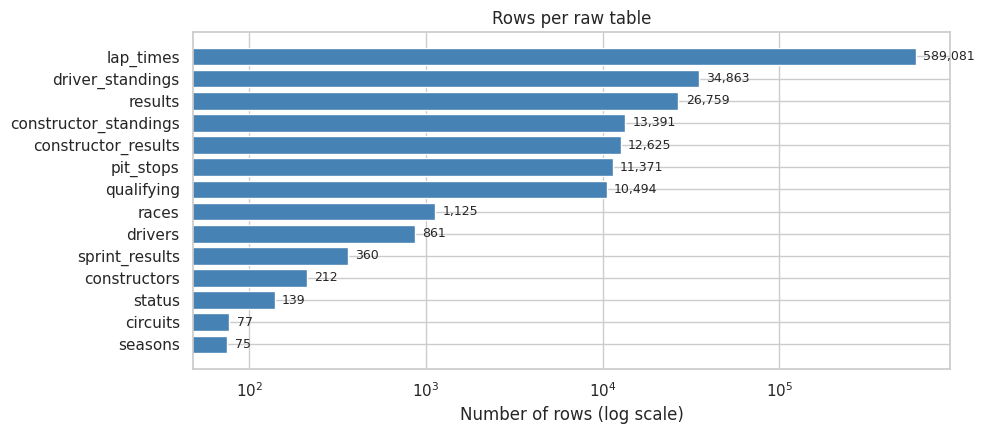

In [6]:
fig, ax = plt.subplots(figsize=(10, 4.5))
ax.barh(overview.index[::-1], overview['rows'][::-1], color='steelblue')
ax.set_xscale('log')
ax.set_xlabel('Number of rows (log scale)')
ax.set_title('Rows per raw table')
for i, v in enumerate(overview['rows'][::-1]):
    ax.text(v * 1.1, i, f'{v:,}', va='center', fontsize=9)
plt.tight_layout()
plt.show()

**Reading this:**
- `results` is our **base table**: each row is one driver's entry in one race, which matches our unit of analysis.
- `lap_times` (~589k rows) and `pit_stops` are the largest tables, but they describe what happened **during** the race. They are post-race information and can never be features. We only clean and audit them.
- The dataset is **relational**: e.g. `results` only stores IDs (`raceId`, `driverId`, `constructorId`, `statusId`), so the year, the driver's nationality or the status text all need joins.

### 1.2 A first look at the key tables

In [7]:
raw['results'].head()

,resultId,raceId,driverId,constructorId,number,grid,position,positionText,positionOrder,points,laps,time,milliseconds,fastestLap,rank,fastestLapTime,fastestLapSpeed,statusId
0,1,18,1,1,22,1,1,1,1,10.0,58,1:34:50.616,5690616,39,2,1:27.452,218.300,1
1,2,18,2,2,3,5,2,2,2,8.0,58,+5.478,5696094,41,3,1:27.739,217.586,1
2,3,18,3,3,7,7,3,3,3,6.0,58,+8.163,5698779,41,5,1:28.090,216.719,1
3,4,18,4,4,5,11,4,4,4,5.0,58,+17.181,5707797,58,7,1:28.603,215.464,1
4,5,18,5,1,23,3,5,5,5,4.0,58,+18.014,5708630,43,1,1:27.418,218.385,1


In [8]:
raw['races'].head(3)

,raceId,year,round,circuitId,name,date,time,url,fp1_date,fp1_time,fp2_date,fp2_time,fp3_date,fp3_time,quali_date,quali_time,sprint_date,sprint_time
0,1,2009,1,1,Australian Grand Prix,2009-03-29,06:00:00,http://en.wikipedia.org/wiki/2009_Australian_G...,\N,\N,\N,\N,\N,\N,\N,\N,\N,\N
1,2,2009,2,2,Malaysian Grand Prix,2009-04-05,09:00:00,http://en.wikipedia.org/wiki/2009_Malaysian_Gr...,\N,\N,\N,\N,\N,\N,\N,\N,\N,\N
2,3,2009,3,17,Chinese Grand Prix,2009-04-19,07:00:00,http://en.wikipedia.org/wiki/2009_Chinese_Gran...,\N,\N,\N,\N,\N,\N,\N,\N,\N,\N


In [9]:
raw['qualifying'].head(3)

,qualifyId,raceId,driverId,constructorId,number,position,q1,q2,q3
0,1,18,1,1,22,1,1:26.572,1:25.187,1:26.714
1,2,18,9,2,4,2,1:26.103,1:25.315,1:26.869
2,3,18,5,1,23,3,1:25.664,1:25.452,1:27.079


### 1.3 The data types pandas inferred — the first sign of a problem

In [10]:
print(raw['results'].dtypes)
print()
print('Unique values of results.position (first 12):', list(raw['results']['position'].unique()[:12]))

resultId             int64
raceId               int64
driverId             int64
constructorId        int64
number              object
grid                 int64
position            object
positionText        object
positionOrder        int64
points             float64
laps                 int64
time                object
milliseconds        object
fastestLap          object
rank                object
fastestLapTime      object
fastestLapSpeed     object
statusId             int64
dtype: object

Unique values of results.position (first 12): ['1', '2', '3', '4', '5', '6', '7', '8', '\\N', '9', '10', '11']


`position`, `milliseconds`, `fastestLap`, `rank`, `fastestLapTime` and `fastestLapSpeed` should be numbers, but pandas read them as **text**. The cause is the literal string `\N` (a placeholder for "missing", called a **sentinel**). One `\N` in a column forces the whole column to text. We can't compute averages, sort numerically or feed a model until it is fixed. `fastestLapTime` (`'1:27.452'`) is also a *duration stored as text*, which needs semantic typing.

### 1.4 Sentinel scan — where is data "missing" (and is it really missing)?
We count both `\N` and empty strings `''` in **every column of every table**.

In [11]:
rows = []
for t in TABLES:
    df = raw[t]
    for col in df.columns:
        n_sentinel = int((df[col] == SENTINEL).sum())
        n_empty = int((df[col] == '').sum())
        if n_sentinel + n_empty > 0:
            rows.append({'table': t, 'column': col, r'\N count': n_sentinel, "'' count": n_empty,
                         '% missing': round(100 * (n_sentinel + n_empty) / len(df), 1)})
sentinel_report = pd.DataFrame(rows).sort_values('% missing', ascending=False).reset_index(drop=True)
sentinel_report

,table,column,\N count,'' count,% missing
0,constructor_results,status,12608,0,99.9
1,races,sprint_time,1110,0,98.7
2,races,sprint_date,1107,0,98.4
3,races,fp3_time,1072,0,95.3
4,races,fp1_time,1057,0,94.0
5,races,fp2_time,1057,0,94.0
6,races,quali_time,1057,0,94.0
7,races,fp3_date,1053,0,93.6
8,drivers,number,802,0,93.1
9,races,fp1_date,1035,0,92.0


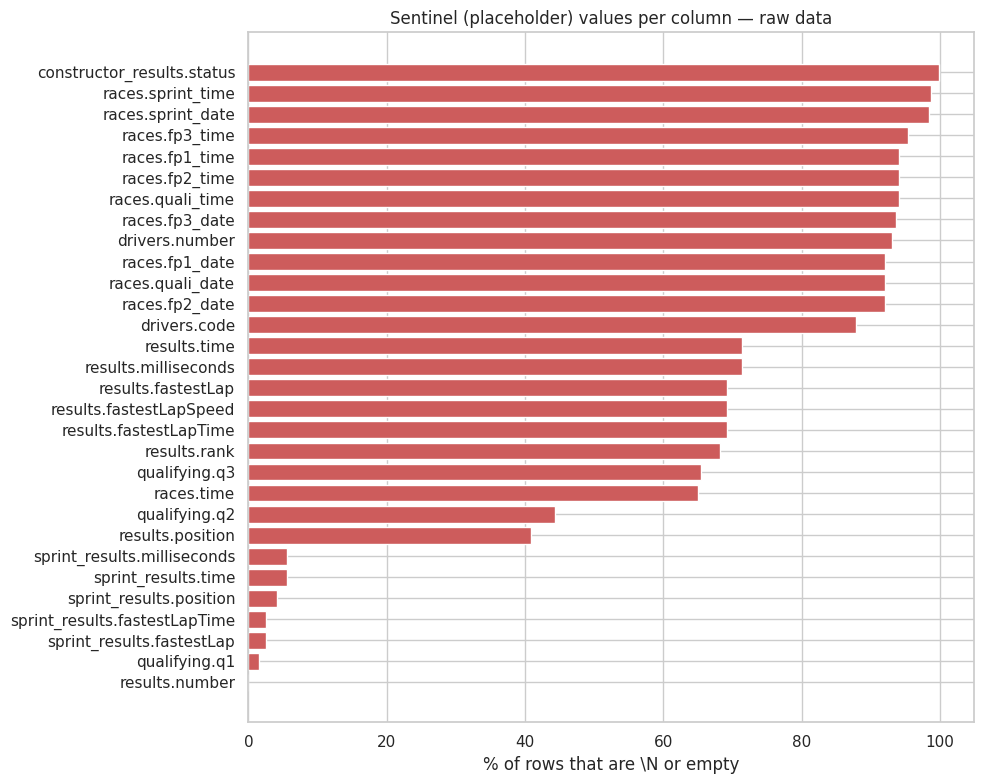

In [12]:
plot_df = sentinel_report.copy()
plot_df['label'] = plot_df['table'] + '.' + plot_df['column']
fig, ax = plt.subplots(figsize=(10, 8))
ax.barh(plot_df['label'][::-1], plot_df['% missing'][::-1], color='indianred')
ax.set_xlabel('% of rows that are \\N or empty')
ax.set_title('Sentinel (placeholder) values per column — raw data')
plt.tight_layout()
plt.show()

**Interpretation: the missingness is mostly *structural*, meaning it carries information.**

| Column | Why it is missing | Consequence |
|---|---|---|
| `results.position` | the driver was **not classified** (retired, DNQ, …). `positionText` holds a letter code instead | not an error. Never drop these rows, because they are real race entries |
| `results.time / milliseconds` | only recorded for drivers who finished on the lead lap | post-race, never a feature |
| `results.fastestLap*` | not recorded before 2004 | post-race, never a feature |
| `qualifying.q2 / q3` | drivers knocked out in Q1/Q2 **never drive** Q2/Q3 | *Missing Not At Random*. A mean-imputed Q3 time would invent a lap that never happened |
| `races.fp*/quali*/sprint*` dates | only filled from 2021 | metadata only |
| `drivers.number / code` | permanent numbers/codes only exist in the modern era | not needed for modelling |
| `constructor_results.status` | only ever filled with `'D'`: the 2007 McLaren disqualification | effectively a yes/no flag, post-race |

Note that `qualifying.q2`/`q3` also contain **empty strings `''`**, which is a *second* sentinel next to `\N`. Pandas' default reader would silently convert `''` to NaN but leave `\N` as text, so the two placeholders would be handled inconsistently. We treat both as missing.

Why we don't just use `dropna()` here: in the penguins lab, `dropna()` was fine because a handful of rows had random gaps. Here, `dropna()` on `results` would delete **every retired driver**, and **all races before 2004** (no fastest-lap data). That would destroy the very population we want to predict on.

### 1.5 Raw `results`: fields, grid and podium counts

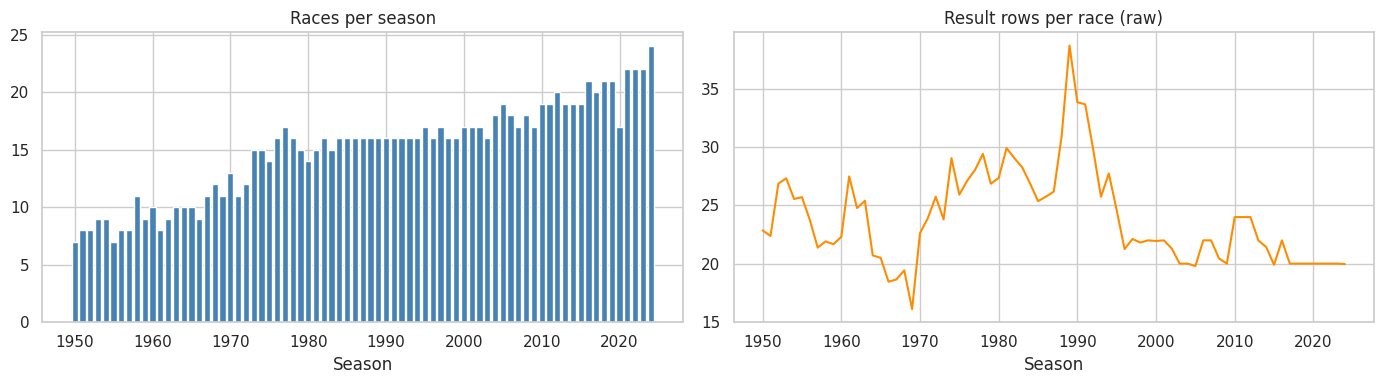

In [13]:
r0 = raw['results'].merge(raw['races'][['raceId', 'year']], on='raceId')

per_season = r0.groupby('year').agg(races=('raceId', 'nunique'), rows=('resultId', 'size'))
per_season['rows per race'] = per_season['rows'] / per_season['races']

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].bar(per_season.index, per_season['races'], color='steelblue')
axes[0].set_title('Races per season')
axes[0].set_xlabel('Season')
axes[1].plot(per_season.index, per_season['rows per race'], color='darkorange')
axes[1].set_title('Result rows per race (raw)')
axes[1].set_xlabel('Season')
plt.tight_layout()
plt.show()

- Seasons grew from 7 races (1950) to 24 (2024).
- **Rows per race** are far above the ~20 cars that actually start a modern race in two periods. In the **1950s** this comes from the Indianapolis 500's big fields and from shared drives. In the **late 1980s / early 1990s**, more cars entered than were allowed to start, and the non-qualifiers still have result rows.

That second point matters for the target. Non-qualifiers can never podium, so they push the podium base rate down for reasons that have nothing to do with racing.

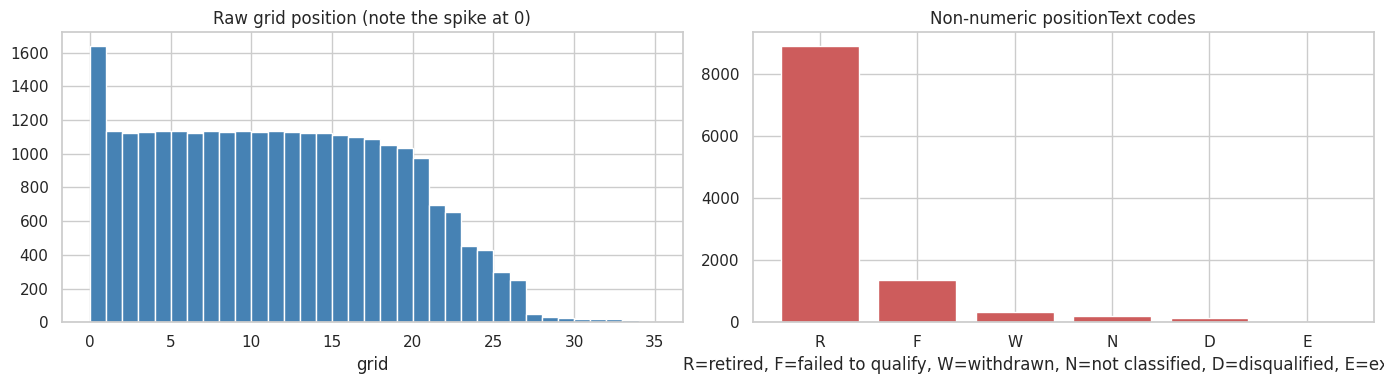

Rows with grid = 0: 1638


In [14]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].hist(r0['grid'], bins=range(0, 36), color='steelblue', edgecolor='white')
axes[0].set_title('Raw grid position (note the spike at 0)')
axes[0].set_xlabel('grid')
codes = r0.loc[~r0['positionText'].str.isnumeric(), 'positionText'].value_counts()
axes[1].bar(codes.index, codes.values, color='indianred')
axes[1].set_title('Non-numeric positionText codes')
axes[1].set_xlabel('R=retired, F=failed to qualify, W=withdrawn, N=not classified, D=disqualified, E=excluded')
plt.tight_layout()
plt.show()
print('Rows with grid = 0:', (r0['grid'] == 0).sum())

**`grid = 0` is a code, not a position.** A model would read 0 as "better than pole position". This is the same trap as ordinal-encoding the penguin islands, where a number implied an order that isn't real. We investigate what 0 means in the audit (Section 2) and fix it in Section 3.

In [15]:
podiums_per_race = r0[r0['positionOrder'] <= 3].groupby('raceId').size()
print('Number of podium rows (positionOrder <= 3) per race, raw data:')
print(podiums_per_race.value_counts().sort_index().rename_axis('podium rows').to_frame('races'))

Number of podium rows (positionOrder <= 3) per race, raw data:
             races
podium rows       
3             1107
4               16
5                1
7                1


Every race should have exactly 3 podium finishers, but some races show **4, 5 or even 7** "podium rows" in the raw data. This tells us that some rows are not independent driver entries. We confirm the cause in Section 2 (key checks) and Section 3.5 (shared drives).

### 1.6 Coverage drift — which seasons does each table actually cover?
The brief warns about *historical qualifying-coverage drift*. For every season we compute the **share of races that have at least one row** in each table.

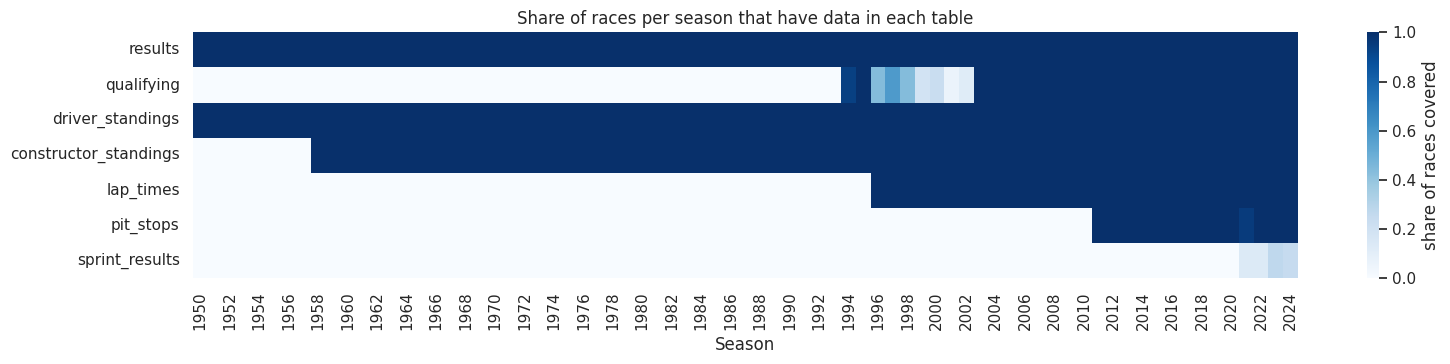

Qualifying coverage by season (only seasons with any data):
{1994: 0.94, 1995: 1.0, 1996: 0.44, 1997: 0.59, 1998: 0.44, 1999: 0.19, 2000: 0.24, 2001: 0.06, 2002: 0.12, 2003: 1.0, 2004: 1.0, 2005: 1.0, 2006: 1.0, 2007: 1.0, 2008: 1.0, 2009: 1.0, 2010: 1.0, 2011: 1.0, 2012: 1.0, 2013: 1.0, 2014: 1.0, 2015: 1.0, 2016: 1.0, 2017: 1.0, 2018: 1.0, 2019: 1.0, 2020: 1.0, 2021: 1.0, 2022: 1.0, 2023: 1.0, 2024: 1.0}


In [16]:
race_year = raw['races'][['raceId', 'year']]
coverage = {}
for t in ['results', 'qualifying', 'driver_standings', 'constructor_standings',
          'lap_times', 'pit_stops', 'sprint_results']:
    has_rows = race_year['raceId'].isin(raw[t]['raceId'])
    coverage[t] = has_rows.groupby(race_year['year']).mean()
coverage = pd.DataFrame(coverage).T

fig, ax = plt.subplots(figsize=(16, 3.8))
sns.heatmap(coverage, cmap='Blues', vmin=0, vmax=1, cbar_kws={'label': 'share of races covered'}, ax=ax)
ax.set_title('Share of races per season that have data in each table')
ax.set_xlabel('Season')
plt.tight_layout()
plt.show()

print('Qualifying coverage by season (only seasons with any data):')
print(coverage.loc['qualifying'][coverage.loc['qualifying'] > 0].round(2).to_dict())

**Reading the heatmap:**
- `results` and `driver_standings` cover every race. `constructor_standings` starts in **1958**, when the constructors' championship began.
- `qualifying` starts in **1994** but is **patchy from 1996 to 2002** (as low as 6 % of races in 2001). It is complete only from **2003**. Qualifying features are therefore missing for most of history. The team must choose between restricting the training window, falling back to `grid`, or imputing (a modelling decision, documented as a limitation).
- `lap_times` starts in 1996, `pit_stops` in 2011 and `sprint_results` in 2021.

### 1.7 Raw grain check — is `(raceId, driverId)` unique?

Rows involved in a duplicate (raceId, driverId): 176
Extra rows (beyond the first per pair)          : 91


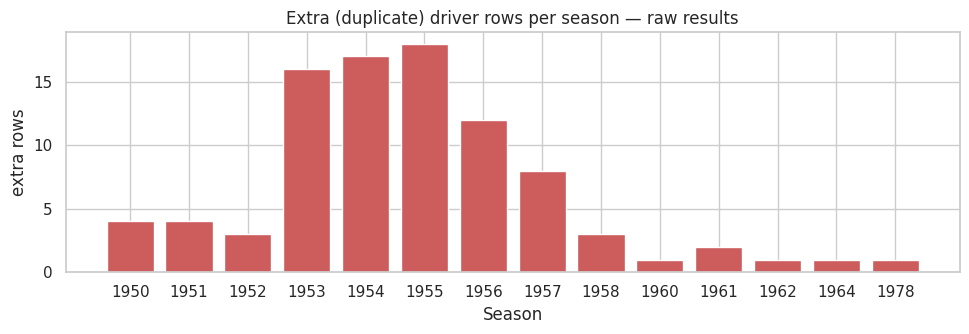

In [17]:
dup_mask = r0.duplicated(['raceId', 'driverId'], keep=False)
print('Rows involved in a duplicate (raceId, driverId):', dup_mask.sum())
print('Extra rows (beyond the first per pair)          :', r0.duplicated(['raceId', 'driverId']).sum())

dups_by_year = r0[r0.duplicated(['raceId', 'driverId'])].groupby('year').size()
fig, ax = plt.subplots(figsize=(10, 3.5))
ax.bar(dups_by_year.index.astype(str), dups_by_year.values, color='indianred')
ax.set_title('Extra (duplicate) driver rows per season — raw results')
ax.set_xlabel('Season')
ax.set_ylabel('extra rows')
plt.tight_layout()
plt.show()

The required grain is broken: **91 extra rows**, almost all from **1950–1958**. That matches the brief's hint about **shared drives**, when drivers swapped cars mid-race. We fix this in Section 3.5.

# 2. Data-Quality Audit — keys, links and consistency

### 2.1 Primary keys: unique and non-null?
A **primary key (PK)** is the column (or columns) that uniquely identifies each row. For `lap_times` and `pit_stops` there is no ID column, so the natural key is composite.

In [18]:
PRIMARY_KEYS = {
    'circuits': ['circuitId'], 'constructor_results': ['constructorResultsId'],
    'constructor_standings': ['constructorStandingsId'], 'constructors': ['constructorId'],
    'driver_standings': ['driverStandingsId'], 'drivers': ['driverId'],
    'lap_times': ['raceId', 'driverId', 'lap'], 'pit_stops': ['raceId', 'driverId', 'stop'],
    'qualifying': ['qualifyId'], 'races': ['raceId'], 'results': ['resultId'],
    'seasons': ['year'], 'sprint_results': ['resultId'], 'status': ['statusId'],
}

def check_primary_keys(tables):
    out = []
    for t, key in PRIMARY_KEYS.items():
        df = tables[t]
        n_dup = int(df.duplicated(key).sum())
        n_null = int(df[key].isna().any(axis=1).sum() + (df[key] == SENTINEL).any(axis=1).sum())
        out.append({'table': t, 'primary key': ', '.join(key), 'duplicates': n_dup, 'nulls': n_null,
                    'OK': n_dup == 0 and n_null == 0})
    return pd.DataFrame(out)

pk_report_raw = check_primary_keys(raw)
pk_report_raw

,table,primary key,duplicates,nulls,OK
0,circuits,circuitId,0,0,True
1,constructor_results,constructorResultsId,0,0,True
2,constructor_standings,constructorStandingsId,0,0,True
3,constructors,constructorId,0,0,True
4,driver_standings,driverStandingsId,0,0,True
5,drivers,driverId,0,0,True
6,lap_times,"raceId, driverId, lap",0,0,True
7,pit_stops,"raceId, driverId, stop",0,0,True
8,qualifying,qualifyId,0,0,True
9,races,raceId,0,0,True


All 14 primary keys are unique and non-null. **But a valid PK does not mean a valid grain.** `results.resultId` is unique, yet the *business* key we need, one row per `(raceId, driverId)`, is not. So we check the natural keys that must be unique for our project:

In [19]:
NATURAL_KEYS = [('results', ['raceId', 'driverId']), ('qualifying', ['raceId', 'driverId']),
                ('sprint_results', ['raceId', 'driverId']), ('driver_standings', ['raceId', 'driverId']),
                ('constructor_standings', ['raceId', 'constructorId']),
                ('constructor_results', ['raceId', 'constructorId']), ('races', ['year', 'round'])]
pd.DataFrame([{'table': t, 'natural key': ', '.join(k), 'duplicates': int(raw[t].duplicated(k).sum())}
              for t, k in NATURAL_KEYS])

,table,natural key,duplicates
0,results,"raceId, driverId",91
1,qualifying,"raceId, driverId",0
2,sprint_results,"raceId, driverId",0
3,driver_standings,"raceId, driverId",0
4,constructor_standings,"raceId, constructorId",0
5,constructor_results,"raceId, constructorId",0
6,races,"year, round",0


Only `results (raceId, driverId)` fails, with **91 duplicates**. Everything else, including `qualifying`, is already one row per driver per race, so we can later join qualifying onto results without creating extra rows.

### 2.2 Foreign keys: does every reference point to an existing row?
A **foreign key (FK)** is a column that refers to the PK of another table (e.g. `results.driverId → drivers.driverId`). If an FK value does not exist in its parent table (an **orphan**), a join would silently drop that row or fill it with NaN.

In [20]:
FOREIGN_KEYS = [('races', 'circuitId', 'circuits', 'circuitId'), ('races', 'year', 'seasons', 'year')]
for child in ['results', 'qualifying', 'sprint_results']:
    FOREIGN_KEYS += [(child, 'raceId', 'races', 'raceId'), (child, 'driverId', 'drivers', 'driverId'),
                     (child, 'constructorId', 'constructors', 'constructorId')]
for child in ['results', 'sprint_results']:
    FOREIGN_KEYS += [(child, 'statusId', 'status', 'statusId')]
for child in ['lap_times', 'pit_stops', 'driver_standings']:
    FOREIGN_KEYS += [(child, 'raceId', 'races', 'raceId'), (child, 'driverId', 'drivers', 'driverId')]
for child in ['constructor_results', 'constructor_standings']:
    FOREIGN_KEYS += [(child, 'raceId', 'races', 'raceId'), (child, 'constructorId', 'constructors', 'constructorId')]

def check_foreign_keys(tables):
    out = []
    for child, fk, parent, pk in FOREIGN_KEYS:
        orphans = ~tables[child][fk].isin(tables[parent][pk])
        out.append({'child.column': f'{child}.{fk}', 'parent.column': f'{parent}.{pk}',
                    'orphans': int(orphans.sum()), 'OK': orphans.sum() == 0})
    return pd.DataFrame(out)

fk_report_raw = check_foreign_keys(raw)
print('Foreign keys checked:', len(fk_report_raw), '| all OK:', fk_report_raw['OK'].all())
fk_report_raw

Foreign keys checked: 23 | all OK: True


,child.column,parent.column,orphans,OK
0,races.circuitId,circuits.circuitId,0,True
1,races.year,seasons.year,0,True
2,results.raceId,races.raceId,0,True
3,results.driverId,drivers.driverId,0,True
4,results.constructorId,constructors.constructorId,0,True
5,qualifying.raceId,races.raceId,0,True
6,qualifying.driverId,drivers.driverId,0,True
7,qualifying.constructorId,constructors.constructorId,0,True
8,sprint_results.raceId,races.raceId,0,True
9,sprint_results.driverId,drivers.driverId,0,True


All **23 foreign-key links reconcile** with 0 orphans.

Session-level tables like `qualifying`, `lap_times` and `pit_stops` describe a driver *in a race*, so their `(raceId, driverId)` pair should also exist in `results`. We check this **composite** link as well, plus the reverse direction (parents that are never used):

In [21]:
result_pairs = set(zip(raw['results']['raceId'], raw['results']['driverId']))
composite = []
for t in ['qualifying', 'sprint_results', 'lap_times', 'pit_stops', 'driver_standings']:
    pairs = list(zip(raw[t]['raceId'], raw[t]['driverId']))
    composite.append({'table': t, '(raceId, driverId) pairs not in results': sum(p not in result_pairs for p in pairs)})
display(pd.DataFrame(composite))

unused_constructors = raw['constructors'][~raw['constructors']['constructorId'].isin(raw['results']['constructorId'])]
print('Constructors never used in results:', unused_constructors[['constructorId', 'name']].values.tolist())
print('Status codes never used in results:', int((~raw['status']['statusId'].isin(raw['results']['statusId'])).sum()))
print('Races without any result rows      :', int((~raw['races']['raceId'].isin(raw['results']['raceId'])).sum()))

,table,"(raceId, driverId) pairs not in results"
0,qualifying,0
1,sprint_results,0
2,lap_times,0
3,pit_stops,0
4,driver_standings,8664


Constructors never used in results: [[88, 'Eagle']]
Status codes never used in results: 2
Races without any result rows      : 0


- Qualifying, sprint, lap and pit-stop rows all point to a real result row.
- `driver_standings` has thousands of pairs with **no result row, and that is expected, not an error**. Standings list *every driver of the season* after each race, including drivers who skipped that race. This is also a leakage reminder for the team: the standings attached to race *X* are computed **after** race *X*, so they must be shifted to "standings before this race" before use as a feature.
- One constructor (*Eagle*, id 88) and two status codes are never referenced. Unused parent rows are harmless and are kept.

### 2.3 Value-range and logical-consistency checks
Keys can be perfect while values are wrong, so we test explicit domain rules. Each line is one rule, and *0* means the rule holds.

In [22]:
res = raw['results'].merge(raw['races'][['raceId', 'year', 'name', 'date']], on='raceId') \
                    .merge(raw['status'], on='statusId')
races_dt = pd.to_datetime(raw['races']['date'])
season_counts = raw['races'].groupby('year')['round'].agg(['count', 'max'])
numeric_text = res['positionText'].str.isnumeric()
position_num = pd.to_numeric(res['position'].replace(SENTINEL, np.nan))

lap = raw['lap_times']
lap_parsed_ms = (lap['time'].map(time_to_seconds) * 1000).round()
pit = raw['pit_stops']
pit_parsed_ms = (pit['duration'].map(time_to_seconds) * 1000).round()
q_vs_grid = raw['qualifying'][['raceId', 'driverId', 'position']].merge(
    raw['results'][['raceId', 'driverId', 'grid']], on=['raceId', 'driverId'])
age = (pd.to_datetime(res['date']) -
       pd.to_datetime(res['driverId'].map(raw['drivers'].set_index('driverId')['dob']))).dt.days / 365.25
DNQ_STATUSES = ['Did not qualify', 'Did not prequalify', '107% Rule']

checks = [
    ('races', 'race date is in a different year than the "year" column', int((races_dt.dt.year != raw['races']['year']).sum())),
    ('races', 'seasons whose rounds are not 1..N without gaps', int((season_counts['count'] != season_counts['max']).sum())),
    ('races', 'seasons missing between 1950 and the last season', int(len(set(range(1950, raw['races']['year'].max() + 1)) - set(raw['races']['year'])))),
    ('results', 'negative grid / laps / points', int(((res['grid'] < 0) | (res['laps'] < 0) | (res['points'] < 0)).sum())),
    ('results', 'positionOrder not unique within a race (ties)', int(res.duplicated(['raceId', 'positionOrder']).sum())),
    ('results', 'position missing but positionText is a number', int((position_num.isna() & numeric_text).sum())),
    ('results', 'classified position differs from positionOrder', int((position_num.notna() & (position_num != res['positionOrder'])).sum())),
    ('results', 'status = did-not-qualify but grid > 0 (contradiction)', int((res['status'].isin(DNQ_STATUSES) & (res['grid'] > 0)).sum())),
    ('results', 'grid = 0 rows (code, not a position)', int((res['grid'] == 0).sum())),
    ('qualifying', 'qualifying position differs from results.grid', int((q_vs_grid['position'] != q_vs_grid['grid']).sum())),
    ('lap_times', 'lap time text disagrees with milliseconds', int((lap_parsed_ms != lap['milliseconds']).sum())),
    ('lap_times', 'lap times written as h:mm:ss (laps over an hour)', int(lap['time'].str.count(':').eq(2).sum())),
    ('pit_stops', 'duration text disagrees with milliseconds', int((pit_parsed_ms != pit['milliseconds']).sum())),
    ('pit_stops', 'durations written as m:ss (stops over a minute)', int(pit['duration'].str.contains(':').sum())),
    ('drivers', 'nationality with leading/trailing spaces', int((raw['drivers']['nationality'] != raw['drivers']['nationality'].str.strip()).sum())),
    ('drivers', 'nationality spelled both "Argentine" and "Argentinian"', int(raw['drivers']['nationality'].str.strip().eq('Argentinian').sum())),
    ('circuits', 'country spelled both "USA" and "United States"', int(raw['circuits']['country'].eq('United States').sum())),
    ('drivers', 'driver age at race outside 15-60 years', int(((age < 15) | (age > 60)).sum())),
    ('circuits', 'latitude/longitude outside valid range', int(((raw['circuits']['lat'].abs() > 90) | (raw['circuits']['lng'].abs() > 180)).sum())),
]
consistency_report = pd.DataFrame(checks, columns=['table', 'rule', 'rows violating'])
consistency_report

,table,rule,rows violating
0,races,"race date is in a different year than the ""yea...",0
1,races,seasons whose rounds are not 1..N without gaps,0
2,races,seasons missing between 1950 and the last season,0
3,results,negative grid / laps / points,0
4,results,positionOrder not unique within a race (ties),123
5,results,position missing but positionText is a number,2
6,results,classified position differs from positionOrder,13
7,results,status = did-not-qualify but grid > 0 (contrad...,19
8,results,"grid = 0 rows (code, not a position)",1638
9,qualifying,qualifying position differs from results.grid,2509


**What the checks tell us (and what we will do):**

| Finding | Meaning | Action (Section 3) |
|---|---|---|
| Dates, rounds and seasons all consistent | the calendar is clean | nothing to fix |
| No negative grid/laps/points, coordinates valid | numeric ranges are plausible | nothing to fix |
| **positionOrder ties within a race** | two rows share the same finishing rank, caused by shared drives (the same car credited to two drivers) | grain fix, 3.5–3.6 |
| **2 rows with `position` missing but `positionText` numeric** (2005 Australian GP) | an internal inconsistency between two columns that describe the same thing | fill `position` from `positionText` |
| **13 rows where position ≠ positionOrder** (1983 Brazilian GP) | the 2nd-place car was disqualified and the official `position` column left P2 vacant, while `positionOrder` re-ranks everyone | keep `positionOrder`. The brief defines the target with it, and it is the final classification. Documented |
| **19 rows "did not qualify" yet grid > 0** | `grid` holds their qualifying rank, but they never started | the non-starter rule must use status, not only `grid == 0` (3.8) |
| **grid = 0** (1,600+ rows) | either "never started" *or* "started from the pit lane" | split the two meanings (3.8–3.9) |
| **Qualifying position ≠ grid in ~24 % of rows** | grid penalties and pit-lane starts are real | not an error. Keep both columns, as Data-Engineering Question 1 requires |
| Lap/pit text vs milliseconds: **0 disagreements** | the text and the number agree once our parser handles `h:mm:ss` (red-flag laps) and `m:ss` (long stops) | use `milliseconds` as the numeric source |
| **Label inconsistencies**: `'Argentinian '` (with a space) vs `'Argentine'`, `'United States'` vs `'USA'` | the same country written differently would split groups in the home-race analysis | standardise (3.3) |
| Driver ages 17.5–58.8 | plausible: Verstappen debuted at 17, early F1 had drivers in their fifties | nothing to fix |

# 3. Data Cleaning

Every cleaning step below follows the same pattern: **what we found → what we did → why → proof that it worked**. A *cleaning log* records how many rows each step touched.

In [23]:
clean = {name: df.copy() for name, df in raw.items()}   # work on COPIES; raw stays untouched
cleaning_log = []

def log_step(step, table, rows_before, rows_after, reason):
    cleaning_log.append({'step': step, 'table': table, 'rows before': rows_before,
                         'rows after': rows_after, 'rows removed': rows_before - rows_after, 'reason': reason})

### 3.1 Sentinels → real missing values (`NaN`)
**What:** replace `\N` and empty strings `''` with `np.nan` in every table, and strip stray spaces from text.
**Why:** `NaN` is what pandas, NumPy and scikit-learn understand as "missing". Leaving `\N` would keep numeric columns as text, so `.mean()`, sorting, plotting and modelling would all fail or give wrong answers.

In [24]:
for t in TABLES:
    df = clean[t]
    for col in df.columns:
        if not pd.api.types.is_numeric_dtype(df[col]):          # only text columns can hold '\N' or ''
            is_placeholder = df[col].isin([SENTINEL, ''])
            df[col] = df[col].where(~is_placeholder, np.nan)    # placeholder -> NaN
            df[col] = df[col].str.strip()                       # 'Argentinian ' -> 'Argentinian'
    clean[t] = df

after = pd.DataFrame({
    r'\N cells before': [int((raw[t] == SENTINEL).sum().sum()) for t in TABLES],
    "'' cells before": [int((raw[t] == '').sum().sum()) for t in TABLES],
    r'\N cells after': [int((clean[t] == SENTINEL).sum().sum()) for t in TABLES],
    'NaN cells after': [int(clean[t].isna().sum().sum()) for t in TABLES],
}, index=TABLES)
after[after.sum(axis=1) > 0]

,\N cells before,'' cells before,\N cells after,NaN cells after
constructor_results,12608,0,0,12608
drivers,1559,0,0,1559
qualifying,11600,68,0,11668
races,11349,0,0,11349
results,122887,0,0,122887
sprint_results,73,0,0,73


Every `\N` and `''` became `NaN`. The NaN count equals the sentinel count, so nothing else was converted by accident.

### 3.2 Semantic typing — numbers, dates and durations
**What:**
1. **Numbers stored as text → numeric.** Integer columns that contain gaps use pandas' nullable `Int64` type, because a normal `int` column cannot hold `NaN`.
2. **Date strings → `datetime`** (`races.date`, the session dates, `drivers.dob`).
3. **Duration strings → seconds** (`float`): qualifying `q1/q2/q3`, `fastestLapTime`, lap times, pit-stop durations and total race time.

**Why:** "semantic typing" means giving each column the type that matches its *meaning*. As text, `'1:26.572' < '59.9'` would be `True` (alphabetical order), which is wrong. In seconds, 86.572 > 59.9, which is correct. Real dates let us compute things like a driver's age on race day.

**Safety check:** after each conversion we count *new* NaNs. A value that fails to convert would silently become NaN, so "0 new NaNs" proves no information was lost.

In [25]:
conversion_check = []

def to_number(table, col, integer=True):
    before = clean[table][col].isna().sum()
    converted = pd.to_numeric(clean[table][col], errors='coerce')
    clean[table][col] = converted.astype('Int64') if integer else converted.astype(float)
    conversion_check.append({'table': table, 'column': col, 'new type': str(clean[table][col].dtype),
                             'new NaNs created': int(clean[table][col].isna().sum() - before)})

def to_seconds(table, col, new_col):
    before = clean[table][col].isna().sum()
    clean[table][new_col] = clean[table][col].map(time_to_seconds)
    conversion_check.append({'table': table, 'column': f'{col} -> {new_col}', 'new type': 'float (seconds)',
                             'new NaNs created': int(clean[table][new_col].isna().sum() - before)})

def to_date(table, col):
    before = clean[table][col].isna().sum()
    clean[table][col] = pd.to_datetime(clean[table][col], errors='coerce')
    conversion_check.append({'table': table, 'column': col, 'new type': 'datetime',
                             'new NaNs created': int(clean[table][col].isna().sum() - before)})

# 1) numbers that were text because of \N
for col in ['number', 'position', 'milliseconds', 'fastestLap', 'rank']:
    to_number('results', col)
to_number('results', 'fastestLapSpeed', integer=False)
for col in ['position', 'milliseconds', 'fastestLap']:
    to_number('sprint_results', col)
to_number('drivers', 'number')

# 2) dates
for col in ['date', 'fp1_date', 'fp2_date', 'fp3_date', 'quali_date', 'sprint_date']:
    to_date('races', col)
to_date('drivers', 'dob')

# 3) durations -> seconds
for q in ['q1', 'q2', 'q3']:
    to_seconds('qualifying', q, q + '_s')
to_seconds('results', 'fastestLapTime', 'fastestLapTime_s')
to_seconds('sprint_results', 'fastestLapTime', 'fastestLapTime_s')
to_seconds('lap_times', 'time', 'lap_time_s')
to_seconds('pit_stops', 'duration', 'duration_s')
clean['results']['race_time_s'] = clean['results']['milliseconds'] / 1000

pd.DataFrame(conversion_check)

,table,column,new type,new NaNs created
0,results,number,Int64,0
1,results,position,Int64,0
2,results,milliseconds,Int64,0
3,results,fastestLap,Int64,0
4,results,rank,Int64,0
5,results,fastestLapSpeed,float64,0
6,sprint_results,position,Int64,0
7,sprint_results,milliseconds,Int64,0
8,sprint_results,fastestLap,Int64,0
9,drivers,number,Int64,0


**0 new NaNs in every conversion**, so every value converted correctly. For lap and pit times we already showed in 2.3 that the parsed text agrees exactly with the `milliseconds` column.

Before vs after for `results`:

In [26]:
pd.DataFrame({'raw dtype': raw['results'].dtypes.astype(str),
              'clean dtype': clean['results'].dtypes.reindex(raw['results'].columns).astype(str)})

,raw dtype,clean dtype
resultId,int64,int64
raceId,int64,int64
driverId,int64,int64
constructorId,int64,int64
number,object,Int64
grid,int64,int64
position,object,Int64
positionText,object,object
positionOrder,int64,int64
points,float64,float64


### 3.3 Standardising text labels
**What:** after stripping spaces, map `'Argentinian'` → `'Argentine'` (drivers) and `'United States'` → `'USA'` (circuits).
**Why:** the same country written two ways is counted as two groups. Data-Engineering Question 2 (home race) matches **driver nationality** to **circuit country**, so split labels would wrongly turn home races into away races.

In [27]:
print('Before:', raw['drivers']['nationality'].str.strip().value_counts()[['Argentine', 'Argentinian']].to_dict(),
      '|', raw['circuits']['country'].value_counts()[['USA', 'United States']].to_dict())

clean['drivers']['nationality'] = clean['drivers']['nationality'].replace({'Argentinian': 'Argentine'})
clean['circuits']['country'] = clean['circuits']['country'].replace({'United States': 'USA'})

print('After :', clean['drivers']['nationality'].value_counts()[['Argentine']].to_dict(),
      '|', clean['circuits']['country'].value_counts()[['USA']].to_dict())

Before: {'Argentine': 24, 'Argentinian': 1} | {'USA': 11, 'United States': 1}
After : {'Argentine': 25} | {'USA': 12}


> **Note for Question 2:** nationalities are demonyms (`'British'`, `'American'`) while circuit countries are country names (`'UK'`, `'USA'`). The two need an explicit mapping table. That belongs to the Question 2 analysis, and it is easier now that each country has a single spelling.

### 3.4 Repairing an internal inconsistency in `results.position`
**What:** two rows (2005 Australian GP) have `position` missing although `positionText` holds a number. We fill `position` from `positionText`.
**Why:** both columns describe the same fact, so the numeric one should not be missing when the text one is known. This is a *repair*, not a guess.

In [28]:
cr = clean['results']
fix = cr['position'].isna() & cr['positionText'].str.isnumeric()
display(cr.loc[fix, ['raceId', 'driverId', 'position', 'positionText', 'positionOrder']])
cr.loc[fix, 'position'] = cr.loc[fix, 'positionText'].astype(int)
print('Rows repaired:', int(fix.sum()), '| remaining inconsistencies:',
      int((cr['position'].isna() & cr['positionText'].str.isnumeric()).sum()))

,raceId,driverId,position,positionText,positionOrder
1148,71,18,<NA>,11,11
1151,71,11,<NA>,14,14


Rows repaired: 2 | remaining inconsistencies: 0


### 3.5 Fixing the grain, step A: one driver with two rows in the same race (shared drives)

Until 1957 a team could call a driver in mid-race and hand his car to a teammate, and a star could take over a teammate's car after his own broke. The dataset records **one row per car the driver drove**.

In [29]:
base = clean['results'].merge(clean['races'][['raceId', 'year', 'name']], on='raceId') \
                       .merge(clean['status'], on='statusId')
pairs = base[base.duplicated(['raceId', 'driverId'], keep=False)]
print('Duplicate pairs:', pairs.groupby(['raceId', 'driverId']).ngroups,
      '| rows involved:', len(pairs), '| extra rows:', int(base.duplicated(['raceId', 'driverId']).sum()))
print('Share of duplicate rows from the Indianapolis 500:', round((pairs['name'] == 'Indianapolis 500').mean(), 2))

example = base[(base['raceId'] == base.loc[(base['year'] == 1957) & (base['name'] == 'British Grand Prix'), 'raceId'].iloc[0])
               & base['driverId'].isin(pairs['driverId'])]
cols = ['resultId', 'year', 'name', 'driverId', 'number', 'grid', 'positionOrder', 'points', 'laps', 'status']
example.sort_values(['driverId', 'resultId'])[cols]

Duplicate pairs: 85 | rows involved: 176 | extra rows: 91
Share of duplicate rows from the Indianapolis 500: 0.26


,resultId,year,name,driverId,number,grid,positionOrder,points,laps,status
18813,18814,1957,British Grand Prix,356,34,13,9,0.0,74,Clutch
18808,18809,1957,British Grand Prix,427,16,9,4,3.0,88,+2 Laps
18816,18817,1957,British Grand Prix,475,18,1,12,0.0,51,Engine
20288,20291,1957,British Grand Prix,475,20,3,1,5.0,90,Finished
18805,18806,1957,British Grand Prix,479,20,3,1,4.0,90,Finished
20290,20293,1957,British Grand Prix,479,18,1,12,0.0,51,Engine
18821,18822,1957,British Grand Prix,496,8,11,17,0.0,35,Transmission
18820,18821,1957,British Grand Prix,501,6,7,16,0.0,39,Water pump
18814,18815,1957,British Grand Prix,554,4,2,10,0.0,69,Clutch
18806,18807,1957,British Grand Prix,577,14,10,2,6.0,90,Finished


**Example, 1957 British GP:** car **#18** started from **pole (grid 1)** and car **#20** from grid 3. Car #18 retired with an engine failure. Its driver then took over car #20 and won. So **both** drivers appear twice: once in their own car and once in the shared car, and both are credited with P1 (4 and 5 points, a split win).

**Which row should we keep? Three candidate rules:**
1. **Original entry**: keep the row of the car the driver *started* in.
2. **Best result**: keep the row with the best `positionOrder`.
3. **Non-zero grid**: the brief's example ("the car the driver started in (non-zero grid)").

First we test rule 3 on the data:

In [30]:
nonzero_per_pair = pairs.groupby(['raceId', 'driverId'])['grid'].apply(lambda g: (g > 0).sum())
print('How many rows with grid > 0 does each duplicate pair have?')
print(nonzero_per_pair.value_counts().sort_index().rename_axis('rows with grid>0').to_frame('pairs'))

How many rows with grid > 0 does each duplicate pair have?
                  pairs
rows with grid>0       
0                     3
2                    76
3                     6


In almost every pair, **both rows have a non-zero grid**, because the takeover car also had a grid slot (its original driver started it). So "non-zero grid" **cannot** tell the rows apart in this dataset, and we need better evidence.

**Evidence: how the rows were recorded.** Each race's original classification was stored as one consecutive run of `resultId`s. The extra shared-drive rows were **added later in a separate block**. In the plot, the grey dots are all result rows and the red dots are the *second copies* of duplicated drivers:

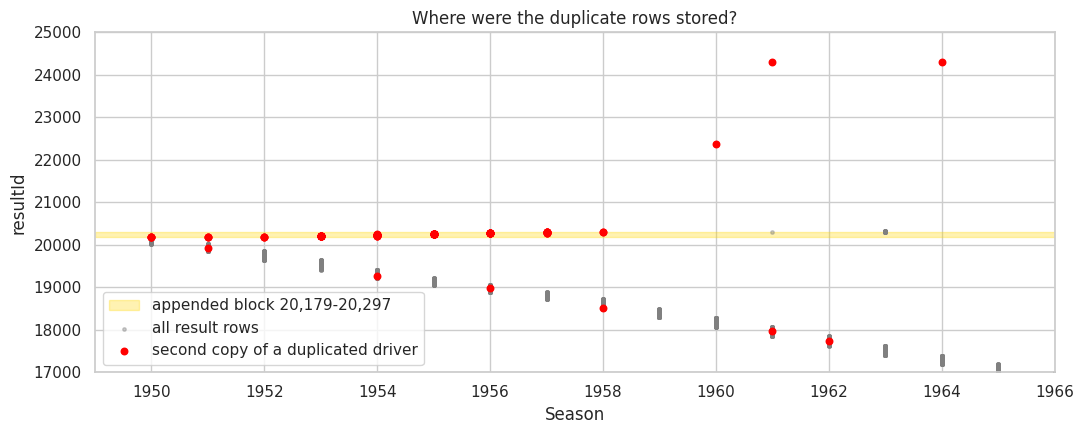

                             second copies
appended block 20179-20297              81
inside the race's own rows               7
appended later (single ids)              3


In [31]:
first_copy = base.sort_values('resultId').drop_duplicates(['raceId', 'driverId'], keep='first')
second_copies = base.loc[~base.index.isin(first_copy.index)]

fig, ax = plt.subplots(figsize=(11, 4.5))
ax.axhspan(20179, 20297, color='gold', alpha=0.3, label='appended block 20,179-20,297')
ax.scatter(base['year'], base['resultId'], s=6, color='grey', alpha=0.4, label='all result rows')
ax.scatter(second_copies['year'], second_copies['resultId'], s=22, color='red', label='second copy of a duplicated driver')
ax.set_xlim(1949, 1966)
ax.set_ylim(17000, 25000)
ax.set_xlabel('Season')
ax.set_ylabel('resultId')
ax.set_title('Where were the duplicate rows stored?')
ax.legend(loc='lower left')
plt.tight_layout()
plt.show()

last_original_id = first_copy.groupby('raceId')['resultId'].max()
location = np.where(second_copies['resultId'].between(20179, 20297), 'appended block 20179-20297',
           np.where(second_copies['resultId'] > second_copies['raceId'].map(last_original_id),
                    'appended later (single ids)', "inside the race's own rows"))
print(pd.Series(location).value_counts().to_frame('second copies'))

**What the plot shows:**
- **84 of the 91 second copies were appended after the race's own rows**: 81 sit in one block (yellow band, resultId 20,179–20,297) and 3 were added later as single ids (1960, 1961, 1964 races). For these drivers, the **lowest `resultId` is the original entry, i.e. the car the driver started in**. It matches the race history: in the 1957 example, the pole-sitter's first row is car #18 from grid 1, the car he started in.
- **7 pairs have both rows inside the race's own rows**, and there the order says nothing.

For those 7 we use a second piece of evidence that needs no ordering: **a driver can start only one car, and every started car has its own starting driver.** If one of a driver's cars is credited **only to him**, he must have started that car. The other car is shared, which means its starting driver is the other person credited with it.

So the full rule is **"starting car"**: prefer the car credited only to this driver, and if both or neither are shared, take the original entry (lowest `resultId`). The cases where this refinement changes the choice:

In [32]:
# How many different drivers are credited with the same car (race, constructor, car number)?
base['drivers_on_car'] = base.groupby(['raceId', 'constructorId', 'number'])['driverId'].transform('nunique')
base['car_shared'] = base['drivers_on_car'].fillna(1) > 1

rule_lowest_id = base.sort_values('resultId').drop_duplicates(['raceId', 'driverId'], keep='first')
rule_starting_car = base.sort_values(['car_shared', 'resultId']).drop_duplicates(['raceId', 'driverId'], keep='first')

changed = set(rule_lowest_id['resultId']) ^ set(rule_starting_car['resultId'])
show = base[base['resultId'].isin(changed)].sort_values(['raceId', 'driverId', 'resultId'])
show['kept by starting-car rule'] = show['resultId'].isin(rule_starting_car['resultId'])
show[['year', 'name', 'driverId', 'number', 'grid', 'positionOrder', 'laps', 'status', 'car_shared', 'kept by starting-car rule']]

,year,name,driverId,number,grid,positionOrder,laps,status,car_shared,kept by starting-car rule
17740,1962,British Grand Prix,465,48,0,22,0,Withdrew,True,False
17743,1962,British Grand Prix,465,50,0,25,0,Withdrew,False,True
17961,1961,British Grand Prix,475,26,20,19,56,Disqualified,True,False
17963,1961,British Grand Prix,475,28,5,21,44,Brakes,False,True
19267,1954,Belgian Grand Prix,498,10,5,4,35,+1 Lap,True,False
19275,1954,Belgian Grand Prix,498,6,2,12,1,Engine,False,True
19918,1951,French Grand Prix,647,14,6,2,77,Finished,True,False
19934,1951,French Grand Prix,647,12,3,18,10,Gearbox,False,True


The refinement changes **4 pairs**, and in every case the kept row matches the race reports:
- **1951 French GP:** Ascari started car **#12** (grid 3), which failed with a gearbox problem. He then took over González's car #14 and finished 2nd. The plain lowest-id rule would have given Ascari the shared P2 and later deleted González, who actually started that car.
- **1954 Belgian GP:** González started car **#6** from grid 2 (engine failure on lap 1), then took over Hawthorn's #10.
- **1961 British GP:** Moss started the Rob Walker Lotus **#28** (brakes), then took over the Ferguson #26 and was disqualified.
- **1962 British GP:** a driver entered for two cars who withdrew from both (a non-starter either way).

**Comparing all candidate rules with a measurable criterion.** A correct one-row-per-driver table must give **exactly 3 podium rows per race** and no ties in `positionOrder`:

In [33]:
def grain_quality(df, label):
    podium_rows = df[df['positionOrder'] <= 3].groupby('raceId').size()
    return {'rule': label, 'rows': len(df),
            'duplicate (raceId, driverId)': int(df.duplicated(['raceId', 'driverId']).sum()),
            'races with exactly 3 podium rows': int((podium_rows == 3).sum()),
            'races with >3 podium rows': int((podium_rows > 3).sum()),
            'positionOrder ties': int(df.duplicated(['raceId', 'positionOrder']).sum()),
            'total podium rows': int((df['positionOrder'] <= 3).sum())}

rule_best = base.sort_values(['positionOrder', 'resultId']).drop_duplicates(['raceId', 'driverId'], keep='first')
rule_nonzero = base.assign(zero_grid=base['grid'] == 0).sort_values(['zero_grid', 'resultId']) \
                   .drop_duplicates(['raceId', 'driverId'], keep='first')

pd.DataFrame([grain_quality(base, 'raw (no rule)'),
              grain_quality(rule_starting_car, '1) starting car (exclusive car, then lowest resultId)'),
              grain_quality(rule_lowest_id, '1b) lowest resultId only'),
              grain_quality(rule_best, '2) best positionOrder'),
              grain_quality(rule_nonzero, '3) non-zero grid, then lowest resultId')])

,rule,rows,"duplicate (raceId, driverId)",races with exactly 3 podium rows,races with >3 podium rows,positionOrder ties,total podium rows
0,raw (no rule),26759,91,1107,18,123,3397
1,"1) starting car (exclusive car, then lowest re...",26668,0,1122,3,36,3378
2,1b) lowest resultId only,26668,0,1121,4,39,3379
3,2) best positionOrder,26668,0,1107,18,97,3395
4,"3) non-zero grid, then lowest resultId",26668,0,1121,4,39,3379


**Decision: rule 1, keep the driver's *starting car*.**

Why this is the right rule for *our* task:
1. **Pre-race cutoff.** At prediction time the driver sits in his *own* car on *his* grid slot. A car swap happens mid-race, *after* the cutoff. Rule 1 keeps the features (`grid`, constructor) and the outcome consistent with what was known before the start.
2. **Rule 2 uses the future to pick the row.** Choosing "the best result" selects rows based on the outcome, which is a form of leakage. It also **double-counts** shared podiums: with it, two drivers both "won" the 1957 British GP. It is the worst rule on every measure in the table.
3. **Rule 3 (the brief's example) can't separate the rows here**, because takeover cars also had a grid slot. It falls back to the row order.
4. **Measured result:** rule 1 has the most races with exactly 3 podium rows and the fewest ties. The few races that still have more than 3 podium rows are not caused by duplicated drivers but by **relief drivers**, fixed in the next step (3.6).

Trade-off we accept and document: a driver who took over a teammate's car and finished on the podium gets `podium = 0` for his own (retired) car. The teammate who started that car keeps the podium.

In [34]:
rows_before = len(base)
driver_race = rule_starting_car.copy()
log_step('3.5 Shared drives: keep the starting car per (raceId, driverId)', 'results', rows_before, len(driver_race),
         'driver appears twice in one race (car swap); keep the car he started in')
print('Rows:', rows_before, '->', len(driver_race), '| duplicate pairs left:', int(driver_race.duplicated(['raceId', 'driverId']).sum()))

Rows: 26759 -> 26668 | duplicate pairs left: 0


### 3.6 Fixing the grain, step B: two drivers credited with one car's result (relief drivers)
After step A each driver appears once per race, yet some races still have 4 podium rows. The second shared-drive pattern is a **relief driver**: a driver who did not start the race but took over someone else's car mid-race. He gets a row that **copies that car's grid and finishing position**.

In [35]:
car_key = ['raceId', 'constructorId', 'number', 'grid']
shared_car = driver_race[driver_race.duplicated(car_key, keep=False) & (driver_race['grid'] > 0)]
shared_car.sort_values(car_key + ['resultId'])[['resultId', 'year', 'name', 'driverId', 'constructorId', 'number', 'grid', 'positionOrder', 'points', 'status']].head(12)

,resultId,year,name,driverId,constructorId,number,grid,positionOrder,points,status
18727,18728,1957,Argentine Grand Prix,607,6,18,11,6,0.0,+2 Laps
20284,20287,1957,Argentine Grand Prix,476,6,18,11,6,0.0,+2 Laps
18726,18727,1957,Argentine Grand Prix,606,6,20,10,5,1.0,+2 Laps
20282,20285,1957,Argentine Grand Prix,498,6,20,10,5,1.0,+2 Laps
18874,18875,1957,Italian Grand Prix,609,105,28,16,11,0.0,+15 Laps
20292,20295,1957,Italian Grand Prix,638,105,28,16,11,0.0,+15 Laps
18885,18886,1956,Argentine Grand Prix,622,105,10,11,4,1.5,+6 Laps
20267,20268,1956,Argentine Grand Prix,583,105,10,11,4,1.5,+6 Laps
18887,18888,1956,Argentine Grand Prix,623,105,16,13,6,0.0,+10 Laps
20268,20269,1956,Argentine Grand Prix,806,105,16,13,6,0.0,+10 Laps


Each pair is the **same car** (same race, constructor, number and grid slot) credited to two drivers. For example, in the 1957 Argentine GP car #20 is credited to drivers 606 and 498, both listed P5. Only one car started from that slot. The **first row (lowest `resultId`, inside the race's own rows) is the starter. The later row (in the appended block from 3.5) is the relief driver**, who had no car of his own at the start. This pattern explains the races that still have more than 3 podium rows (listed in the next cell).

**Decision:** drop the relief-driver rows. **Why:** at the pre-race cutoff these drivers were not starting any car, so the row is not a real pre-race "driver entering a race". Keeping them would give one car two podium finishers.

In [36]:
podium_rows = driver_race[driver_race['positionOrder'] <= 3].groupby(['raceId', 'year', 'name']).size()
print('Races that still have more than 3 podium rows after step A:')
print(podium_rows[podium_rows > 3].to_string(), '\n')

rows_before = len(driver_race)
relief = driver_race.sort_values('resultId').duplicated(car_key, keep='first') & (driver_race['grid'] > 0)
relief = relief.reindex(driver_race.index)
print('Relief-driver rows:', int(relief.sum()), '| seasons:', sorted(int(y) for y in driver_race.loc[relief, 'year'].unique()))
driver_race = driver_race[~relief].drop(columns=['drivers_on_car', 'car_shared']).copy()
log_step('3.6 Relief drivers: drop the 2nd driver credited with the same car', 'results', rows_before, len(driver_race),
         'same car (race, constructor, number, grid) credited to two drivers; keep the starter')

pd.DataFrame([grain_quality(base, 'raw'), grain_quality(driver_race, 'after steps A + B')])

Races that still have more than 3 podium rows after step A:
raceId  year  name                
792     1955  Argentine Grand Prix    4
794     1955  Indianapolis 500        4
826     1951  Indianapolis 500        4 

Relief-driver rows: 36 | seasons: [1950, 1951, 1952, 1953, 1954, 1955, 1956, 1957]


,rule,rows,"duplicate (raceId, driverId)",races with exactly 3 podium rows,races with >3 podium rows,positionOrder ties,total podium rows
0,raw,26759,91,1107,18,123,3397
1,after steps A + B,26632,0,1125,0,0,3375


After both grain steps, **every race has exactly 3 podium rows and no `positionOrder` ties**. The grain `(raceId, driverId)` is unique and the target is now internally consistent.

### 3.7 Scope decision 1: exclude the Indianapolis 500 (1950–1960)
The Indy 500 counted toward the championship from 1950 to 1960, but it was effectively a separate American series. Instead of excluding it on assumption, we measure it:

In [37]:
is_indy = driver_race['name'] == 'Indianapolis 500'
indy_drivers = set(driver_race.loc[is_indy, 'driverId'])
other_drivers = set(driver_race.loc[~is_indy, 'driverId'])
indy_teams = set(driver_race.loc[is_indy, 'constructorId'])
other_teams = set(driver_race.loc[~is_indy, 'constructorId'])
same_era = (~is_indy) & (driver_race['year'] <= 1960)

indy_evidence = pd.Series({
    'drivers who raced the Indy 500': len(indy_drivers),
    '... of whom also raced a regular Grand Prix': len(indy_drivers & other_drivers),
    'constructors at the Indy 500': len(indy_teams),
    '... of which also raced a regular Grand Prix': len(indy_teams & other_teams),
    'rows per race: Indy 500': round(driver_race[is_indy].groupby('raceId').size().mean(), 1),
    'rows per race: other races 1950-1960': round(driver_race[same_era].groupby('raceId').size().mean(), 1),
}).to_frame('value')
indy_evidence

,value
drivers who raced the Indy 500,104.0
... of whom also raced a regular Grand Prix,4.0
constructors at the Indy 500,34.0
... of which also raced a regular Grand Prix,3.0
rows per race: Indy 500,33.0
rows per race: other races 1950-1960,21.0


Only **4 of the ~100 Indy drivers** and **3 of 34 Indy constructors** ever appear in a regular Grand Prix, and Indy fields were much larger (~33 rows per race vs ~21). The Indy 500 is a **different population**:
- driver and constructor "form" features would mix two unrelated championships,
- the race inflates race counts for American drivers and distorts the home-race analysis (Question 2),
- its oval-track grid structure differs from road-course Grands Prix.

**Decision:** keep the rows in the full table with a flag `is_indy500`, but exclude them from the modelling scope. This is the defensible choice suggested in the F1 guide, now backed by numbers.

In [38]:
driver_race['is_indy500'] = is_indy.values
rows_before = len(driver_race)
log_step('3.7 Exclude Indianapolis 500 (1950-1960)', 'results', rows_before, rows_before - int(is_indy.sum()),
         f'separate population: {len(indy_drivers & other_drivers)}/{len(indy_drivers)} drivers and '
         f'{len(indy_teams & other_teams)}/{len(indy_teams)} constructors overlap with regular GPs')
print('Indy 500 rows flagged:', int(is_indy.sum()))

Indy 500 rows flagged: 363


### 3.8 Scope decision 2: rows that never took the start (non-starters)
Many result rows belong to drivers who **did not qualify, did not pre-qualify, failed the 107 % rule or withdrew**. They have **no starting slot**.

**Rule:** a row is a non-starter if
- `grid == 0` **and** `laps == 0` (no grid slot and never drove a lap), **or**
- its status is *Did not qualify / Did not prequalify / 107% Rule*. This catches the **19 contradictory rows** from 2.3 that have a qualifying rank in `grid` but never started.

Pit-lane starters (`grid == 0` but `laps > 0`) are **kept**: they did start the race.

Non-starter rows       : 1582
Podiums among them     : 0
Pit-lane starters kept : 72


,non-starter rows by status
status,
Did not qualify,1024
Did not prequalify,330
Withdrew,163
Accident,18
107% Rule,9
Injury,8
Excluded,6
Disqualified,6


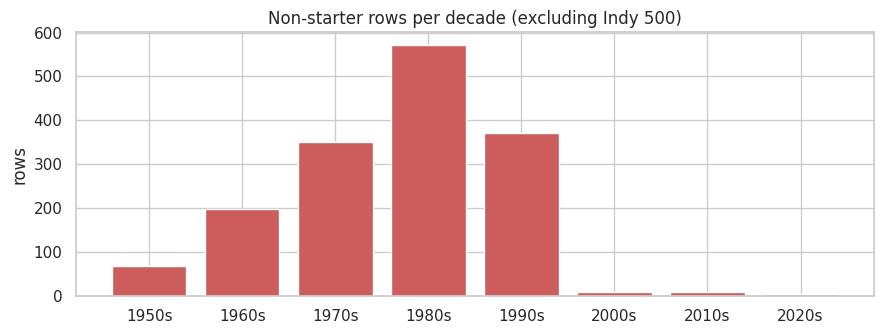

In [39]:
non_starter = ((driver_race['grid'] == 0) & (driver_race['laps'] == 0)) | driver_race['status'].isin(DNQ_STATUSES)
driver_race['is_non_starter'] = non_starter

print('Non-starter rows       :', int(non_starter.sum()))
print('Podiums among them     :', int((non_starter & (driver_race['positionOrder'] <= 3)).sum()))
print('Pit-lane starters kept :', int(((driver_race['grid'] == 0) & (driver_race['laps'] > 0)).sum()))
display(driver_race.loc[non_starter, 'status'].value_counts().head(8).to_frame('non-starter rows by status'))

ns_by_decade = driver_race[non_starter & ~driver_race['is_indy500']].groupby(driver_race['year'] // 10 * 10).size()
fig, ax = plt.subplots(figsize=(9, 3.5))
ax.bar(ns_by_decade.index.astype(str) + 's', ns_by_decade.values, color='indianred')
ax.set_title('Non-starter rows per decade (excluding Indy 500)')
ax.set_ylabel('rows')
plt.tight_layout()
plt.show()

**Decision:** exclude non-starters from the modelling scope (they stay in the full table with the flag `is_non_starter`).

**Why:**
1. **Known at the cutoff.** We predict *after qualifying*. By then everyone knows who failed to qualify, so there is nothing to predict for them.
2. **0 podiums** among them, by definition. They would add ~1,600 trivially-easy negatives, concentrated in the 1970s–1990s, which **distorts the base rate** across eras and inflates metrics without teaching the model anything.
3. **Question 3** (mechanical-retirement rate) is defined *per race start*, so non-starters must be excluded there too.

**Limitation, stated honestly:** the dataset has no explicit "pit-lane start" flag, so we use `laps > 0` only to tell a pit-lane starter from a non-starter when `grid == 0`. Laps are post-race, but here they are used only to **recover a pre-race fact** (whether the driver had a place at the start), **never as a feature**. A handful of modern rows (`grid 0`, 0 laps, mechanical status) could be pit-lane starters who failed immediately. They are non-podium either way.

In [40]:
in_scope = ~driver_race['is_indy500'] & ~driver_race['is_non_starter']
driver_race['in_model_scope'] = in_scope
rows_before = int((~driver_race['is_indy500']).sum())
log_step('3.8 Exclude non-starters (DNQ / DNPQ / 107% / withdrew before start)', 'results', rows_before, int(in_scope.sum()),
         'no starting slot at the cutoff; 0 podiums; distorts the base rate')
print('Rows in modelling scope:', int(in_scope.sum()), 'of', len(driver_race))

Rows in modelling scope: 24687 of 26632


### 3.9 Making `grid` mean what it says: pit-lane starts
**What:** for drivers who started from the pit lane (`grid == 0` but in scope), add a flag `pit_lane_start = 1` and set `grid_clean` = **the number of cars on the grid in that race**, i.e. the back of the grid, where pit-lane starters actually begin.
**Why:** a raw `0` tells a model "better than pole", which is the opposite of the truth. The fix keeps the column numeric *and* ordered correctly, and the flag preserves the information that it was a pit-lane start. Both are known before the race, so there is no leakage. We keep the original `grid` column too, for transparency.

In [41]:
scope = driver_race['in_model_scope']
pit_lane = scope & (driver_race['grid'] == 0)
cars_on_grid = driver_race[scope].groupby('raceId')['driverId'].transform('size')

driver_race['pit_lane_start'] = pit_lane.astype(int)
driver_race['grid_clean'] = driver_race['grid'].astype(float)
driver_race.loc[scope, 'cars_on_grid'] = cars_on_grid
driver_race.loc[pit_lane, 'grid_clean'] = driver_race.loc[pit_lane, 'cars_on_grid']
driver_race.loc[~scope, 'grid_clean'] = np.nan   # non-starters / Indy have no meaningful starting slot

print('Pit-lane starts:', int(pit_lane.sum()))
print(driver_race.loc[scope, ['grid', 'grid_clean']].describe().round(2))

Pit-lane starts: 72
           grid  grid_clean
count  24687.00    24687.00
mean      11.74       11.80
std        6.76        6.75
min        0.00        1.00
25%        6.00        6.00
50%       12.00       12.00
75%       17.00       17.00
max       34.00       34.00


After the fix, the minimum of `grid_clean` in scope is **1 (pole)**, as it should be. The 0s have moved to the back of the grid.

### 3.10 Building the clean driver–race table
We now join the reference tables onto our grain table. **Every join uses `validate='many_to_one'`**, which makes pandas raise an error if a join would duplicate rows. We also re-check the row count after each join (no "fan-out").

In [42]:
n_rows = len(driver_race)
table = driver_race.drop(columns=['name'])   # 'name' (race name) is re-added from races below

table = table.merge(clean['races'][['raceId', 'round', 'circuitId', 'name', 'date']].rename(columns={'name': 'race_name', 'date': 'race_date'}),
                    on='raceId', how='left', validate='many_to_one')
table = table.merge(clean['circuits'][['circuitId', 'name', 'country']].rename(columns={'name': 'circuit_name', 'country': 'circuit_country'}),
                    on='circuitId', how='left', validate='many_to_one')
table = table.merge(clean['drivers'][['driverId', 'driverRef', 'forename', 'surname', 'dob', 'nationality']].rename(columns={'nationality': 'driver_nationality'}),
                    on='driverId', how='left', validate='many_to_one')
table = table.merge(clean['constructors'][['constructorId', 'name', 'nationality']].rename(columns={'name': 'constructor_name', 'nationality': 'constructor_nationality'}),
                    on='constructorId', how='left', validate='many_to_one')
quali_cols = clean['qualifying'][['raceId', 'driverId', 'position', 'q1_s', 'q2_s', 'q3_s']].rename(columns={'position': 'quali_position'})
table = table.merge(quali_cols, on=['raceId', 'driverId'], how='left', validate='one_to_one')

assert len(table) == n_rows, 'a join changed the number of rows!'

# Semantic duration: driver age on race day (pre-race information)
table['driver_age'] = ((table['race_date'] - table['dob']).dt.days / 365.25).round(2)
table['has_quali'] = table['quali_position'].notna().astype(int)

# Target
table['podium'] = (table['positionOrder'] <= 3).astype(int)

print('Rows:', len(table), '| unique (raceId, driverId):', not table.duplicated(['raceId', 'driverId']).any())
table.head()

Rows: 26632 | unique (raceId, driverId): True


,resultId,raceId,driverId,constructorId,number,grid,position,positionText,positionOrder,points,laps,time,milliseconds,fastestLap,rank,fastestLapTime,fastestLapSpeed,statusId,fastestLapTime_s,race_time_s,year,status,is_indy500,is_non_starter,in_model_scope,pit_lane_start,grid_clean,cars_on_grid,round,circuitId,race_name,race_date,circuit_name,circuit_country,driverRef,forename,surname,dob,driver_nationality,constructor_name,constructor_nationality,quali_position,q1_s,q2_s,q3_s,driver_age,has_quali,podium
0,1,18,1,1,22,1,1,1,1,10.0,58,1:34:50.616,5690616,39,2,1:27.452,218.300,1,87.452,5690.616,2008,Finished,False,False,True,0,1.0,22.0,1,1,Australian Grand Prix,2008-03-16,Albert Park Grand Prix Circuit,Australia,hamilton,Lewis,Hamilton,1985-01-07,British,McLaren,British,1.0,86.572,85.187,86.714,23.19,1,1
1,2,18,2,2,3,5,2,2,2,8.0,58,+5.478,5696094,41,3,1:27.739,217.586,1,87.739,5696.094,2008,Finished,False,False,True,0,5.0,22.0,1,1,Australian Grand Prix,2008-03-16,Albert Park Grand Prix Circuit,Australia,heidfeld,Nick,Heidfeld,1977-05-10,German,BMW Sauber,German,5.0,85.960,85.518,87.236,30.85,1,1
2,3,18,3,3,7,7,3,3,3,6.0,58,+8.163,5698779,41,5,1:28.090,216.719,1,88.090,5698.779,2008,Finished,False,False,True,0,7.0,22.0,1,1,Australian Grand Prix,2008-03-16,Albert Park Grand Prix Circuit,Australia,rosberg,Nico,Rosberg,1985-06-27,German,Williams,British,7.0,86.295,86.059,88.687,22.72,1,1
3,4,18,4,4,5,11,4,4,4,5.0,58,+17.181,5707797,58,7,1:28.603,215.464,1,88.603,5707.797,2008,Finished,False,False,True,0,11.0,22.0,1,1,Australian Grand Prix,2008-03-16,Albert Park Grand Prix Circuit,Australia,alonso,Fernando,Alonso,1981-07-29,Spanish,Renault,French,12.0,86.907,86.188,NaN,26.63,1,0
4,5,18,5,1,23,3,5,5,5,4.0,58,+18.014,5708630,43,1,1:27.418,218.385,1,87.418,5708.63,2008,Finished,False,False,True,0,3.0,22.0,1,1,Australian Grand Prix,2008-03-16,Albert Park Grand Prix Circuit,Australia,kovalainen,Heikki,Kovalainen,1981-10-19,Finnish,McLaren,British,3.0,85.664,85.452,87.079,26.41,1,0


### 3.11 Leakage audit: which columns are allowed as features?
We label every column of the table as **pre-race** (known after qualifying, so allowed), **post-race** (future, so leakage), **target**, **ID**, or **flag**. This is the same idea as removing `sex` from `X` in the penguins lab, because otherwise the model reads the answer.

In [43]:
COLUMN_ROLES = {
    'ID / key': ['resultId', 'raceId', 'driverId', 'constructorId', 'circuitId', 'driverRef'],
    'pre-race (allowed as feature input)': ['year', 'round', 'race_date', 'race_name', 'circuit_name', 'circuit_country',
                                             'number', 'grid', 'grid_clean', 'pit_lane_start', 'cars_on_grid',
                                             'quali_position', 'q1_s', 'q2_s', 'q3_s', 'has_quali',
                                             'forename', 'surname', 'dob', 'driver_age', 'driver_nationality',
                                             'constructor_name', 'constructor_nationality'],
    'post-race (LEAKAGE - never a feature)': ['position', 'positionText', 'positionOrder', 'points', 'laps', 'time',
                                              'milliseconds', 'race_time_s', 'fastestLap', 'rank', 'fastestLapTime',
                                              'fastestLapTime_s', 'fastestLapSpeed', 'status', 'statusId'],
    'target': ['podium'],
    'cleaning flag': ['is_indy500', 'is_non_starter', 'in_model_scope'],
}
role_of = {col: role for role, cols in COLUMN_ROLES.items() for col in cols}
unlabelled = [c for c in table.columns if c not in role_of]
print('Columns without a role:', unlabelled)

role_table = pd.DataFrame({'column': table.columns, 'role': [role_of.get(c, '?') for c in table.columns]})
role_table.groupby('role')['column'].apply(', '.join).to_frame()

Columns without a role: []


,column
role,
ID / key,"resultId, raceId, driverId, constructorId, cir..."
cleaning flag,"is_indy500, is_non_starter, in_model_scope"
post-race (LEAKAGE - never a feature),"position, positionText, positionOrder, points,..."
pre-race (allowed as feature input),"number, grid, year, pit_lane_start, grid_clean..."
target,podium


> **For the feature-engineering stage:** "pre-race" columns are safe *as they are*. Any feature built from **past races**, such as driver form, constructor form or championship standings, must use **only races before the current one** (e.g. standings shifted by one race), because the standings tables are computed *after* each race. Sprint results (2021+) happen before the main race, so whether to use them is a judgement call to document.

### 3.12 Final validation: does the clean data satisfy every rule?
These `assert` statements stop the notebook if anything is wrong, so a successful Run All proves the checks hold.

In [44]:
model_table = table[table['in_model_scope']].copy()

# 1) Grain
assert not table.duplicated(['raceId', 'driverId']).any()
assert not model_table.duplicated(['raceId', 'driverId']).any()
# 2) Target consistency: exactly 3 podium finishers in every race
assert (model_table.groupby('raceId')['podium'].sum() == 3).all()
# 3) No sentinel strings anywhere in the cleaned tables
assert all(int((clean[t] == SENTINEL).sum().sum()) == 0 for t in TABLES)
# 4) Keys still valid after cleaning
assert check_primary_keys(clean)['OK'].all()
assert check_foreign_keys(clean)['OK'].all()
# 5) Semantic types
assert pd.api.types.is_datetime64_any_dtype(table['race_date']) and pd.api.types.is_numeric_dtype(table['position'])
# 6) grid_clean in scope is a real position >= 1
assert model_table['grid_clean'].min() >= 1
# 7) Raw files untouched (immutability)
assert all(fingerprint(raw[t]) == raw_fingerprint[t] for t in TABLES)

print('All validation checks passed')
print('Full driver-race table :', table.shape)
print('Modelling-scope table  :', model_table.shape, f"| podium rate = {model_table['podium'].mean():.3f}")

All validation checks passed
Full driver-race table : (26632, 48)
Modelling-scope table  : (24687, 48) | podium rate = 0.135


# 4. EDA after cleaning: the impact of the cleaning

### 4.1 Before vs after, in numbers

In [45]:
def summarise(df, label, target_col='positionOrder'):
    podium_rows = df[df[target_col] <= 3].groupby('raceId').size().reindex(df['raceId'].unique(), fill_value=0)
    return {'dataset': label, 'rows': len(df), 'races': df['raceId'].nunique(),
            'duplicate (raceId, driverId)': int(df.duplicated(['raceId', 'driverId']).sum()),
            'races with exactly 3 podium rows': f"{int((podium_rows == 3).sum())} / {df['raceId'].nunique()}",
            'podium rate': round(float((df[target_col] <= 3).mean()), 4),
            'rows with grid = 0': int((df['grid'] == 0).sum()),
            'text-typed numeric columns': int(sum(1 for c in ['position', 'milliseconds', 'fastestLap', 'rank', 'fastestLapSpeed']
                                                   if not pd.api.types.is_numeric_dtype(df[c])))}

pd.DataFrame([summarise(raw['results'], 'raw results'), summarise(model_table, 'clean modelling table')]).set_index('dataset').T

dataset,raw results,clean modelling table
rows,26759,24687
races,1125,1114
"duplicate (raceId, driverId)",91,0
races with exactly 3 podium rows,1107 / 1125,1114 / 1114
podium rate,0.1269,0.1354
rows with grid = 0,1638,72
text-typed numeric columns,5,0


,step,table,rows before,rows after,rows removed,reason
0,3.5 Shared drives: keep the starting car per (...,results,26759,26668,91,driver appears twice in one race (car swap); k...
1,3.6 Relief drivers: drop the 2nd driver credit...,results,26668,26632,36,"same car (race, constructor, number, grid) cre..."
2,3.7 Exclude Indianapolis 500 (1950-1960),results,26632,26269,363,separate population: 4/104 drivers and 3/34 co...
3,3.8 Exclude non-starters (DNQ / DNPQ / 107% / ...,results,26269,24687,1582,no starting slot at the cutoff; 0 podiums; dis...


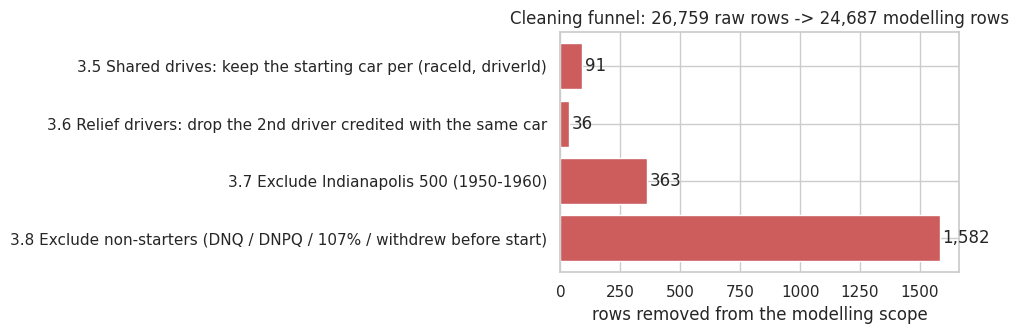

In [46]:
log_df = pd.DataFrame(cleaning_log)
display(log_df)

fig, ax = plt.subplots(figsize=(10, 3.5))
ax.barh(log_df['step'][::-1], log_df['rows removed'][::-1], color='indianred')
for i, v in enumerate(log_df['rows removed'][::-1]):
    ax.text(v + 10, i, f'{v:,}', va='center')
ax.set_xlabel('rows removed from the modelling scope')
ax.set_title(f"Cleaning funnel: {len(raw['results']):,} raw rows -> {len(model_table):,} modelling rows")
plt.tight_layout()
plt.show()

The **row-removing steps** are listed above. Sentinels, typing, label fixes and the `position` repair changed *values*, not rows. The two grain fixes remove only ~130 rows but are what make the target correct. The non-starter exclusion is the largest step.

### 4.2 Rows per race and podium rate per season: before vs after

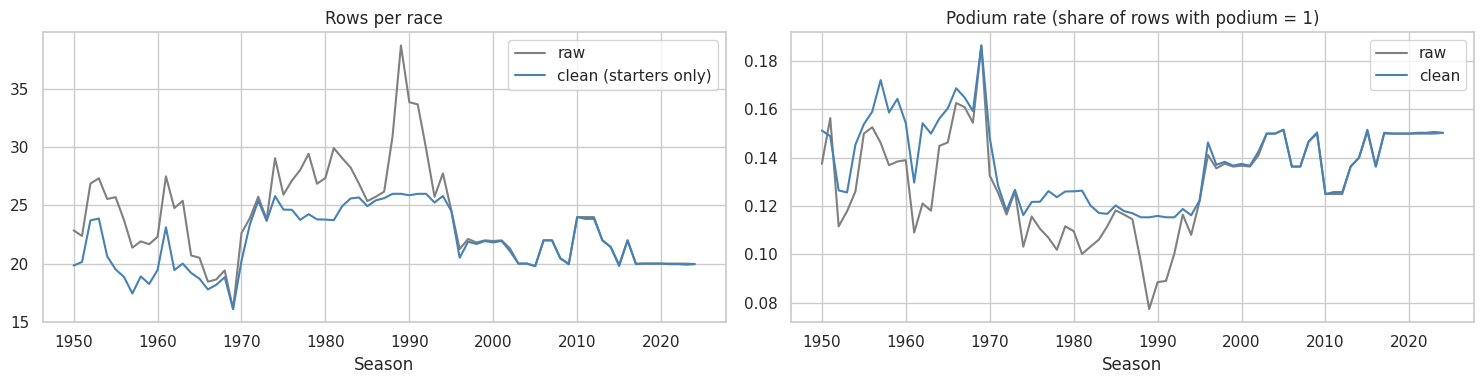

In [47]:
raw_season = raw['results'].merge(raw['races'][['raceId', 'year']], on='raceId')
raw_season['podium'] = (raw_season['positionOrder'] <= 3).astype(int)
before = raw_season.groupby('year').agg(rows_per_race=('raceId', lambda s: len(s) / s.nunique()), podium_rate=('podium', 'mean'))
after_ = model_table.groupby('year').agg(rows_per_race=('raceId', lambda s: len(s) / s.nunique()), podium_rate=('podium', 'mean'))

fig, axes = plt.subplots(1, 2, figsize=(15, 4))
axes[0].plot(before.index, before['rows_per_race'], label='raw', color='grey')
axes[0].plot(after_.index, after_['rows_per_race'], label='clean (starters only)', color='steelblue')
axes[0].set_title('Rows per race')
axes[0].legend()
axes[1].plot(before.index, before['podium_rate'], label='raw', color='grey')
axes[1].plot(after_.index, after_['podium_rate'], label='clean', color='steelblue')
axes[1].set_title('Podium rate (share of rows with podium = 1)')
axes[1].legend()
for ax in axes:
    ax.set_xlabel('Season')
plt.tight_layout()
plt.show()

- **Left:** after cleaning, rows per race equal **the number of cars that actually started**. The 1950s spikes (Indy 500, shared drives) and the late-1980s peak (up to 39 entrants for 26 grid slots) are gone.
- **Right:** the clean podium rate is now simply **3 ÷ starters**. It ranges from ~11.5 % (26-car grids of the 1980s) to 15 % (20 cars today), with a peak in the late 1960s when grids had only ~16–20 cars. In the raw data the rate dropped artificially, down to 8 % in 1989, when many cars entered but didn't qualify.
- **Class imbalance:** podiums are only ~13 % of rows overall. This is why the brief lists **PR-AUC**, which is more informative than ROC-AUC when the positive class is rare.

### 4.3 Grid position: before vs after the `grid = 0` fix

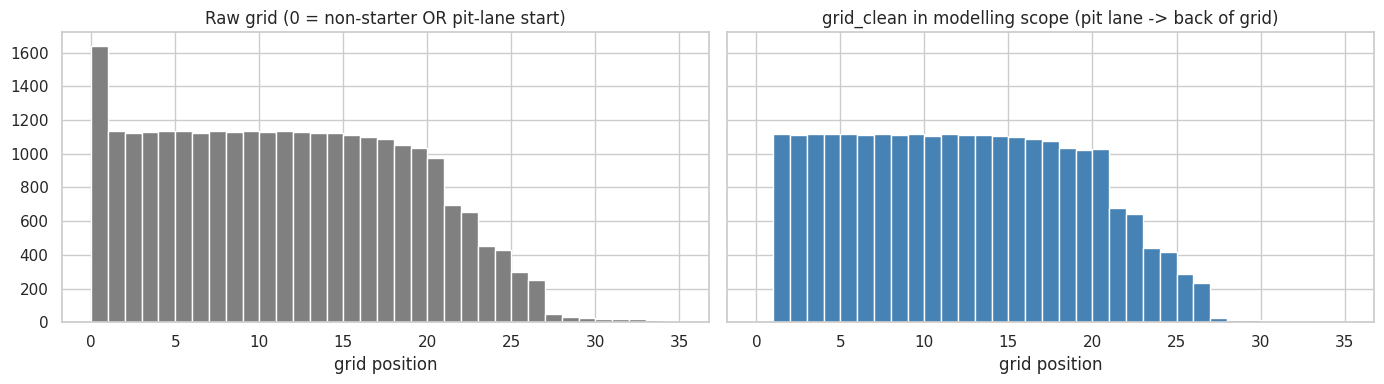

In [48]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4), sharey=True)
axes[0].hist(raw['results']['grid'], bins=range(0, 36), color='grey', edgecolor='white')
axes[0].set_title('Raw grid (0 = non-starter OR pit-lane start)')
axes[1].hist(model_table['grid_clean'], bins=range(0, 36), color='steelblue', edgecolor='white')
axes[1].set_title('grid_clean in modelling scope (pit lane -> back of grid)')
for ax in axes:
    ax.set_xlabel('grid position')
plt.tight_layout()
plt.show()

The spike at 0 has disappeared. The non-starters were removed, and the few pit-lane starters moved to the back of the grid, where they really start.

### 4.4 How strongly does starting position relate to a podium?

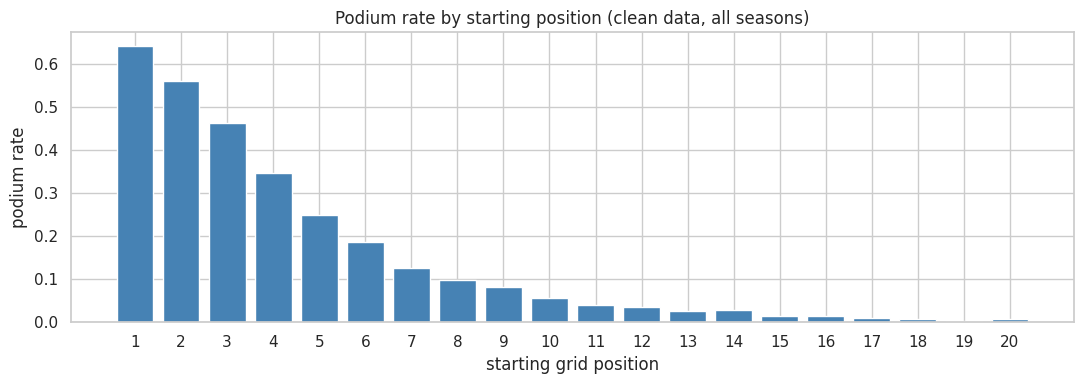

{1.0: 0.641, 2.0: 0.559, 3.0: 0.461, 4.0: 0.346, 5.0: 0.248, 6.0: 0.186}


In [49]:
by_grid = model_table[model_table['grid_clean'] <= 20].groupby('grid_clean')['podium'].mean()
fig, ax = plt.subplots(figsize=(11, 4))
ax.bar(by_grid.index.astype(int).astype(str), by_grid.values, color='steelblue')
ax.set_xlabel('starting grid position')
ax.set_ylabel('podium rate')
ax.set_title('Podium rate by starting position (clean data, all seasons)')
plt.tight_layout()
plt.show()
print(by_grid.head(6).round(3).to_dict())

The podium rate falls steeply with grid position. Pole position finishes on the podium about **64 %** of the time, P2 56 %, P3 46 %, and beyond roughly P10 a podium becomes rare. This makes `grid_clean` the strongest candidate feature, as the F1 guide predicts. As always, this is a **correlation, not a cause**: fast cars both qualify well and finish well.

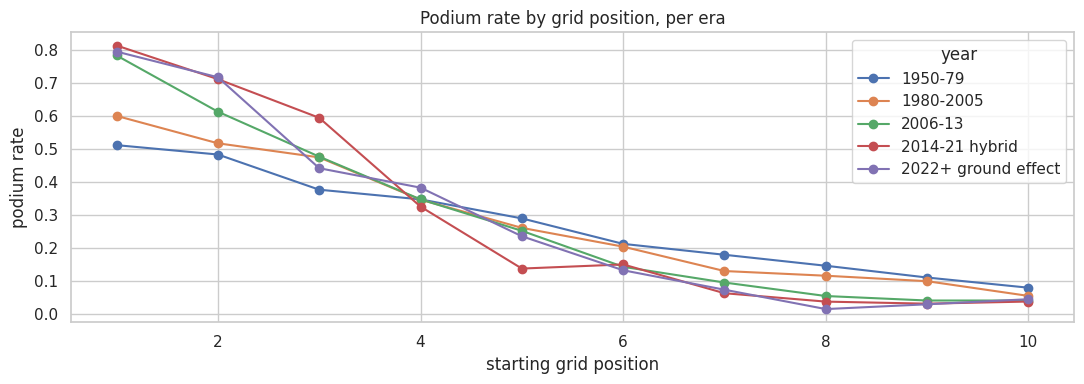

In [50]:
era = pd.cut(model_table['year'], bins=[1949, 1979, 2005, 2013, 2021, 2030],
             labels=['1950-79', '1980-2005', '2006-13', '2014-21 hybrid', '2022+ ground effect'])
front_rows = model_table[model_table['grid_clean'] <= 10]
era_grid = front_rows.groupby([era[front_rows.index], 'grid_clean'], observed=True)['podium'].mean().unstack(0)
era_grid.index = era_grid.index.astype(int)
fig, ax = plt.subplots(figsize=(11, 4))
era_grid.plot(ax=ax, marker='o')
ax.set_xlabel('starting grid position')
ax.set_ylabel('podium rate')
ax.set_title('Podium rate by grid position, per era')
plt.tight_layout()
plt.show()

The *shape* of the relationship is similar in every era, but its **strength changes**. The grid matters more in the modern, reliable eras than in the early decades, when many front-runners broke down. This is **era sensitivity**, a known limitation: a model trained mostly on old seasons may not transfer to the 2022+ test seasons.

### 4.5 Qualifying position vs actual grid

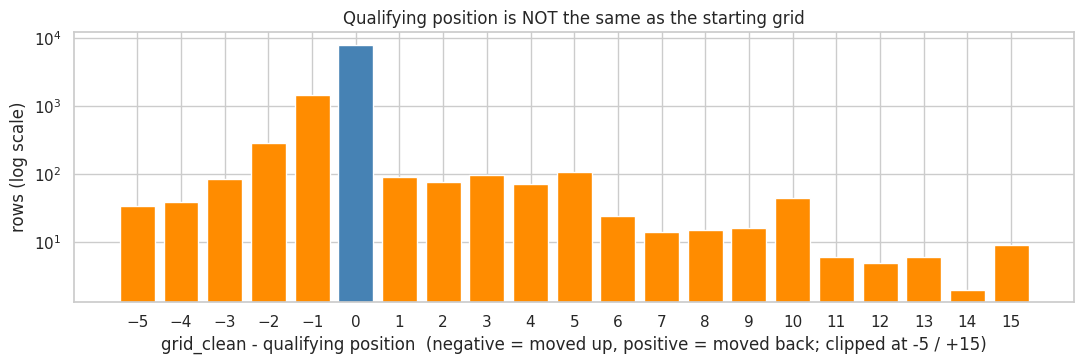

Same as qualifying: 76.3% | moved up: 18.1% (exactly 1 place: 13.9%) | moved back: 5.6% (3+ places: 4.0%)


In [51]:
with_q = model_table[model_table['has_quali'] == 1]
diff = (with_q['grid_clean'] - with_q['quali_position']).clip(-5, 15).astype(int)
counts = diff.value_counts().sort_index()
fig, ax = plt.subplots(figsize=(11, 3.8))
ax.bar(counts.index, counts.values, color=['steelblue' if d == 0 else 'darkorange' for d in counts.index])
ax.set_yscale('log')
ax.set_xticks(range(-5, 16))
ax.set_xlabel('grid_clean - qualifying position  (negative = moved up, positive = moved back; clipped at -5 / +15)')
ax.set_ylabel('rows (log scale)')
ax.set_title('Qualifying position is NOT the same as the starting grid')
plt.tight_layout()
plt.show()
print(f"Same as qualifying: {(diff == 0).mean():.1%} | moved up: {(diff < 0).mean():.1%} "
      f"(exactly 1 place: {(diff == -1).mean():.1%}) | moved back: {(diff > 0).mean():.1%} (3+ places: {(diff >= 3).mean():.1%})")

In about **a quarter of the rows** the starting grid differs from the qualifying position. The plot (log scale) shows how penalties work:
- a **penalised** driver drops several places, sometimes to the back or the pit lane (the long tail on the right),
- every driver he drops behind **moves up by one place**, which is why "−1" is by far the most common difference.

This is why the brief insists on distinguishing qualifying from grid (Question 1), and why both columns are kept.

### 4.6 Qualifying coverage after cleaning: the main known limitation

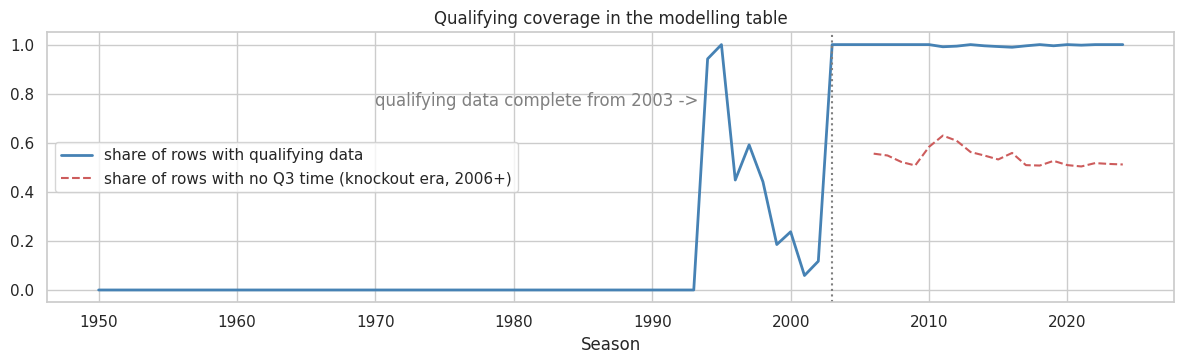

Rows with qualifying data: 42.4% of the modelling table
Rows without a Q3 time in 2006+: 53.9%


In [52]:
cov = model_table.groupby('year').agg(quali_coverage=('has_quali', 'mean'),
                                      q3_missing=('q3_s', lambda s: s.isna().mean()))
knockout = cov.loc[2006:]          # Q1/Q2/Q3 knockout format exists from 2006
fig, ax = plt.subplots(figsize=(12, 3.8))
ax.plot(cov.index, cov['quali_coverage'], label='share of rows with qualifying data', color='steelblue', linewidth=2)
ax.plot(knockout.index, knockout['q3_missing'], label='share of rows with no Q3 time (knockout era, 2006+)',
        color='indianred', linestyle='--')
ax.axvline(2003, color='grey', linestyle=':')
ax.text(1970, 0.75, 'qualifying data complete from 2003 ->', color='grey')
ax.set_xlabel('Season')
ax.set_ylim(-0.05, 1.05)
ax.legend(loc='center left')
ax.set_title('Qualifying coverage in the modelling table')
plt.tight_layout()
plt.show()
print(f"Rows with qualifying data: {model_table['has_quali'].mean():.1%} of the modelling table")
print(f"Rows without a Q3 time in 2006+: {knockout['q3_missing'].mean():.1%}")

- Qualifying data exists for only about **42 % of all modelling rows**, and none before 1994. It is patchy until 2002 and complete from **2003**.
- In the knockout era (2006+) about **half the rows have no Q3 time**, by design: only the top 10 reach Q3. This missingness is **structural (Missing Not At Random)**. Mean-imputing a Q3 time would claim that a driver set a lap time in a session he never took part in.

**Recommendation for the feature stage:** use `grid_clean` (always available) as the main starting-position feature, treat qualifying features as available only from 2003 (or add a `has_quali` indicator), and never fill Q2/Q3 with an average. The proposed split (train ≤ 2019, validation 2020–21, test ≥ 2022) has complete qualifying data in validation and test.

### 4.7 How races end, by decade: reliability changes the meaning of the grid

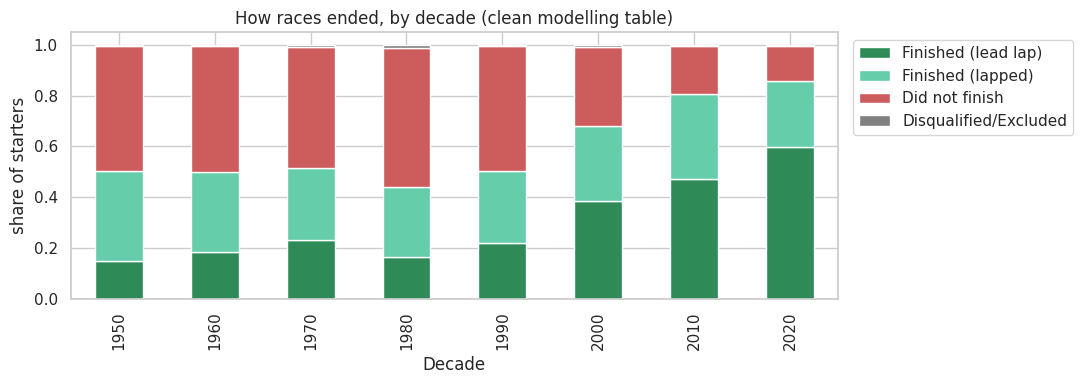

Share of starters who did not finish, by decade: {1950: 0.49, 1960: 0.49, 1970: 0.48, 1980: 0.55, 1990: 0.49, 2000: 0.31, 2010: 0.19, 2020: 0.14}


In [53]:
def status_group(s):
    if s == 'Finished':
        return 'Finished (lead lap)'
    if s.startswith('+') and 'Lap' in s:
        return 'Finished (lapped)'
    if s in ['Disqualified', 'Excluded']:
        return 'Disqualified/Excluded'
    return 'Did not finish'

groups = model_table['status'].map(status_group)
order = ['Finished (lead lap)', 'Finished (lapped)', 'Did not finish', 'Disqualified/Excluded']
decade_share = pd.crosstab(model_table['year'] // 10 * 10, groups, normalize='index')[order]
ax = decade_share.plot(kind='bar', stacked=True, figsize=(11, 4),
                       color=['seagreen', 'mediumaquamarine', 'indianred', 'grey'])
ax.set_xlabel('Decade')
ax.set_ylabel('share of starters')
ax.set_title('How races ended, by decade (clean modelling table)')
ax.legend(bbox_to_anchor=(1.01, 1), loc='upper left')
plt.tight_layout()
plt.show()
print('Share of starters who did not finish, by decade:', decade_share['Did not finish'].round(2).to_dict())

From the 1950s to the 1990s roughly **half the starters did not finish**. That share fell to about 31 % in the 2000s, 19 % in the 2010s and 14 % in the 2020s. Early-era podiums therefore depend much more on luck and reliability, which explains the weaker grid effect in 4.4.

*(This is a quick 4-group EDA view. Question 3 needs a careful **mechanical vs non-mechanical** mapping of the ~130 status values, which is a separate, documented task.)*

### 4.8 Durations after semantic typing: now we can actually analyse them

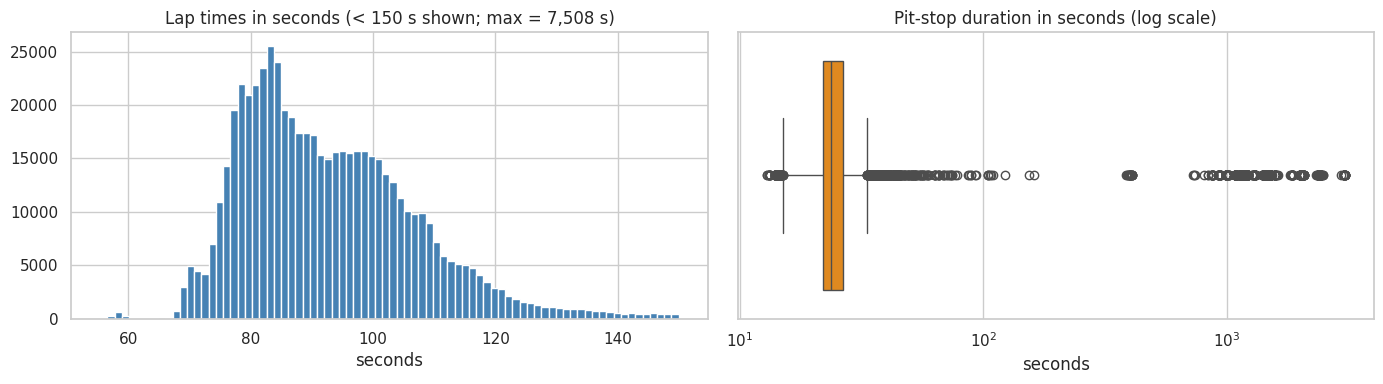

Pit stops longer than 60 s: 4.5% | laps longer than 5 min: 708


In [54]:
lap_s = clean['lap_times']['lap_time_s']
pit_s = clean['pit_stops']['duration_s']
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].hist(lap_s[lap_s < 150], bins=80, color='steelblue')
axes[0].set_title(f'Lap times in seconds (< 150 s shown; max = {lap_s.max():,.0f} s)')
axes[0].set_xlabel('seconds')
sns.boxplot(x=pit_s, ax=axes[1], color='darkorange')
axes[1].set_xscale('log')
axes[1].set_title('Pit-stop duration in seconds (log scale)')
axes[1].set_xlabel('seconds')
plt.tight_layout()
plt.show()
print(f"Pit stops longer than 60 s: {(pit_s > 60).mean():.1%} | laps longer than 5 min: {(lap_s > 300).sum()}")

Once converted to seconds, the distributions make sense. Typical laps take 70–110 s and typical pit-lane passes take 20–30 s. The extreme values (laps over an hour, "pit stops" of several minutes) are **red-flag suspensions**, when cars waited in the pit lane during a stopped race. They are **real events, not typing errors**, as the text and the milliseconds agree exactly (2.3). So we **keep** them and do not "remove outliers". Both tables are post-race anyway and cannot be features.

### 4.9 Correlation of the pre-race numeric columns with the target

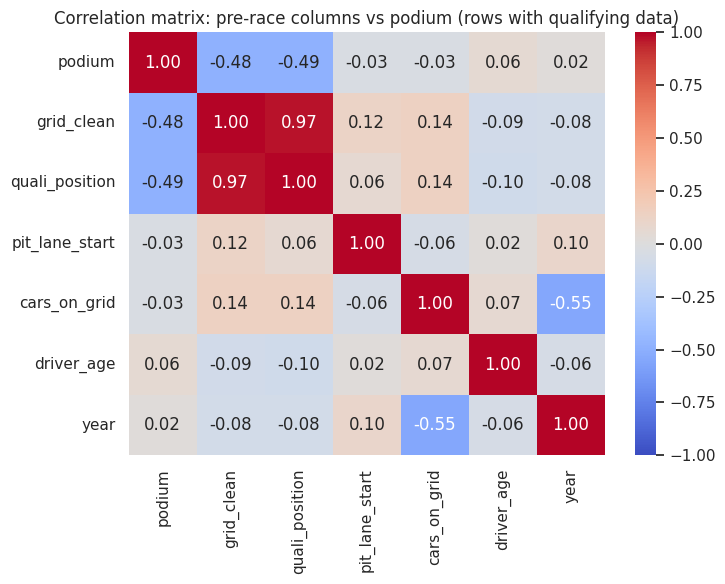

In [55]:
corr_cols = ['podium', 'grid_clean', 'quali_position', 'pit_lane_start', 'cars_on_grid', 'driver_age', 'year']
corr = model_table.loc[model_table['has_quali'] == 1, corr_cols].astype(float).corr()
plt.figure(figsize=(7.5, 6))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1)
plt.title('Correlation matrix: pre-race columns vs podium (rows with qualifying data)')
plt.tight_layout()
plt.show()

- `grid_clean` and `quali_position` have the strongest (negative) correlation with `podium`: a lower number means starting nearer the front, which means more podiums.
- `grid_clean` and `quali_position` are themselves almost perfectly correlated (0.97). They carry largely the same information. This is worth remembering for feature selection and when reading feature importance.
- `driver_age`, `year`, `pit_lane_start` and `cars_on_grid` have almost no linear relationship with `podium`. (`year` and `cars_on_grid` correlate with each other at −0.55, because grids shrank over time.)
- Pearson correlation only measures *linear* relationships, and **correlation is not causation**. These numbers are evidence for feature selection, not proof that a feature causes podiums.

### 4.10 Missing values in the final modelling table

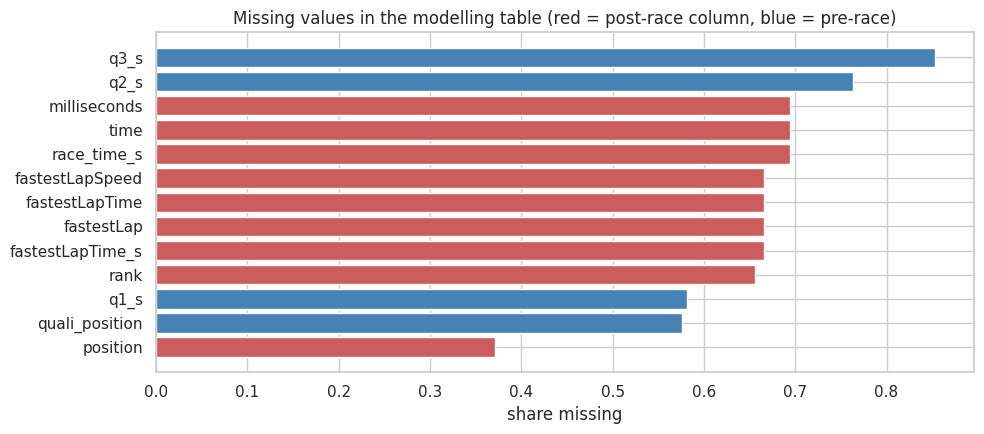

In [56]:
miss = model_table.isna().mean().sort_values(ascending=False)
miss = miss[miss > 0]
fig, ax = plt.subplots(figsize=(10, 4.5))
colors = ['indianred' if role_of.get(c, '').startswith('post') else 'steelblue' for c in miss.index]
ax.barh(miss.index[::-1], miss.values[::-1], color=colors[::-1])
ax.set_xlabel('share missing')
ax.set_title('Missing values in the modelling table (red = post-race column, blue = pre-race)')
plt.tight_layout()
plt.show()

The **only pre-race columns with gaps are the qualifying ones** (structural, explained above). The post-race columns (red) have gaps because, for example, retired drivers have no race time. They are excluded from features anyway, so their gaps do not matter for modelling. The key pre-race columns (`grid_clean`, year, driver, constructor, circuit) are **complete**.

# 5. Data-Quality Report (summary)

| # | Issue found | Evidence | Action | Why |
|---|---|---|---|---|
| 1 | `\N` sentinel in 25+ columns | sentinel scan (1.4) | → `NaN` | numeric columns were read as text |
| 2 | Second sentinel: empty strings in `qualifying.q2/q3` | sentinel scan (1.4) | → `NaN` | consistent handling of both placeholders |
| 3 | Numbers, dates and durations stored as text | dtypes (1.3) | semantic typing, 0 new NaNs (3.2) | correct sorting, maths and plots |
| 4 | Lap times in `h:mm:ss`, pit stops in `m:ss` formats | consistency checks (2.3) | parser handles every format, verified against milliseconds | a naïve `m:ss` parser would crash or mis-read |
| 5 | Stray whitespace and duplicate labels (`Argentinian`/`Argentine`, `United States`/`USA`) | consistency checks (2.3) | strip + standardise (3.3) | the home-race analysis groups by country |
| 6 | `position` missing while `positionText` numeric (2 rows) | consistency checks (2.3) | repaired from `positionText` (3.4) | the two columns must agree |
| 7 | `position` ≠ `positionOrder` (1983 Brazil, P2 vacated) | consistency checks (2.3) | kept, target uses `positionOrder` | the brief's definition: the final classification |
| 8 | 91 duplicate `(raceId, driverId)` rows (shared drives) | grain check (1.7), resultId plot, rule comparison (3.5) | keep the **starting car** (car credited only to him, else lowest `resultId`) | pre-race consistency; the best-result rule leaks and double-counts; the brief's non-zero-grid rule can't separate the rows |
| 9 | Relief-driver rows sharing one car's result | races with >3 podium rows (3.6) | drop the later row | exactly 3 podiums in every race afterwards |
| 10 | Indianapolis 500 (1950–60) is a separate population | only 4 Indy drivers ever raced a regular GP (3.7) | flagged, excluded from scope | would contaminate form features and Q2 |
| 11 | ~1,600 non-starter rows (DNQ/DNPQ/107 %/withdrew) | 0 podiums, decade plot (3.8) | flagged, excluded from scope | known at the cutoff; distorts the base rate |
| 12 | 19 rows "did not qualify" but `grid > 0` | consistency checks (2.3) | caught by the status-based non-starter rule | `grid` alone would wrongly keep them |
| 13 | `grid = 0` mixes non-starters and pit-lane starts | grid analysis (2.3, 3.8) | `pit_lane_start` flag + `grid_clean` = back of grid | 0 would mean "better than pole" |
| 14 | Qualifying position ≠ grid in ~24 % of rows | 2.3, 4.5 | keep both columns | penalties are real (Q1) |
| 15 | Qualifying coverage drift (none before 1994, patchy until 2002) | coverage heatmap (1.6, 4.6) | documented; `has_quali` flag; no mean-imputation | structural MNAR missingness |
| 16 | Standings rows for drivers who did not race | composite FK check (2.2) | documented | standings are post-race; must be shifted for features |
| 17 | PK/FK integrity | 14 PKs, 23 FKs, composite keys | all valid, re-checked after cleaning (3.12) | joins are safe and lose no rows |

### Known limitations
- **Qualifying-coverage drift:** qualifying features exist only for about 42 % of the rows (fully from 2003).
- **Era sensitivity:** reliability, field sizes and the strength of the grid effect change strongly across eras (4.4, 4.7). Old seasons may not represent 2022+.
- **Shared-drive trade-off:** a driver who took over a teammate's car and reached the podium is labelled by his *own* starting car. When both of a driver's cars were shared and both rows are in the race's original rows, the row order is the only evidence left.
- **Pit-lane vs non-starter ambiguity:** without an explicit pit-lane flag, a few modern `grid 0, 0 laps` rows can't be told apart with certainty (all non-podium).
- **Constructor identity drift:** renamed teams (Toleman → Benetton → Renault → Lotus → Alpine) have different `constructorId`s, so team history resets at a rename.
- **1983 Brazilian GP:** using `positionOrder` labels the officially 4th-placed driver as a podium (vacated P2), following the brief's target definition.

# 6. Save the outputs for the team
We write the cleaned tables and the driver–race table to the Kaggle working directory. The raw input files are untouched (Kaggle inputs are read-only anyway, and we verified this with the fingerprints in 3.12).

In [57]:
for t in TABLES:
    clean[t].to_csv(os.path.join(OUT_DIR, 'clean_tables', f'{t}_clean.csv'), index=False)

table.to_csv(os.path.join(OUT_DIR, 'driver_race_all.csv'), index=False)          # every grain-fixed row + flags
model_table.to_csv(os.path.join(OUT_DIR, 'driver_race_model.csv'), index=False)  # modelling scope only
log_df.to_csv(os.path.join(OUT_DIR, 'cleaning_log.csv'), index=False)
consistency_report.to_csv(os.path.join(OUT_DIR, 'consistency_checks.csv'), index=False)
role_table.to_csv(os.path.join(OUT_DIR, 'column_roles.csv'), index=False)

for f in sorted(os.listdir(OUT_DIR)):
    print(f)
print('clean_tables/:', len(os.listdir(os.path.join(OUT_DIR, 'clean_tables'))), 'files')

__notebook__.ipynb
clean_tables
cleaning_log.csv
column_roles.csv
consistency_checks.csv
driver_race_all.csv
driver_race_model.csv
clean_tables/: 14 files


**Summary.** Starting from 14 raw relational tables, we:
- audited every column (sentinels, types), every key (14 PKs, 23 FKs plus composite links) and 19 consistency rules,
- turned the placeholders into real missing values and gave every date and duration its proper type, losing no values,
- fixed the `(raceId, driverId)` grain with a rule chosen by **measured evidence** (exactly 3 podiums in every race afterwards),
- made two documented scope decisions (Indy 500, non-starters) and fixed the meaning of `grid = 0`,
- produced a validated, leakage-labelled driver–race table, `driver_race_model.csv`, that the feature-engineering and modelling stages can build on.

# 7. Data-Engineering Questions

## Q1. Which circuits convert a front-row start into a podium most often, and does the ranking change after 2014?

**Tables needed (multi-hop join):** `results` (grid, finishing order) → `races` (year, circuitId) → `circuits` (circuit name), plus `qualifying` (qualifying position) joined on `(raceId, driverId)`. `results` alone has no year, no circuit and no qualifying position, so the question cannot be answered from it.

**Two definitions of "front row"**, because qualifying and grid differ (penalties, pit-lane starts):
- **front row by grid**: `grid_clean` ∈ {1, 2}, where the car actually started.
- **front row by qualifying**: `quali_position` ∈ {1, 2}, where the car qualified.

**Grain:** one row per (raceId, driverId), the cleaned modelling scope (no Indy 500, no non-starters, shared drives resolved). Every race should therefore have exactly 2 front-row starters.

### Q1.1 Building the Q1 table and checking it

In [58]:
from statsmodels.stats.proportion import proportion_confint
from scipy.stats import spearmanr

# Multi-hop join written out explicitly: results -> races -> circuits, and results <-> qualifying
q1 = (model_table[['raceId', 'driverId', 'grid_clean', 'pit_lane_start', 'laps', 'status', 'podium']]
      .merge(clean['races'][['raceId', 'year', 'circuitId']],
             on='raceId', how='left', validate='many_to_one')
      .merge(clean['circuits'][['circuitId', 'name', 'country']].rename(columns={'name': 'circuit_name'}),
             on='circuitId', how='left', validate='many_to_one')
      .merge(clean['qualifying'][['raceId', 'driverId', 'position']].rename(columns={'position': 'quali_position'}),
             on=['raceId', 'driverId'], how='left', validate='one_to_one'))
assert len(q1) == len(model_table), 'a join changed the number of rows!'

# A front-row START must be a car that actually took the start. Cars that failed on the way to the grid
# are recorded inconsistently: some get grid 0 (already out of scope, 3.8), others keep their grid slot
# with 0 laps. In our window (2003+), 0 laps without a start crash identifies exactly the two documented
# non-starts printed below. Before 2003, 0 laps can also be a lap-1 failure of a car that DID start
# (e.g. Schumacher, Silverstone 1999), so the rule is only applied from 2003.
START_CRASH = ['Collision', 'Accident', 'Collision damage', 'Spun off']
q1['took_start'] = (q1['year'] < 2003) | (q1['laps'] > 0) | q1['status'].isin(START_CRASH)
print('Front-row cars (grid 1-2) that never took the start, 2003+:')
print(q1[(q1['grid_clean'] <= 2) & ~q1['took_start']]
      .merge(clean['races'][['raceId', 'name']], on='raceId', validate='many_to_one')
      .merge(clean['drivers'][['driverId', 'surname']], on='driverId', validate='many_to_one')
      [['year', 'name', 'surname', 'grid_clean', 'laps', 'status']].to_string(index=False), '\n')

q1['front_row_grid'] = (q1['grid_clean'] <= 2) & q1['took_start']
q1['front_row_quali'] = (q1['quali_position'] <= 2) & q1['took_start']   # NaN (no qualifying data) -> False

# Check 1: does every race have exactly 2 front-row starters by grid?
fr_grid_per_race = q1.groupby('raceId')['front_row_grid'].sum()
print('Front-row starters (grid) per race:')
print(fr_grid_per_race.value_counts().sort_index().rename_axis('front-row rows').to_frame('races'), '\n')

# Check 2: qualifying coverage per season around the start of the data (justifies the 2003 window)
races_with_quali = q1.groupby(['year', 'raceId'])['quali_position'].apply(lambda s: s.notna().any())
print('Share of races with qualifying data, 1994-2005:')
print(races_with_quali.groupby('year').mean().loc[1994:2005].round(2).to_dict(), '\n')

# Check 3: from 2003 on, does every race have exactly 2 front-row qualifiers?
fr_quali_per_race = q1[q1['year'] >= 2003].groupby('raceId')['front_row_quali'].sum()
print('Front-row qualifiers per race (2003+):')
print(fr_quali_per_race.value_counts().sort_index().rename_axis('front-row rows').to_frame('races'))

Front-row cars (grid 1-2) that never took the start, 2003+:
 year                     name   surname  grid_clean  laps     status
 2005 United States Grand Prix    Trulli         1.0     0   Withdrew
 2005 United States Grand Prix Räikkönen         2.0     0   Withdrew
 2021        Monaco Grand Prix   Leclerc         1.0     0 Driveshaft 

Front-row starters (grid) per race:
                races
front-row rows       
0                   1
1                   4
2                1107
3                   1
4                   1 

Share of races with qualifying data, 1994-2005:
{1994: 0.94, 1995: 1.0, 1996: 0.44, 1997: 0.59, 1998: 0.44, 1999: 0.19, 2000: 0.24, 2001: 0.06, 2002: 0.12, 2003: 1.0, 2004: 1.0, 2005: 1.0} 

Front-row qualifiers per race (2003+):
                races
front-row rows       
0                   1
1                   3
2                 424


Checks 1 and 3 show a handful of races that do not have exactly 2 front-row rows. Before computing any rate we look at each one, because a race with 4 "front-row" rows would count 4 conversion attempts instead of 2.

In [59]:
odd_grid = fr_grid_per_race[fr_grid_per_race != 2].index
odd_quali = fr_quali_per_race[fr_quali_per_race != 2].index
cols = ['raceId', 'year', 'race_name', 'driverId', 'surname', 'grid', 'grid_clean', 'quali_position',
        'positionOrder', 'laps', 'status', 'in_model_scope']

print('Races with != 2 front-row starters by GRID (all rows with grid 1-3, in scope or not):')
display(table[table['raceId'].isin(odd_grid) & table['grid'].between(1, 3)]
        .sort_values(['raceId', 'grid'])[cols])

print('Races (2003+) with != 2 front-row QUALIFIERS (qualifying rows with position 1-2, joined to our table):')
qual_fr = clean['qualifying'][clean['qualifying']['raceId'].isin(odd_quali) & (clean['qualifying']['position'] <= 2)]
display(qual_fr[['raceId', 'driverId', 'position']]
        .merge(table[['raceId', 'driverId', 'year', 'race_name', 'surname', 'grid', 'laps', 'status', 'in_model_scope']],
               on=['raceId', 'driverId'], how='left'))

Races with != 2 front-row starters by GRID (all rows with grid 1-3, in scope or not):


,raceId,year,race_name,driverId,surname,grid,grid_clean,quali_position,positionOrder,laps,status,in_model_scope
1300,79,2005,United States Grand Prix,15,Trulli,1,1.0,1.0,7,0,Withdrew,True
1301,79,2005,United States Grand Prix,8,Räikkönen,2,2.0,2.0,8,0,Withdrew,True
1302,79,2005,United States Grand Prix,18,Button,3,3.0,3.0,9,0,Withdrew,True
17345,717,1964,United States Grand Prix,373,Clark,1,1.0,NaN,7,102,Out of fuel,True
26484,717,1964,United States Grand Prix,374,Spence,1,1.0,NaN,12,54,Injection,True
17340,717,1964,United States Grand Prix,341,Surtees,2,2.0,NaN,2,110,Finished,True
17347,717,1964,United States Grand Prix,364,Gurney,3,3.0,NaN,9,69,Oil pressure,True
19206,804,1954,German Grand Prix,579,Fangio,1,1.0,NaN,1,22,Finished,True
19221,804,1954,German Grand Prix,578,Hawthorn,3,3.0,NaN,17,3,Transmission,True
19223,804,1954,German Grand Prix,475,Moss,3,3.0,NaN,19,1,Wheel bearing,True


Races (2003+) with != 2 front-row QUALIFIERS (qualifying rows with position 1-2, joined to our table):


,raceId,driverId,position,year,race_name,surname,grid,laps,status,in_model_scope
0,79,15,1,2005,United States Grand Prix,Trulli,1,0,Withdrew,True
1,79,8,2,2005,United States Grand Prix,Räikkönen,2,0,Withdrew,True
2,983,1,1,2017,Malaysian Grand Prix,Hamilton,1,56,Finished,True
3,983,8,2,2017,Malaysian Grand Prix,Räikkönen,0,0,Battery,False
4,1056,844,1,2021,Monaco Grand Prix,Leclerc,1,0,Driveshaft,True
5,1056,830,2,2021,Monaco Grand Prix,Verstappen,2,78,Finished,True
6,1118,830,1,2023,São Paulo Grand Prix,Verstappen,1,71,Finished,True
7,1118,844,2,2023,São Paulo Grand Prix,Leclerc,0,0,Engine,False


**What the odd races are:**
- **2017 Malaysian GP and 2023 São Paulo GP:** the P2 qualifier never started. Räikkönen had a battery failure (status "Battery") and Leclerc failed on the formation lap (status "Engine"); both have `grid 0`, `laps 0` and are out of scope. In modern F1 the empty slot is not filled, so these races really had only one front-row starter. They are kept, and the non-starter is excluded under **both** definitions, consistent with the non-starter rule (3.8).
- **2021 Monaco GP and 2005 US GP:** the front-row car(s) never took the start but **kept their grid slot** in the data (0 laps). Leclerc (pole, Monaco 2021) had a driveshaft failure on the way to the grid; at Indianapolis 2005 the 14 Michelin cars, including the whole front row, withdrew after the formation lap. The code above marks them as not having taken the start, the same treatment as the grid-0 cases. Without this, Leclerc would count as a Monaco front-row start that "failed" to convert.
- **1952 Italian, 1954 German and 1964 US GP:** two drivers recorded on the same grid slot (or P2 missing). These are impossible as real starting positions. The 1964 case is another shared drive: Clark's row carries the shared car's result. These races are **outside the Q1 window** and are noted as a limitation: early-era `grid` values are less reliable.

**Window decision: 2003–2013 (pre-hybrid) vs 2014–2024 (hybrid + ground effect).**
1. Qualifying coverage is complete only from 2003 (check 2: 6–59 % of races in 1996–2002), so both definitions can be measured on the same races only from 2003.
2. "Front row = P1 + P2" is a modern definition. In the 1950s–60s the front row often held 3–4 cars.
3. Both periods have 11 seasons.

### Q1.2 Conversion rate by circuit and era: front row by **grid**
**Conversion rate** = podiums ÷ front-row starts, per circuit and era.

**Small-sample rule:** a circuit needs **≥ 5 races in an era** (≈ 10 front-row starts) to be ranked in it. With fewer races one podium moves the rate by 25 points or more. Each rate also gets a **95 % Wilson confidence interval** (`proportion_confint` from statsmodels), the standard interval for a proportion that stays valid near 0 % and 100 %.

Overall front-row (grid) conversion per era:
           front-row starts  conversion
era                                    
2003-2013               398       0.683
2014-2024               453       0.762 

Circuits per era: all vs ranked (>= 5 races):
           all  ranked
era                   
2003-2013   27      20
2014-2024   32      19 



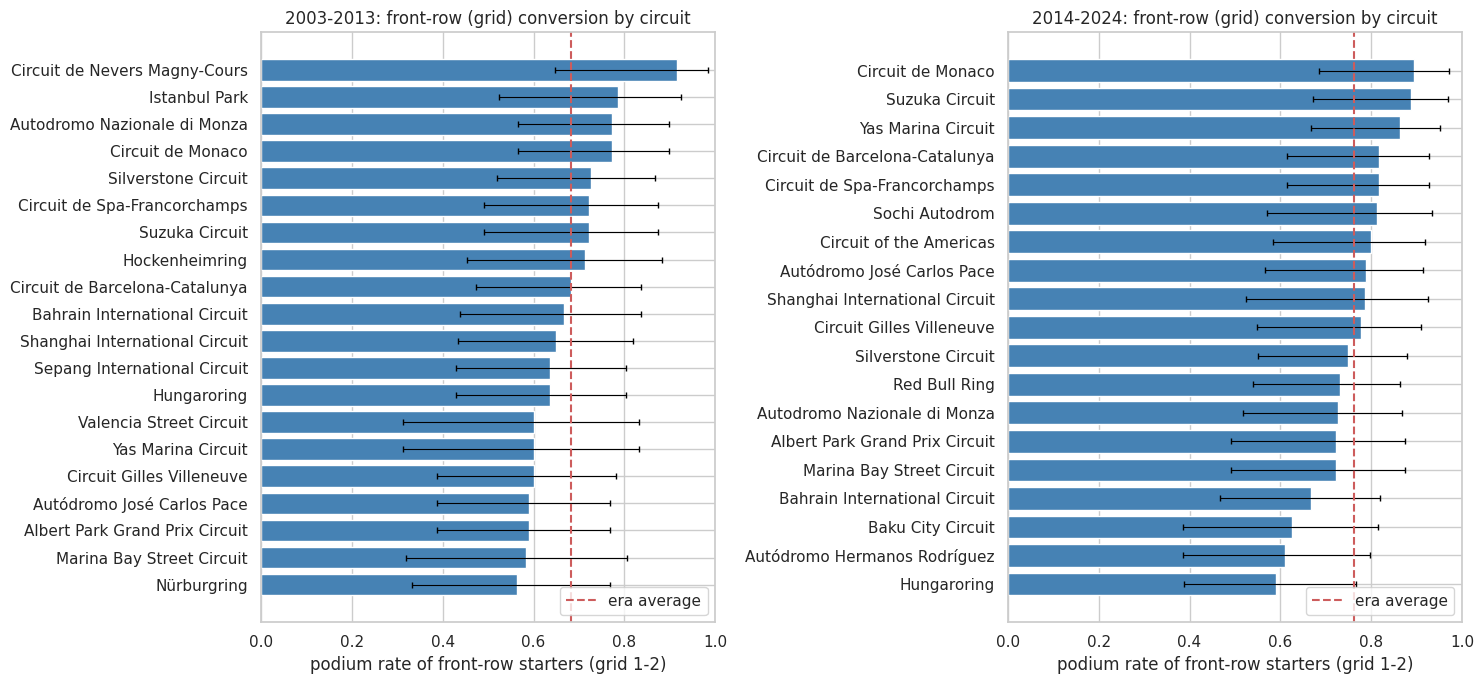

Top 5 circuits 2003-2013:
                 circuit_name  races  front_row_starts  podiums  conversion  ci_low  ci_high
Circuit de Nevers Magny-Cours      6                12       11        0.92    0.65     0.99
                Istanbul Park      7                14       11        0.79    0.52     0.92
 Autodromo Nazionale di Monza     11                22       17        0.77    0.57     0.90
            Circuit de Monaco     11                22       17        0.77    0.57     0.90
          Silverstone Circuit     11                22       16        0.73    0.52     0.87 

Top 5 circuits 2014-2024:
                  circuit_name  races  front_row_starts  podiums  conversion  ci_low  ci_high
             Circuit de Monaco     10                19       17        0.89    0.69     0.97
                Suzuka Circuit      9                18       16        0.89    0.67     0.97
            Yas Marina Circuit     11                22       19        0.86    0.67     0.95
Circuit de B

In [60]:
q1w = q1[q1['year'] >= 2003].copy()
q1w['era'] = np.where(q1w['year'] >= 2014, '2014-2024', '2003-2013')
ERAS = ['2003-2013', '2014-2024']
MIN_RACES = 5

def conversion_table(df, flag):
    fr = df[df[flag]]
    out = fr.groupby(['era', 'circuit_name']).agg(races=('raceId', 'nunique'),
                                                  front_row_starts=('podium', 'size'),
                                                  podiums=('podium', 'sum')).reset_index()
    out['conversion'] = out['podiums'] / out['front_row_starts']
    out['ci_low'], out['ci_high'] = proportion_confint(out['podiums'], out['front_row_starts'], method='wilson')
    return out

conv_grid = conversion_table(q1w, 'front_row_grid')

# Overall front-row conversion per era: the reference line for each circuit
overall_grid = q1w[q1w['front_row_grid']].groupby('era')['podium'].agg(['size', 'mean'])
print('Overall front-row (grid) conversion per era:')
print(overall_grid.rename(columns={'size': 'front-row starts', 'mean': 'conversion'}).round(3), '\n')

kept = conv_grid[conv_grid['races'] >= MIN_RACES]
print('Circuits per era: all vs ranked (>= 5 races):')
print(pd.DataFrame({'all': conv_grid.groupby('era').size(), 'ranked': kept.groupby('era').size()}), '\n')

# Plot: conversion per circuit with 95% CI, one panel per era
fig, axes = plt.subplots(1, 2, figsize=(15, 7))
for ax, era_name in zip(axes, ERAS):
    d = kept[kept['era'] == era_name].sort_values('conversion')
    ax.barh(d['circuit_name'], d['conversion'], color='steelblue')
    ax.errorbar(d['conversion'], d['circuit_name'],
                xerr=[d['conversion'] - d['ci_low'], d['ci_high'] - d['conversion']],
                fmt='none', ecolor='black', capsize=2, linewidth=0.8)
    ax.axvline(overall_grid.loc[era_name, 'mean'], color='indianred', linestyle='--', label='era average')
    ax.set_xlim(0, 1)
    ax.set_xlabel('podium rate of front-row starters (grid 1-2)')
    ax.set_title(f'{era_name}: front-row (grid) conversion by circuit')
    ax.legend(loc='lower right')
plt.tight_layout()
plt.show()

for era_name in ERAS:
    print(f'Top 5 circuits {era_name}:')
    print(kept[kept['era'] == era_name].sort_values(['conversion', 'front_row_starts'], ascending=False)
          .head(5)[['circuit_name', 'races', 'front_row_starts', 'podiums', 'conversion', 'ci_low', 'ci_high']]
          .round(2).to_string(index=False), '\n')

**Reading the results (front row by grid):**
- **Check:** 398 front-row starts in 2003–2013 = 200 races × 2 − 2 (the 2005 US GP front row withdrew). 453 in 2014–2024 = 228 races × 2 − 3 non-starters (2017 Malaysia, 2021 Monaco, 2023 São Paulo). No race is missing or double-counted.
- **The front row became more decisive after 2014:** 68 % → 76 % overall. This is mostly an era effect, not a circuit effect: long periods of one dominant team (Mercedes 2014–2020, Red Bull 2022–2023) meant that a front-row car rarely dropped off the podium.
- **Top circuits 2003–2013:** Magny-Cours (92 %), Istanbul (79 %), Monza and Monaco (77 %), Silverstone (73 %). The top two rest on only 6–7 races and disappear from the calendar after 2008/2011.
- **Top circuits 2014–2024:** Monaco (89.5 %, 17 of 19), Suzuka (88.9 %), Yas Marina (86 %), Barcelona and Spa (82 %). **Monaco is the only circuit in the top 5 of both eras** (joint 3rd, then 1st), consistent with it being the hardest track to overtake on.
- **Caution:** with 10–22 front-row starts per circuit, the 95 % intervals are wide and almost all of them overlap the era average. The ranking is a **description of what happened**, not proof that a circuit causes higher conversion; the car a team brings matters more than the track.

### Q1.3 Qualifying position vs grid: does the definition change the answer?
A driver can **qualify** on the front row but **start** further back (grid penalty), or start on the front row after qualifying 3rd or lower (promoted past a penalised driver). We count how often this happens, how those drivers convert, and whether the circuit ranking changes when "front row" is defined by qualifying.

Overall front-row (qualifying) conversion per era:
           front-row qualifiers  conversion
era                                        
2003-2013                   398       0.676
2014-2024                   453       0.742 

Front-row rows (count) and podium rate (mean) by definition:
                                              count                mean          
era                                       2003-2013 2014-2024 2003-2013 2014-2024
front_row_type                                                                   
both                                            389       426      0.69      0.77
qualified front row, started further back         9        27      0.22      0.33
started front row, qualified 3rd or lower         9        27      0.56      0.67 

Front-row qualifiers who started further back:
 year                      name    surname  quali_position  grid_clean  pit_lane_start  podium
 2004         Monaco Grand Prix Schumacher             2.0        12.0    

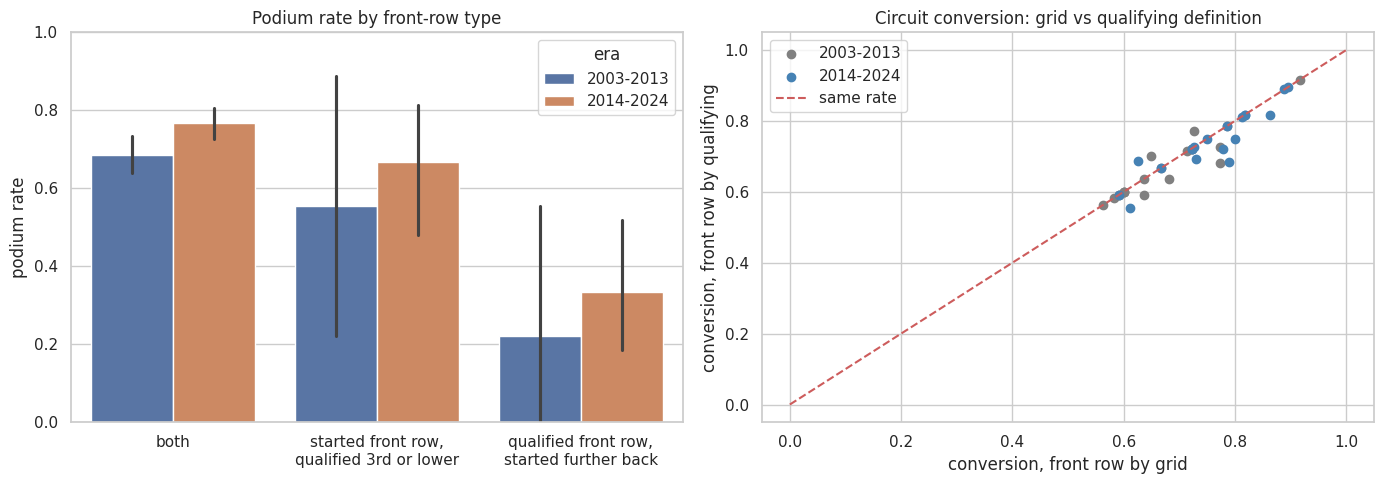

In [61]:
conv_quali = conversion_table(q1w, 'front_row_quali')

overall_quali = q1w[q1w['front_row_quali']].groupby('era')['podium'].agg(['size', 'mean'])
print('Overall front-row (qualifying) conversion per era:')
print(overall_quali.rename(columns={'size': 'front-row qualifiers', 'mean': 'conversion'}).round(3), '\n')

# 1) Where do the two definitions disagree?
both = q1w['front_row_grid'] & q1w['front_row_quali']
moved_back = q1w['front_row_quali'] & ~q1w['front_row_grid']
promoted = q1w['front_row_grid'] & ~q1w['front_row_quali']

q1w['front_row_type'] = 'neither'
q1w.loc[both, 'front_row_type'] = 'both'
q1w.loc[moved_back, 'front_row_type'] = 'qualified front row, started further back'
q1w.loc[promoted, 'front_row_type'] = 'started front row, qualified 3rd or lower'

front_rows = q1w[q1w['front_row_type'] != 'neither']
disagree = pd.pivot_table(front_rows, index='front_row_type', columns='era', values='podium', aggfunc=['count', 'mean'])
print('Front-row rows (count) and podium rate (mean) by definition:')
print(disagree.round(2), '\n')

# The individual cases where a front-row qualifier started further back
moved_back_cases = (q1w[moved_back]
                    .merge(clean['drivers'][['driverId', 'surname']], on='driverId', how='left', validate='many_to_one')
                    .merge(clean['races'][['raceId', 'name']], on='raceId', how='left', validate='many_to_one'))
print('Front-row qualifiers who started further back:')
print(moved_back_cases[['year', 'name', 'surname', 'quali_position', 'grid_clean', 'pit_lane_start', 'podium']]
      .sort_values('year').to_string(index=False), '\n')

# 2) Does the circuit rate change with the definition?
compare = (conv_grid[['era', 'circuit_name', 'races', 'conversion']]
           .merge(conv_quali[['era', 'circuit_name', 'conversion']], on=['era', 'circuit_name'],
                  suffixes=('_grid', '_quali'), validate='one_to_one'))
compare = compare[compare['races'] >= MIN_RACES]
compare['difference'] = compare['conversion_quali'] - compare['conversion_grid']
print('Ranked circuit-eras where the two definitions give a different rate:',
      int((compare['difference'].abs() > 1e-9).sum()), 'of', len(compare))
print(compare[compare['difference'].abs() > 1e-9].sort_values('difference')
      [['era', 'circuit_name', 'races', 'conversion_grid', 'conversion_quali', 'difference']].round(2).to_string(index=False))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
type_order = ['both', 'started front row, qualified 3rd or lower', 'qualified front row, started further back']
sns.barplot(data=front_rows, x='front_row_type', y='podium', hue='era', order=type_order, ax=axes[0])
axes[0].set_xticks(range(3))
axes[0].set_xticklabels(['both', 'started front row,\nqualified 3rd or lower', 'qualified front row,\nstarted further back'])
axes[0].set_ylim(0, 1)
axes[0].set_xlabel('')
axes[0].set_ylabel('podium rate')
axes[0].set_title('Podium rate by front-row type')

for era_name, colour in zip(ERAS, ['grey', 'steelblue']):
    d = compare[compare['era'] == era_name]
    axes[1].scatter(d['conversion_grid'], d['conversion_quali'], label=era_name, color=colour)
axes[1].plot([0, 1], [0, 1], color='indianred', linestyle='--', label='same rate')
axes[1].set_xlabel('conversion, front row by grid')
axes[1].set_ylabel('conversion, front row by qualifying')
axes[1].set_title('Circuit conversion: grid vs qualifying definition')
axes[1].legend()
plt.tight_layout()
plt.show()

**Reading the results (qualifying vs grid):**
- **Check:** 389 + 9 = 398 and 426 + 27 = 453 under both definitions. Every driver dropped from the front row is matched by one driver promoted onto it.
- **Penalties became much more frequent after 2014:** front-row qualifiers who started further back rose from 9 (2.3 %) to 27 (6.0 %), consistent with the power-unit component limits of the hybrid era.
- **Grid is more informative than qualifying.** Front-row qualifiers who started further back converted only **22 % / 33 %**, versus **69 % / 77 %** for drivers who qualified *and* started on the front row. Promoted drivers converted 56 % / 67 %. Where the car actually starts matters more than where it qualified, which supports `grid_clean` as the main starting-position feature. (The error bars in the bar chart are wide for the two small groups, n = 9 and n = 27, so their exact rates are uncertain, but the gap to the "both" group is large in both eras.)
- **Not every difference is a penalty.** In 2021–2022 the **sprint result set the Sunday grid** (e.g. Magnussen took Friday pole at São Paulo 2022 but started 8th; Hamilton qualified 2nd at Monza 2021 and started 4th). Qualifying position is therefore not the starting position on those weekends, even without a penalty.
- **At circuit level the definition barely matters:** 26 of 39 circuit-eras have identical rates, the largest difference is −0.11 (Interlagos 2014–2024: sprint weekends 2021–2024 plus several penalties), and all points lie close to the diagonal. The ranking answer does not depend on the definition, but the *driver-level* effect of a penalty is large.

### Q1.4 Does the ranking change after 2014?
We compare the two eras directly on the circuits ranked in **both** (≥ 5 races in each). **Spearman's rank correlation (ρ)**, computed with `.corr(method='spearman')`, measures how similar the two rankings are: ρ ≈ 1 means the same order, ρ ≈ 0 means the order was reshuffled. We compute it for both definitions of "front row", and show the rates and ranks side by side as heatmaps.

Circuits ranked in both eras: 14
Spearman correlation between the eras, front row by grid:
era        2003-2013  2014-2024
era                            
2003-2013       1.00       0.36
2014-2024       0.36       1.00 

Spearman correlation between the eras, front row by qualifying:
era        2003-2013  2014-2024
era                            
2003-2013       1.00       0.54
2014-2024       0.54       1.00 

p-values: grid 0.21, qualifying 0.05

era                             2003-2013  2014-2024  rank 2003-2013  rank 2014-2024  places gained
circuit_name                                                                                       
Yas Marina Circuit                   0.60       0.86              10               3              7
Autódromo José Carlos Pace           0.59       0.79              12               6              6
Marina Bay Street Circuit            0.58       0.72              14              11              3
Suzuka Circuit                       0.72      

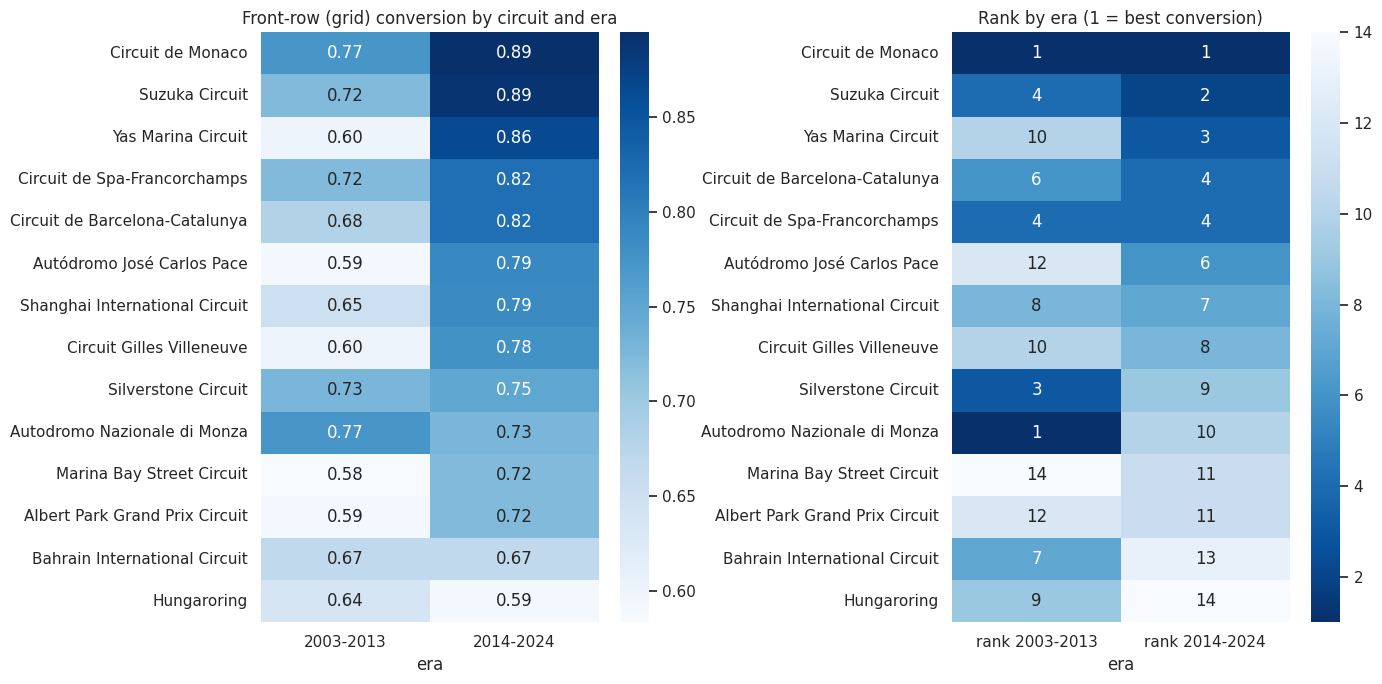

In [62]:
def era_comparison(conv):
    ranked = conv[conv['races'] >= MIN_RACES]
    return ranked.pivot(index='circuit_name', columns='era', values='conversion').dropna()   # ranked in BOTH eras

wide_g = era_comparison(conv_grid)
wide_q = era_comparison(conv_quali)
print('Circuits ranked in both eras:', len(wide_g))
print('Spearman correlation between the eras, front row by grid:')
print(wide_g.corr(method='spearman').round(2), '\n')
print('Spearman correlation between the eras, front row by qualifying:')
print(wide_q.corr(method='spearman').round(2), '\n')
print(f"p-values: grid {spearmanr(wide_g[ERAS[0]], wide_g[ERAS[1]]).pvalue:.2f}, "
      f"qualifying {spearmanr(wide_q[ERAS[0]], wide_q[ERAS[1]]).pvalue:.2f}\n")

rank_table = wide_g.copy()
rank_table['rank 2003-2013'] = rank_table[ERAS[0]].rank(ascending=False, method='min').astype(int)
rank_table['rank 2014-2024'] = rank_table[ERAS[1]].rank(ascending=False, method='min').astype(int)
rank_table['places gained'] = rank_table['rank 2003-2013'] - rank_table['rank 2014-2024']
print(rank_table.sort_values('places gained', ascending=False).round(2).to_string())

fig, axes = plt.subplots(1, 2, figsize=(14, 7))
sns.heatmap(wide_g.sort_values(ERAS[1], ascending=False), annot=True, fmt='.2f', cmap='Blues', ax=axes[0])
axes[0].set_title('Front-row (grid) conversion by circuit and era')
axes[0].set_ylabel('')
sns.heatmap(rank_table[['rank 2003-2013', 'rank 2014-2024']].sort_values('rank 2014-2024'),
            annot=True, fmt='d', cmap='Blues_r', ax=axes[1])
axes[1].set_title('Rank by era (1 = best conversion)')
axes[1].set_ylabel('')
plt.tight_layout()
plt.show()

**Reading the results (ranking change):**
- **14 circuits** are ranked in both eras (≥ 5 races in each).
- **Front row by grid:** Spearman ρ = 0.36 (p = 0.21). The 2003–2013 ranking does **not** significantly predict the 2014–2024 ranking: the order was substantially reshuffled.
  - Biggest risers: **Yas Marina** (10th → 3rd, 0.60 → 0.86), **Interlagos** (12th → 6th).
  - Biggest fallers: **Monza** (1st → 10th, 0.77 → 0.73), **Silverstone** and **Bahrain** (−6 each), **Hungaroring** (9th → 14th, the only notable drop in rate besides Monza).
  - **Stable at the top:** Monaco is 1st in both eras (0.77 → 0.89); Suzuka (4th → 2nd) and Spa (4th in both) stay in the top 5.
- **Most changes are relative:** 11 of 14 circuits converted *more often* after 2014 (almost every row of the left heatmap is darker on the right), in line with the era-wide rise (68 % → 76 %). A circuit can lose several places while its own rate barely changes: Silverstone's rate rose (0.73 → 0.75) yet it fell from 3rd to 9th.
- **Ties:** ranks use `method='min'`, so circuits with the same rate share the better rank (e.g. Monaco and Monza are both 1st in 2003–2013 at 0.77).
- **Front row by qualifying:** ρ = 0.54 (p = 0.05), a moderate correlation at the edge of significance. The two ρ values should not be over-read: with 14 circuits packed between 0.58 and 0.89, a few penalties (≈ 0.05 change in a rate) reshuffle several ranks. Circuit rankings are therefore **fragile**, consistent with the wide confidence intervals in Q1.2.

### Q1 Answer

**Which circuits convert a front-row start into a podium most often?**
- **2003–2013:** Magny-Cours (92 %), Istanbul (79 %), Monza and Monaco (77 %), Silverstone (73 %). Era average 68 %.
- **2014–2024:** Monaco (89.5 %), Suzuka (88.9 %), Yas Marina (86 %), Barcelona and Spa (82 %). Era average 76 %.

**Does the ranking change after 2014?** Yes, substantially. Spearman ρ between the eras is only 0.36 (grid definition, 14 circuits, not significant). Monza fell from 1st to 10th and Yas Marina rose from 10th to 3rd. **Monaco** is the one circuit at the top in both eras (joint 1st among the 14 shared circuits in 2003–2013, 1st in 2014–2024). At the same time, front-row conversion rose almost everywhere (68 % → 76 %), driven by long periods of one dominant team rather than by individual circuits.

**Qualifying vs grid:** the two differ for 2–6 % of front-row drivers, because of grid penalties (more frequent after 2014: 9 → 27 cases) and, in 2021–2022, because the sprint result set the Sunday grid. Front-row qualifiers who started further back converted only 22–33 %, versus 69–77 % for those who also started on the front row. At circuit level the definition changes little (26 of 39 circuit-era rates identical, largest difference 0.11).

**Grain:** one row per (raceId, driverId) from the cleaned modelling scope. Verified: 2 front-row starters per race, except where a front-row car did not take the start: the 2005 US GP (Michelin withdrawal), 2017 Malaysia, 2021 Monaco and 2023 São Paulo (398 = 200 × 2 − 2 and 453 = 228 × 2 − 3). A car that failed on the way to the grid is not a front-row *start*, whether the data gives it grid 0 or keeps its slot with 0 laps.

**Missingness:** qualifying data is complete only from 2003 (6–59 % of races in 1996–2002), so both definitions are compared on 2003–2024. Three pre-2003 races have impossible grid values (duplicate slots), outside the window. Circuits with fewer than 5 races in an era are not ranked (27 → 20 and 32 → 19 circuits).

**Pre-race cutoff:** grid and qualifying position are known before the race. The podium is the outcome being measured, which is fine for a descriptive analysis. If a circuit-level conversion rate is ever used as a **model feature**, it must be computed from earlier seasons only.

**Limitations:** 10–22 front-row starts per circuit and era give wide 95 % intervals that almost all overlap the era average. The rankings **describe** what happened; they do not show that a circuit **causes** higher conversion. The car a team brings is the dominant factor.

## Q2. Do drivers podium more often at a circuit in their home country, after controlling for starting position?

**Tables needed (multi-hop join):** `results` (grid, finishing order) → `drivers` (nationality) and `results` → `races` → `circuits` (country of the circuit). "Home" means the circuit is located in the driver's own country.

**Why we must control for starting position:** grid position is the strongest driver of a podium (Q1, EDA 4.4). If home drivers also start further forward at home, a raw home-vs-away comparison would mix the two effects. We therefore compare home and away drivers **who started from similar grid positions**.

**Scope:** the cleaned modelling table (one row per driver per race, starters only). The Indianapolis 500 is already excluded (3.7); it would inflate American "home" races with drivers who rarely raced anywhere else.

### Q2.1 Building the Q2 table and inspecting the labels
Driver nationality is stored as a demonym (`British`) and circuit location as a country (`UK`), so they cannot be compared directly. Before writing a mapping we list every value that appears.

In [63]:
# Multi-hop join: results -> drivers (nationality), results -> races -> circuits (country)
q2 = (model_table[['raceId', 'driverId', 'grid_clean', 'pit_lane_start', 'podium']]
      .merge(clean['races'][['raceId', 'year', 'circuitId']],
             on='raceId', how='left', validate='many_to_one')
      .merge(clean['circuits'][['circuitId', 'name', 'country']]
             .rename(columns={'name': 'circuit_name', 'country': 'circuit_country'}),
             on='circuitId', how='left', validate='many_to_one')
      .merge(clean['drivers'][['driverId', 'surname', 'nationality']]
             .rename(columns={'nationality': 'driver_nationality'}),
             on='driverId', how='left', validate='many_to_one'))
assert len(q2) == len(model_table), 'a join changed the number of rows!'

print('Rows:', len(q2))
print('Missing driver nationality:', q2['driver_nationality'].isna().sum())
print('Missing circuit country   :', q2['circuit_country'].isna().sum(), '\n')

print('Circuit countries (', q2['circuit_country'].nunique(), '):')
print(sorted(q2['circuit_country'].unique()), '\n')

print('Driver nationalities (', q2['driver_nationality'].nunique(), ') with number of rows:')
print(q2['driver_nationality'].value_counts().to_string())

Rows: 24687
Missing driver nationality: 0
Missing circuit country   : 0 

Circuit countries ( 34 ):
['Argentina', 'Australia', 'Austria', 'Azerbaijan', 'Bahrain', 'Belgium', 'Brazil', 'Canada', 'China', 'France', 'Germany', 'Hungary', 'India', 'Italy', 'Japan', 'Korea', 'Malaysia', 'Mexico', 'Monaco', 'Morocco', 'Netherlands', 'Portugal', 'Qatar', 'Russia', 'Saudi Arabia', 'Singapore', 'South Africa', 'Spain', 'Sweden', 'Switzerland', 'Turkey', 'UAE', 'UK', 'USA'] 

Driver nationalities ( 42 ) with number of rows:
driver_nationality
British              4297
Italian              3011
French               2928
German               2321
Brazilian            1857
Finnish              1159
Spanish               884
Australian            870
American              837
Austrian              667
Japanese              645
Belgian               499
Dutch                 498
Canadian              491
Swedish               471
Mexican               449
Swiss                 440
New Zealander      

**What the labels show:** no missing values, 34 circuit countries and 42 nationalities. Three cases need a decision:
1. **25 nationalities map directly** to a circuit country (`British` → `UK`, `American` → `USA`, `Dutch` → `Netherlands`, `Monegasque` → `Monaco`, …).
2. **Dual nationalities** (`Argentine-Italian`, `American-Italian`, 3 rows): **both** countries count as home.
3. **15 nationalities have no circuit in their country** (e.g. Finnish, New Zealander, Danish, Irish): these drivers can never race at home. `East German` gets no home circuit (Germany's circuits were in West Germany at the time) and `Rhodesian` none either (Rhodesia, today Zimbabwe, never hosted a race; South Africa is a different country).

### Q2.2 Mapping nationality to country and flagging home races
The mapping is written out explicitly so every decision is visible. Two `assert`s guarantee that **every** nationality is mapped (no silent gaps) and that every mapped country really exists in `circuits` (no typos).

In [64]:
HOME_COUNTRIES = {
    'British': ['UK'], 'Italian': ['Italy'], 'French': ['France'], 'German': ['Germany'],
    'Brazilian': ['Brazil'], 'Spanish': ['Spain'], 'Australian': ['Australia'], 'American': ['USA'],
    'Austrian': ['Austria'], 'Japanese': ['Japan'], 'Belgian': ['Belgium'], 'Dutch': ['Netherlands'],
    'Canadian': ['Canada'], 'Swedish': ['Sweden'], 'Mexican': ['Mexico'], 'Swiss': ['Switzerland'],
    'Argentine': ['Argentina'], 'Russian': ['Russia'], 'South African': ['South Africa'],
    'Monegasque': ['Monaco'], 'Portuguese': ['Portugal'], 'Chinese': ['China'], 'Indian': ['India'],
    'Hungarian': ['Hungary'], 'Malaysian': ['Malaysia'],
    # dual nationality: both countries count as home
    'Argentine-Italian': ['Argentina', 'Italy'], 'American-Italian': ['USA', 'Italy'],
    # no circuit in their country in this dataset: these drivers can never race at home
    'Finnish': [], 'New Zealander': [], 'Danish': [], 'Thai': [], 'Colombian': [], 'Venezuelan': [],
    'Polish': [], 'Irish': [], 'Chilean': [], 'Rhodesian': [], 'Indonesian': [], 'Liechtensteiner': [],
    'Uruguayan': [], 'Czech': [], 'East German': [],
}

# Check 1: every nationality in the data has an entry (no silent gaps)
unmapped = set(q2['driver_nationality']) - set(HOME_COUNTRIES)
assert not unmapped, f'unmapped nationalities: {unmapped}'
# Check 2: every mapped country really exists in circuits (no typos)
mapped_countries = {c for countries in HOME_COUNTRIES.values() for c in countries}
assert mapped_countries <= set(q2['circuit_country']), f'typo: {mapped_countries - set(q2["circuit_country"])}'

q2['is_home'] = [country in HOME_COUNTRIES[nat]
                 for nat, country in zip(q2['driver_nationality'], q2['circuit_country'])]

# Drivers who had at least one home race: the same drivers appear in both the home and the away group
home_starts_per_driver = q2.groupby('driverId')['is_home'].sum()
q2['has_home_race'] = q2['driverId'].map(home_starts_per_driver > 0)

print('Home rows:', int(q2['is_home'].sum()), f"({q2['is_home'].mean():.1%} of all rows)")
print('Drivers in total            :', q2['driverId'].nunique())
print('Drivers with >= 1 home race :', int((home_starts_per_driver > 0).sum()))
print('Rows of those drivers       :', int(q2['has_home_race'].sum()), '\n')

print('Circuit countries where no driver is ever at home:', sorted(set(q2['circuit_country']) - mapped_countries), '\n')

print('Home starts by nationality:')
print(q2[q2['is_home']]['driver_nationality'].value_counts().to_string(), '\n')

print('Home starts by circuit country:')
print(q2[q2['is_home']]['circuit_country'].value_counts().to_string())

Home rows: 1930 (7.8% of all rows)
Drivers in total            : 684
Drivers with >= 1 home race : 499
Rows of those drivers       : 20523 

Circuit countries where no driver is ever at home: ['Azerbaijan', 'Bahrain', 'Korea', 'Morocco', 'Qatar', 'Saudi Arabia', 'Singapore', 'Turkey', 'UAE'] 

Home starts by nationality:
driver_nationality
British              447
Italian              400
French               206
German               198
Brazilian            114
American             112
Spanish               61
Belgian               60
Japanese              53
South African         46
Argentine             43
Canadian              32
Austrian              29
Australian            28
Mexican               24
Dutch                 22
Swiss                 13
Swedish               12
Monegasque             9
Russian                8
Portuguese             5
Hungarian              2
Indian                 2
Malaysian              1
American-Italian       1
Argentine-Italian      1
Chinese 

**Checks passed:** every nationality is mapped and every mapped country exists. Both breakdowns sum to **1,930 home starts (7.8 % of rows)**; Italy (401) and Argentina (44) are one higher than their nationalities because of the two dual-nationality drivers. **499 of 684 drivers** started at least one home race, covering 83 % of all rows. Home starts are concentrated: British, Italian, French and German drivers account for 65 % of them.

**Which comparison is fair?** Drivers who can never race at home (e.g. the Finnish drivers, 1,159 rows) would only add to the "away" group. Home and away would then contain *different drivers*. The fair comparison uses only drivers with at least one home race, so the **same drivers** are compared at home and away. Both versions are shown.

### Q2.3 The naive comparison: home vs away, without controlling for grid
We also check whether home drivers **start further forward** at home. If they do, the naive comparison mixes the home effect with a grid effect.

Podium rate, ALL drivers:
        rows  podiums  podium rate
venue                             
away   22757     3117        0.137
home    1930      225        0.117 

Podium rate, SAME drivers (only drivers with >= 1 home race):
        rows  podiums  podium rate
venue                             
away   18593     2665        0.143
home    1930      225        0.117 

Starting position, SAME drivers:
        mean  25%   50%   75%
venue                        
away   11.49  6.0  11.0  17.0
home   12.66  7.0  13.0  18.0


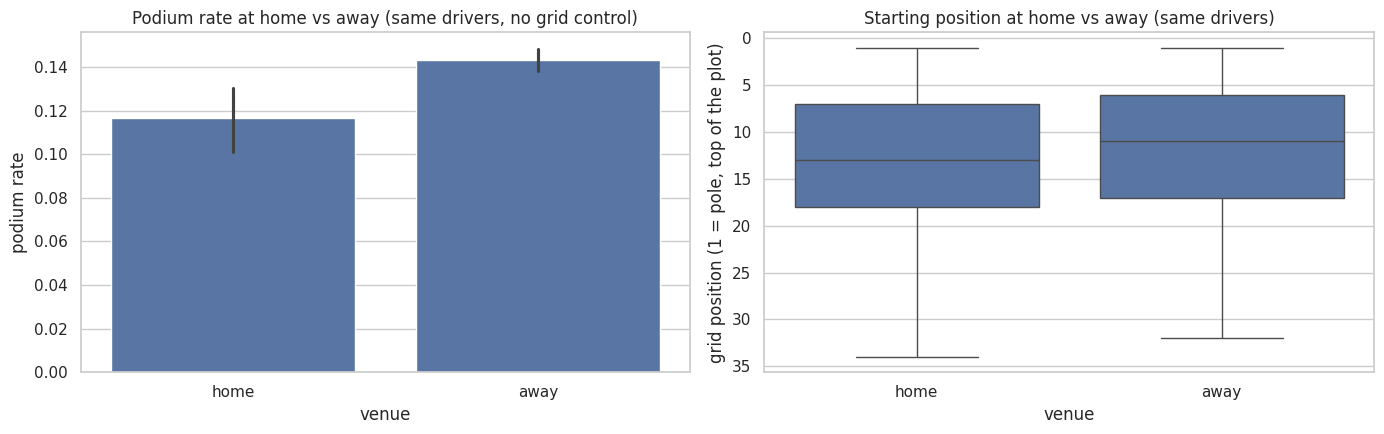

In [65]:
q2['venue'] = np.where(q2['is_home'], 'home', 'away')
same_drivers = q2[q2['has_home_race']]

print('Podium rate, ALL drivers:')
print(q2.groupby('venue')['podium'].agg(['size', 'sum', 'mean'])
      .rename(columns={'size': 'rows', 'sum': 'podiums', 'mean': 'podium rate'}).round(3), '\n')

print('Podium rate, SAME drivers (only drivers with >= 1 home race):')
print(same_drivers.groupby('venue')['podium'].agg(['size', 'sum', 'mean'])
      .rename(columns={'size': 'rows', 'sum': 'podiums', 'mean': 'podium rate'}).round(3), '\n')

print('Starting position, SAME drivers:')
print(same_drivers.groupby('venue')['grid_clean'].describe()[['mean', '25%', '50%', '75%']].round(2))

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
sns.barplot(data=same_drivers, x='venue', y='podium', order=['home', 'away'], ax=axes[0])
axes[0].set_ylabel('podium rate')
axes[0].set_title('Podium rate at home vs away (same drivers, no grid control)')

sns.boxplot(data=same_drivers, x='venue', y='grid_clean', order=['home', 'away'], ax=axes[1])
axes[1].invert_yaxis()
axes[1].set_ylabel('grid position (1 = pole, top of the plot)')
axes[1].set_title('Starting position at home vs away (same drivers)')
plt.tight_layout()
plt.show()

**Reading the results (naive comparison):**
- **Check:** 3,117 + 225 = 3,342 podiums = 1,114 races × 3. Every podium is accounted for.
- **Surprise: drivers podium *less* often at home.** Same drivers: **11.7 % at home vs 14.3 % away** (all drivers: 11.7 % vs 13.7 %). The 95 % error bars do not overlap.
- **Home drivers also start *further back* at home:** mean grid 12.66 vs 11.49, median 13 vs 11. So the naive gap is not hidden by home drivers starting further forward; if anything, part of it may be *explained* by them starting further back.

**Hypothesis:** the home group contains many **one-off local entries**. In the 1950s–1980s local drivers often entered only their home Grand Prix, in slower cars, from the back of the grid (F1 guide: "one-off local drivers appeared at their home race"). They add home rows but few away rows, which drags the home podium rate down. The "same drivers" filter does not remove them: a driver with 1 home and 0 away races still had a home race. We test this hypothesis before controlling for grid.

### Q2.4 Testing the hypothesis: who are the home starters?

Drivers with >= 1 home race          : 499
... whose only starts were at home   : 107
... with fewer than 5 away starts    : 188 

Examples: drivers who ONLY ever started at home:
                      surname nationality  first_year  home_starts  podiums
driverId                                                                   
802                  Serafini     Italian        1950            1        1
778              Shawe Taylor     British        1950            2        0
801                     Pozzi      French        1950            1        0
790                   Johnson     British        1950            1        0
791                 Biondetti     Italian        1950            1        0
777       Fotheringham-Parker     British        1951            1        0
775                   Gordini      French        1951            1        0
779                     James     British        1951            1        0
782                     Jover     Spanish        1951       

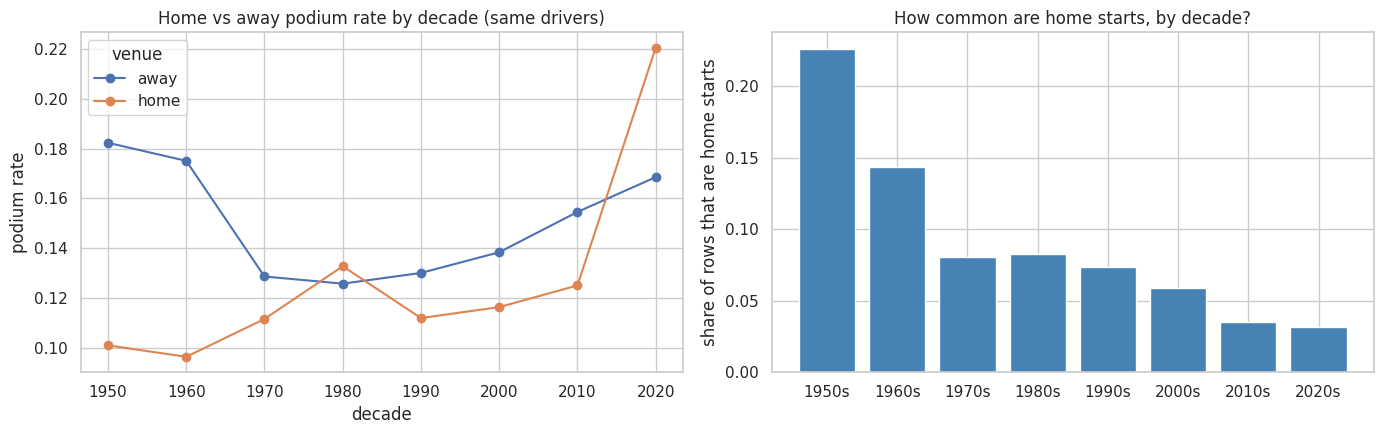

In [66]:
per_driver = q2.groupby('driverId').agg(surname=('surname', 'first'), nationality=('driver_nationality', 'first'),
                                        first_year=('year', 'min'), starts=('raceId', 'size'),
                                        home_starts=('is_home', 'sum'), podiums=('podium', 'sum'))
per_driver['away_starts'] = per_driver['starts'] - per_driver['home_starts']
home_drivers = per_driver[per_driver['home_starts'] > 0]

print('Drivers with >= 1 home race          :', len(home_drivers))
print('... whose only starts were at home   :', int((home_drivers['away_starts'] == 0).sum()))
print('... with fewer than 5 away starts    :', int((home_drivers['away_starts'] < 5).sum()), '\n')

print('Examples: drivers who ONLY ever started at home:')
print(home_drivers[home_drivers['away_starts'] == 0].sort_values('first_year')
      [['surname', 'nationality', 'first_year', 'home_starts', 'podiums']].head(12).to_string(), '\n')

# Does the home-vs-away gap survive if we only keep drivers with a real away record?
q2['away_starts_of_driver'] = q2['driverId'].map(per_driver['away_starts'])
rows = []
for min_away in [0, 5, 10, 20, 50]:
    d = q2[q2['has_home_race'] & (q2['away_starts_of_driver'] >= min_away)]
    rate = d.groupby('venue')['podium'].mean()
    grid = d.groupby('venue')['grid_clean'].mean()
    rows.append({'min away starts': min_away, 'drivers': d['driverId'].nunique(),
                 'home rows': int(d['is_home'].sum()),
                 'podium rate home': rate['home'], 'podium rate away': rate['away'],
                 'mean grid home': grid['home'], 'mean grid away': grid['away']})
threshold_table = pd.DataFrame(rows)
print('Home vs away for drivers with at least N away starts:')
print(threshold_table.round(3).to_string(index=False), '\n')

# Is it an era effect? Home vs away podium rate per decade (same drivers)
q2['decade'] = q2['year'] // 10 * 10
by_decade = pd.pivot_table(q2[q2['has_home_race']], index='decade', columns='venue', values='podium', aggfunc='mean')
home_share = q2.groupby('decade')['is_home'].mean()

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
by_decade.plot(ax=axes[0], marker='o')
axes[0].set_ylabel('podium rate')
axes[0].set_title('Home vs away podium rate by decade (same drivers)')
axes[1].bar(home_share.index.astype(str) + 's', home_share.values, color='steelblue')
axes[1].set_ylabel('share of rows that are home starts')
axes[1].set_title('How common are home starts, by decade?')
plt.tight_layout()
plt.show()

**Reading the results (who are the home starters?):**
- **Many home starters are one-off local entries:** of the 499 drivers with a home race, **107 only ever started at home** and **188 had fewer than 5 away starts**. The examples are almost all 1950–1952 local drivers with one home start and no podium. (Serafini's podium is the 1950 Italian GP, where he started the car Ascari took over; our shared-drive rule 3.5 keeps the starter.)
- **The home "disadvantage" disappears for regular drivers.** Requiring at least N away starts per driver:
  - N = 0: home 0.117 vs away 0.143,
  - N = 20: **0.152 vs 0.152**,
  - N = 50: 0.169 vs 0.167.

  The mean grid converges the same way (12.66 vs 11.50 → 11.07 vs 11.07). The naive gap was a **composition effect**: the home group contained many weaker one-off entries, not drivers performing worse at home.
- **It is mainly an early-era issue:** home starts were **22 % of all rows in the 1950s**, falling to ≈ 3 % in the 2010s–2020s. Home is below away in most decades; the 2020s home point (0.22) rests on very few home starts (≈ 3 % of rows) and is noisy.

**Consequence for the analysis:** besides starting position, the *type of driver* is a second confounder. We control for grid on two populations: **all same drivers** (the question as asked) and **regular drivers with ≥ 20 away starts** (the threshold where the raw gap closes, still 198 drivers and 1,391 home starts).

### Q2.5 Controlling for starting position
**Method 1: compare within grid groups.** Grid positions are grouped (P1, P2, P3, P4–6, P7–10, P11–15, P16+) and home vs away podium rates are compared **inside each group**, so a home driver from P5 is only compared with away drivers from P4–6.

**Method 2: observed vs expected podiums.** For every home start we look up the away podium rate of its grid group: "how often does a driver starting here podium when *not* at home?". Summing these gives the number of podiums home drivers would be **expected** to score if home made no difference. Observed ÷ expected > 1 means a home advantage, < 1 a home disadvantage.

**Method 3: logistic regression** (the model from Lab 2), `podium ~ is_home + grid group`, fitted with statsmodels because it reports a p-value and confidence interval. The result is an **odds ratio**: 1 = no home effect, > 1 = advantage, < 1 = disadvantage. If its 95 % interval contains 1, the data show no evidence of a home effect. Because the same driver appears in many rows (they are not independent observations), the standard errors are **clustered by driver**, which gives honest (slightly wider) confidence intervals. A second model also controls for **decade**, because base podium rates and the share of home starts both changed over time.

--- all same drivers ---
           count        mean       
venue       away home   away   home
grid_group                         
P1           921   82  0.653  0.598
P2           885   78  0.577  0.538
P3           878   71  0.452  0.535
P4-6        2600  226  0.261  0.265
P7-10       3446  334  0.090  0.072
P11-15      4199  413  0.029  0.024
P16+        5664  726  0.008  0.003 

--- regular drivers (>= 20 away starts) ---
           count        mean       
venue       away home   away   home
grid_group                         
P1           918   82  0.655  0.598
P2           875   76  0.579  0.539
P3           862   67  0.450  0.567
P4-6        2542  200  0.264  0.270
P7-10       3326  278  0.091  0.068
P11-15      3926  286  0.029  0.031
P16+        4799  402  0.009  0.005 

population                 all same drivers regular drivers (>= 20 away starts)
home starts                            1930                                1391
observed podiums                        225    

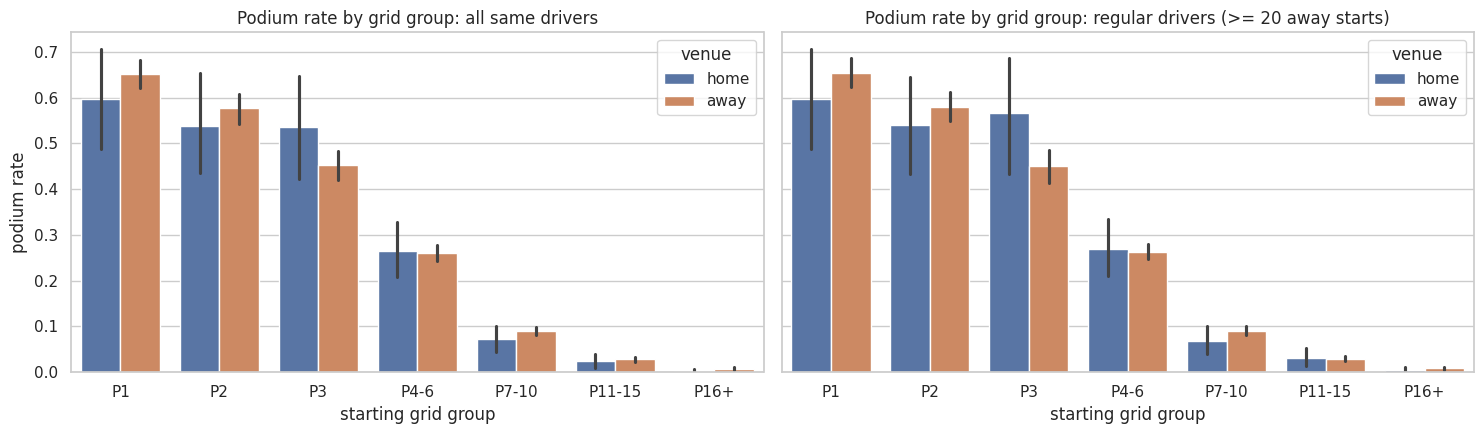

In [67]:
import statsmodels.formula.api as smf

GRID_BINS = [0, 1, 2, 3, 6, 10, 15, 100]
GRID_LABELS = ['P1', 'P2', 'P3', 'P4-6', 'P7-10', 'P11-15', 'P16+']
q2['grid_group'] = pd.cut(q2['grid_clean'], bins=GRID_BINS, labels=GRID_LABELS)
assert q2['grid_group'].notna().all(), 'some grid positions were not assigned to a group'

populations = {
    'all same drivers': q2[q2['has_home_race']],
    'regular drivers (>= 20 away starts)': q2[q2['has_home_race'] & (q2['away_starts_of_driver'] >= 20)],
}

summary = []
for name, d in populations.items():
    # Method 1: podium rate per grid group, home vs away
    strat = pd.pivot_table(d, index='grid_group', columns='venue', values='podium',
                           aggfunc=['count', 'mean'], observed=True)
    print(f'--- {name} ---')
    print(strat.round(3), '\n')

    # Method 2: observed vs expected home podiums
    away_rate = d[~d['is_home']].groupby('grid_group', observed=True)['podium'].mean()
    home = d[d['is_home']]
    expected = home['grid_group'].map(away_rate).astype(float).sum()
    observed = home['podium'].sum()

    # Method 3: logistic regression, without and with decade
    # The same driver appears in many rows, so rows are not independent: cluster the standard errors by driver
    clustered = dict(cov_type='cluster', cov_kwds={'groups': d['driverId']})
    m1 = smf.logit('podium ~ is_home + C(grid_group)', data=d).fit(disp=0, **clustered)
    m2 = smf.logit('podium ~ is_home + C(grid_group) + C(decade)', data=d).fit(disp=0, **clustered)
    ci1 = np.exp(m1.conf_int().loc['is_home[T.True]'])
    ci2 = np.exp(m2.conf_int().loc['is_home[T.True]'])
    summary.append({'population': name, 'home starts': len(home),
                    'observed podiums': int(observed), 'expected podiums': round(expected, 1),
                    'observed / expected': round(observed / expected, 2),
                    'odds ratio (grid)': round(np.exp(m1.params['is_home[T.True]']), 2),
                    '95% CI (grid)': f'{ci1[0]:.2f}-{ci1[1]:.2f}',
                    'p (grid)': round(m1.pvalues['is_home[T.True]'], 3),
                    'odds ratio (grid + decade)': round(np.exp(m2.params['is_home[T.True]']), 2),
                    '95% CI (grid + decade)': f'{ci2[0]:.2f}-{ci2[1]:.2f}',
                    'p (grid + decade)': round(m2.pvalues['is_home[T.True]'], 3)})

summary_q2 = pd.DataFrame(summary).set_index('population').T
print(summary_q2.to_string())

fig, axes = plt.subplots(1, 2, figsize=(15, 4.5), sharey=True)
for ax, (name, d) in zip(axes, populations.items()):
    sns.barplot(data=d, x='grid_group', y='podium', hue='venue', hue_order=['home', 'away'], ax=ax)
    ax.set_xlabel('starting grid group')
    ax.set_ylabel('podium rate')
    ax.set_title(f'Podium rate by grid group: {name}')
plt.tight_layout()
plt.show()

### Q2 Answer

**Do drivers podium more often at a circuit in their home country, after controlling for starting position?** **No.** Comparing drivers who started from the same grid group, home drivers scored about as many podiums as away drivers: observed / expected = **0.95**, logistic-regression odds ratio **0.92** (95 % CI 0.76–1.11, p = 0.38, standard errors clustered by driver). The result is the same for regular drivers only (≥ 20 away starts: odds ratio 0.96, p = 0.67) and when also controlling for decade (p = 0.41 and 0.66). A large home advantage is ruled out; any real effect would be small.

**Why the naive comparison is misleading:** without control, drivers seem to podium *less* at home (11.7 % vs 14.3 %). This is because home starters started further back (mean grid 12.7 vs 11.5), mostly due to **one-off local entries** in the 1950s–1980s: 107 drivers only ever started at home, and home starts were 22 % of all rows in the 1950s versus ≈ 3 % today. Controlling for grid removes the gap, which is exactly why the question asks for it.

**Grain:** one row per (raceId, driverId) from the cleaned modelling scope (starters only, Indy 500 excluded). Home and away are compared within the **same drivers** (499 drivers with at least one home race), so drivers who can never race at home (e.g. Finnish drivers) do not distort the away group.

**Missingness:** nationality and circuit country are complete (0 missing). 15 nationalities have no circuit in their country and 9 circuit countries never host a home driver; both are handled explicitly in the mapping. Home starts: 1,930 (7.8 % of rows).

**Pre-race cutoff:** nationality, circuit country and grid are all known before the race. A home-race flag would therefore be a **leakage-safe feature**, but this analysis shows it carries little information once grid is known.

**Limitations:**
- 65 % of home starts come from British, Italian, French and German drivers, so the answer mainly describes these nationalities.
- Nationality is the dataset's single label; it does not capture drivers who grew up or live elsewhere.
- The front-of-grid home groups are small (71–82 rows), so per-position comparisons are noisy; the pooled methods are more reliable.
- This is an **association**, not a causal estimate: "home" also differs in crowd, travel, and team familiarity, which cannot be separated here.

## Q3. Which constructors have the highest mechanical-retirement rate in 2014–2021 vs 2022–2024?

**Definition (from the brief):** a mechanical retirement is a **race start** that ended early because a **component of the car failed**. Crashes, driver errors and regulation decisions (disqualification, exclusion) do not count.

**Tables needed (multi-hop join):** `results` → `status` (why the race ended), `results` → `races` (year), `results` → `constructors` (team name). `results` only stores a `statusId` number, so without `status` we cannot tell an engine failure from a crash.

**Decisions:**
- **Rate = mechanical retirements ÷ race starts.** Cars that failed on the way to the start are recorded inconsistently in the data: most keep their grid slot (0 laps, e.g. Leclerc, Monaco 2021) and are counted, a few were recorded with grid 0 and are out of scope (e.g. Leclerc, São Paulo 2023). 0 laps cannot separate a pre-start failure from a lap-1 failure, so we keep the data as recorded and check in Q3.5 that the few grid-0 cases do not change the answer.
- **The cause comes from `status`, not from the finishing position.** A car can fail late in the race and still be classified (≥ 90 % of the distance); it still had a mechanical retirement.
- **Each `constructorId` is a separate team.** Renamed teams (e.g. Toro Rosso → AlphaTauri → RB, Force India → Racing Point → Aston Martin) keep separate ids, as in the dataset.

### Q3.1 Building the Q3 table and listing every status value
There are over 100 status values in the dataset. Before grouping them we list every value that occurs in 2014–2024.

In [68]:
# Multi-hop join: results -> status (reason), results -> races (year), results -> constructors (team)
q3 = (model_table[['raceId', 'driverId', 'constructorId', 'statusId', 'positionText', 'laps', 'podium']]
      .merge(clean['races'][['raceId', 'year']], on='raceId', how='left', validate='many_to_one')
      .merge(clean['status'], on='statusId', how='left', validate='many_to_one')
      .merge(clean['constructors'][['constructorId', 'name']].rename(columns={'name': 'constructor_name'}),
             on='constructorId', how='left', validate='many_to_one'))
assert len(q3) == len(model_table), 'a join changed the number of rows!'

q3 = q3[q3['year'].between(2014, 2024)].copy()
q3['era'] = np.where(q3['year'] <= 2021, '2014-2021', '2022-2024')
assert q3['status'].notna().all(), 'some rows have no status text'

print(q3.groupby('era').agg(seasons=('year', 'nunique'), races=('raceId', 'nunique'),
                            starts=('raceId', 'size'), constructors=('constructorId', 'nunique')), '\n')

# Rows that reached the flag: 'Finished' or lapped ('+1 Lap', '+2 Laps', ...)
q3['reached_flag'] = (q3['status'] == 'Finished') | q3['status'].str.match(r'^\+\d+ Laps?$')
print('Share of starts that reached the flag:')
print(q3.groupby('era')['reached_flag'].mean().round(3), '\n')

print('Every status value of starts that did NOT reach the flag (rows per era):')
not_finished = q3[~q3['reached_flag']]
print(pd.crosstab(not_finished['status'], not_finished['era'], margins=True, margins_name='total')
      .sort_values('total', ascending=False).to_string())

           seasons  races  starts  constructors
era                                            
2014-2021        8    160    3263            19
2022-2024        3     68    1356            12 

Share of starts that reached the flag:
era
2014-2021    0.815
2022-2024    0.859
Name: reached_flag, dtype: float64 

Every status value of starts that did NOT reach the flag (rows per era):
era               2014-2021  2022-2024  total
status                                       
total                   603        191    794
Collision               119         31    150
Accident                 59         26     85
Engine                   59         21     80
Collision damage         32         27     59
Retired                  38         12     50
Brakes                   44          4     48
Gearbox                  33          9     42
Power Unit               35          7     42
Suspension               24          1     25
Hydraulics               10          5     15
Electrical       

**Checks:** 160 and 68 races (same as Q1); 1,356 starts in 2022–2024 = 68 × 20 − 4 non-starters; 19 and 12 constructors (renamed teams count separately). 18.5 % and 14.1 % of starts did not reach the flag (603 and 191 rows).

### Q3.2 Grouping the status values
Every one of the 56 non-finishing status values is assigned to exactly one category:

| Category | Values | Why |
|---|---|---|
| **mechanical** | Engine, Brakes, Gearbox, Power Unit, Suspension, Hydraulics, Electrical, Power loss, Oil leak, Overheating, Water pressure, Mechanical, Turbo, ERS, Exhaust, Fuel pressure, Water leak, Electronics, Battery, Transmission, Radiator, Clutch, Fuel leak, Driveshaft, Technical, Steering, Throttle, Oil pressure, Differential, Brake duct, Cooling system, Fuel pump, Drivetrain, Spark plugs, Water pump, Fuel system | a named component of the car failed |
| **possibly mechanical** | Puncture, Tyre, Wheel, Wheel nut, Front wing, Rear wing, Undertray, Vibrations, Seat, Out of fuel, Withdrew | a car part is named, but the cause may be external: debris or contact (punctures, wings, undertray), a pit-stop error (wheel, wheel nut), a lock-up (vibrations), a team decision (withdrew, out of fuel) |
| **unknown cause** | Retired | the car stopped but no reason was recorded |
| **crash or driver** | Collision, Accident, Collision damage, Spun off, Damage, Debris, Illness | contact, driver error, outside damage, or the driver's health |
| **regulation** | Disqualified, Excluded | a stewards' decision, not a failure |

**Two definitions:**
- **Strict (main answer):** *mechanical* only, the brief's definition of a component failure.
- **Broad (upper bound):** *mechanical* + *possibly mechanical* + *unknown cause*, as if every unclear case were mechanical.

If the constructor ranking is similar under both, the answer does not depend on the judgement calls.

How starts ended, per era (rows):
era                  2014-2021  2022-2024
end_category                             
finished                  2660       1165
mechanical                 296         75
possibly mechanical         40         10
unknown cause               38         12
crash or driver            221         90
regulation                   8          4 

Mechanical-retirement rate per start, all constructors together:
           mech_strict  mech_broad
era                               
2014-2021        0.091       0.115
2022-2024        0.055       0.072 



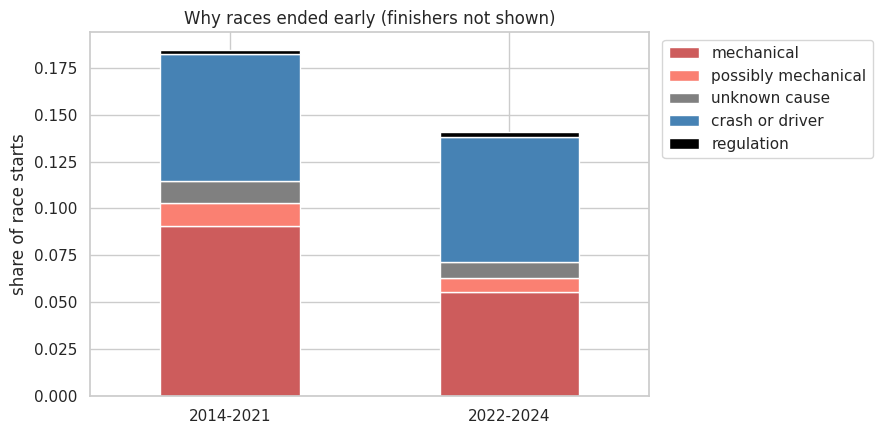

In [69]:
STATUS_CATEGORY = {
    'mechanical': ['Engine', 'Brakes', 'Gearbox', 'Power Unit', 'Suspension', 'Hydraulics', 'Electrical',
                   'Power loss', 'Oil leak', 'Overheating', 'Water pressure', 'Mechanical', 'Turbo', 'ERS',
                   'Exhaust', 'Fuel pressure', 'Water leak', 'Electronics', 'Battery', 'Transmission',
                   'Radiator', 'Clutch', 'Fuel leak', 'Driveshaft', 'Technical', 'Steering', 'Throttle',
                   'Oil pressure', 'Differential', 'Brake duct', 'Cooling system', 'Fuel pump', 'Drivetrain',
                   'Spark plugs', 'Water pump', 'Fuel system'],
    'possibly mechanical': ['Puncture', 'Tyre', 'Wheel', 'Wheel nut', 'Front wing', 'Rear wing', 'Undertray',
                            'Vibrations', 'Seat', 'Out of fuel', 'Withdrew'],
    'unknown cause': ['Retired'],
    'crash or driver': ['Collision', 'Accident', 'Collision damage', 'Spun off', 'Damage', 'Debris', 'Illness'],
    'regulation': ['Disqualified', 'Excluded'],
}
category_of = {status: cat for cat, statuses in STATUS_CATEGORY.items() for status in statuses}

# Check: every non-finishing status in 2014-2024 has exactly one category (no silent gaps)
unmapped = set(q3.loc[~q3['reached_flag'], 'status']) - set(category_of)
assert not unmapped, f'unmapped status values: {unmapped}'

q3['end_category'] = np.where(q3['reached_flag'], 'finished', q3['status'].map(category_of))
q3['mech_strict'] = q3['end_category'] == 'mechanical'
q3['mech_broad'] = q3['end_category'].isin(['mechanical', 'possibly mechanical', 'unknown cause'])

order = ['finished', 'mechanical', 'possibly mechanical', 'unknown cause', 'crash or driver', 'regulation']
counts = pd.crosstab(q3['end_category'], q3['era']).reindex(order)
print('How starts ended, per era (rows):')
print(counts.to_string(), '\n')

print('Mechanical-retirement rate per start, all constructors together:')
print(q3.groupby('era')[['mech_strict', 'mech_broad']].mean().round(3), '\n')

shares = pd.crosstab(q3['era'], q3['end_category'], normalize='index')[order[1:]]
ax = shares.plot(kind='bar', stacked=True, figsize=(9, 4.5),
                 color=['indianred', 'salmon', 'grey', 'steelblue', 'black'])
ax.set_ylabel('share of race starts')
ax.set_xlabel('')
ax.set_title('Why races ended early (finishers not shown)')
ax.tick_params(axis='x', rotation=0)
ax.legend(bbox_to_anchor=(1.01, 1), loc='upper left')
plt.tight_layout()
plt.show()

**Reading the results (how races ended):**
- **Check:** the counts match the status crosstab exactly (e.g. 296 + 40 + 38 + 221 + 8 = 603 early endings in 2014–2021), so every status is mapped once.
- **Mechanical failures fell sharply:** strict rate **9.1 % → 5.5 %** of starts (≈ 40 % fewer per start); broad rate 11.5 % → 7.2 %.
- **Crashes did not:** crash or driver endings stayed at **6.8 % → 6.6 %**. The whole drop in early retirements (18.5 % → 14.1 %) comes from **better reliability**, consistent with the hybrid power units introduced in 2014 maturing over eight seasons.
- **The unclear categories are small** (possibly mechanical + unknown = 2.4 and 1.6 points), so they cannot change the overall picture. Whether they change the *constructor ranking* is checked next.

### Q3.3 Mechanical-retirement rate per constructor
**Small-sample rule:** a constructor needs **≥ 40 starts in an era** (≈ one full season with two cars) to be ranked. With rates of 5–9 %, a team with 20 starts has only 1–2 failures, and one more failure moves its rate by 5 points. Each rate gets a **95 % Wilson interval** (as in Q1). The **broad** rate is shown next to the strict one, and a Spearman correlation checks whether the ranking depends on the definition.

Check, mechanical retirements summed over constructors: {'2014-2021': 296, '2022-2024': 75} 

Constructors per era: all vs ranked (>= 40 starts):
           all  ranked
era                   
2014-2021   19      17
2022-2024   12      12 

Not ranked (too few starts):
      era constructor_name  seasons  starts  mech
2014-2021         Caterham        1      34     8
2014-2021         Marussia        1      31     3 

=== 2014-2021 (era average strict 0.091) ===
constructor_name  seasons  starts  mech  rate  ci_low  ci_high  rank strict  mech_broad  rate_broad  rank broad
        Lotus F1        2      76    13 0.171   0.103    0.271            1          19       0.250           1
      Toro Rosso        6     242    39 0.161   0.120    0.213            2          44       0.182           2
         Renault        5     200    27 0.135   0.094    0.189            3          32       0.160           4
         McLaren        8     320    43 0.134   0.101    0.176            4          5

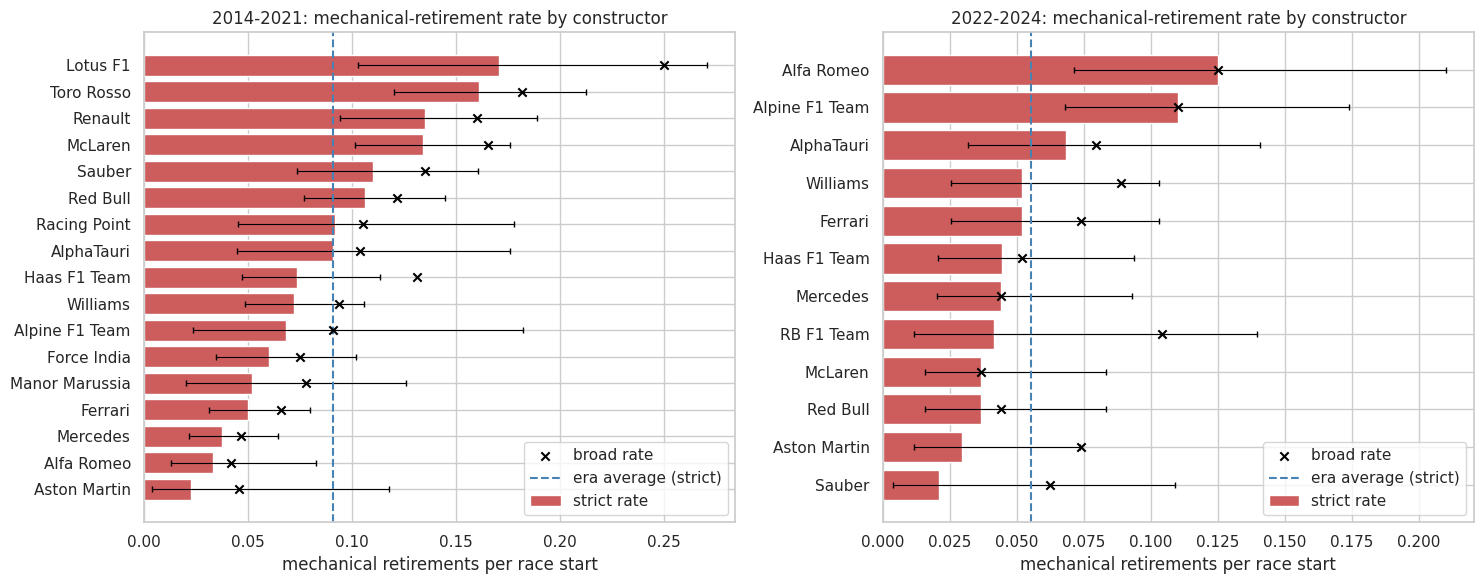

In [70]:
# Each constructor name must belong to exactly one constructorId (so grouping by name is safe)
assert q3.groupby('constructor_name')['constructorId'].nunique().max() == 1

MIN_STARTS = 40
ERAS_Q3 = ['2014-2021', '2022-2024']

def mech_table(df, flag):
    out = df.groupby(['era', 'constructor_name']).agg(seasons=('year', 'nunique'),
                                                      starts=('raceId', 'size'),
                                                      mech=(flag, 'sum')).reset_index()
    out['rate'] = out['mech'] / out['starts']
    out['ci_low'], out['ci_high'] = proportion_confint(out['mech'], out['starts'], method='wilson')
    return out

mt = mech_table(q3, 'mech_strict')
mt_broad = mech_table(q3, 'mech_broad')
mt = mt.merge(mt_broad[['era', 'constructor_name', 'mech', 'rate']].rename(columns={'mech': 'mech_broad', 'rate': 'rate_broad'}),
              on=['era', 'constructor_name'], validate='one_to_one')

print('Check, mechanical retirements summed over constructors:', mt.groupby('era')['mech'].sum().to_dict(), '\n')
print('Constructors per era: all vs ranked (>= 40 starts):')
print(pd.DataFrame({'all': mt.groupby('era').size(),
                    'ranked': mt[mt['starts'] >= MIN_STARTS].groupby('era').size()}), '\n')
print('Not ranked (too few starts):')
print(mt[mt['starts'] < MIN_STARTS][['era', 'constructor_name', 'seasons', 'starts', 'mech']].to_string(index=False), '\n')

ranked_q3 = mt[mt['starts'] >= MIN_STARTS].copy()
ranked_q3['rank strict'] = ranked_q3.groupby('era')['rate'].rank(ascending=False, method='min').astype(int)
ranked_q3['rank broad'] = ranked_q3.groupby('era')['rate_broad'].rank(ascending=False, method='min').astype(int)

for era_name in ERAS_Q3:
    d = ranked_q3[ranked_q3['era'] == era_name].sort_values('rate', ascending=False)
    rho = d[['rate', 'rate_broad']].corr(method='spearman').iloc[0, 1]
    print(f'=== {era_name} (era average strict {q3[q3["era"] == era_name]["mech_strict"].mean():.3f}) ===')
    print(d[['constructor_name', 'seasons', 'starts', 'mech', 'rate', 'ci_low', 'ci_high',
             'rank strict', 'mech_broad', 'rate_broad', 'rank broad']].round(3).to_string(index=False))
    print(f'Spearman rho, strict vs broad ranking: {rho:.2f}\n')

fig, axes = plt.subplots(1, 2, figsize=(15, 6))
for ax, era_name in zip(axes, ERAS_Q3):
    d = ranked_q3[ranked_q3['era'] == era_name].sort_values('rate')
    ax.barh(d['constructor_name'], d['rate'], color='indianred', label='strict rate')
    ax.errorbar(d['rate'], d['constructor_name'], xerr=[d['rate'] - d['ci_low'], d['ci_high'] - d['rate']],
                fmt='none', ecolor='black', capsize=2, linewidth=0.8)
    ax.scatter(d['rate_broad'], d['constructor_name'], marker='x', color='black', zorder=3, label='broad rate')
    ax.axvline(q3[q3['era'] == era_name]['mech_strict'].mean(), color='steelblue', linestyle='--', label='era average (strict)')
    ax.set_xlabel('mechanical retirements per race start')
    ax.set_title(f'{era_name}: mechanical-retirement rate by constructor')
    ax.legend(loc='lower right')
plt.tight_layout()
plt.show()

**Reading the results (rate per constructor):**
- **Check:** mechanical retirements summed over constructors = 296 and 75, as in Q3.2.
- **Not ranked:** Caterham (34 starts) and Marussia (31) raced only in 2014 under those names. Caterham's raw rate is high (8 / 34 = 23.5 %) but too uncertain to rank.
- **2014–2021 (average 9.1 %):** highest **Lotus F1 (17.1 %), Toro Rosso (16.1 %), Renault (13.5 %), McLaren (13.4 %)**. Their 95 % intervals lie entirely **above** the average. **Mercedes (3.8 %), Alfa Romeo (3.3 %) and Ferrari (5.0 %)** lie entirely **below** it. Strict and broad rankings agree almost perfectly (Spearman ρ = 0.98).
  *Context (not measured here, engine supplier is not in the dataset):* several high-rate teams used Renault or Honda power units in the early hybrid years, while Mercedes had the most reliable power unit of the era.
- **2022–2024 (average 5.5 %):** highest **Alfa Romeo (12.5 %) and Alpine (11.0 %)**, the only two whose intervals lie entirely above the average. All other teams overlap the average.
- **The definition matters more in 2022–2024** (ρ = 0.65): the top two are the same under both definitions, but the middle and bottom reshuffle, because each team has only 1–7 failures and 2–3 unclear cases move a team several places (e.g. RB 8th → 3rd). Only the top two are a robust answer for this era.

### Q3.4 Comparing the eras directly
We compare the constructors ranked in **both** eras: who became more reliable, who became less, and whether the ranking carried over (Spearman ρ, as in Q1).

Constructors ranked in both eras: 11 

era               2014-2021  2022-2024  change
constructor_name                              
Alfa Romeo            0.033      0.125   0.092
Alpine F1 Team        0.068      0.110   0.042
Aston Martin          0.023      0.030   0.007
Mercedes              0.038      0.044   0.007
Ferrari               0.050      0.052   0.002
Williams              0.072      0.052  -0.020
AlphaTauri            0.091      0.068  -0.023
Haas F1 Team          0.074      0.044  -0.029
Red Bull              0.106      0.037  -0.069
Sauber                0.110      0.021  -0.089
McLaren               0.134      0.037  -0.098 

Spearman correlation between the eras (same constructors):
era        2014-2021  2022-2024
era                            
2014-2021       1.00      -0.35
2022-2024      -0.35       1.00
p-value: 0.30

Constructors clearly different from their era average:
      era constructor_name  starts  rate  ci_low  ci_high vs era average
2014-2021         

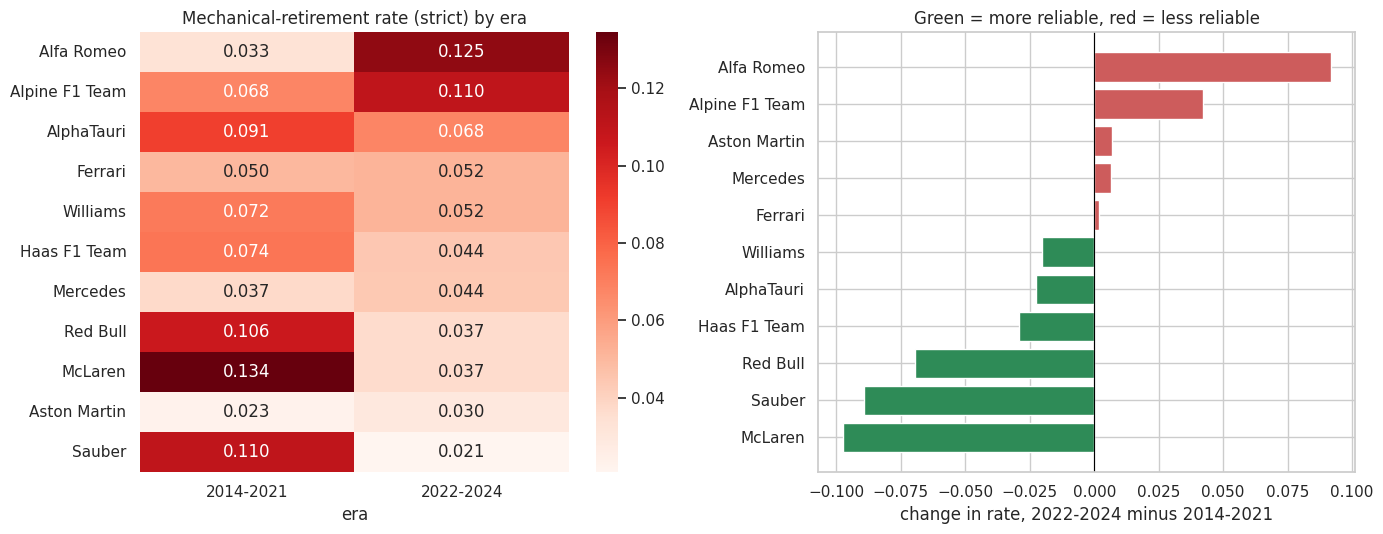

In [71]:
both_eras = ranked_q3.pivot(index='constructor_name', columns='era', values='rate').dropna()
both_eras['change'] = both_eras[ERAS_Q3[1]] - both_eras[ERAS_Q3[0]]
print('Constructors ranked in both eras:', len(both_eras), '\n')
print(both_eras.sort_values('change', ascending=False).round(3).to_string(), '\n')

print('Spearman correlation between the eras (same constructors):')
print(both_eras[ERAS_Q3].corr(method='spearman').round(2))
print(f"p-value: {spearmanr(both_eras[ERAS_Q3[0]], both_eras[ERAS_Q3[1]]).pvalue:.2f}\n")

# Which constructors are clearly above / below their era average (95% interval does not contain it)?
era_avg = q3.groupby('era')['mech_strict'].mean()
ranked_q3['era average'] = ranked_q3['era'].map(era_avg)
ranked_q3['vs era average'] = np.where(ranked_q3['ci_low'] > ranked_q3['era average'], 'clearly above',
                              np.where(ranked_q3['ci_high'] < ranked_q3['era average'], 'clearly below', 'not different'))
print('Constructors clearly different from their era average:')
print(ranked_q3[ranked_q3['vs era average'] != 'not different']
      .sort_values(['era', 'rate'], ascending=[True, False])
      [['era', 'constructor_name', 'starts', 'rate', 'ci_low', 'ci_high', 'vs era average']].round(3).to_string(index=False))

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
sns.heatmap(both_eras[ERAS_Q3].sort_values(ERAS_Q3[1], ascending=False), annot=True, fmt='.3f', cmap='Reds', ax=axes[0])
axes[0].set_title('Mechanical-retirement rate (strict) by era')
axes[0].set_ylabel('')
change = both_eras['change'].sort_values()
axes[1].barh(change.index, change.values, color=['seagreen' if v < 0 else 'indianred' for v in change.values])
axes[1].axvline(0, color='black', linewidth=0.8)
axes[1].set_xlabel('change in rate, 2022-2024 minus 2014-2021')
axes[1].set_title('Green = more reliable, red = less reliable')
plt.tight_layout()
plt.show()

**Reading the results (era comparison):**
- **11 constructors** are ranked in both eras. This includes **Sauber**, which raced as Sauber in 2014–2018, as Alfa Romeo in 2019–2023, and returned to its original `constructorId` in 2024. Its comparison is therefore 2014–2018 vs 2024, and its 2024 rate rests on 48 starts and 1 failure (95 % interval 0.4–10.9 %).
- **The ranking did not carry over:** Spearman ρ = **−0.35** (p = 0.30). Being unreliable in the first era says nothing about the second; if anything the order partly reversed.
- **Became more reliable:** **McLaren** (13.4 % → 3.7 %), **Red Bull** (10.6 % → 3.7 %), Sauber (11.0 % → 2.1 %, very uncertain), Haas, AlphaTauri, Williams.
- **Became less reliable:** **Alfa Romeo** (3.3 % → 12.5 %, from among the most to the least reliable), **Alpine** (6.8 % → 11.0 %; its first-era rate covers only 2021, 44 starts).
- **About unchanged:** Mercedes, Ferrari, Aston Martin (within one point).
- **Clearly different from the era average** (95 % interval excludes the average): 2014–2021 above: Lotus F1, Toro Rosso, Renault, McLaren; below: Ferrari, Mercedes, Alfa Romeo. 2022–2024 above: Alfa Romeo, Alpine.
- (Mercedes appears as 0.038 in the table and 0.037 in the heatmap: the exact value is 12 / 320 = 0.0375, rounded differently by the two.)

### Q3.5 Robustness check: cars that failed before the start
A car that fails on the way to the grid is recorded in two different ways: usually it keeps its grid slot and has 0 laps (so it is counted above), but a few were recorded with grid 0 and are therefore outside the modelling scope (non-starter rule, 3.8). We add those few to the count and check whether the answer changes.

In [72]:
zero_lap_mech = q3[q3['mech_strict'] & (q3['laps'] == 0)]
print('Mechanical retirements counted above with 0 laps (failed at or before the start):', len(zero_lap_mech))

# the same kind of failure, recorded with grid 0 -> excluded as non-starters in 3.8
pre_start = table[table['is_non_starter'] & table['year'].between(2014, 2024)
                  & (table['status'].map(category_of) == 'mechanical')].copy()
print('Recorded with grid 0 instead (not counted):')
display(pre_start[['year', 'race_name', 'surname', 'constructor_name', 'status']])

pre_start['era'] = np.where(pre_start['year'] <= 2021, '2014-2021', '2022-2024')
pre_start['mech_strict'] = True
cols = ['era', 'constructor_name', 'year', 'raceId', 'mech_strict']
mt_all = mech_table(pd.concat([q3[cols], pre_start[cols]]), 'mech_strict')
robust = ranked_q3[['era', 'constructor_name', 'rate', 'rank strict']].merge(
    mt_all[['era', 'constructor_name', 'rate']].rename(columns={'rate': 'rate incl. grid-0 failures'}),
    on=['era', 'constructor_name'], validate='one_to_one')
robust['rank incl. grid-0 failures'] = robust.groupby('era')['rate incl. grid-0 failures'].rank(ascending=False, method='min').astype(int)

print('Era averages (strict):', q3.groupby('era')['mech_strict'].mean().round(3).to_dict(), '->',
      pd.concat([q3[cols], pre_start[cols]]).groupby('era')['mech_strict'].mean().round(3).to_dict())
print('Constructors whose rank changes:')
display(robust[robust['rank strict'] != robust['rank incl. grid-0 failures']].round(3))
for era_name in ERAS_Q3:
    r = robust[robust['era'] == era_name]
    print(era_name, 'top 2 before:', r.nsmallest(2, 'rank strict')['constructor_name'].tolist(),
          '| after:', r.nsmallest(2, 'rank incl. grid-0 failures')['constructor_name'].tolist())

Mechanical retirements counted above with 0 laps (failed at or before the start): 20
Recorded with grid 0 instead (not counted):


,year,race_name,surname,constructor_name,status
22282,2015,Malaysian Grand Prix,Stevens,Manor Marussia,Fuel system
23387,2017,Malaysian Grand Prix,Räikkönen,Ferrari,Battery
24948,2021,Italian Grand Prix,Tsunoda,AlphaTauri,Brakes
25948,2023,São Paulo Grand Prix,Leclerc,Ferrari,Engine


Era averages (strict): {'2014-2021': 0.091, '2022-2024': 0.055} -> {'2014-2021': 0.092, '2022-2024': 0.056}
Constructors whose rank changes:


,era,constructor_name,rate,rank strict,rate incl. grid-0 failures,rank incl. grid-0 failures
1,2014-2021,AlphaTauri,0.091,8,0.103,7
5,2014-2021,Force India,0.060,12,0.060,13
8,2014-2021,Manor Marussia,0.052,13,0.064,12
11,2014-2021,Racing Point,0.092,7,0.092,8
28,2022-2024,Williams,0.052,4,0.052,5


2014-2021 top 2 before: ['Lotus F1', 'Toro Rosso'] | after: ['Lotus F1', 'Toro Rosso']
2022-2024 top 2 before: ['Alfa Romeo', 'Alpine F1 Team'] | after: ['Alfa Romeo', 'Alpine F1 Team']


**Reading (robustness):** 20 of the counted mechanical retirements have 0 laps: cars that failed at or just before the start and kept their grid slot. Four identical cases were recorded with grid 0 instead (Stevens 2015, Räikkönen 2017, Tsunoda 2021, Leclerc 2023) and are not counted. Adding them moves the era averages by only 0.1 points (9.1 % → 9.2 % and 5.5 % → 5.6 %), swaps a few mid-table places (e.g. AlphaTauri 8th → 7th in 2014–2021) and leaves the top two of both eras unchanged (Lotus F1 and Toro Rosso; Alfa Romeo and Alpine). **The answer does not depend on how these pre-start failures were recorded.**

### Q3 Answer

**Which constructors have the highest mechanical-retirement rate?**
- **2014–2021 (average 9.1 % of starts):** **Lotus F1 (17.1 %), Toro Rosso (16.1 %), Renault (13.5 %) and McLaren (13.4 %)**, all clearly above the average. The most reliable were **Alfa Romeo (3.3 %), Mercedes (3.8 %) and Ferrari (5.0 %)**, clearly below it.
- **2022–2024 (average 5.5 %):** **Alfa Romeo (12.5 %) and Alpine (11.0 %)**, the only two clearly above the average. The other ten teams cannot be separated statistically.

**How do the eras compare?** Mechanical failures fell from 9.1 % to 5.5 % of starts, while crash and driver retirements stayed at ≈ 6.7 %: the whole drop in early retirements comes from better reliability. The constructor ranking did **not** carry over (Spearman ρ = −0.35): McLaren and Red Bull went from among the least to among the most reliable, while Alfa Romeo went the other way.

**Definition:** a mechanical retirement is a race start whose `status` names a failed car component (35 values, e.g. Engine, Gearbox, Power Unit, Hydraulics). Crashes, driver errors, illness and regulation decisions are excluded. **Ambiguous** values (punctures, wings, wheel/wheel nut, withdrew, …) and the cause-less **"Retired"** are kept separate; adding them (the broad definition) gives the same ranking in 2014–2021 (ρ = 0.98) and the same top two in 2022–2024 (ρ = 0.65 overall).

**Grain:** one row per (raceId, driverId) race start, from the cleaned modelling scope (starters only, so cars that failed before the start are not counted). Rate = mechanical retirements ÷ race starts per constructor and era. Checked: the per-constructor counts sum back to 296 and 75.

**Missingness:** status is complete, but 50 retirements (38 + 12) are recorded only as "Retired" with no cause; they are treated as unknown and only enter the broad definition. Constructors with fewer than 40 starts in an era are not ranked (Caterham, Marussia).

**Pre-race cutoff:** status is **post-race** information and is used here only to answer the question. It must **never** be a model feature. A constructor's mechanical-retirement rate *from previous races* could be a leakage-safe "reliability form" feature.

**Limitations:**
- Each `constructorId` is a separate team, so renames split histories (Toro Rosso / AlphaTauri / RB; Force India / Racing Point / Aston Martin), and Sauber's id spans 2014–2018 and 2024.
- 2022–2024 has only 3 seasons, so most teams have 1–7 failures and wide intervals.
- Engine supplier, a likely cause of reliability differences, is not in the dataset.
- The status labels are the dataset's own; the mechanical/non-mechanical grouping is our documented judgement.
- Cars that failed before the start are recorded inconsistently (grid slot with 0 laps vs grid 0); Q3.5 shows this does not change the answer.

# 8. Feature Engineering & Feature Selection

In this section we build the features, justify them with evidence, and define the train / validation / test split.

Rules for every step:
1. **Known at the cutoff:** a feature may only use information available after qualifying and before the start (Section 3.11).
2. **Past races only:** form and standings features are built from earlier races, so a race's own result never enters its own features.
3. **Fitted on training rows only:** imputation values and the scaler are learned on training data and only applied to validation and test (Lab 3: `fit_transform` on train, `transform` on the rest).

### 8.1 The split: by season, not at random
**Train ≤ 2019, validation 2020–2021, test ≥ 2022** (the F1 guide's boundaries).

Why not a random `train_test_split` as in the labs?
- **It would leak the future:** 2023 races would be in training while 2015 races are in test. In reality we always predict the next race from the past.
- **It would break races apart:** the podium places of one race are linked (only 3 drivers can podium), so a race must stay in one set.
- **It is a realistic test:** 2022–2024 is a new technical era, so a good test score shows the model works on new seasons it never saw.

Validation is used for all choices (features, thresholds, hyperparameters); the test set is used once at the end.

In [73]:
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, average_precision_score

# Chronological order: form features look backwards in time
fe = model_table.sort_values(['race_date', 'raceId', 'driverId']).reset_index(drop=True)

fe['split'] = np.where(fe['year'] <= 2019, 'train', np.where(fe['year'] <= 2021, 'validation', 'test'))
assert fe.groupby('raceId')['split'].nunique().max() == 1, 'a race appears in two splits!'

split_summary = fe.groupby('split').agg(first_season=('year', 'min'), last_season=('year', 'max'),
                                        races=('raceId', 'nunique'), rows=('raceId', 'size'),
                                        podium_rate=('podium', 'mean'),
                                        qualifying_coverage=('has_quali', 'mean')).reindex(['train', 'validation', 'test'])
split_summary.round(3)

,first_season,last_season,races,rows,podium_rate,qualifying_coverage
split,,,,,,
train,1950,2019,1007,22552,0.134,0.370
validation,2020,2021,39,779,0.150,0.999
test,2022,2024,68,1356,0.150,1.000


**Reading the split:** train has 1,007 races (22,552 rows), validation 39 races (779 rows, a COVID-shortened 2020 plus 2021) and test 68 races (1,356 rows). No race appears in two sets (`assert` passed). The podium rate is 0.150 (= 3 ÷ 20 cars) in validation and test, and 0.134 in train, where older seasons had bigger fields.

**Qualifying coverage is the key difference:** only 37 % of training rows have qualifying data, against ~100 % in validation and test (the coverage drift from 4.6). We therefore **train on 2003–2019 only**, the seasons with complete qualifying data (4.6). The earlier seasons are still used to compute the drivers' and teams' form history, because those races happened before.

### 8.2 Grid and qualifying features
| Feature | Meaning | Why |
|---|---|---|
| `grid_clean` | starting position (pit lane = back of grid) | strongest single signal (4.4: pole → ~64 % podium) |
| `pit_lane_start` | 1 if starting from the pit lane | information hidden by `grid_clean` |
| `quali_position` | qualifying rank | differs from the grid in ~24 % of rows (4.5) |
| `q1_gap_pct` | % gap between the driver's Q1 time and the fastest Q1 time of that race | the *size* of the gap measures car pace; position only gives the order |
| `grid_minus_quali` | `grid_clean − quali_position` (positive = penalty) | Q1.3: penalised front-row qualifiers converted only 22–33 % vs 68–77 % |

We use **Q1** because every qualifier drives it in the same conditions (Q2/Q3 are missing by design for knocked-out drivers), and a **percentage** because lap lengths differ between circuits. All of these are known once the grid is final.

In [74]:
fastest_q1 = fe.groupby('raceId')['q1_s'].transform('min')
fe['q1_gap_pct'] = (fe['q1_s'] / fastest_q1 - 1) * 100
fe['grid_minus_quali'] = fe['grid_clean'] - fe['quali_position']

# A Q1 lap more than twice the fastest lap is not a valid timed lap (data error) -> missing
impossible = fe['q1_gap_pct'] > 100
display(fe.loc[impossible, ['year', 'race_name', 'surname', 'q1_s', 'q1_gap_pct']].round(2))
fe.loc[impossible, 'q1_gap_pct'] = np.nan

with_q = fe['has_quali'] == 1
print('Rows with qualifying data:', int(with_q.sum()), '| of these without a Q1 time:', int(fe.loc[with_q, 'q1_gap_pct'].isna().sum()))
fe.loc[with_q, ['quali_position', 'q1_gap_pct', 'grid_minus_quali']].describe().round(2)

,year,race_name,surname,q1_s,q1_gap_pct
13202,1995,Japanese Grand Prix,Blundell,1002.64,922.86


Rows with qualifying data: 10477 | of these without a Q1 time: 155


,quali_position,q1_gap_pct,grid_minus_quali
count,10477.00,10322.00,10477.00
mean,11.19,1.85,0.01
std,6.25,1.93,1.52
min,1.00,0.00,-9.00
25%,6.00,0.71,0.00
50%,11.00,1.34,0.00
75%,16.00,2.36,0.00
max,26.00,44.78,23.00


**Reading:** 10,477 rows (42.4 %) have qualifying data. One Q1 time was impossible: Blundell, 1995 Japanese GP, recorded at 1002.6 s (almost 17 minutes) where the fastest lap was 98 s. That is a recording error, so it was set to missing. Together with drivers who set no Q1 lap, 155 rows have no `q1_gap_pct`; they are filled in 8.5. Most cars are within 2.4 % of the fastest (75th percentile), but a real long tail remains (up to 44.8 %: wet sessions and very slow back-markers), which we clip in 8.5. `grid_minus_quali` is 0 for most rows, from −9 (promoted) to +23 (back of the grid after a penalty).

### 8.3 Form features: results of earlier races
Car performance is the dominant factor in F1 (F1 guide), so we measure recent form for both the driver and the constructor, over the previous *N* races:

| Feature | Meaning |
|---|---|
| `drv_podium_rate` | share of podiums in the driver's last *N* starts |
| `drv_finish_rel` | average finishing rank ÷ number of starters, last *N* starts (relative, so 26-car and 20-car fields are comparable) |
| `con_podium_rate` | podiums per car in the constructor's last *N* races |
| `con_finish_rel` | same relative finish for the constructor's cars |
| `con_dnf_rate` | share of the constructor's cars that did not reach the flag (reliability, suggested in Q3) |

**Leakage-safe:** `shift(1)` before `rolling(N)`, so the current race is never included. Constructor form is computed on one row per team per race and then shifted by one race, so a teammate's result from the *same* race cannot slip in. `finish_rel` and `reached_flag` come from post-race columns and are only used for these past averages, never as features.

**Choosing N:** we compare windows of 3, 5, 10 and 20 races by their correlation with `podium` on training rows (all training seasons up to 2019; restricting it to the 2003–2019 rows the models are trained on gives the same choice, N = 10).

In [75]:
# Post-race ingredients, used ONLY for averages over past races
fe['finish_rel'] = fe.groupby('raceId')['positionOrder'].rank(method='first') / fe['cars_on_grid']
fe['reached_flag'] = ((fe['status'] == 'Finished') | fe['status'].str.match(r'^\+\d+ Laps?$')).astype(int)

def add_form_features(df, n):
    out = pd.DataFrame(index=df.index)
    by_driver = df.groupby('driverId')
    out['drv_podium_rate'] = by_driver['podium'].transform(lambda s: s.shift(1).rolling(n, min_periods=1).mean())
    out['drv_finish_rel'] = by_driver['finish_rel'].transform(lambda s: s.shift(1).rolling(n, min_periods=1).mean())

    # one row per team per race, then shift by one race (no teammate leak)
    con = (df.groupby(['constructorId', 'raceId'], sort=False)
             .agg(race_date=('race_date', 'first'), podiums=('podium', 'sum'), cars=('podium', 'size'),
                  finish_rel=('finish_rel', 'mean'), dnfs=('reached_flag', lambda s: (1 - s).sum()))
             .reset_index().sort_values(['race_date', 'raceId']))
    g = con.groupby('constructorId')
    past_sum = lambda col: g[col].transform(lambda s: s.shift(1).rolling(n, min_periods=1).sum())
    con['con_podium_rate'] = past_sum('podiums') / past_sum('cars')
    con['con_dnf_rate'] = past_sum('dnfs') / past_sum('cars')
    con['con_finish_rel'] = g['finish_rel'].transform(lambda s: s.shift(1).rolling(n, min_periods=1).mean())
    con_cols = df[['constructorId', 'raceId']].merge(con[['constructorId', 'raceId', 'con_podium_rate', 'con_finish_rel', 'con_dnf_rate']],
                                                     on=['constructorId', 'raceId'], how='left', validate='many_to_one')
    for col in ['con_podium_rate', 'con_finish_rel', 'con_dnf_rate']:
        out[col] = con_cols[col].values
    return out

# Choose the window N on training rows
train_rows = fe['split'] == 'train'
trials = []
for n in [3, 5, 10, 20]:
    f = add_form_features(fe, n)
    trials.append({'N': n, 'corr drv_podium_rate': f.loc[train_rows, 'drv_podium_rate'].corr(fe.loc[train_rows, 'podium']),
                   'corr con_podium_rate': f.loc[train_rows, 'con_podium_rate'].corr(fe.loc[train_rows, 'podium'])})
trials = pd.DataFrame(trials).set_index('N')
FORM_WINDOW = int(trials.abs().mean(axis=1).idxmax())
display(trials.round(3))
print('Chosen FORM_WINDOW =', FORM_WINDOW)

# Apply the chosen window and check for leakage
fe = pd.concat([fe, add_form_features(fe, FORM_WINDOW)], axis=1)
first_start = fe.groupby('driverId').cumcount() == 0
assert fe.loc[first_start, 'drv_podium_rate'].isna().all()                                         # no past -> no form
assert (fe.groupby(['raceId', 'constructorId'])['con_podium_rate'].nunique(dropna=False) <= 1).all()  # no teammate leak
leaky = fe.groupby('driverId')['podium'].transform(lambda s: s.rolling(FORM_WINDOW, min_periods=1).mean())
print('Leakage checks passed')
print('Correlation with podium (train): safe driver form =', round(fe.loc[train_rows, 'drv_podium_rate'].corr(fe.loc[train_rows, 'podium']), 3),
      '| LEAKY version (includes this race) =', round(leaky[train_rows].corr(fe.loc[train_rows, 'podium']), 3))

,corr drv_podium_rate,corr con_podium_rate
N,,
3,0.432,0.439
5,0.461,0.458
10,0.475,0.464
20,0.468,0.458


Chosen FORM_WINDOW = 10
Leakage checks passed
Correlation with podium (train): safe driver form = 0.475 | LEAKY version (includes this race) = 0.61


**Reading:** all windows give strong signals (correlation 0.43–0.48 with `podium` on training rows). **N = 10** is selected: N = 3 is noisier, and N = 20 starts to remember old cars. The two `assert`s prove the features are leakage-safe: every driver's first start has no form, and both cars of a team always share the same constructor-form value. Including the current race would raise the correlation from **0.475 to 0.61**. A leaky feature looks *better* in the notebook but cannot be computed before the start, which is exactly the kind of leakage the brief warns about.

### 8.4 Standings before the race
The standings tables are recorded **after** each race (2.2). To be leakage-safe, every row of round *r* gets the standings **after round *r* − 1 of the same season**; in round 1 everyone has 0 points.

Raw points are not comparable across eras (a win was worth 8 points in the 1950s and 25 since 2010), so we use the **fraction of the leader's points**: `drv_points_frac` and `con_points_frac` (1 = leading, 0 = no points). The constructors' championship starts in 1958; earlier rows get 0.

In [76]:
races_order = clean['races'][['raceId', 'year', 'round']]
prev_race = races_order.assign(round=races_order['round'] + 1).rename(columns={'raceId': 'prev_raceId'})
fe = fe.merge(prev_race, on=['year', 'round'], how='left', validate='many_to_one')
fe['prev_raceId'] = fe['prev_raceId'].astype('Int64')          # round 1 -> no previous race

def points_frac_before(fe, standings, key):
    st = standings[['raceId', key, 'points']].rename(columns={'raceId': 'prev_raceId'})
    leader = st.groupby('prev_raceId')['points'].max().rename('leader_points').reset_index()
    out = (fe[['prev_raceId', key]].merge(st, on=['prev_raceId', key], how='left', validate='many_to_one')
                                   .merge(leader, on='prev_raceId', how='left', validate='many_to_one'))
    frac = out['points'].fillna(0) / out['leader_points']
    return frac.where(out['leader_points'] > 0, 0).fillna(0).values

n_rows = len(fe)
fe['drv_points_frac'] = points_frac_before(fe, clean['driver_standings'], 'driverId')
fe['con_points_frac'] = points_frac_before(fe, clean['constructor_standings'], 'constructorId')
assert len(fe) == n_rows
assert (fe.loc[fe['round'] == 1, ['drv_points_frac', 'con_points_frac']] == 0).all().all()   # round 1: no points yet
print('Standings checks passed')

# Spot check: before the 2021 finale, Verstappen and Hamilton were level on points -> both should be 1.0
last_2021 = fe[(fe['year'] == 2021) & (fe['round'] == fe.loc[fe['year'] == 2021, 'round'].max())]
last_2021.sort_values('drv_points_frac', ascending=False)[['race_name', 'surname', 'drv_points_frac', 'con_points_frac']].head(4)

Standings checks passed


,race_name,surname,drv_points_frac,con_points_frac
23311,Abu Dhabi Grand Prix,Hamilton,1.000000,1.00000
23318,Abu Dhabi Grand Prix,Verstappen,1.000000,0.95234
23317,Abu Dhabi Grand Prix,Bottas,0.589986,1.00000
23315,Abu Dhabi Grand Prix,Pérez,0.514208,0.95234


**Reading:** the spot check matches history. Before the 2021 finale, Hamilton and Verstappen were level on 369.5 points (both 1.0), and Mercedes led Red Bull in the constructors' championship (1.0 vs 0.95). Round 1 rows all have 0, so no row ever sees standings from its own race.

### 8.5 Evidence for the chosen features
We train on **2003–2019** (complete qualifying data, 8.1), so the evidence is computed on exactly those training rows. Validation and test rows are not looked at. Each panel shows the podium rate per feature bin (bars with 95 % confidence intervals) against the overall rate (dashed line).

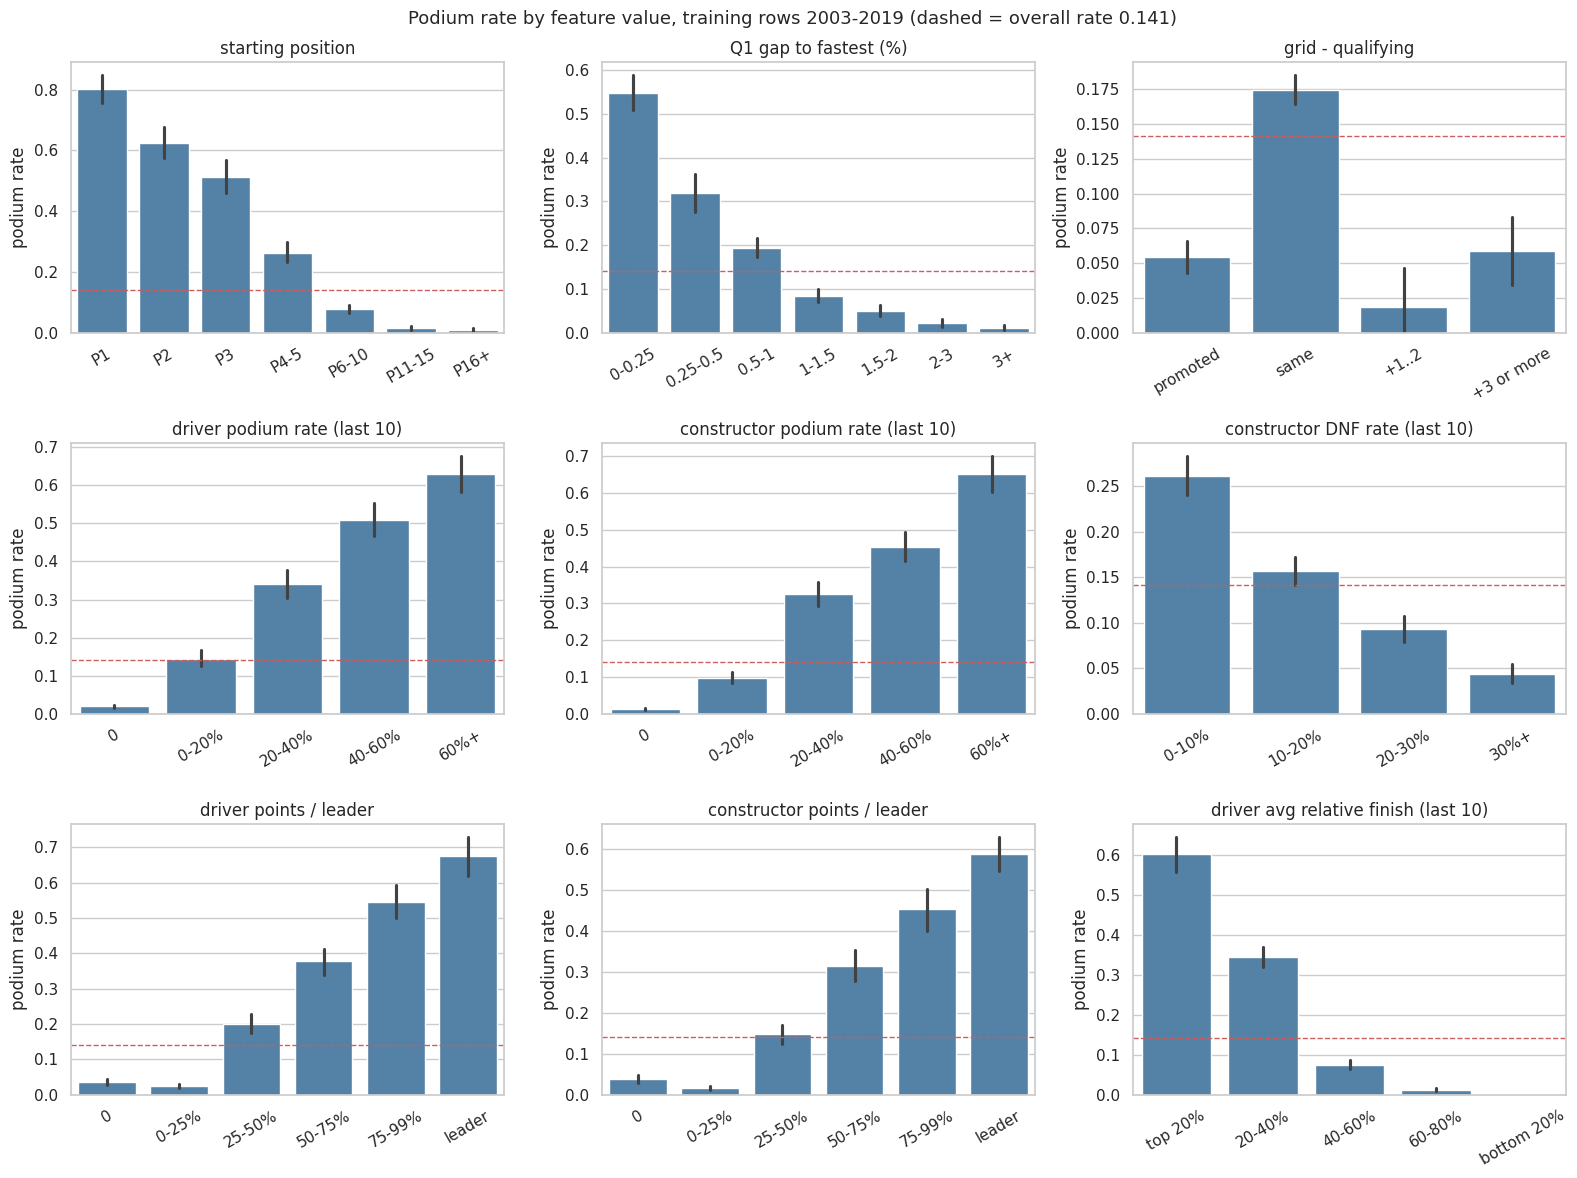

In [77]:
TRAIN_START = 2003
tr = fe[(fe['split'] == 'train') & (fe['year'] >= TRAIN_START)]
base_rate = tr['podium'].mean()

EVIDENCE = [
    ('grid_clean', [0, 1, 2, 3, 5, 10, 15, 30], ['P1', 'P2', 'P3', 'P4-5', 'P6-10', 'P11-15', 'P16+'], 'starting position'),
    ('q1_gap_pct', [0, 0.25, 0.5, 1, 1.5, 2, 3, 100], ['0-0.25', '0.25-0.5', '0.5-1', '1-1.5', '1.5-2', '2-3', '3+'], 'Q1 gap to fastest (%)'),
    ('grid_minus_quali', [-100, -0.5, 0.5, 2.5, 100], ['promoted', 'same', '+1..2', '+3 or more'], 'grid - qualifying'),
    ('drv_podium_rate', [-0.001, 0.001, 0.2, 0.4, 0.6, 1], ['0', '0-20%', '20-40%', '40-60%', '60%+'], 'driver podium rate (last 10)'),
    ('con_podium_rate', [-0.001, 0.001, 0.2, 0.4, 0.6, 1], ['0', '0-20%', '20-40%', '40-60%', '60%+'], 'constructor podium rate (last 10)'),
    ('con_dnf_rate', [-0.001, 0.1, 0.2, 0.3, 1], ['0-10%', '10-20%', '20-30%', '30%+'], 'constructor DNF rate (last 10)'),
    ('drv_points_frac', [-0.001, 0.001, 0.25, 0.5, 0.75, 0.999, 1], ['0', '0-25%', '25-50%', '50-75%', '75-99%', 'leader'], 'driver points / leader'),
    ('con_points_frac', [-0.001, 0.001, 0.25, 0.5, 0.75, 0.999, 1], ['0', '0-25%', '25-50%', '50-75%', '75-99%', 'leader'], 'constructor points / leader'),
    ('drv_finish_rel', [0, 0.2, 0.4, 0.6, 0.8, 1.0], ['top 20%', '20-40%', '40-60%', '60-80%', 'bottom 20%'], 'driver avg relative finish (last 10)'),
]

fig, axes = plt.subplots(3, 3, figsize=(16, 12))
for ax, (col, bins, labels, title) in zip(axes.ravel(), EVIDENCE):
    d = tr[[col, 'podium']].dropna().copy()
    d['bin'] = pd.cut(d[col], bins=bins, labels=labels, include_lowest=True)
    sns.barplot(data=d, x='bin', y='podium', ax=ax, color='steelblue', errorbar=('ci', 95))
    ax.axhline(base_rate, color='indianred', linestyle='--', linewidth=1)
    ax.set_title(title)
    ax.set_xlabel('')
    ax.set_ylabel('podium rate')
    ax.tick_params(axis='x', rotation=30)
plt.suptitle(f'Podium rate by feature value, training rows {TRAIN_START}-2019 (dashed = overall rate {base_rate:.3f})', fontsize=13)
plt.tight_layout()
plt.show()

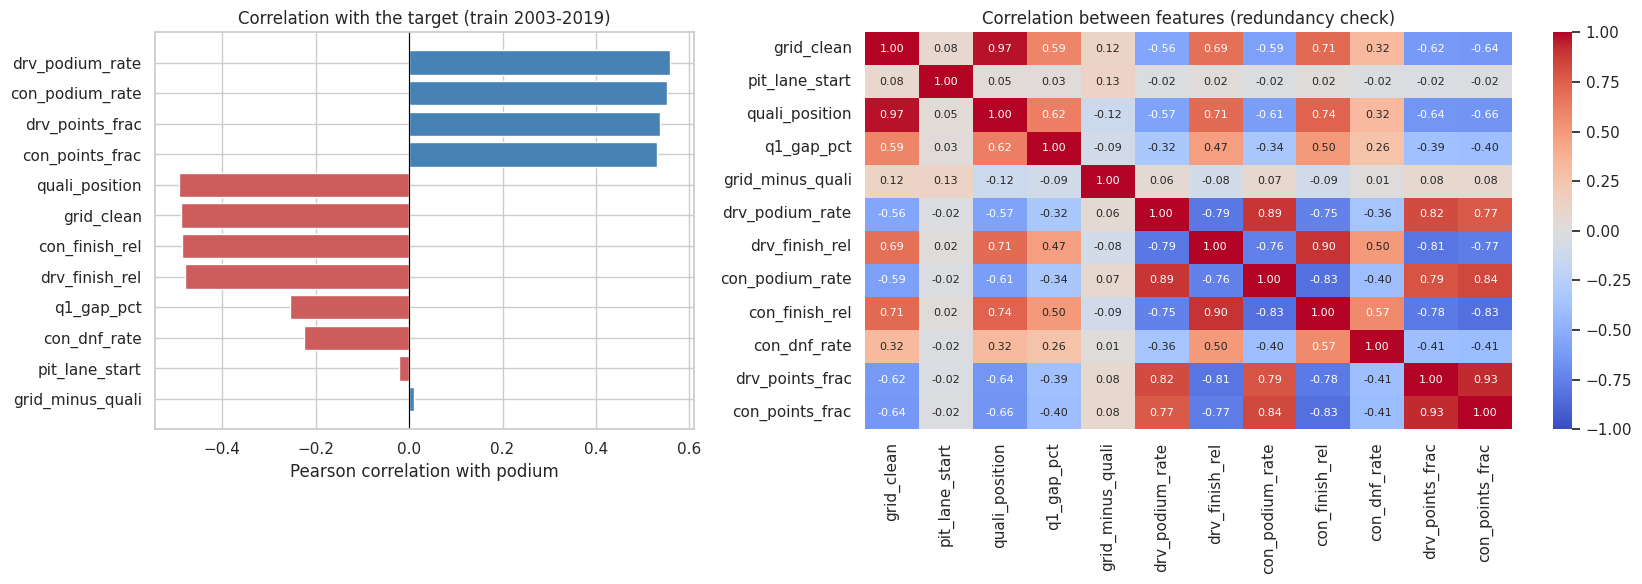

{'quali_position': -0.491, 'grid_clean': -0.489, 'con_finish_rel': -0.486, 'drv_finish_rel': -0.48, 'q1_gap_pct': -0.255, 'con_dnf_rate': -0.225, 'pit_lane_start': -0.021, 'grid_minus_quali': 0.01, 'con_points_frac': 0.53, 'drv_points_frac': 0.538, 'con_podium_rate': 0.551, 'drv_podium_rate': 0.558}
Matrix rank of [grid_clean, quali_position, grid_minus_quali]: 2 (3 = three independent columns, 2 = one is an exact combination of the other two)


In [78]:
FEATURES = ['grid_clean', 'pit_lane_start', 'quali_position', 'q1_gap_pct', 'grid_minus_quali',
            'drv_podium_rate', 'drv_finish_rel', 'con_podium_rate', 'con_finish_rel', 'con_dnf_rate',
            'drv_points_frac', 'con_points_frac']

fig, axes = plt.subplots(1, 2, figsize=(17, 6), gridspec_kw={'width_ratios': [1, 1.5]})
corr_target = tr[FEATURES + ['podium']].astype(float).corr()['podium'].drop('podium')
corr_target = corr_target.reindex(corr_target.abs().sort_values().index)
axes[0].barh(corr_target.index, corr_target.values, color=['indianred' if v < 0 else 'steelblue' for v in corr_target.values])
axes[0].axvline(0, color='black', linewidth=0.8)
axes[0].set_xlabel('Pearson correlation with podium')
axes[0].set_title(f'Correlation with the target (train {TRAIN_START}-2019)')
sns.heatmap(tr[FEATURES].astype(float).corr(), annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1, ax=axes[1], annot_kws={'size': 8})
axes[1].set_title('Correlation between features (redundancy check)')
plt.tight_layout()
plt.show()
print(corr_target.sort_values().round(3).to_dict())

# grid_minus_quali is defined as grid_clean - quali_position: check whether it adds a new dimension
_rows = tr[['grid_clean', 'quali_position', 'grid_minus_quali']].dropna()
print('Matrix rank of [grid_clean, quali_position, grid_minus_quali]:', np.linalg.matrix_rank(_rows.values),
      '(3 = three independent columns, 2 = one is an exact combination of the other two)')

**Reading the evidence (training rows 2003–2019, overall podium rate 0.141):**
- **Starting position** is the strongest single signal: P1 → ~80 % podium, P2 ~62 %, P3 ~51 %, and almost 0 from P11 onwards.
- **Q1 gap:** cars within 0.25 % of the fastest Q1 time podium ~55 % of the time, dropping steadily to ~1 % beyond 3 %. Its Pearson correlation (−0.26) looks weaker than grid's only because the relationship is strongly non-linear: almost all of the effect sits in the first 1 %.
- **Grid vs qualifying:** drivers who started exactly where they qualified podium 17 % of the time. Drivers moved back by a penalty (+1 or more) and drivers *promoted* (mostly midfield cars gaining a place behind a penalised driver) podium only 2–6 %. The relationship is not monotonic, so its linear correlation is ~0 (0.01), but the bins show a real signal that tree models can use.
- **Form:** driver and constructor podium rates over the last 10 races rise from ~1–2 % (no recent podium) to over 60 % (60 %+ podium rate). They are the most correlated features (0.56 and 0.55). Relative finish shows the same pattern from the other side (top-20 % finishers ~60 %, bottom 20 % ~0).
- **Reliability:** teams with a 0–10 % recent DNF rate podium 26 % of the time, those above 30 % only 4 %.
- **Standings:** championship leaders podium ~67 % (drivers) and ~58 % (constructors); drivers with less than a quarter of the leader's points almost never do.
- **`pit_lane_start`** has a correlation of almost 0 because pit-lane starts are rare. We keep it because it carries the meaning that `grid_clean` hides (3.9).

**Redundancy (heatmap):** `grid_clean` and `quali_position` (0.97), the two points fractions (0.93), and the form features (0.8–0.9) overlap strongly, because they all measure "how fast is this car right now". We keep them: they are not identical (e.g. `grid_minus_quali` exists exactly because grid and qualifying sometimes differ), tree models are not hurt by correlated inputs, and the **ablation experiment** will measure what each *group* really adds. Correlated features will **share importance** in the XAI section, which we must keep in mind when reading SHAP. `grid_minus_quali` is an **exact** combination of `grid_clean` and `quali_position` (matrix rank 2, printed above): a linear model or network cannot learn anything new from it, and the three weights cannot be read separately. Only the tree models can use it, through its non-linear pattern (penalised vs promoted vs same).

**Final feature set (12):** grid (`grid_clean`, `pit_lane_start`), qualifying (`quali_position`, `q1_gap_pct`, `grid_minus_quali`), driver form (`drv_podium_rate`, `drv_finish_rel`), constructor form (`con_podium_rate`, `con_finish_rel`, `con_dnf_rate`), standings (`drv_points_frac`, `con_points_frac`).

**Left out on purpose:** `year` (test years lie outside the training range), driver/constructor/circuit IDs (would memorise who was fast in the past; teams change and get renamed), `is_home` (no effect in Q2), `driver_age` (≈ 0 correlation, 4.9), raw Q2/Q3 times (missing by design), and all post-race columns (leakage, 3.11). **Sprint results** (2021+) are known before the race, but they exist only after our training window (2003–2019), so a model could not learn from them; on 2021–2022 sprint weekends the sprint result already sets the grid, so it reaches the model through `grid_clean`. Since no nominal multi-category column remains, no one-hot encoding is needed.

### 8.6 Preprocessing
All statistics are learned on the **training rows (2003–2019)** and applied unchanged to validation and test:
1. **Structural fill (nothing learned):** missing `quali_position` → `grid_clean`; `grid_minus_quali` → 0; podium/DNF rates with no past races → 0.
2. **Median imputation:** remaining gaps (`q1_gap_pct` for drivers with no Q1 lap, relative finish for debuts) → training median, which is robust to outliers (Lab 1).
3. **Clip `q1_gap_pct`** at the training 99th percentile: the slow wet-session laps are real, but they should not dominate the scale.
4. **`StandardScaler`** (Lab 3): features range from 0–1 (rates) to 1–26 (grid). Scaling puts them on one scale for logistic regression and the neural network.

Train: (6821, 12), Validation: (779, 12), Test: (1356, 12)
q1_gap_pct clipped at 7.57 % (training 99th percentile)


,train before,val before,test before,after (all sets)
quali_position,21,1,0,0
q1_gap_pct,124,9,13,0
grid_minus_quali,21,1,0,0
drv_podium_rate,75,6,8,0
drv_finish_rel,75,6,8,0
con_podium_rate,35,4,2,0
con_finish_rel,35,4,2,0
con_dnf_rate,35,4,2,0


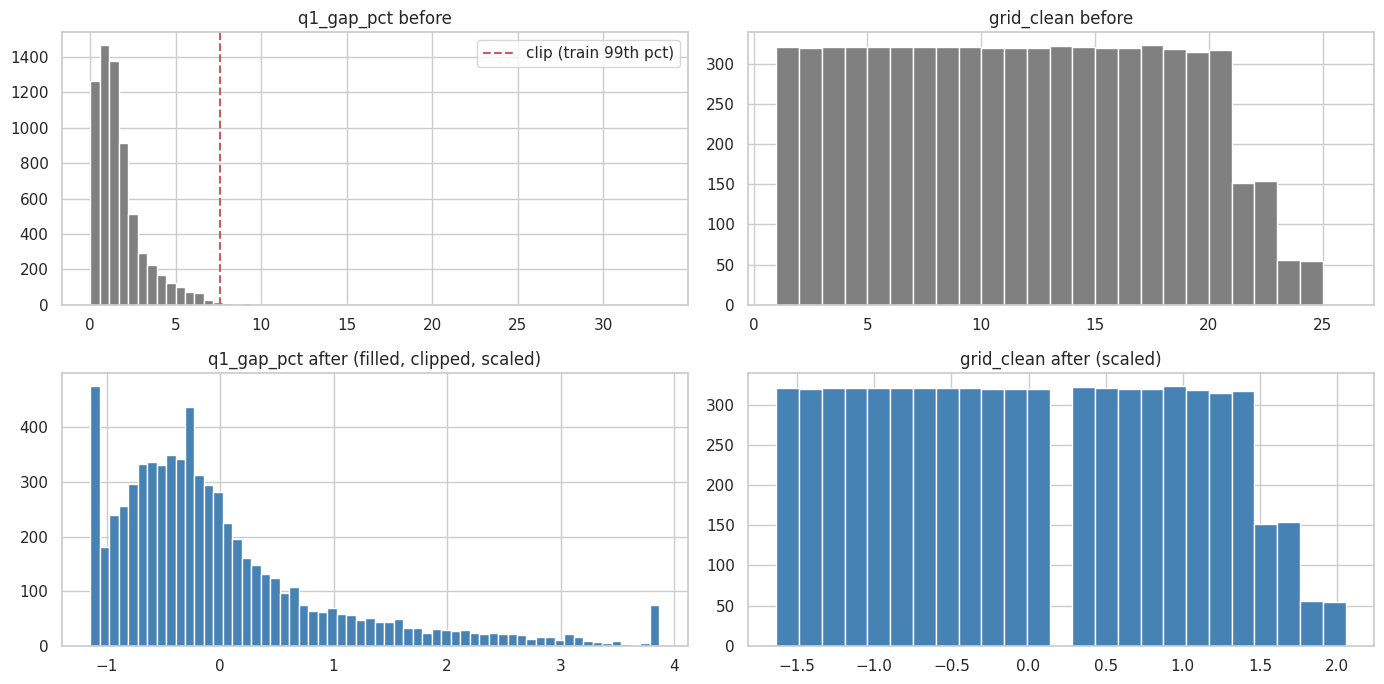

,before min,before max,after mean (train),after std (train),after mean (test)
grid_clean,1.00,24.00,0.0,1.0,-0.11
pit_lane_start,0.00,1.00,0.0,1.0,0.46
quali_position,1.00,24.00,0.0,1.0,-0.11
q1_gap_pct,0.00,33.29,-0.0,1.0,-0.46
grid_minus_quali,-7.00,23.00,-0.0,1.0,0.02
drv_podium_rate,0.00,1.00,0.0,1.0,0.05
drv_finish_rel,0.05,1.00,0.0,1.0,-0.00
con_podium_rate,0.00,1.00,-0.0,1.0,0.04
con_finish_rel,0.08,0.93,0.0,1.0,0.01
con_dnf_rate,0.00,1.00,-0.0,1.0,-0.62


In [79]:
def fill_structural(df):
    out = df.copy()
    out['quali_position'] = out['quali_position'].fillna(out['grid_clean'])
    out['grid_minus_quali'] = out['grid_minus_quali'].fillna(0)
    for col in ['drv_podium_rate', 'con_podium_rate', 'con_dnf_rate']:
        out[col] = out[col].fillna(0)
    return out[FEATURES]

def fit_preprocessing(train_df):
    X = fill_structural(train_df)
    medians = X.median()
    clip_hi = X['q1_gap_pct'].fillna(medians['q1_gap_pct']).quantile(0.99)
    X = X.fillna(medians)
    X['q1_gap_pct'] = X['q1_gap_pct'].clip(upper=clip_hi)
    return {'medians': medians, 'clip_hi': clip_hi, 'scaler': StandardScaler().fit(X)}

def apply_preprocessing(df, prep, scale=True):
    X = fill_structural(df).fillna(prep['medians'])
    X['q1_gap_pct'] = X['q1_gap_pct'].clip(upper=prep['clip_hi'])
    return pd.DataFrame(prep['scaler'].transform(X), columns=FEATURES, index=df.index) if scale else X

train_df = fe[(fe['split'] == 'train') & (fe['year'] >= TRAIN_START)]
val_df = fe[fe['split'] == 'validation']
test_df = fe[fe['split'] == 'test']

prep = fit_preprocessing(train_df)
X_train_scaled, y_train = apply_preprocessing(train_df, prep), train_df['podium']
X_val_scaled, y_val = apply_preprocessing(val_df, prep), val_df['podium']
X_test_scaled, y_test = apply_preprocessing(test_df, prep), test_df['podium']
print(f'Train: {X_train_scaled.shape}, Validation: {X_val_scaled.shape}, Test: {X_test_scaled.shape}')
print('q1_gap_pct clipped at', round(prep['clip_hi'], 2), '% (training 99th percentile)')

# Effect: missing values before vs after
missing = pd.DataFrame({'train before': train_df[FEATURES].isna().sum(), 'val before': val_df[FEATURES].isna().sum(),
                        'test before': test_df[FEATURES].isna().sum(),
                        'after (all sets)': X_train_scaled.isna().sum() + X_val_scaled.isna().sum() + X_test_scaled.isna().sum()})
display(missing[missing.iloc[:, :3].sum(axis=1) > 0])

# Effect: distribution and range before vs after
fig, axes = plt.subplots(2, 2, figsize=(14, 7))
axes[0, 0].hist(train_df['q1_gap_pct'].dropna(), bins=60, color='grey')
axes[0, 0].axvline(prep['clip_hi'], color='indianred', linestyle='--', label='clip (train 99th pct)')
axes[0, 0].set_title('q1_gap_pct before')
axes[0, 0].legend()
axes[1, 0].hist(X_train_scaled['q1_gap_pct'], bins=60, color='steelblue')
axes[1, 0].set_title('q1_gap_pct after (filled, clipped, scaled)')
axes[0, 1].hist(train_df['grid_clean'], bins=range(1, 27), color='grey')
axes[0, 1].set_title('grid_clean before')
axes[1, 1].hist(X_train_scaled['grid_clean'], bins=25, color='steelblue')
axes[1, 1].set_title('grid_clean after (scaled)')
plt.tight_layout()
plt.show()

pd.DataFrame({'before min': train_df[FEATURES].min(), 'before max': train_df[FEATURES].max(),
              'after mean (train)': X_train_scaled.mean(), 'after std (train)': X_train_scaled.std(),
              'after mean (test)': X_test_scaled.mean()}).round(2)

**Reading the preprocessing:**
- **Sizes:** 6,821 training rows (2003–2019), 779 validation, 1,356 test, 12 features each.
- **Missing values → 0 in every set.** Before, the gaps were: 21 training rows (and 1 in validation) where the driver started without a qualifying entry (→ `quali_position` = grid, `grid_minus_quali` = 0), drivers with no Q1 lap (124 / 9 / 13 → training median), and debuts or new constructors with no past races (→ rate 0, relative finish = training median).
- **`q1_gap_pct`:** clipped at **7.57 %** (training 99th percentile), so the extreme wet-session laps (up to 33 %) are kept but pulled in. After scaling, the bulk of the distribution keeps its shape. Three spikes are expected: on the left the fastest car of each race (gap 0), in the middle the median fill, and on the right the clipped rows.
- **`grid_clean`:** scaling only changes the units (the shape is identical; the gap in the middle is just a histogram bin edge). Before, the features ranged from 0–1 (rates) to 1–24 (positions) and −7 to +23 (`grid_minus_quali`); after, all have mean 0 and standard deviation 1 on training rows.
- **A leakage check and an era-drift warning in one table:** the training means are exactly 0, but the test means are not, because the scaler never saw the test seasons (if they were 0, it would mean the scaler had been fitted on them). The largest shifts show how 2022–24 differs from 2003–19: **`con_dnf_rate` −0.62** (modern cars are far more reliable), **`q1_gap_pct` −0.46** (the field is closer together), and **`pit_lane_start` +0.46** (pit-lane starts became more common). This is the era sensitivity listed in our limitations.

### 8.7 Preprocessing-order experiments
Does it matter *when* preprocessing statistics are computed? We change one thing at a time compared with our pipeline and score each version on the **validation** seasons with the same logistic regression (Lab 2). The test set is not used.
- **Experiment 1:** the scaler is fitted on **all rows** (train + validation + test) before splitting, instead of on training rows only.
- **Experiment 2:** the imputation medians and the clipping threshold are computed on **all rows** before splitting, instead of on training rows only.

In [80]:
def evaluate(prep):
    model = LogisticRegression(max_iter=1000).fit(apply_preprocessing(train_df, prep), y_train)
    proba = model.predict_proba(apply_preprocessing(val_df, prep))[:, 1]
    return {'ROC-AUC (val)': roc_auc_score(y_val, proba), 'PR-AUC (val)': average_precision_score(y_val, proba)}

all_rows = pd.concat([train_df, val_df, test_df])

# Experiment 1: scaler fitted on all rows
prep_exp1 = fit_preprocessing(train_df)
prep_exp1['scaler'] = StandardScaler().fit(apply_preprocessing(all_rows, prep_exp1, scale=False))

# Experiment 2: medians and clip threshold from all rows (scaler still fitted on training rows)
prep_exp2 = fit_preprocessing(all_rows)
prep_exp2['scaler'] = StandardScaler().fit(apply_preprocessing(train_df, prep_exp2, scale=False))

order_results = pd.DataFrame([
    {'pipeline': 'Ours: split first, fit everything on train', **evaluate(prep)},
    {'pipeline': 'Exp 1: scaler fitted on all rows', **evaluate(prep_exp1)},
    {'pipeline': 'Exp 2: medians / clip from all rows', **evaluate(prep_exp2)},
]).set_index('pipeline')
display(order_results.round(4))

print('Clip threshold q1_gap_pct: train only =', round(prep['clip_hi'], 2), '| all rows =', round(prep_exp2['clip_hi'], 2))
pd.DataFrame({'scaler mean: train only': prep['scaler'].mean_, 'scaler mean: all rows': prep_exp1['scaler'].mean_},
             index=FEATURES).round(3)

,ROC-AUC (val),PR-AUC (val)
pipeline,,
"Ours: split first, fit everything on train",0.9306,0.7133
Exp 1: scaler fitted on all rows,0.9306,0.7125
Exp 2: medians / clip from all rows,0.9306,0.7124


Clip threshold q1_gap_pct: train only = 7.57 | all rows = 7.45


,scaler mean: train only,scaler mean: all rows
grid_clean,11.190,11.032
pit_lane_start,0.003,0.008
quali_position,11.190,11.023
q1_gap_pct,1.730,1.594
grid_minus_quali,-0.001,0.008
drv_podium_rate,0.140,0.143
drv_finish_rel,0.521,0.522
con_podium_rate,0.143,0.144
con_finish_rel,0.522,0.523
con_dnf_rate,0.231,0.211


**Reading the preprocessing-order experiments:**
- **The scores are almost identical:** ROC-AUC is 0.9306 in all three pipelines, and PR-AUC is 0.7133 (ours) vs 0.7125 (Exp 1) and 0.7124 (Exp 2). Computing the statistics on all rows did not help; our order is marginally the best.
- **Why the difference is small:** adding the 2020–2024 rows moves the learned statistics only a little (lower table): the clip threshold moves from 7.57 % to 7.45 %, and the largest mean shifts are in `con_dnf_rate` (0.231 → 0.211) and `q1_gap_pct` (1.73 → 1.59), the same features that showed era drift in 8.6.
- **Why our order is still the right one:** in both leaky pipelines, statistics from the **test seasons** reach the training data. The scores would then no longer measure performance on truly unseen seasons, and the pipeline could not be reproduced in real use, where next season's data does not exist yet. A small score difference does not make leakage acceptable.
- **Decision:** we keep the order **split → fill → impute → clip → scale**, with every statistic fitted on training rows only.

### 8.8 Summary of feature engineering
| Group | Features | Evidence | Why it is known before the start |
|---|---|---|---|
| Grid | `grid_clean`, `pit_lane_start` | P1 → ~80 % podium (8.5), 4.4 | the starting grid is fixed before the lights go out |
| Qualifying | `quali_position`, `q1_gap_pct`, `grid_minus_quali` | Q1 gap < 0.25 % → ~55 % podium; penalised drivers 2–6 % (8.5), Q1.3 | qualifying ends before the race |
| Driver form | `drv_podium_rate`, `drv_finish_rel` | corr 0.56 / −0.48; window N = 10 chosen (8.3) | previous 10 starts only (`shift(1)`, `assert`) |
| Constructor form | `con_podium_rate`, `con_finish_rel`, `con_dnf_rate` | corr 0.55 / −0.49 / −0.23 (8.5), Q3 | team-per-race table, no teammate leak (`assert`) |
| Standings | `drv_points_frac`, `con_points_frac` | leaders podium ~58–67 % (8.5) | standings after the previous round; round 1 = 0 (`assert`) |

**Split:** train 2003–2019 (6,821 rows), validation 2020–2021 (779), test 2022–2024 (1,356), by season, so the model is always tested on future races and every race stays whole.

**Limitations:** the test seasons are a new technical era (era drift is visible in 8.6: more reliable cars and a closer field); form at the start of a season reflects last year's car; correlated features (grid ↔ qualifying, form ↔ standings) will share importance in the XAI section.

In [81]:
feature_table = fe[['raceId', 'driverId', 'constructorId', 'year', 'round', 'split'] + FEATURES + ['podium']]
feature_table.to_csv(os.path.join(OUT_DIR, 'driver_race_features.csv'), index=False)
print('Saved:', feature_table.shape)

Saved: (24687, 19)


# 9. Predictive Modelling, Evaluation and Experiments

Sections 1–8 gave us a clean, leakage-safe table with 12 pre-race features. This section answers the question the whole project is built around: **how well can those 12 numbers predict who ends up on the podium, and which kind of model is worth using?**

**The intuition.** Before every race, each driver already carries a lot of evidence: where they start, how quick their car was in qualifying, how well they and their team have been doing lately, and where they sit in the championship. A model is just a way of *weighing* that evidence into one number: a podium probability. Different models weigh it differently: a logistic regression adds up evidence in a straight line, a random forest or gradient boosting asks a long series of yes/no questions ("starts top 3 **and** team podiums often?"), and a neural network builds weighted evidence from weighted evidence. We compare them fairly and then check how much each *group* of evidence really matters.

**Rules for every step** (the same discipline as Section 8):
1. **Same rows, same 12 features for every model**, so scores are directly comparable.
2. **Every choice** (hyperparameters, early-stopping point, probability threshold, which model wins) uses **training and validation seasons only**.
3. **The test seasons (2022–2024) are scored once**, in 9.8, after the finalists are fixed.

| Part | What it does |
|---|---|
| 9.1 | Recap of the split and what each set is allowed to do |
| 9.2 | Metrics: what each measures, and which one is primary |
| 9.3 – 9.5 | Reference rule, baseline logistic regression, and four statistical-model attempts |
| 9.6 | Shallow neural networks (1–2 hidden layers) |
| 9.7 | Model comparison on training and validation, and selection of the finalists |
| 9.8 | The unseen test seasons |
| 9.9 | Limitations |
| 9.10 | Feature-group ablation |
| 9.11 – 9.12 | Saved objects for the XAI / inference part, and a summary |

> **Metric set.** The brief asks for "all five metrics" but its table lists only ROC-AUC, PR-AUC and F1. We therefore report **ROC-AUC, PR-AUC, F1, precision and recall** (the last two are the two ingredients of F1, Lab 2).

## 9.0 Setup

Everything below is built on the objects created in Section 8.6: `train_df / val_df / test_df` (rows), `FEATURES` (the 12 columns), `prep` (the preprocessing fitted on training rows) and the scaled matrices `X_train_scaled / X_val_scaled / X_test_scaled`.

We keep **two copies of the same table**:
- `Xs` — scaled (mean 0, std 1). Needed by logistic regression and the neural network, whose weights are sensitive to the units of each feature (Lab 3).
- `Xr` — the same rows and columns after the same filling / clipping, but **in original units** (grid = 1…26, rates = 0…1). Tree models only compare each feature with thresholds, so scaling cannot change what they learn; training them on the original units makes later explanations (SHAP, LIME) readable ("grid ≤ 3" instead of "grid ≤ −1.2").

In [82]:
import itertools
import joblib
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.metrics import (roc_auc_score, average_precision_score, f1_score, precision_score,
                             recall_score, precision_recall_curve, roc_curve, confusion_matrix)

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.callbacks import EarlyStopping

SEED = 42
np.random.seed(SEED)
tf.random.set_seed(SEED)
tf.config.experimental.enable_op_determinism()   # same seed -> same network on every Run All (same hardware)

# Targets, rows and the two copies of the feature table (same rows, same 12 features)
dfs = {'train': train_df, 'val': val_df, 'test': test_df}
ys = {s: dfs[s]['podium'].values for s in dfs}
Xs = {'train': X_train_scaled, 'val': X_val_scaled, 'test': X_test_scaled}          # scaled: logistic regression, neural network
Xr = {s: apply_preprocessing(dfs[s], prep, scale=False) for s in dfs}              # original units: tree models

for s in dfs:
    assert list(Xs[s].columns) == FEATURES and Xs[s].shape == Xr[s].shape
    assert len(ys[s]) == len(Xs[s]) and (Xs[s].index == dfs[s].index).all()
    assert not Xs[s].isna().any().any() and not Xr[s].isna().any().any()
print('Setup OK: same rows and the same', len(FEATURES), 'features in both copies, no missing values')

Setup OK: same rows and the same 12 features in both copies, no missing values


## 9.1 The split, and what each set is allowed to do

The split was defined in 8.1 and is **by season**, so the model is always judged on races that come *after* the ones it learned from:

| Set | Seasons | Used for |
|---|---|---|
| **Training** | 2003–2019 | fitting model weights / trees |
| **Validation** | 2020–2021 | hyperparameters, early stopping, the probability threshold, and choosing the finalists |
| **Test** | 2022–2024 | one final, unbiased score. Never used for any choice |

Why this and not a random split: a random split would put 2023 races in training and 2015 races in test, and would split the three podium places of one race across sets. The season split also gives a hard test: **2022–2024 is a new technical era** (8.6 showed more reliable cars and a closer field), so a good test score means the model transfers to a regime it never saw.

**Class balance matters for everything that follows.** Only ~3 of ~20 drivers per race reach the podium, so roughly 1 row in 7 is positive. A model that always answers "no podium" would already be ~85 % *accurate* and completely useless, which is the accuracy trap from Lab 2. It is also why a random guesser's PR-AUC equals the base rate (shown below).

,seasons,races,rows,podium rows,podium rate
train,2003-2019,321,6821,963,0.141
validation,2020-2021,39,779,117,0.150
test,2022-2024,68,1356,204,0.150


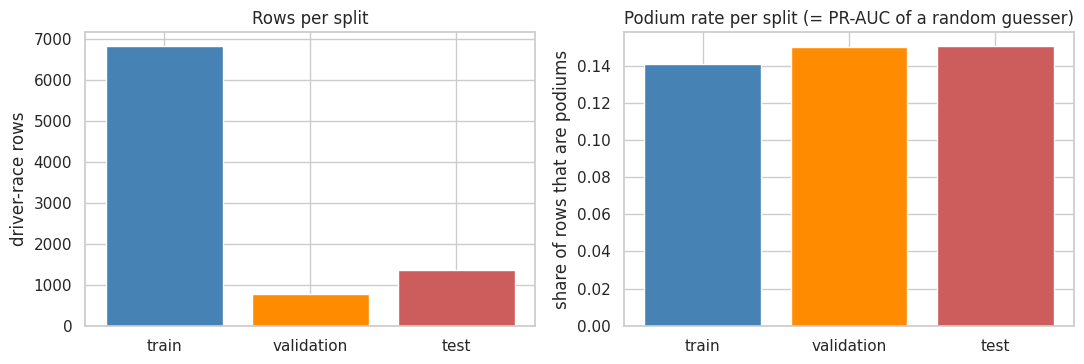

Validation has only 117 podium rows in 39 races, so small score differences (about 0.01–0.02) between models on validation are within noise and should not be over-interpreted.


In [83]:
split_table = pd.DataFrame({
    'seasons': [f"{dfs[s]['year'].min()}-{dfs[s]['year'].max()}" for s in dfs],
    'races': [dfs[s]['raceId'].nunique() for s in dfs],
    'rows': [len(ys[s]) for s in dfs],
    'podium rows': [int(ys[s].sum()) for s in dfs],
    'podium rate': [ys[s].mean() for s in dfs],
}, index=['train', 'validation', 'test'])
display(split_table.round(3))

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
axes[0].bar(split_table.index, split_table['rows'], color=['steelblue', 'darkorange', 'indianred'])
axes[0].set_title('Rows per split')
axes[0].set_ylabel('driver-race rows')
axes[1].bar(split_table.index, split_table['podium rate'], color=['steelblue', 'darkorange', 'indianred'])
axes[1].set_title('Podium rate per split (= PR-AUC of a random guesser)')
axes[1].set_ylabel('share of rows that are podiums')
plt.tight_layout()
plt.show()

print(f"Validation has only {int(ys['val'].sum())} podium rows in {dfs['val']['raceId'].nunique()} races, so small score differences "
      f"(about 0.01–0.02) between models on validation are within noise and should not be over-interpreted.")

## 9.2 Metrics: what each one measures, and which is primary

All models output a **probability** that a driver finishes on the podium. The metrics look at that probability in two ways.

**Threshold-free (judge the ranking):** imagine the model sorting every driver of a race from "most likely podium" to "least likely".
- **ROC-AUC:** pick one random podium finisher and one random non-podium driver. ROC-AUC is the chance the model gave the podium finisher the higher score. 0.5 = coin flip, 1.0 = perfect.
- **PR-AUC (average precision):** walk down the sorted list from the top. At each point, how many of the drivers flagged so far are real podium finishers (**precision**), and how many of all real podium finishers have been found (**recall**)? PR-AUC summarises that whole walk. It only cares about the *top of the list*, where podium finishers live.

**At a chosen threshold (judge a yes/no call):** "predict podium if probability ≥ *t*".
- **Precision:** when the model says podium, how often is it right?  **Recall:** of all real podium finishers, how many did it catch?
- **F1:** the harmonic mean of precision and recall, so it is only high if *both* are.

**Primary metric: PR-AUC. Secondary: ROC-AUC. F1 / precision / recall describe the operating point.**
- Podiums are rare (~15 %), and the ~10 back-of-grid cars in a race are *easy* negatives. They inflate ROC-AUC, so many reasonable models score 0.90+ and ROC-AUC barely separates them. PR-AUC ignores those easy negatives and measures exactly what we care about: ranking the true podium finishers at the top. Its floor is the base rate (≈ 0.15), not 0.5.
- **Accuracy is deliberately not used**: predicting "no podium" for everyone already gives ~85 %.

**The threshold is never 0.5 by default.** With rare positives, 0.5 is far too strict. For every model we choose the threshold that **maximises F1 on the validation set**, then keep it fixed for training and test. Because the threshold is tuned on validation, validation F1 is slightly optimistic by construction; the test F1 is the honest one.

**Supplementary, F1-specific metric (not required by the brief): top-3 hit rate.** Every race has exactly 3 podium finishers. If we take each race's 3 highest-scored drivers, what share of them really finish on the podium? It is the closest number to how a fan would use the model ("who are the three?"), and it needs no threshold.

In [84]:
def best_f1_threshold(y_true, proba):
    # probability cut-off that maximises F1 (always called with VALIDATION data)
    prec, rec, thr = precision_recall_curve(y_true, proba)
    f1 = 2 * prec[:-1] * rec[:-1] / np.clip(prec[:-1] + rec[:-1], 1e-12, None)
    return float(thr[int(np.argmax(f1))])

def top3_hit_rate(split, proba):
    d = pd.DataFrame({'raceId': dfs[split]['raceId'].values, 'p': proba, 'y': ys[split]})
    return d.sort_values(['raceId', 'p'], ascending=[True, False]).groupby('raceId').head(3)['y'].mean()

def evaluate(split, proba, threshold):
    y = ys[split]
    pred = (proba >= threshold).astype(int)
    return {'ROC-AUC': roc_auc_score(y, proba), 'PR-AUC': average_precision_score(y, proba),
            'F1': f1_score(y, pred), 'Precision': precision_score(y, pred, zero_division=0),
            'Recall': recall_score(y, pred), 'Top-3 hit rate': top3_hit_rate(split, proba)}

# Every model we train is registered here, so all of them are scored in exactly the same way
registry, thresholds, FACTORY, NN_ARCH = {}, {}, {}, {}

def get_proba(name, split):
    e = registry[name]
    X = (Xs if e['inputs'] == 'scaled' else Xr)[split]
    if e['family'] == 'NN':
        return e['model'].predict(X.values.astype('float32'), verbose=0).ravel()
    return e['model'].predict_proba(X)[:, 1]

def add_model(name, model, inputs, family, factory=None):
    registry[name] = {'model': model, 'inputs': inputs, 'family': family}
    if factory is not None:
        FACTORY[name] = factory                       # rebuilds an UNFITTED copy (used by the ablation)
    thresholds[name] = best_f1_threshold(ys['val'], get_proba(name, 'val'))   # validation only
    return name

def metrics_table(names, splits):
    rows = [{'model': n, 'split': s, 'threshold': thresholds[n], **evaluate(s, get_proba(n, s), thresholds[n])}
            for n in names for s in splits]
    return pd.DataFrame(rows)

def plot_curves(names, split, title):
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    for n in names:
        p, y = get_proba(n, split), ys[split]
        fpr, tpr, _ = roc_curve(y, p)
        prec, rec, _ = precision_recall_curve(y, p)
        axes[0].plot(fpr, tpr, label=f'{n} ({roc_auc_score(y, p):.3f})')
        axes[1].plot(rec, prec, label=f'{n} ({average_precision_score(y, p):.3f})')
    axes[0].plot([0, 1], [0, 1], 'k--', linewidth=0.8)
    axes[1].axhline(ys[split].mean(), color='grey', linestyle='--', linewidth=0.8, label='random guesser (base rate)')
    axes[0].set(xlabel='False positive rate', ylabel='True positive rate', title=f'ROC curve ({split}), AUC in brackets')
    axes[1].set(xlabel='Recall', ylabel='Precision', title=f'Precision-recall curve ({split}), AUC in brackets')
    for ax in axes:
        ax.legend(fontsize=8)
    plt.suptitle(title, fontsize=12)
    plt.tight_layout()
    plt.show()
print('Helpers ready')

Helpers ready


## 9.3 Reference point: how far does the starting grid alone get us?

A model has to *earn* its complexity. Our EDA (4.4, 8.5) showed that starting position is the strongest single signal, so the simplest "model" is a rule with **no learning at all**: score each driver by `1 / grid position`, so pole is most likely, P2 next, and so on. Every learned model below has to beat this to justify itself. (The threshold for its F1 is chosen on validation like for every other model.)

In [85]:
class GridRule:
    # not a learned model: podium score = 1 / grid position
    def predict_proba(self, X):
        score = 1.0 / X['grid_clean'].values
        return np.column_stack([1 - score, score])

NAME_RULE = add_model('Rule: grid only', GridRule(), 'raw', 'reference')
display(metrics_table([NAME_RULE], ['train', 'val']).round(4))

,model,split,threshold,ROC-AUC,PR-AUC,F1,Precision,Recall,Top-3 hit rate
0,Rule: grid only,train,0.3333,0.9085,0.6258,0.6462,0.6466,0.6459,0.6469
1,Rule: grid only,val,0.3333,0.9092,0.6386,0.6923,0.6923,0.6923,0.6923


**Reading (our results):**
- The no-learning rule reaches validation **PR-AUC 0.639**, ROC-AUC 0.909 and F1 0.692. This is the floor every model must beat. A ROC-AUC of 0.91 for a rule that only looks at the grid already shows how generous ROC-AUC is on this problem (9.2).
- Precision, recall, F1 and top-3 hit rate are all identical (0.692). That is not a coincidence: the chosen threshold of 1/3 means "grid ≤ 3", which flags exactly three drivers per race, the same as the number of podium places. When the number flagged equals the number of real podiums, precision, recall and top-3 hit rate coincide. About 69 % of the real podium finishers start in the top three.
- The rule scores slightly *lower* on training (PR-AUC 0.626) than on validation (0.639) even though it learns nothing. So the validation seasons are a little easier to predict than the average training season. Keep this in mind when reading train − validation gaps in 9.7.

## 9.4 Baseline: logistic regression

**The baseline required by the brief is a simple statistical model.** We use **logistic regression**, which was the first classifier of Lab 2.

**How it works (intuition first).** Every feature gets a *weight* that says how strongly it pushes towards "podium" or away from it. The model adds up `weight × feature` over all 12 features (plus a bias) into one score, and the **sigmoid** function (Lab 2) squashes that score into a probability between 0 and 1. Training searches for the weights that make the predicted probabilities match the real outcomes best. Because the features were standardised (8.6), a weight can be read as "how much one standard deviation of this feature moves the podium odds".

**Why it is a good baseline:** fast, stable, nothing to tune, and its weights can be read directly.

**Its limitations (relevant to F1):**
- It is **additive**: the effect of a feature is the same everywhere. It cannot express "pole matters a lot *only* if the car is also reliable", unless we hand-craft that feature.
- Effects are **straight lines on the log-odds scale**, but 8.5 showed strongly non-linear patterns (almost all of the `q1_gap_pct` effect sits in the first 1 %; `grid_minus_quali` is not monotonic).
- With **correlated features** (grid ↔ qualifying 0.97, form ↔ standings 0.8–0.9) the weights split and sometimes cancel each other, so individual weights are unreliable to read.

,model,split,threshold,ROC-AUC,PR-AUC,F1,Precision,Recall,Top-3 hit rate
0,Rule: grid only,train,0.3333,0.9085,0.6258,0.6462,0.6466,0.6459,0.6469
1,Rule: grid only,val,0.3333,0.9092,0.6386,0.6923,0.6923,0.6923,0.6923
2,LR baseline,train,0.3491,0.9278,0.6837,0.6730,0.6160,0.7414,0.6511
3,LR baseline,val,0.3491,0.9306,0.7133,0.7064,0.7034,0.7094,0.6923


Sanity check against Section 8.7 (same model, same data): val ROC-AUC = 0.9306 | val PR-AUC = 0.7133 (8.7 reported 0.9306 / 0.7133)


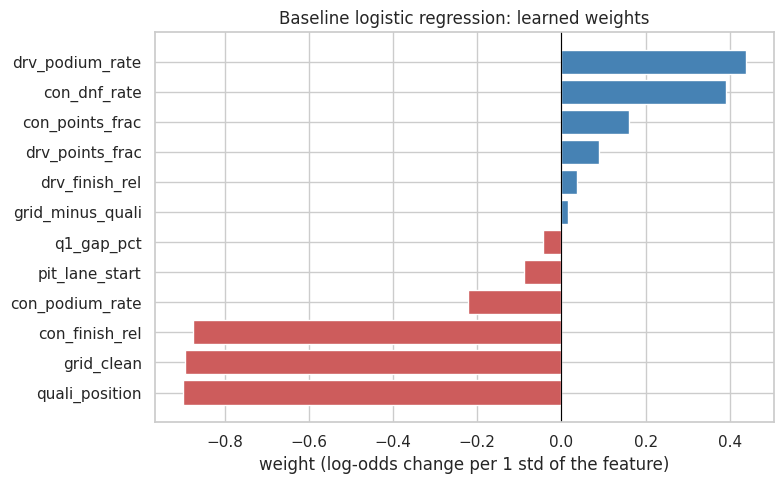

In [86]:
lr_base = LogisticRegression(max_iter=1000).fit(Xs['train'], ys['train'])
NAME_BASE = add_model('LR baseline', lr_base, 'scaled', 'statistical', factory=lambda: LogisticRegression(max_iter=1000))

base_table = metrics_table([NAME_RULE, NAME_BASE], ['train', 'val'])
display(base_table.round(4))
print('Sanity check against Section 8.7 (same model, same data): val ROC-AUC =',
      round(base_table[(base_table.model == NAME_BASE) & (base_table.split == 'val')]['ROC-AUC'].iloc[0], 4),
      '| val PR-AUC =', round(base_table[(base_table.model == NAME_BASE) & (base_table.split == 'val')]['PR-AUC'].iloc[0], 4),
      '(8.7 reported 0.9306 / 0.7133)')

coef = pd.Series(lr_base.coef_[0], index=FEATURES).sort_values()
fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(coef.index, coef.values, color=['indianred' if v < 0 else 'steelblue' for v in coef.values])
ax.axvline(0, color='black', linewidth=0.8)
ax.set_xlabel('weight (log-odds change per 1 std of the feature)')
ax.set_title('Baseline logistic regression: learned weights')
plt.tight_layout()
plt.show()

**How to read this:**
- **Table:** compare `LR baseline` with `Rule: grid only`. The gap in **PR-AUC** is what learning from 12 features adds over "just look at the grid". Compare `train` with `val` rows for each model: a large drop from train to validation would mean overfitting; a small drop (or none) means the model generalises across the 2019 → 2020 boundary.
- **Weights:** positive weights push towards a podium, negative ones away (a *worse* grid position or a *higher* DNF rate lowers the odds, as expected). Remember the caveat above: for correlated pairs such as `grid_clean` / `quali_position` the individual weights are not trustworthy, only the combined effect is. This is correlation within the model, not causation, which the XAI section must also state explicitly.

**Reading (our results):**
- The baseline reproduces Section 8.7 exactly (validation ROC-AUC 0.9306, PR-AUC 0.7133), which confirms the pipeline in this section is consistent with the feature-engineering part.
- Learning from the 12 features adds **+0.075 PR-AUC** over the grid-only rule on validation (0.713 vs 0.639) and F1 rises from 0.692 to 0.706. The extra evidence (qualifying gap, form, standings) helps, but the grid already carries most of the signal.
- Validation PR-AUC (0.713) is *higher* than training PR-AUC (0.684). As seen in 9.3, validation seasons are easier than the average training season, so this is not a sign that the model is "better than it should be", and there is no overfitting to worry about for a 12-weight linear model.


## 9.5 Statistical-model attempts

The brief wants at least three distinct modelling attempts, each visible on its own. Every attempt below states a **hypothesis** (what we expect to change and why), tests it, and is scored on **validation only**. The attempt is "better" only if validation **PR-AUC** improves, and we also look at the **train − validation gap** to catch overfitting.

| Attempt | Hypothesis |
|---|---|
| 1. LR baseline (9.4) | reference |
| 2. LR with balanced class weights | podiums are rare, so telling the model to care more about them should help *recall* |
| 3. LR with tuned regularisation `C` | the correlated features make the weights unstable; shrinking them should help generalisation |
| 4. Random forest | podium chances depend on *combinations* (good grid **and** reliable fast car); trees can find those |
| 5. Gradient boosting | the same idea, but each new tree focuses on the cases the previous trees got wrong |

A small helper runs a grid of hyperparameters, trains on the training rows and scores on validation.

In [87]:
def tune(build, grid, inputs):
    # try every hyperparameter combination: fit on TRAIN, score on VALIDATION; returns the table, best params, best model
    X = Xs if inputs == 'scaled' else Xr
    rows, best = [], {'score': -1}
    for values in itertools.product(*grid.values()):
        params = dict(zip(grid.keys(), values))
        model = build(**params).fit(X['train'], ys['train'])
        p_tr, p_va = model.predict_proba(X['train'])[:, 1], model.predict_proba(X['val'])[:, 1]
        row = {**params, 'train PR-AUC': average_precision_score(ys['train'], p_tr),
               'val PR-AUC': average_precision_score(ys['val'], p_va), 'val ROC-AUC': roc_auc_score(ys['val'], p_va)}
        rows.append(row)
        if row['val PR-AUC'] > best['score']:
            best = {'score': row['val PR-AUC'], 'params': params, 'model': model}
    table = pd.DataFrame(rows).sort_values('val PR-AUC', ascending=False).reset_index(drop=True)
    table['train-val gap'] = table['train PR-AUC'] - table['val PR-AUC']
    return table, best['params'], best['model']

def plot_grid_heatmap(table, row, col, title):
    pivot = table.pivot_table(index=row, columns=col, values='val PR-AUC', aggfunc='max')
    sns.heatmap(pivot, annot=True, fmt='.3f', cmap='Blues')
    plt.title(title)
    plt.show()

### Attempt 2: logistic regression with balanced class weights

`class_weight='balanced'` makes each rare podium row count about 6 times as much as a non-podium row during training. We expect little change in the *ranking* (AUC metrics) but a different probability scale, which our validation-chosen threshold absorbs.

In [88]:
lr_bal = LogisticRegression(max_iter=1000, class_weight='balanced').fit(Xs['train'], ys['train'])
NAME_LR_BAL = add_model('LR balanced', lr_bal, 'scaled', 'statistical',
                        factory=lambda: LogisticRegression(max_iter=1000, class_weight='balanced'))
display(metrics_table([NAME_BASE, NAME_LR_BAL], ['train', 'val']).round(4))

,model,split,threshold,ROC-AUC,PR-AUC,F1,Precision,Recall,Top-3 hit rate
0,LR baseline,train,0.3491,0.9278,0.6837,0.6730,0.6160,0.7414,0.6511
1,LR baseline,val,0.3491,0.9306,0.7133,0.7064,0.7034,0.7094,0.6923
2,LR balanced,train,0.6428,0.9278,0.6720,0.6519,0.5399,0.8224,0.6345
3,LR balanced,val,0.6428,0.9286,0.7070,0.7063,0.6593,0.7607,0.6923


### Attempt 3: logistic regression with tuned regularisation

`C` controls how hard the weights are pulled towards zero (small `C` = strong pull). A little shrinkage stops two correlated features from taking large opposite weights that fit the training seasons but break on new ones.

,C,train PR-AUC,val PR-AUC,val ROC-AUC,train-val gap
0,0.100,0.6800,0.7163,0.9303,-0.0363
1,1.000,0.6837,0.7133,0.9306,-0.0296
2,0.010,0.6691,0.7121,0.9273,-0.0430
3,100.000,0.6841,0.7085,0.9307,-0.0245
4,10.000,0.6840,0.7085,0.9307,-0.0245
5,0.001,0.6383,0.6950,0.9205,-0.0567


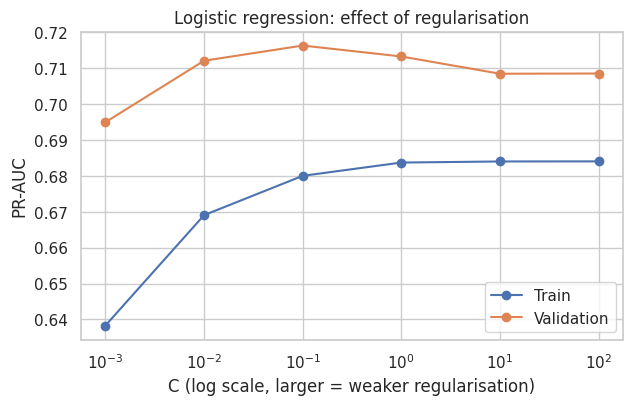

Selected {'C': 0.1} by validation PR-AUC


In [89]:
lr_table, lr_params, lr_best = tune(lambda C: LogisticRegression(C=C, max_iter=1000),
                                    {'C': [0.001, 0.01, 0.1, 1, 10, 100]}, 'scaled')
NAME_LR_TUNED = add_model(f"LR tuned (C={lr_params['C']})", lr_best, 'scaled', 'statistical',
                          factory=lambda p=lr_params: LogisticRegression(max_iter=1000, **p))
display(lr_table.round(4))

lr_sorted = lr_table.sort_values('C')
plt.figure(figsize=(7, 4))
plt.plot(lr_sorted['C'], lr_sorted['train PR-AUC'], marker='o', label='Train')
plt.plot(lr_sorted['C'], lr_sorted['val PR-AUC'], marker='o', label='Validation')
plt.xscale('log')
plt.xlabel('C (log scale, larger = weaker regularisation)')
plt.ylabel('PR-AUC')
plt.title('Logistic regression: effect of regularisation')
plt.legend()
plt.show()
print('Selected', lr_params, 'by validation PR-AUC')

### Attempt 4: random forest

**How it works (intuition first).** A *decision tree* is a flowchart of yes/no questions, e.g. "grid ≤ 3? → constructor podium rate > 0.3? → …" that ends in a probability. One tree is easily fooled by quirks of its training data. A **random forest** grows hundreds of trees, each on a random resample of the rows and looking at a random subset of features at each question, then **averages their votes**. The quirks cancel out, the real patterns survive.

**Why we try it:** it finds interactions and non-linear effects automatically (e.g. the 8.5 finding that the *size* of the Q1 gap matters mostly in the first 1 %), and it is robust to the correlated features that confuse logistic regression.

**Hyperparameters we tune** (both limit how detailed each tree can get, i.e. overfitting): `max_depth` (how many questions in a row) and `min_samples_leaf` (how many rows a final answer must rest on).

**Limitations:** probabilities come in coarse steps; trees cannot **extrapolate** beyond the feature ranges they saw (relevant for a new era); a deep forest can memorise the training seasons.

,max_depth,min_samples_leaf,train PR-AUC,val PR-AUC,val ROC-AUC,train-val gap
0,12,20,0.7730,0.7363,0.9329,0.0367
1,8,20,0.7681,0.7353,0.9330,0.0328
2,5,20,0.7339,0.7340,0.9337,-0.0001
3,12,50,0.7267,0.7327,0.9333,-0.0060
4,5,50,0.7212,0.7323,0.9339,-0.0110
5,8,50,0.7269,0.7295,0.9343,-0.0026


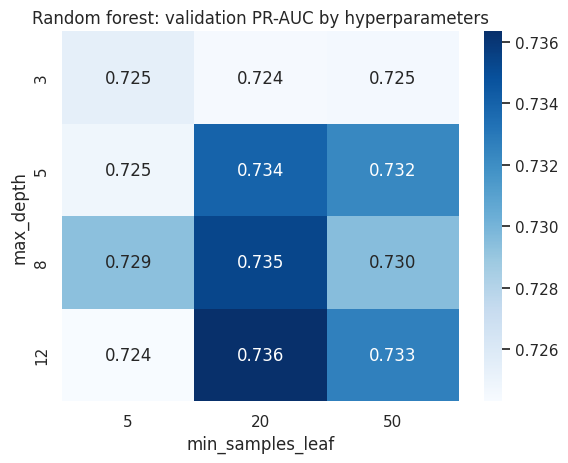

Selected {'max_depth': 12, 'min_samples_leaf': 20} by validation PR-AUC


In [90]:
rf_build = lambda max_depth, min_samples_leaf: RandomForestClassifier(
    n_estimators=300, max_depth=max_depth, min_samples_leaf=min_samples_leaf, n_jobs=-1, random_state=SEED)

rf_table, rf_params, rf_best = tune(rf_build, {'max_depth': [3, 5, 8, 12], 'min_samples_leaf': [5, 20, 50]}, 'raw')
NAME_RF = add_model(f"Random forest (depth={rf_params['max_depth']}, leaf={rf_params['min_samples_leaf']})",
                    rf_best, 'raw', 'statistical', factory=lambda p=rf_params: rf_build(**p))
display(rf_table.head(6).round(4))
plot_grid_heatmap(rf_table, 'max_depth', 'min_samples_leaf', 'Random forest: validation PR-AUC by hyperparameters')
print('Selected', rf_params, 'by validation PR-AUC')

### Attempt 5: gradient boosting

**How it works (intuition first).** Instead of many independent trees voting at once, boosting builds **small trees one after another**, and each new tree is trained to fix the mistakes the previous ones still make, like a team of reviewers each checking what the last one missed. A **learning rate** controls how much each tree is allowed to change the answer.

**Hyperparameters we tune:** `learning_rate`, `max_depth` (kept small: boosting works best with many *shallow* trees) and `max_iter` (the number of trees). We use scikit-learn's `HistGradientBoostingClassifier`, which bins feature values into histograms and is fast on tabular data like ours.

**Limitations:** more sensitive to hyperparameters than a forest, and with only 6.8k training rows and ~900 podium rows it can overfit if given too many trees or too much depth.

,learning_rate,max_depth,max_iter,train PR-AUC,val PR-AUC,val ROC-AUC,train-val gap
0,0.03,5,100,0.7958,0.7250,0.9277,0.0708
1,0.03,3,100,0.7225,0.7245,0.9334,-0.0020
2,0.03,2,100,0.7034,0.7214,0.9324,-0.0180
3,0.10,2,100,0.7256,0.7149,0.9297,0.0107
4,0.03,2,300,0.7248,0.7078,0.9305,0.0170
5,0.03,5,300,0.8596,0.7037,0.9249,0.1559


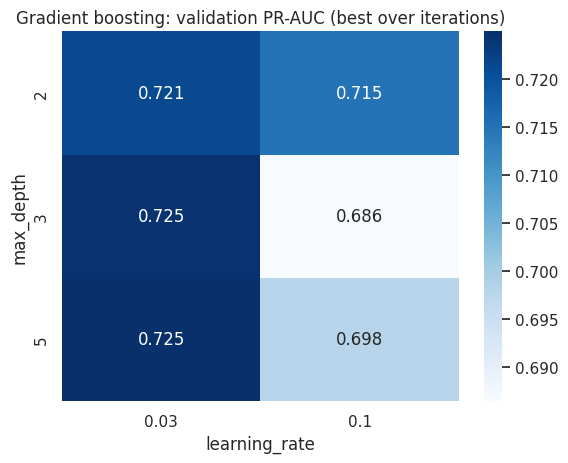

Selected {'learning_rate': 0.03, 'max_depth': 5, 'max_iter': 100} by validation PR-AUC


In [91]:
hgb_build = lambda learning_rate, max_depth, max_iter: HistGradientBoostingClassifier(
    learning_rate=learning_rate, max_depth=max_depth, max_iter=max_iter, random_state=SEED)

hgb_table, hgb_params, hgb_best = tune(hgb_build, {'learning_rate': [0.03, 0.1], 'max_depth': [2, 3, 5],
                                                    'max_iter': [100, 300]}, 'raw')
NAME_HGB = add_model(f"Gradient boosting (lr={hgb_params['learning_rate']}, depth={hgb_params['max_depth']}, "
                     f"iter={hgb_params['max_iter']})", hgb_best, 'raw', 'statistical',
                     factory=lambda p=hgb_params: hgb_build(**p))
display(hgb_table.head(6).round(4))
plot_grid_heatmap(hgb_table, 'max_depth', 'learning_rate', 'Gradient boosting: validation PR-AUC (best over iterations)')
print('Selected', hgb_params, 'by validation PR-AUC')

**Reading the statistical attempts (our results, validation):**

| Attempt | Val PR-AUC | Val ROC-AUC | Val F1 | Verdict |
|---|---|---|---|---|
| 1. LR baseline | 0.7133 | 0.9306 | 0.7064 | reference |
| 2. LR balanced | 0.7070 | 0.9286 | 0.7063 | not better |
| 3. LR tuned (C = 0.1) | 0.7163 | 0.9303 | 0.7064 | tie with baseline |
| 4. Random forest (depth 12, leaf 20) | 0.7363 | 0.9329 | 0.7132 | best statistical model |
| 5. Gradient boosting (lr 0.03, depth 5, 100 trees) | 0.7250 | 0.9277 | 0.6979 | overfits (gap 0.07) |

- **Attempt 2 (balanced weights): hypothesis not supported.** Recall rose (0.71 → 0.76) and precision fell (0.70 → 0.66), but F1 is unchanged (0.706) and the ranking got slightly worse (PR-AUC −0.006). The "recall" gain is just a different operating point on the same ranking, which our validation-chosen threshold already controls. Class weighting adds nothing here.
- **Attempt 3 (regularisation): essentially no effect.** Validation PR-AUC is 0.7163 at C = 0.1 and 0.7133 at C = 1; only the extreme C = 0.001 clearly hurts (0.695, too much shrinkage). The weights are not unstable enough for shrinkage to matter, so the baseline is already well regularised.
- **Attempt 4 (random forest): the best statistical model on validation (+0.023 PR-AUC over the baseline).** Its top six settings lie within 0.007 of each other, so the grid is flat and "depth 12" is not meaningfully better than "depth 5" (0.7340 with no train − validation gap). It is selected by our rule, but the choice among settings is close to a tie.
- **Attempt 5 (gradient boosting): no gain over the forest, and the settings that fit training best overfit.** The selected setting (depth 5) has a train − validation PR-AUC gap of 0.071 and the deeper, longer-trained settings are worse (depth 5 with 300 trees: 0.7037, gap 0.156). The shallower depth-2/3 models reach 0.7214–0.7245 without overfitting. This matches our expectation that boosting is sensitive to its settings with so few training rows.

## 9.6 Shallow neural networks

**How a neural network works (intuition first, Lab 3).** Think of the logistic regression of 9.4 as *one* neuron: weighted evidence → probability. A neural network stacks layers of such neurons. In a **hidden layer**, each neuron forms its own weighted combination of the 12 inputs and passes it through **ReLU** (the "bend": negative evidence is switched off), so the next layer receives *new, learned features* such as "strong grid **and** strong car". The **output neuron** uses a **sigmoid** and returns one podium probability. Training repeatedly (1) predicts, (2) measures the error with **binary cross-entropy**, (3) uses backpropagation to see which weights contributed, and (4) lets the **Adam** optimizer nudge them. One pass over the training rows is an **epoch**.

The brief asks for a **shallow** network (1–2 hidden layers); the lab used three, so ours are smaller.

**Three deliberate differences from the Lab 3 recipe**, each for a reason specific to this project:
1. **Validation = the real 2020–2021 seasons**, passed with `validation_data=`, instead of `validation_split=0.3`. A random 30 % slice would mix races from the same seasons into both sets, which is exactly the leakage the season split avoids.
2. **Early stopping watches validation PR-AUC, not accuracy.** With ~15 % positives accuracy barely moves (the Lab 2 trap). `restore_best_weights=True` keeps the best epoch.
3. **One output neuron + sigmoid + binary cross-entropy**, because this is a binary problem (Lab 3: softmax is for multi-class).

**Three architectures** (all with early stopping, `patience=15`):

| Name | Hidden layers | Hypothesis |
|---|---|---|
| NN-1 | 16 | a single layer of 16 learned features may already be enough for 12 inputs |
| NN-2 | 32 → 16 | a second layer can combine the first layer's features (interactions) |
| NN-3 | 32 → 16 + dropout 0.2 + L2 | same capacity, but regularised against overfitting the 6.8k training rows |

**Variance:** a network starts from random weights, so two runs of the same architecture differ. We train **each architecture with 3 seeds**, report mean ± std, and register the best seed of each.

**Limitations:** needs scaled inputs; results vary with the seed; hard to explain without SHAP/LIME; and a larger model does not guarantee more signal when there are only 12 features.

In [92]:
def build_nn(n_features, hidden=(32, 16), dropout=0.0, l2=0.0, lr=1e-3):
    reg = keras.regularizers.l2(l2) if l2 > 0 else None
    model = keras.Sequential([layers.Input(shape=(n_features,))])
    for units in hidden:
        model.add(layers.Dense(units, activation='relu', kernel_regularizer=reg))
        if dropout > 0:
            model.add(layers.Dropout(dropout))
    model.add(layers.Dense(1, activation='sigmoid'))                       # one neuron, sigmoid: binary problem
    model.compile(optimizer=keras.optimizers.Adam(lr), loss='binary_crossentropy',
                  metrics=[keras.metrics.AUC(name='pr_auc', curve='PR'), keras.metrics.AUC(name='roc_auc')])
    return model

def train_nn(seed, features=None, **arch):
    features = features or FEATURES
    keras.utils.set_random_seed(seed)
    model = build_nn(n_features=len(features), **arch)
    stop = EarlyStopping(monitor='val_pr_auc', mode='max', patience=15, restore_best_weights=True)
    hist = model.fit(Xs['train'][features].values.astype('float32'), ys['train'],
                     validation_data=(Xs['val'][features].values.astype('float32'), ys['val']),
                     epochs=200, batch_size=128, callbacks=[stop], verbose=0)
    return model, hist.history

NN_CANDIDATES = {
    'NN-1 (16)': dict(hidden=(16,)),
    'NN-2 (32-16)': dict(hidden=(32, 16)),
    'NN-3 (32-16, dropout+L2)': dict(hidden=(32, 16), dropout=0.2, l2=1e-4),
}
NN_SEEDS = [42, 43, 44]

nn_runs = {}
for name, arch in NN_CANDIDATES.items():
    runs = []
    for seed in NN_SEEDS:
        model, hist = train_nn(seed, **arch)
        p_val = model.predict(Xs['val'].values.astype('float32'), verbose=0).ravel()
        runs.append({'seed': seed, 'model': model, 'history': hist,
                     'val PR-AUC': average_precision_score(ys['val'], p_val),
                     'val ROC-AUC': roc_auc_score(ys['val'], p_val),
                     'best epoch': int(np.argmax(hist['val_pr_auc']) + 1), 'epochs run': len(hist['loss'])})
    nn_runs[name] = runs

seed_table = pd.DataFrame([{'architecture': n, 'seed': r['seed'], 'val PR-AUC': r['val PR-AUC'], 'val ROC-AUC': r['val ROC-AUC'],
                            'best epoch': r['best epoch'], 'epochs run': r['epochs run']}
                           for n, runs in nn_runs.items() for r in runs])
display(seed_table.round(4))
display(seed_table.groupby('architecture', sort=False)[['val PR-AUC', 'val ROC-AUC', 'best epoch']].agg(['mean', 'std']).round(4))

# register the best seed of every architecture (chosen on validation PR-AUC)
for name, runs in nn_runs.items():
    best_run = max(runs, key=lambda r: r['val PR-AUC'])
    add_model(name, best_run['model'], 'scaled', 'NN')
    NN_ARCH[name] = NN_CANDIDATES[name]
    nn_runs[name] = {'best': best_run, 'all': runs}

2026-10-19 19:51:50.264344: E external/local_xla/xla/stream_executor/cuda/cuda_platform.cc:51] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)
2026-10-19 19:51:50.687009: E tensorflow/core/framework/node_def_util.cc:680] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_15}}
2026-10-19 19:52:07.916033: E tensorflow/core/framework/node_def_util.cc:680] NodeDef mentions attribute use_un

,architecture,seed,val PR-AUC,val ROC-AUC,best epoch,epochs run
0,NN-1 (16),42,0.7297,0.9275,41,56
1,NN-1 (16),43,0.7105,0.9235,43,58
2,NN-1 (16),44,0.7323,0.9237,38,53
3,NN-2 (32-16),42,0.7479,0.9288,27,42
4,NN-2 (32-16),43,0.7243,0.9157,6,21
5,NN-2 (32-16),44,0.7331,0.9250,22,37
6,"NN-3 (32-16, dropout+L2)",42,0.7356,0.9293,48,63
7,"NN-3 (32-16, dropout+L2)",43,0.7154,0.9282,23,38
8,"NN-3 (32-16, dropout+L2)",44,0.7270,0.9176,8,23


val PR-AUC         val ROC-AUC         best epoch         
                               mean     std        mean     std       mean      std
architecture                                                                       
NN-1 (16)                    0.7242  0.0119      0.9249  0.0023    40.6667   2.5166
NN-2 (32-16)                 0.7351  0.0120      0.9232  0.0068    18.3333  10.9697
NN-3 (32-16, dropout+L2)     0.7260  0.0101      0.9250  0.0065    26.3333  20.2073

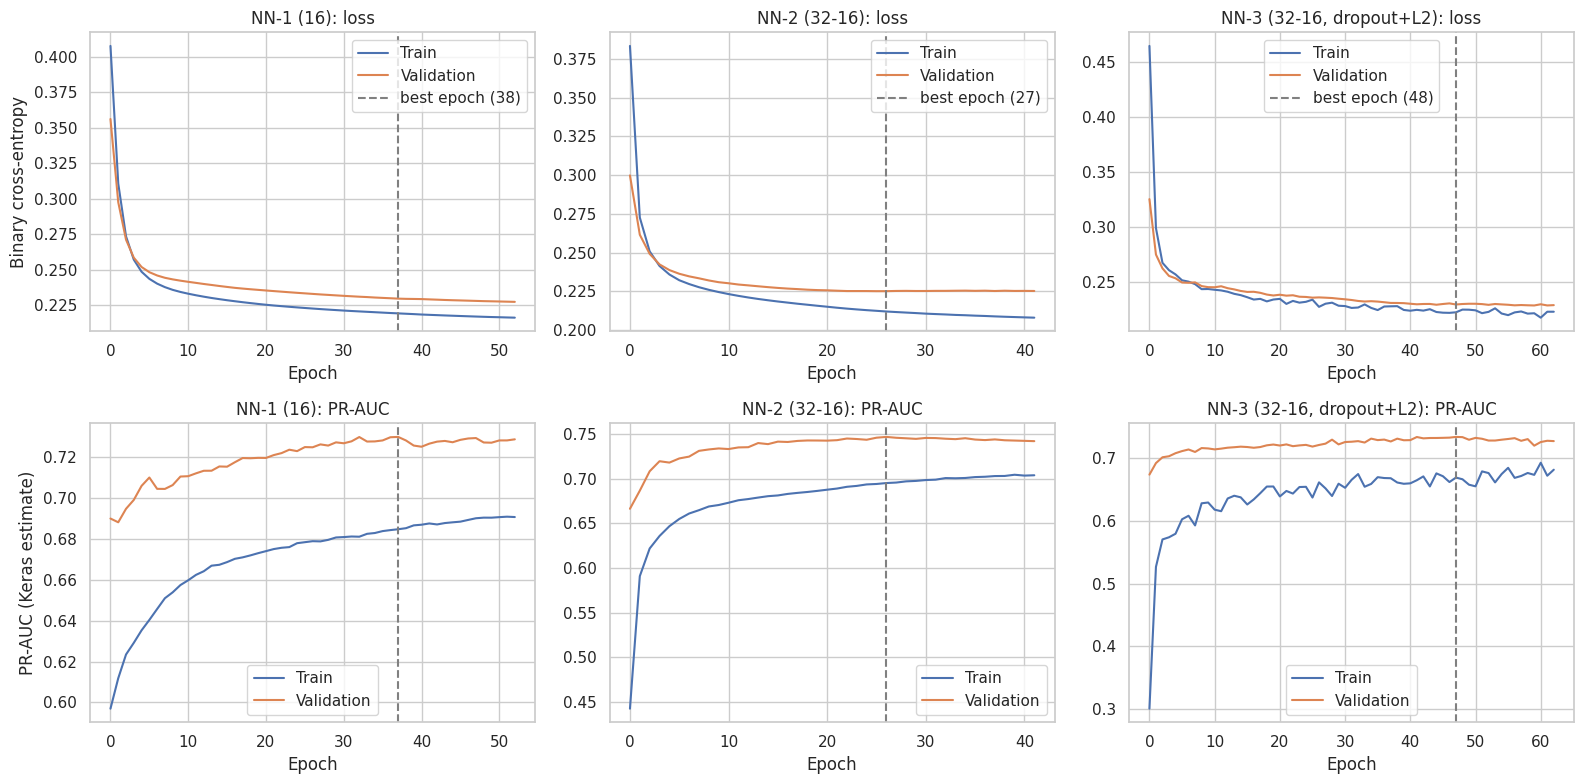

In [93]:
# Training curves of the best seed of each architecture (Lab 3 style: train vs validation)
fig, axes = plt.subplots(2, 3, figsize=(16, 8))
for j, (name, d) in enumerate(nn_runs.items()):
    h, best_ep = d['best']['history'], d['best']['best epoch']
    axes[0, j].plot(h['loss'], label='Train')
    axes[0, j].plot(h['val_loss'], label='Validation')
    axes[0, j].axvline(best_ep - 1, color='grey', linestyle='--', label=f'best epoch ({best_ep})')
    axes[0, j].set_title(f'{name}: loss')
    axes[1, j].plot(h['pr_auc'], label='Train')
    axes[1, j].plot(h['val_pr_auc'], label='Validation')
    axes[1, j].axvline(best_ep - 1, color='grey', linestyle='--')
    axes[1, j].set_title(f'{name}: PR-AUC')
    for ax in axes[:, j]:
        ax.set_xlabel('Epoch')
    axes[0, j].legend()
    axes[1, j].legend()
axes[0, 0].set_ylabel('Binary cross-entropy')
axes[1, 0].set_ylabel('PR-AUC (Keras estimate)')
plt.tight_layout()
plt.show()

**How to read the curves:** the training curve keeps improving as the network memorises the training seasons; the validation curve improves, flattens, and then stalls or turns back. The dashed line marks the epoch where validation PR-AUC peaked, and early stopping returns the weights from *that* epoch, not from the end of training. A wide, growing gap between the two curves is overfitting; NN-3 (dropout + L2) should show a smaller one than NN-2 if regularisation helps. Keras estimates PR-AUC with a fixed grid of thresholds, so the numbers in the table above (computed with scikit-learn on the final probabilities) differ slightly; the table is the one we use.

**Reading the seed table (our results):**
- **Architecture matters less than the seed.** Mean validation PR-AUC is 0.724 (NN-1), 0.735 (NN-2) and 0.726 (NN-3), a spread of 0.011, while the *same* architecture varies by 0.020–0.024 between seeds (e.g. NN-2: 0.724 to 0.748). The three architectures are therefore ties, and our hypotheses "a second layer helps" and "dropout + L2 helps" are **not supported** by a difference larger than the noise.
- **NN-1 is the most stable:** its ROC-AUC varies least between seeds (std 0.002, against about 0.007 for NN-2 and NN-3) and its best epoch is consistent (38–43). Dropout + L2 (NN-3) did not make training more stable here.
- **Early stopping sometimes reacted to noise:** NN-2 seed 43 peaked at epoch 6 and NN-3 seed 44 at epoch 8, so with only 117 validation podiums a small fluctuation can end training early.
- **We register the best seed of each architecture, chosen on validation.** For NN-2 that is seed 42 (0.748), which is 0.013 above the architecture's mean (0.735). Picking the best of three seeds on a 117-podium validation set builds in a small upward bias, which matters when we read the test result in 9.8.

*Note: the networks are trained with fixed seeds and deterministic operations (9.0), so a Run All on the same hardware reproduces these numbers. On different hardware or library versions they can shift by about ±0.01; the conclusions do not depend on the third decimal.*

## 9.7 Model comparison on training and validation, and choosing the finalists

All models are now scored in the same way. **Selection rule (fixed before looking at test):** within each family, the model with the **highest validation PR-AUC** is the finalist. We then compare finalists with the baseline and the grid rule. Because validation holds only ~117 podium rows, differences smaller than the seed-to-seed spread of the neural networks (table in 9.6) are **reported as ties**: they do not change the finalists (the rule above is applied as written), but they limit how strongly we read the validation ranking.

In [94]:
ALL = list(registry)
comp = metrics_table(ALL, ['train', 'val'])
val_tab = comp[comp.split == 'val'].set_index('model').drop(columns='split').reindex(ALL)
tr_tab = comp[comp.split == 'train'].set_index('model').drop(columns='split').reindex(ALL)
val_tab['Δ PR-AUC vs LR baseline'] = val_tab['PR-AUC'] - val_tab.loc[NAME_BASE, 'PR-AUC']
val_tab['train-val PR-AUC gap'] = tr_tab['PR-AUC'] - val_tab['PR-AUC']

print('VALIDATION (2020-2021)')
display(val_tab.round(4))
print('TRAINING (2003-2019)')
display(tr_tab.round(4))

stat_names = [n for n in ALL if registry[n]['family'] == 'statistical']
nn_names = [n for n in ALL if registry[n]['family'] == 'NN']
best_stat = val_tab.loc[stat_names, 'PR-AUC'].idxmax()
best_nn = val_tab.loc[nn_names, 'PR-AUC'].idxmax()
FINALISTS = list(dict.fromkeys([NAME_RULE, NAME_BASE, best_stat, best_nn]))

nn_std = seed_table.groupby('architecture')['val PR-AUC'].std().max()
print(f'Best statistical model : {best_stat}  (val PR-AUC {val_tab.loc[best_stat, "PR-AUC"]:.4f})')
print(f'Best neural network    : {best_nn}  (val PR-AUC {val_tab.loc[best_nn, "PR-AUC"]:.4f})')
print(f'Largest seed-to-seed std of the NNs (val PR-AUC): {nn_std:.4f}; differences below this are ties.')
print('Finalists:', FINALISTS)

VALIDATION (2020-2021)


2026-10-19 19:54:08.559402: E tensorflow/core/framework/node_def_util.cc:680] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_14}}


,threshold,ROC-AUC,PR-AUC,F1,Precision,Recall,Top-3 hit rate,Δ PR-AUC vs LR baseline,train-val PR-AUC gap
model,,,,,,,,,
Rule: grid only,0.3333,0.9092,0.6386,0.6923,0.6923,0.6923,0.6923,-0.0747,-0.0128
LR baseline,0.3491,0.9306,0.7133,0.7064,0.7034,0.7094,0.6923,0.0000,-0.0296
LR balanced,0.6428,0.9286,0.7070,0.7063,0.6593,0.7607,0.6923,-0.0063,-0.0350
LR tuned (C=0.1),0.3672,0.9303,0.7163,0.7064,0.7034,0.7094,0.6923,0.0030,-0.0363
"Random forest (depth=12, leaf=20)",0.2111,0.9329,0.7363,0.7132,0.6258,0.8291,0.7009,0.0230,0.0367
"Gradient boosting (lr=0.03, depth=5, iter=100)",0.3639,0.9277,0.7250,0.6979,0.6949,0.7009,0.6923,0.0117,0.0708
NN-1 (16),0.4264,0.9237,0.7323,0.7124,0.7155,0.7094,0.6923,0.0190,-0.0432
NN-2 (32-16),0.3099,0.9288,0.7479,0.7073,0.6744,0.7436,0.6838,0.0346,-0.0453
"NN-3 (32-16, dropout+L2)",0.3724,0.9293,0.7356,0.7227,0.7107,0.7350,0.6838,0.0223,-0.0373


TRAINING (2003-2019)


,threshold,ROC-AUC,PR-AUC,F1,Precision,Recall,Top-3 hit rate
model,,,,,,,
Rule: grid only,0.3333,0.9085,0.6258,0.6462,0.6466,0.6459,0.6469
LR baseline,0.3491,0.9278,0.6837,0.6730,0.6160,0.7414,0.6511
LR balanced,0.6428,0.9278,0.6720,0.6519,0.5399,0.8224,0.6345
LR tuned (C=0.1),0.3672,0.9277,0.6800,0.6641,0.6219,0.7124,0.6511
"Random forest (depth=12, leaf=20)",0.2111,0.9556,0.7730,0.6847,0.5548,0.8941,0.6885
"Gradient boosting (lr=0.03, depth=5, iter=100)",0.3639,0.9609,0.7958,0.7356,0.6881,0.7902,0.7124
NN-1 (16),0.4264,0.9327,0.6891,0.6600,0.6347,0.6874,0.6469
NN-2 (32-16),0.3099,0.9383,0.7027,0.6854,0.5935,0.8110,0.6646
"NN-3 (32-16, dropout+L2)",0.3724,0.9377,0.6983,0.6747,0.6113,0.7529,0.6646


Best statistical model : Random forest (depth=12, leaf=20)  (val PR-AUC 0.7363)
Best neural network    : NN-2 (32-16)  (val PR-AUC 0.7479)
Largest seed-to-seed std of the NNs (val PR-AUC): 0.0120; differences below this are ties.
Finalists: ['Rule: grid only', 'LR baseline', 'Random forest (depth=12, leaf=20)', 'NN-2 (32-16)']


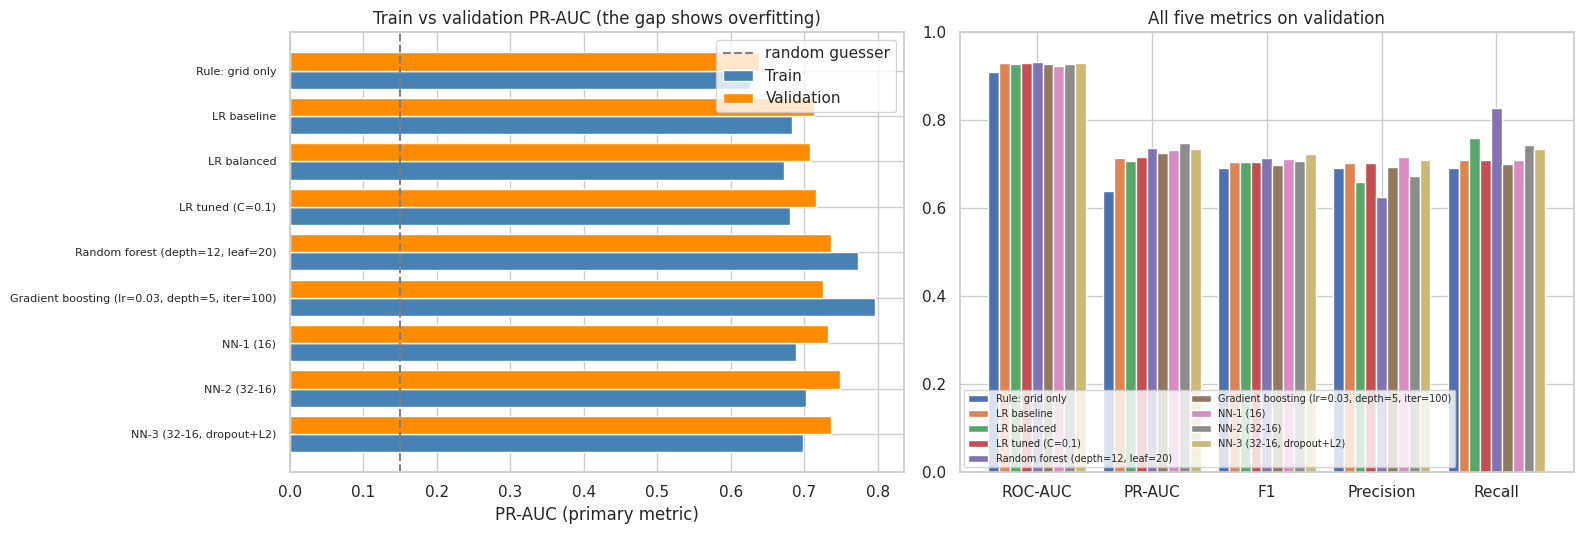

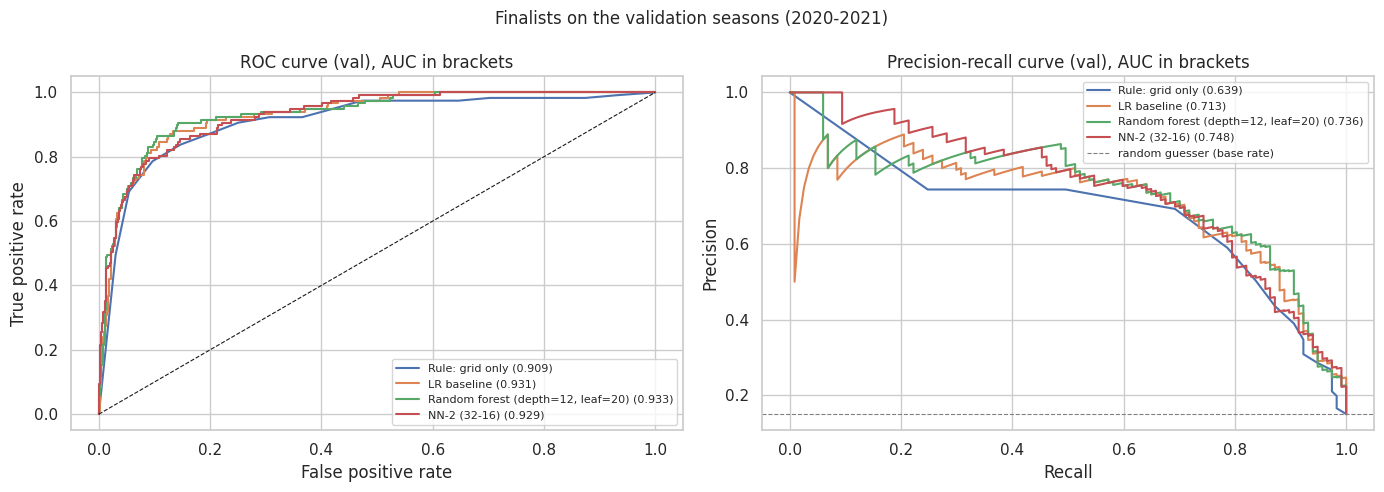

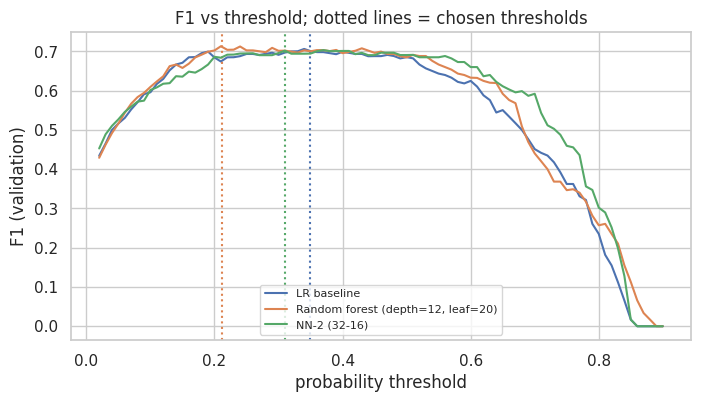

In [95]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5.5))
y_pos = np.arange(len(ALL))
axes[0].barh(y_pos + 0.2, tr_tab['PR-AUC'], height=0.4, color='steelblue', label='Train')
axes[0].barh(y_pos - 0.2, val_tab['PR-AUC'], height=0.4, color='darkorange', label='Validation')
axes[0].axvline(ys['val'].mean(), color='grey', linestyle='--', label='random guesser')
axes[0].set_yticks(y_pos)
axes[0].set_yticklabels(ALL, fontsize=8)
axes[0].invert_yaxis()
axes[0].set_xlabel('PR-AUC (primary metric)')
axes[0].set_title('Train vs validation PR-AUC (the gap shows overfitting)')
axes[0].legend()

val_tab[['ROC-AUC', 'PR-AUC', 'F1', 'Precision', 'Recall']].T.plot(kind='bar', ax=axes[1], width=0.85, legend=False)
axes[1].set_title('All five metrics on validation')
axes[1].set_ylim(0, 1)
axes[1].tick_params(axis='x', rotation=0)
axes[1].legend(ALL, fontsize=7, loc='lower left', ncol=2)
plt.tight_layout()
plt.show()

plot_curves(FINALISTS, 'val', 'Finalists on the validation seasons (2020-2021)')

# F1 against threshold: why the threshold is not 0.5 (validation only)
grid_t = np.linspace(0.02, 0.9, 89)
plt.figure(figsize=(8, 4))
for n in FINALISTS[1:]:
    p = get_proba(n, 'val')
    plt.plot(grid_t, [f1_score(ys['val'], (p >= t).astype(int)) for t in grid_t], label=n)
    plt.axvline(thresholds[n], linestyle=':', color=plt.gca().lines[-1].get_color())
plt.xlabel('probability threshold')
plt.ylabel('F1 (validation)')
plt.title('F1 vs threshold; dotted lines = chosen thresholds')
plt.legend(fontsize=8)
plt.show()

**How to read this:**
- **Left plot:** each model has two bars. If the orange (validation) bar is much shorter than the blue (training) bar, the model memorised the training seasons. Models whose bars are close generalise better. Part of any gap is expected, because validation (2020–21) is a different era from training.
- **Right plot / table:** compare *all five* metrics. ROC-AUC is bunched high for every model, while PR-AUC, F1 and top-3 hit rate separate them, which is why PR-AUC is primary (9.2).
- **Curves:** the model whose precision-recall curve stays highest as recall increases is the best at keeping false alarms low while still finding the podium finishers. All learned models should sit well above the grey "random guesser" line.
- **F1 vs threshold:** F1 peaks at a threshold far from 0.5 and is fairly flat around its peak. That flatness is reassuring: the exact chosen value matters less than being in the right region.

**Reading (our results, 9.7):**
- **Finalists (fixed by the rule above):** random forest (depth 12, leaf 20) and NN-2 (32-16), plus the LR baseline and the grid rule as references.
- **Every learned model beats the grid-only rule on PR-AUC**, by 0.07 (LR) to 0.11 (NN-2). Nothing is learned for free from the grid alone.
- **The learned models are close to each other.** Validation PR-AUC lies between 0.707 and 0.748 for all eight learned models, and the NN seed-to-seed std is 0.012. Only NN-2 (+0.035 over the baseline) and the forest (+0.023) clear that noise level, and each is the *winner of several candidates* chosen on 117 podium rows, which inflates its validation score. We therefore treat "NN-2 > forest > baseline" as a hypothesis for the test set, not a conclusion.
- **Overfitting (left plot, gap table).** The grid rule's gap is −0.013, so a gap of about −0.013 is what the easier validation seasons give *for free*. Measured against that, the random forest (+0.037) and the selected boosting model (+0.071) fit the training seasons clearly better than validation, while logistic regression and the networks do not. The trees' much higher *training* PR-AUC (0.77 and 0.80 vs 0.68–0.70 for LR / NN) shows they extract extra structure from 2003–2019; the open question is whether it transfers to a new era (9.8).
- **ROC-AUC barely separates the models** (0.924–0.933 for every learned model, 0.909 for the rule), exactly the reason PR-AUC is our primary metric (9.2).
- **F1 and top-3 hit rate do not separate them either.** Validation F1 is 0.698–0.723 for the learned models, and the top-3 hit rate is 0.684–0.701 versus 0.692 for the grid rule. The models rank the *whole field* better than the rule (PR-AUC) but are no better at naming the three drivers of a race.
- **Operating points differ a lot at similar F1:** the forest's validation threshold (0.21) flags more drivers (recall 0.83, precision 0.63) than the logistic regression's (0.35: recall 0.71, precision 0.70).

## 9.8 Unseen test seasons (2022–2024)

Selection is done. We now score **only the finalists**, once, on the test seasons, using the thresholds fixed on validation. Scoring every model on test would invite choosing a winner on it, which is exactly what the brief forbids.

**What to expect:** a drop from validation to test is normal and informative. 2022–2024 is a new technical era with a closer field and more reliable cars (8.6), so a model that held up here is not just memorising 2003–2019.

TEST (2022-2024), thresholds fixed on validation


,threshold,ROC-AUC,PR-AUC,F1,Precision,Recall,Top-3 hit rate
model,,,,,,,
Rule: grid only,0.3333,0.9136,0.6473,0.6486,0.6502,0.6471,0.6520
LR baseline,0.3491,0.9363,0.7152,0.6744,0.6376,0.7157,0.6618
"Random forest (depth=12, leaf=20)",0.2111,0.9363,0.7102,0.6559,0.5185,0.8922,0.6618
NN-2 (32-16),0.3099,0.9339,0.6959,0.6570,0.5679,0.7794,0.6422


Change from validation to test (test - validation)


,ROC-AUC,PR-AUC,F1,Top-3 hit rate
model,,,,
Rule: grid only,0.0044,0.0087,-0.0437,-0.0403
LR baseline,0.0056,0.0019,-0.0320,-0.0305
"Random forest (depth=12, leaf=20)",0.0034,-0.0261,-0.0574,-0.0391
NN-2 (32-16),0.0051,-0.0521,-0.0503,-0.0416


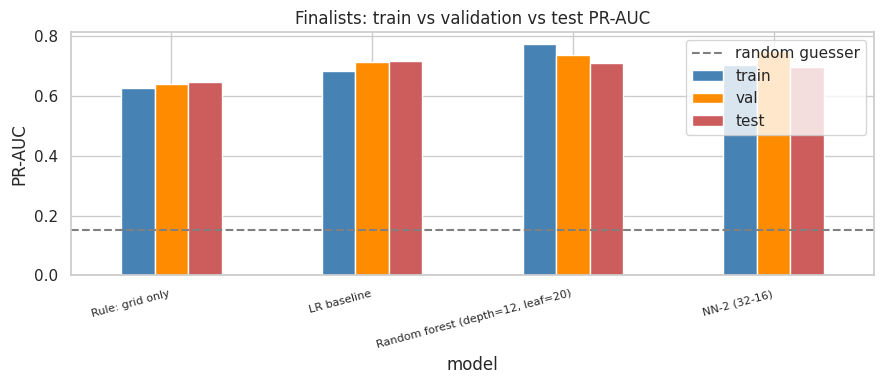

2026-10-19 19:54:13.832820: E tensorflow/core/framework/node_def_util.cc:680] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_14}}


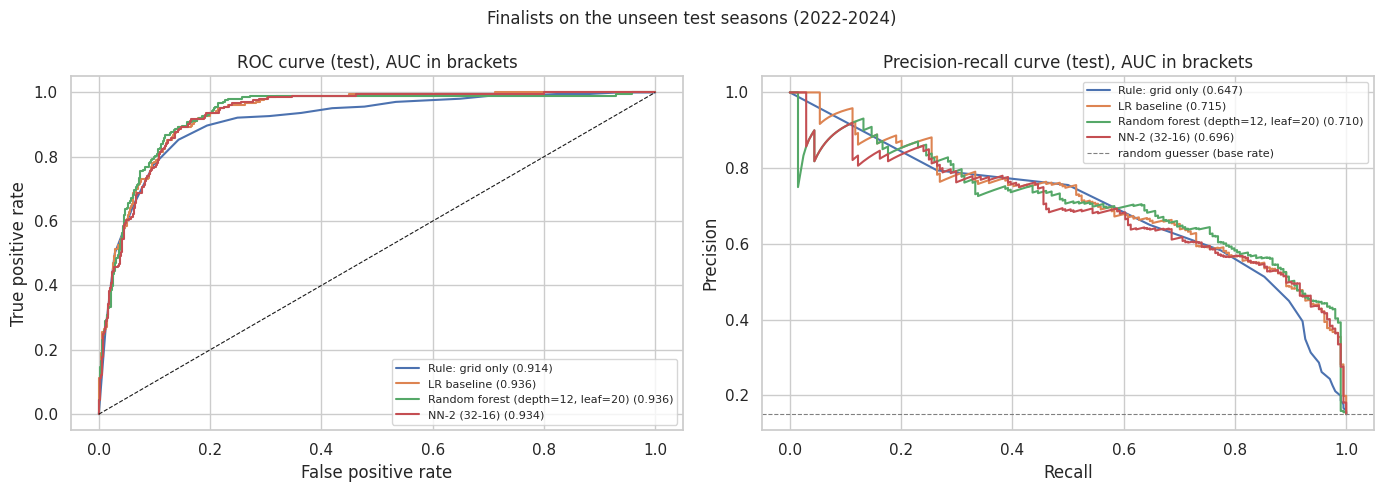

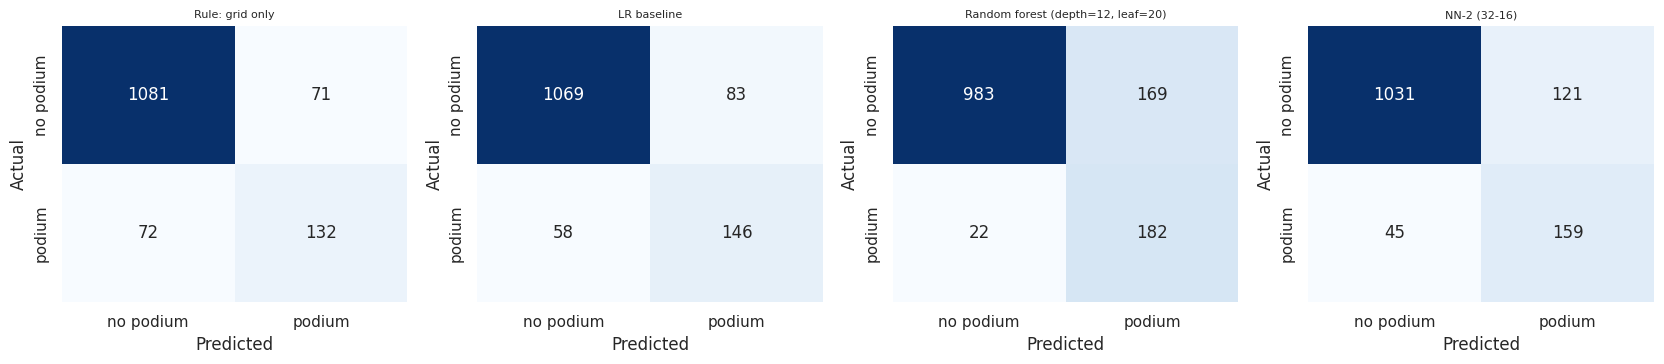

Rule (grid only) test PR-AUC : 0.6473
LR baseline test PR-AUC      : 0.7152
Random forest (depth=12, leaf=20): test PR-AUC 0.7102 (-0.0050 vs baseline), test F1 0.6559, top-3 hit rate 0.6618
NN-2 (32-16): test PR-AUC 0.6959 (-0.0194 vs baseline), test F1 0.6570, top-3 hit rate 0.6422
Highest test PR-AUC among the learned finalists: LR baseline


In [96]:
final = metrics_table(FINALISTS, ['train', 'val', 'test'])
test_tab = final[final.split == 'test'].set_index('model').drop(columns='split')
print('TEST (2022-2024), thresholds fixed on validation')
display(test_tab.round(4))

cols = ['ROC-AUC', 'PR-AUC', 'F1', 'Top-3 hit rate']
delta = test_tab[cols] - val_tab.loc[FINALISTS, cols]
print('Change from validation to test (test - validation)')
display(delta.round(4))

# Train / validation / test PR-AUC side by side
pr_by_split = final.pivot(index='model', columns='split', values='PR-AUC').reindex(FINALISTS)[['train', 'val', 'test']]
pr_by_split.plot(kind='bar', figsize=(9, 4), color=['steelblue', 'darkorange', 'indianred'])
plt.axhline(ys['test'].mean(), color='grey', linestyle='--', label='random guesser')
plt.ylabel('PR-AUC')
plt.title('Finalists: train vs validation vs test PR-AUC')
plt.xticks(rotation=15, ha='right', fontsize=8)
plt.legend()
plt.tight_layout()
plt.show()

plot_curves(FINALISTS, 'test', 'Finalists on the unseen test seasons (2022-2024)')

# Confusion matrices at the validation-chosen thresholds (Lab 2 style)
fig, axes = plt.subplots(1, len(FINALISTS), figsize=(4.2 * len(FINALISTS), 3.8))
for ax, n in zip(np.atleast_1d(axes), FINALISTS):
    pred = (get_proba(n, 'test') >= thresholds[n]).astype(int)
    sns.heatmap(confusion_matrix(ys['test'], pred), annot=True, fmt='d', cmap='Blues', ax=ax, cbar=False,
                xticklabels=['no podium', 'podium'], yticklabels=['no podium', 'podium'])
    ax.set_xlabel('Predicted')
    ax.set_ylabel('Actual')
    ax.set_title(n, fontsize=8)
plt.tight_layout()
plt.show()

# Automatic reading of the result
model_names = [n for n in FINALISTS if n != NAME_RULE]
best_test = test_tab.loc[model_names, 'PR-AUC'].idxmax()
print(f"Rule (grid only) test PR-AUC : {test_tab.loc[NAME_RULE, 'PR-AUC']:.4f}")
print(f"LR baseline test PR-AUC      : {test_tab.loc[NAME_BASE, 'PR-AUC']:.4f}")
for n in [best_stat, best_nn]:
    print(f"{n}: test PR-AUC {test_tab.loc[n, 'PR-AUC']:.4f} "
          f"({test_tab.loc[n, 'PR-AUC'] - test_tab.loc[NAME_BASE, 'PR-AUC']:+.4f} vs baseline), "
          f"test F1 {test_tab.loc[n, 'F1']:.4f}, top-3 hit rate {test_tab.loc[n, 'Top-3 hit rate']:.4f}")
print('Highest test PR-AUC among the learned finalists:', best_test)

**How to read this:**
- **Test table:** the honest score. Compare it with the validation table (9.7) using the *change* table: it shows how much each model lost (or gained) on a new era. The model whose score drops least is the most robust one, which may not be the one that scored highest on validation.
- **Versus the baseline:** the question for the "justify your model against the baseline" requirement is whether the finalists beat `LR baseline` on test by more than the noise level (about 0.01–0.02 PR-AUC with ~200 podium rows in test). If they do not, the honest conclusion is that the extra complexity did **not** earn its place and the simple model is preferable, and we say so in the report.
- **Versus the grid rule:** the gap to `Rule: grid only` shows how much the form, standings and qualifying-gap features add on top of the starting position.
- **Confusion matrices:** the top-left cell is correctly rejected drivers, the bottom-right is correctly found podium finishers; the off-diagonal cells are the two kinds of mistakes (precision is hurt by the top-right, recall by the bottom-left).
- **Top-3 hit rate:** read it as "out of the three drivers the model names for each race, how many really stood on the podium".
- The model choice stays as decided in 9.7, even if another finalist happens to score higher on test.

**Reading (our results, 9.8: unseen test seasons 2022–2024):**

| Model | Test PR-AUC | Test ROC-AUC | Test F1 | Test top-3 hit rate | Δ PR-AUC val → test |
|---|---|---|---|---|---|
| Rule: grid only | 0.647 | 0.914 | 0.649 | 0.652 | +0.009 |
| LR baseline | **0.715** | 0.936 | **0.674** | 0.662 | +0.002 |
| Random forest | 0.710 | 0.936 | 0.656 | 0.662 | −0.026 |
| NN-2 (32-16) | 0.696 | 0.934 | 0.657 | 0.642 | −0.052 |

- **The more complex models did not beat the baseline on unseen seasons.** The random forest is 0.005 below the logistic regression (a tie at our noise level of 0.01–0.02) and NN-2 is 0.019 below it. What looked like a +0.023 / +0.035 advantage on validation did not carry over. Consistent with the 9.7 warning, the validation ranking of the winners was partly noise from a small validation set and from choosing the best of several candidates (for NN-2, also the best of three seeds), and probably partly era drift (below).
- **Answer to "does the added complexity earn its place?": on our evidence, no.** The simplest model, logistic regression, has the best test PR-AUC and the best test F1, and it is the most stable between validation and test. We report this as is. The finalists stay as chosen in 9.7; we did not re-select on test.
- **All learned models still clearly beat the grid-only rule on PR-AUC** (+0.049 to +0.068 on test), so the 12 features do add information beyond the starting position.
- **ROC-AUC is the same for all learned models** (0.934–0.936). It again cannot tell them apart.
- **F1 and top-3 hit rate fell for every model, including the rule** (F1 −0.03 to −0.06, top-3 −0.03 to −0.04). The rule has nothing to overfit, so a part of this drop comes from the test seasons themselves (grid position converted less often into the top 3), not from the models. The *extra* PR-AUC loss of the forest (−0.026) and the network (−0.052), while the rule and the logistic regression did not lose, is what points to the flexible models not transferring to the new era.
- **Operating point:** the forest's validation threshold (0.21) makes it flag many drivers on test (recall 0.89, precision 0.52, roughly five drivers per race instead of three), which lowers its F1. The logistic regression flags about 1.1× the true number of podium finishers (recall 0.72, precision 0.64).
- **Top-3 hit rate:** the best models name about 2 of the 3 podium finishers per race (0.66), and are only about 0.01 better than "take the first three on the grid" (0.652). The gain of the models is in ordering the rest of the field, not in finding the top three.

*Caveats:* test has only about 200 podium rows, so differences below about 0.01–0.02 should not be interpreted; the NN-2 test score is for a single seed (the best on validation); and NN scores can shift slightly when re-run.

## 9.9 Limitations of our models and evaluation

**Of the models**
- **Logistic regression:** additive and linear on the log-odds scale; cannot represent interactions or the non-monotonic `grid_minus_quali` pattern without extra features; individual weights are unreliable because several features are strongly correlated.
- **Random forest / gradient boosting:** cannot extrapolate beyond the feature ranges seen in training (e.g. a DNF rate lower than any seen before); probabilities are coarse; boosting is sensitive to its hyperparameters with so few training rows.
- **Neural networks:** results depend on the random seed (hence 3 seeds); need scaled inputs; hardest to explain; no evidence that extra capacity helps with only 12 features.

**Of the evaluation**
- **Era shift:** training is 2003–2019 but the test is 2022–2024 under new regulations. The scaler, medians and the model all reflect the old era (8.6 showed shifted means, especially DNF rate). Scores on test mix "how good is the model" with "how different is the era".
- **Small validation set:** 2020–2021 (≈117 podium rows, one COVID-shortened season). Hyperparameters, early-stopping epoch, threshold and finalist choice all rest on it, so they carry noise. Validation F1 is also optimistic because the threshold was tuned on it.
- **Rows are not independent:** each race has exactly three podium finishers and teammates share a car. Our models score each driver separately and do not enforce "exactly 3 per race" (the top-3 hit rate approximates it).
- **Training window:** we train on 2003+ because qualifying data is complete only from then (4.6), which discards 1950–2002 for fitting (they still feed the form features).
- **Cold start:** at the start of a season or for a debut driver / new constructor, form features are 0 or median-filled and carry little information.
- **Not causal:** a model relying on a feature shows correlation with podiums, not that the feature *causes* them. This matters most for the XAI section.

## 9.10 Experiment: feature-group ablation

**Intuition.** Section 8 grouped the 12 features into five kinds of evidence. Ablation asks: *if the model were not given this evidence, how much worse would it get?* We remove one group at a time, **retrain from scratch**, and measure the drop in validation PR-AUC. The bigger the drop, the more the model relied on that group.

Because the groups overlap (grid ↔ qualifying 0.97; driver form ↔ standings ↔ constructor form 0.8–0.9), one view alone can mislead, so we look at two:
- **"Without group"** (drop-one): if another group carries the same information, the drop is small even for an important group, which means the group is *redundant*, not useless.
- **"Only group"** (keep-one): the score reachable from that group alone, which shows how much each kind of evidence can do by itself.

| Group | Features |
|---|---|
| grid | `grid_clean`, `pit_lane_start` |
| qualifying | `quali_position`, `q1_gap_pct`, `grid_minus_quali` |
| driver form | `drv_podium_rate`, `drv_finish_rel` |
| constructor form | `con_podium_rate`, `con_finish_rel`, `con_dnf_rate` |
| standings | `drv_points_frac`, `con_points_frac` |

We run it for three models: the baseline logistic regression, the best statistical model and the best neural network, each with its selected hyperparameters (the neural network averages 2 seeds). Decisions use **validation** scores; test PR-AUC is listed for reporting only.

In [97]:
FEATURE_GROUPS = {
    'grid': ['grid_clean', 'pit_lane_start'],
    'qualifying': ['quali_position', 'q1_gap_pct', 'grid_minus_quali'],
    'driver form': ['drv_podium_rate', 'drv_finish_rel'],
    'constructor form': ['con_podium_rate', 'con_finish_rel', 'con_dnf_rate'],
    'standings': ['drv_points_frac', 'con_points_frac'],
}
assert sorted(sum(FEATURE_GROUPS.values(), [])) == sorted(FEATURES), 'groups must cover the 12 features exactly once'

ABLATION_MODELS = list(dict.fromkeys([NAME_BASE, best_stat, best_nn]))
ABL_SEEDS = NN_SEEDS[:2]

def fit_and_score(name, features, seed):
    e = registry[name]
    if e['family'] == 'NN':
        model, _ = train_nn(seed, features=features, **NN_ARCH[name])
        predict = lambda split: model.predict(Xs[split][features].values.astype('float32'), verbose=0).ravel()
    else:
        X = Xs if e['inputs'] == 'scaled' else Xr
        model = FACTORY[name]().fit(X['train'][features], ys['train'])
        predict = lambda split: model.predict_proba(X[split][features])[:, 1]
    p_val, p_test = predict('val'), predict('test')
    return {'val PR-AUC': average_precision_score(ys['val'], p_val), 'val ROC-AUC': roc_auc_score(ys['val'], p_val),
            'test PR-AUC (report only)': average_precision_score(ys['test'], p_test)}

configs = {'all features': FEATURES}
configs.update({f'without {g}': [c for c in FEATURES if c not in cols] for g, cols in FEATURE_GROUPS.items()})
configs.update({f'only {g}': cols for g, cols in FEATURE_GROUPS.items()})

ablation = {}
for name in ABLATION_MODELS:
    seeds = ABL_SEEDS if registry[name]['family'] == 'NN' else [SEED]
    ablation[name] = pd.DataFrame({cfg: pd.DataFrame([fit_and_score(name, feats, s) for s in seeds]).mean()
                                   for cfg, feats in configs.items()}).T
    print('Done:', name)

display(pd.concat(ablation, names=['model', 'features used']).round(4))

Done: LR baseline
Done: Random forest (depth=12, leaf=20)


2026-10-19 19:54:34.887132: E tensorflow/core/framework/node_def_util.cc:680] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_15}}
2026-10-19 19:54:48.695961: E tensorflow/core/framework/node_def_util.cc:680] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),

Done: NN-2 (32-16)


val PR-AUC  val ROC-AUC  test PR-AUC (report only)
model                             features used                                                               
LR baseline                       all features                  0.7133       0.9306                     0.7152
                                  without grid                  0.7126       0.9303                     0.7150
                                  without qualifying            0.7044       0.9274                     0.7122
                                  without driver form           0.7235       0.9297                     0.7198
                                  without constructor form      0.7219       0.9294                     0.7128
                                  without standings             0.7118       0.9301                     0.7145
                                  only grid                     0.6386       0.9093                     0.6473
                                  only qualifying               0.6866       0.9195                     0.6837
                                  only driver form              0.6338       0.8969                     0.5625
                                  only constructor form         0.5767       0.8943                     0.5275
                                  only standings                0.6149       0.8552                     0.5535
Random forest (depth=12, leaf=20) all features                  0.7363       0.9329                     0.7102
                                  without grid                  0.7326       0.9310                     0.7030
                                  without qualifying            0.7231       0.9294                     0.6928
                                  without driver form           0.7366       0.9274                     0.7235
                                  without constructor form      0.7217       0.9317                     0.7059
                                  without standings             0.7301       0.9333                     0.7103
                                  only grid                     0.6387       0.9100                     0.6462
                                  only qualifying               0.6893       0.9192                     0.6867
                                  only driver form              0.6186       0.8903                     0.5126
                                  only constructor form         0.5847       0.8852                     0.4967
                                  only standings                0.5969       0.8578                     0.5500
NN-2 (32-16)                      all features                  0.7361       0.9223                     0.6817
                                  without grid                  0.7283       0.9290                     0.7058
                                  without qualifying            0.7275       0.9289                     0.7068
                                  without driver form           0.7299       0.9285                     0.6972
                                  without constructor form      0.7317       0.9299                     0.7085
                                  without standings             0.7259       0.9250                     0.6839
                                  only grid                     0.6405       0.9093                     0.6483
                                  only qualifying               0.6873       0.9182                     0.6811
                                  only driver form              0.6284       0.8871                     0.5491
                                  only constructor form         0.5791       0.8887                     0.5020
                                  only standings                0.6238       0.8557                     0.5606

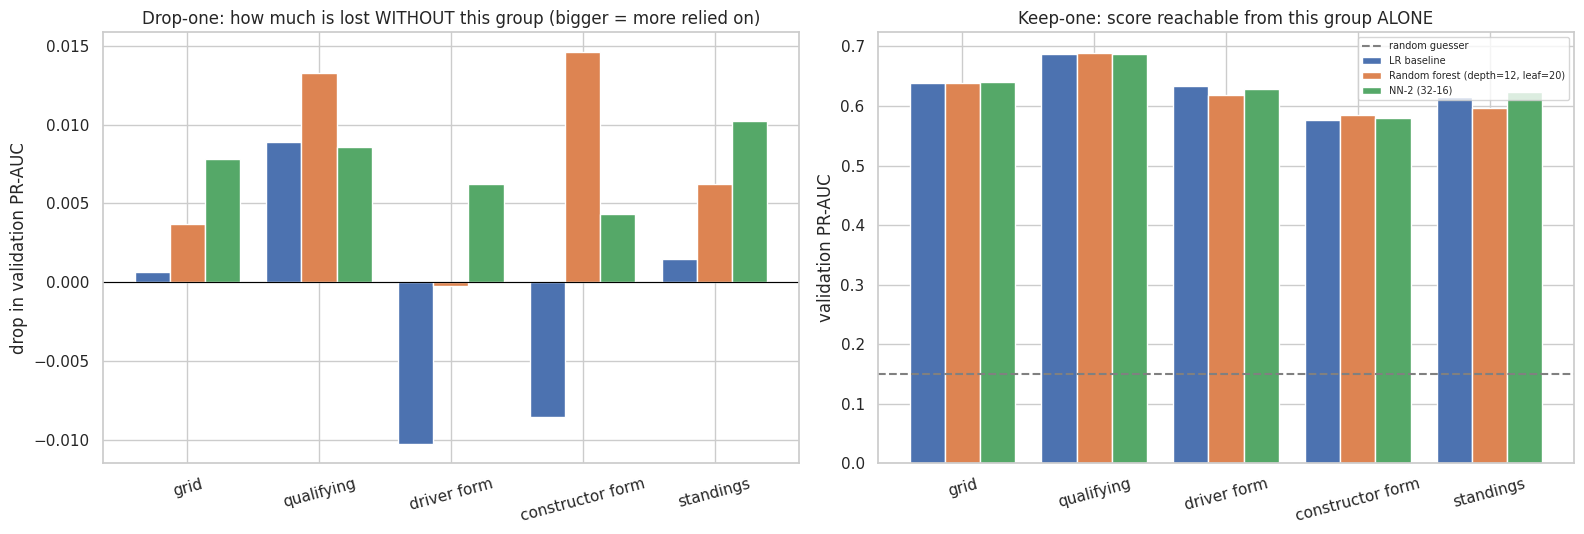

LR baseline: full val PR-AUC 0.7133
   largest drop when removed : qualifying (+0.0089)
   best single group alone   : qualifying (0.6866)
   removable with a drop < 0.01 (redundant given the rest): ['grid', 'qualifying', 'driver form', 'constructor form', 'standings']
Random forest (depth=12, leaf=20): full val PR-AUC 0.7363
   largest drop when removed : constructor form (+0.0146)
   best single group alone   : qualifying (0.6893)
   removable with a drop < 0.01 (redundant given the rest): ['grid', 'driver form', 'standings']
NN-2 (32-16): full val PR-AUC 0.7361
   largest drop when removed : standings (+0.0102)
   best single group alone   : qualifying (0.6873)
   removable with a drop < 0.01 (redundant given the rest): ['grid', 'qualifying', 'driver form', 'constructor form']


In [98]:
groups = list(FEATURE_GROUPS)
x = np.arange(len(groups))
width = 0.8 / len(ABLATION_MODELS)
fig, axes = plt.subplots(1, 2, figsize=(16, 5.5))
for i, name in enumerate(ABLATION_MODELS):
    t = ablation[name]
    drop = [t.loc['all features', 'val PR-AUC'] - t.loc[f'without {g}', 'val PR-AUC'] for g in groups]
    only = [t.loc[f'only {g}', 'val PR-AUC'] for g in groups]
    axes[0].bar(x + i * width, drop, width, label=name)
    axes[1].bar(x + i * width, only, width, label=name)
for ax in axes:
    ax.set_xticks(x + width * (len(ABLATION_MODELS) - 1) / 2)
    ax.set_xticklabels(groups, rotation=15)
axes[0].axhline(0, color='black', linewidth=0.8)
axes[0].set_ylabel('drop in validation PR-AUC')
axes[0].set_title('Drop-one: how much is lost WITHOUT this group (bigger = more relied on)')
axes[1].axhline(ys['val'].mean(), color='grey', linestyle='--', label='random guesser')
axes[1].set_ylabel('validation PR-AUC')
axes[1].set_title('Keep-one: score reachable from this group ALONE')
axes[1].legend(fontsize=7)
plt.tight_layout()
plt.show()

# Automatic reading
for name in ABLATION_MODELS:
    t = ablation[name]
    full = t.loc['all features', 'val PR-AUC']
    drops = {g: full - t.loc[f'without {g}', 'val PR-AUC'] for g in groups}
    alone = {g: t.loc[f'only {g}', 'val PR-AUC'] for g in groups}
    biggest, redundant = max(drops, key=drops.get), [g for g in groups if drops[g] < 0.01]
    print(f'{name}: full val PR-AUC {full:.4f}')
    print(f'   largest drop when removed : {biggest} ({drops[biggest]:+.4f})')
    print(f'   best single group alone   : {max(alone, key=alone.get)} ({max(alone.values()):.4f})')
    print(f'   removable with a drop < 0.01 (redundant given the rest): {redundant if redundant else "none"}')

**How to read this:**
- **Left plot (drop-one):** the group with the tallest bar is the evidence the model misses most. A bar near zero (or slightly negative) means the model loses nothing without the group. Negative values are noise-level gains, not a sign the group is harmful. With ~117 validation podiums, treat differences below about 0.01 as ties.
- **Right plot (keep-one):** how far one kind of evidence goes on its own. Compare it with the grey random-guesser line and with the full-model score (first row of the table). Groups that are strong alone but cause no drop when removed are **redundant, not unimportant**: other groups tell the model the same thing (e.g. grid and qualifying position, 0.97 correlated).
- **Model differences:** if the logistic regression leans on a different group than the tree model or the network, that suggests the non-linear models extract something the linear model cannot, e.g. an interaction.
- **Not causal:** a large drop means the model *relies* on that group to predict. It does not mean the group causes podiums. This is a statement about the model, not about Formula 1.
- The ablation retrains with the *same* hyperparameters selected for the full feature set; with fewer features, different settings could be slightly better, so the drops are a conservative estimate.

**Reading (our results, 9.10):**

*Drop-one (validation PR-AUC lost when the group is removed; negative = the model got better without it):*

| Group removed | LR baseline | Random forest | NN-2 (2-seed mean) |
|---|---|---|---|
| grid | +0.001 | +0.004 | +0.008 |
| qualifying | +0.009 | +0.013 | +0.010 |
| driver form | −0.010 | −0.000 | +0.006 |
| constructor form | −0.009 | +0.015 | +0.005 |
| standings | +0.002 | +0.006 | +0.010 |

- **No group is individually indispensable.** The largest drop for any model is 0.015, around our noise level. This confirms the redundancy predicted in 8.5 (grid ↔ qualifying 0.97, form ↔ standings 0.8–0.9): when one kind of evidence is removed, the others compensate. Redundant does not mean useless (see keep-one).
- **Driver form is the most dispensable group.** Removing it does not hurt the logistic regression (validation +0.010 *better*, test +0.005) or the forest (0.000 on validation, +0.013 better on test).
- **Qualifying is the group the models miss most** for the logistic regression and the forest (validation −0.009 / −0.013; test −0.003 / −0.017), consistent with the Q1.3 and 8.5 findings that the pace gap and the grid-vs-qualifying difference carry information the grid position alone does not.
- **The neural network spreads its reliance evenly** (every drop 0.005–0.010). On test it did *better* without any single group (by up to +0.027; only removing standings changed it by a negligible +0.002), i.e. with all 12 correlated inputs it fits the training seasons' detail and generalises worse, in line with 9.8.

*Keep-one (validation PR-AUC from one group alone; random guesser = 0.15, grid alone = 0.639, all features ≈ 0.71–0.74):*
- **Qualifying alone is the strongest group** (0.687–0.689 for all three models), better than the grid alone (0.639; the same as the grid-only rule, so `pit_lane_start` adds nothing on its own) and reaching about 93–96 % of the full model's score.
- The three history-based groups are weaker on their own: driver form 0.62–0.63, standings 0.60–0.62, constructor form 0.58.
- **Weekend evidence transfers across eras, history-based evidence does not.** From validation to test, grid and qualifying alone keep their score (change between −0.008 and +0.009 for all three models), while driver form, constructor form and standings alone lose **0.05 to 0.11** PR-AUC (e.g. random forest, driver form alone: 0.619 → 0.513). Form and standings look backwards at past races, and a regulation reset such as 2022 reshuffles which cars are fast, so they age quickly. This is a likely explanation, not something this experiment proves. It also fits the era limitation in 9.9. (Test values here are for reporting; no choice was made from them.)
- **Reminder:** these are statements about what the *models rely on*, not about what causes podium finishes.

## 9.11 Saving the finalists for the XAI and inference parts

The XAI and interface team members need the fitted models plus everything required to turn a raw driver-race record into model input. We save (in `/kaggle/working`):
- `best_statistical_model.joblib`: the model, its validation-chosen threshold, `FEATURES`, which feature copy it expects (`inputs`: `'scaled'` or `'raw'`) and the fitted preprocessing `prep` (medians, clip value, scaler);
- `best_nn.keras` + `best_nn_meta.joblib`: the best network and the same metadata (the network expects **scaled** inputs);
- the comparison, test and ablation tables as CSV files.

For the tree models, SHAP and LIME should be run on the **original-unit** table `Xr` so explanations read "grid ≤ 3" rather than a standardised value.

In [99]:
os.makedirs(OUT_DIR, exist_ok=True)

joblib.dump({'name': best_stat, 'model': registry[best_stat]['model'], 'inputs': registry[best_stat]['inputs'],
             'threshold': thresholds[best_stat], 'features': FEATURES, 'prep': prep},
            os.path.join(OUT_DIR, 'best_statistical_model.joblib'))

joblib.dump({'name': NAME_BASE, 'model': registry[NAME_BASE]['model'], 'inputs': 'scaled', 'threshold': thresholds[NAME_BASE],
             'features': FEATURES, 'prep': prep}, os.path.join(OUT_DIR, 'lr_baseline.joblib'))

registry[best_nn]['model'].save(os.path.join(OUT_DIR, 'best_nn.keras'))
joblib.dump({'name': best_nn, 'inputs': 'scaled', 'threshold': thresholds[best_nn], 'features': FEATURES, 'prep': prep},
            os.path.join(OUT_DIR, 'best_nn_meta.joblib'))

val_tab.to_csv(os.path.join(OUT_DIR, 'model_comparison_validation.csv'))
tr_tab.to_csv(os.path.join(OUT_DIR, 'model_comparison_train.csv'))
test_tab.to_csv(os.path.join(OUT_DIR, 'model_comparison_test.csv'))
pd.concat(ablation, names=['model', 'features used']).to_csv(os.path.join(OUT_DIR, 'ablation_results.csv'))

print('Saved:', sorted(f for f in os.listdir(OUT_DIR) if f.startswith(('best_', 'lr_', 'model_comparison', 'ablation'))))

Saved: ['ablation_results.csv', 'best_nn.keras', 'best_nn_meta.joblib', 'best_statistical_model.joblib', 'lr_baseline.joblib', 'model_comparison_test.csv', 'model_comparison_train.csv', 'model_comparison_validation.csv']


## 9.12 Summary of the modelling section

In [100]:
summary = pd.DataFrame({
    'family': [registry[n]['family'] for n in FINALISTS],
    'threshold (val-chosen)': [thresholds[n] for n in FINALISTS],
    'val PR-AUC': val_tab.loc[FINALISTS, 'PR-AUC'], 'test PR-AUC': test_tab.loc[FINALISTS, 'PR-AUC'],
    'val ROC-AUC': val_tab.loc[FINALISTS, 'ROC-AUC'], 'test ROC-AUC': test_tab.loc[FINALISTS, 'ROC-AUC'],
    'val F1': val_tab.loc[FINALISTS, 'F1'], 'test F1': test_tab.loc[FINALISTS, 'F1'],
}, index=FINALISTS)
display(summary.round(4))
print('Models trained and compared:', len(registry), '(distinct modelling attempts)')
print('Primary metric: PR-AUC | secondary: ROC-AUC | operating point: F1 / precision / recall at the validation-chosen threshold')
print('Finalists chosen on validation only; test scored once.')

,family,threshold (val-chosen),val PR-AUC,test PR-AUC,val ROC-AUC,test ROC-AUC,val F1,test F1
Rule: grid only,reference,0.3333,0.6386,0.6473,0.9092,0.9136,0.6923,0.6486
LR baseline,statistical,0.3491,0.7133,0.7152,0.9306,0.9363,0.7064,0.6744
"Random forest (depth=12, leaf=20)",statistical,0.2111,0.7363,0.7102,0.9329,0.9363,0.7132,0.6559
NN-2 (32-16),NN,0.3099,0.7479,0.6959,0.9288,0.9339,0.7073,0.6570


Models trained and compared: 9 (distinct modelling attempts)
Primary metric: PR-AUC | secondary: ROC-AUC | operating point: F1 / precision / recall at the validation-chosen threshold
Finalists chosen on validation only; test scored once.


**Summary of the modelling section**

| Item | Where |
|---|---|
| **Split:** train 2003–2019, validation 2020–2021, test 2022–2024, by season, races kept whole | 9.1 |
| **Metrics:** ROC-AUC, PR-AUC, F1, precision, recall (+ top-3 hit rate); **primary PR-AUC**, secondary ROC-AUC; threshold chosen on validation by maximising F1, never 0.5 | 9.2 |
| **Baseline:** logistic regression, plus a no-learning grid rule as a floor | 9.3, 9.4 |
| **Attempts:** LR balanced, LR tuned, random forest, gradient boosting, three shallow neural networks (3 seeds each) | 9.5, 9.6 |
| **Train / validation performance and finalist selection** | 9.7 |
| **Unseen test performance** (finalists only, scored once) | 9.8 |
| **Limitations** | 9.9 |
| **Feature-group ablation** (drop-one and keep-one, three models) | 9.10 |
| **Saved models for XAI and inference** | 9.11 |

All choices (hyperparameters, early-stopping epoch, threshold, finalists) were made on training and validation seasons only. Feature importance and ablation drops describe what the *model relies on*, not what *causes* podium finishes.

**Main conclusions of the modelling section**
1. **Learning helps, but mostly beyond the grid.** All learned models beat the grid-only rule on PR-AUC (about +0.05 to +0.07 on test), yet they are only about 0.01 better at naming the three podium finishers of a race.
2. **Added complexity did not earn its place.** The random forest and the neural network looked better on validation (+0.023 / +0.035 PR-AUC over the baseline) but not on the unseen test seasons (−0.005 / −0.019). The simple logistic regression was the most robust (test PR-AUC 0.715, F1 0.674).
3. **The validation set is too small to rank similar models.** With about 117 podium rows and several candidates (and 3 seeds for the networks), the best validation score is partly luck. Seed-to-seed differences (0.02) were larger than architecture differences (0.01).
4. **The features are redundant, and the weekend evidence generalises best.** No single group is indispensable (largest drop 0.015), qualifying is the strongest group on its own, and the history-based groups (form, standings) lose 0.05–0.11 PR-AUC from validation to test while grid and qualifying do not.
5. **Era sensitivity is the main limitation** (9.9): test seasons come from a new technical era, and everything fitted on 2003–2019 (including form and standings) is partly out of date there.

# 10. Model Explainability (XAI)

Sections 8–9 told us *how well* the models predict. This section asks *what they rely on*. We explain the **logistic regression baseline** (best on the test seasons) and the **random forest** (best statistical model on validation), and use permutation importance on the neural network as well.

| Tool | Scope | Question it answers |
|---|---|---|
| Permutation importance | global | how much worse does the model get if one feature (or group) is shuffled? |
| SHAP | global + local | how much did each feature push this prediction up or down from the average prediction? |
| LIME | local | which features explain this one prediction in a small neighbourhood around it? |

**Read this before interpreting anything.** An explanation describes what the *model* uses. It is **not** evidence that a feature *causes* podium finishes. Two further cautions for this project:
1. **Correlated features share credit.** Grid and qualifying position are 0.97 correlated, and form and standings are 0.8–0.9. Shuffling one of a pair costs little because the other still carries the signal, so we also shuffle whole feature **groups** (the same groups as the ablation in 9.10).
2. **Explanations are computed on validation/test rows only to describe the finished models.** No choice (features, hyperparameters, finalists) is made from them.

In [101]:
%pip install -q shap lime        # Kaggle: needs Settings -> Internet ON (shap is preinstalled, lime may not be)
import shap
from lime.lime_tabular import LimeTabularExplainer
from scipy.stats import spearmanr
shap.initjs()
print('shap', shap.__version__)

Note: you may need to restart the kernel to use updated packages.


shap 0.52.0


## 10.1 Permutation importance (global)

**How it works.** Take a fitted model and a scored dataset. Shuffle the values of *one* feature across rows, which breaks its link to the outcome while keeping its distribution, and score again. The **drop in PR-AUC** is that feature's importance. We repeat 30 times and report mean ± std, because a single shuffle is noisy.

We use **PR-AUC** (our primary metric) on the **validation** seasons, and show the test seasons next to it as a robustness check. A **group** is shuffled with the *same* row order for all its columns, so the relationship inside the group is kept and only its link to the outcome is broken.

2026-10-19 20:01:35.535077: E tensorflow/core/framework/node_def_util.cc:680] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_14}}
2026-10-19 20:01:40.593639: E tensorflow/core/framework/node_def_util.cc:680] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),

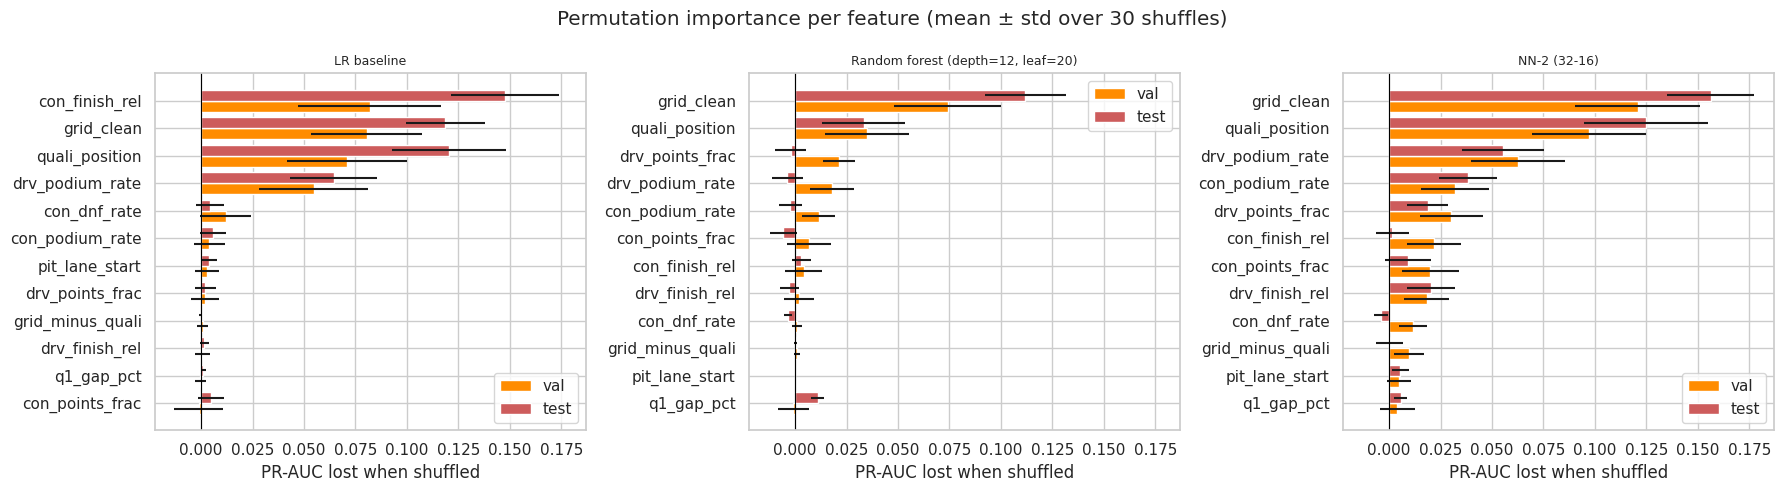

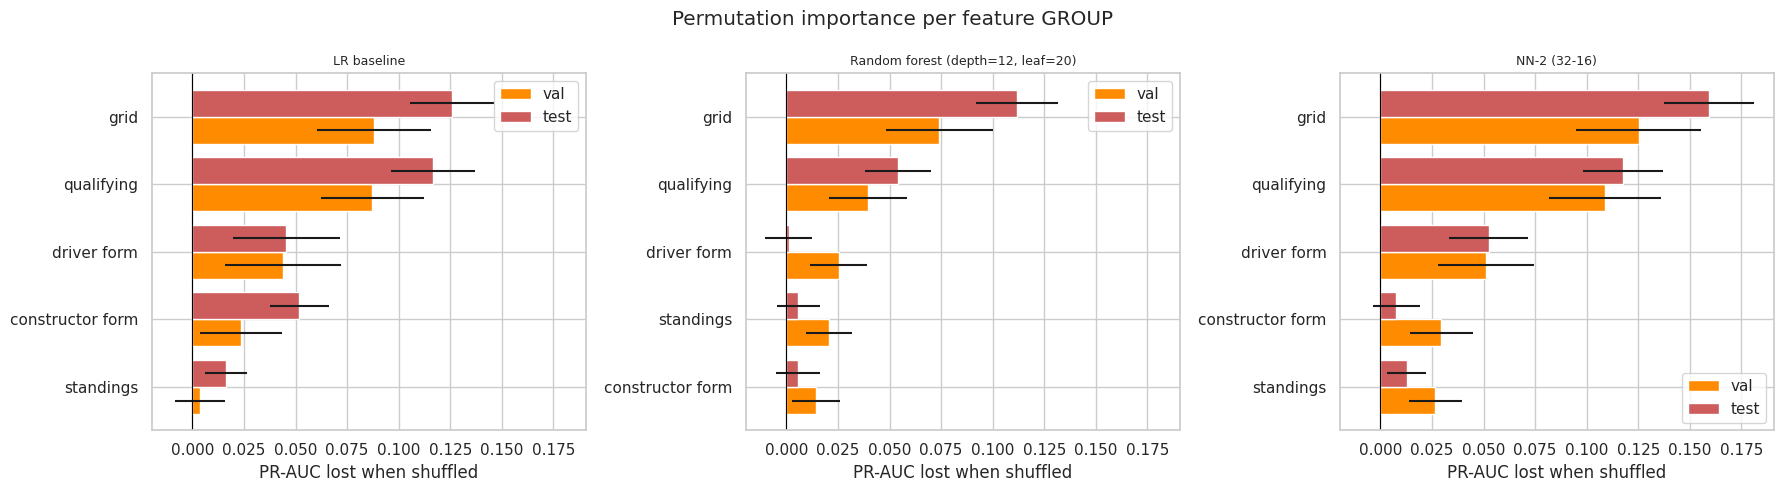

LR baseline         Random forest (depth=12, leaf=20)         NN-2 (32-16)        
                         val    test                               val    test          val    test
grid                  0.0879  0.1260                            0.0741  0.1119       0.1251  0.1595
qualifying            0.0872  0.1165                            0.0396  0.0541       0.1089  0.1175
driver form           0.0440  0.0455                            0.0254  0.0011       0.0513  0.0525
constructor form      0.0236  0.0519                            0.0144  0.0055       0.0295  0.0078
standings             0.0038  0.0165                            0.0207  0.0059       0.0267  0.0127

In [102]:
def predict_on(name, X):
    e = registry[name]
    if e['family'] == 'NN':
        return e['model'].predict(X.values.astype('float32'), verbose=0).ravel()
    return e['model'].predict_proba(X)[:, 1]

def permutation_importance_pr(name, split, units, n_repeats=30, seed=SEED):
    e = registry[name]
    X = (Xs if e['inputs'] == 'scaled' else Xr)[split]
    y = ys[split]
    base = average_precision_score(y, predict_on(name, X))
    rng = np.random.default_rng(seed)
    rows = []
    for unit, cols in units.items():
        drops = []
        for _ in range(n_repeats):
            Xp = X.copy()
            idx = rng.permutation(len(X))
            Xp[cols] = X[cols].values[idx]          # same row order for every column in the unit
            drops.append(base - average_precision_score(y, predict_on(name, Xp)))
        rows.append({'unit': unit, 'mean drop': np.mean(drops), 'std': np.std(drops)})
    return base, pd.DataFrame(rows).set_index('unit')

PERM_MODELS = [NAME_BASE, best_stat, best_nn]
FEATURE_UNITS = {f: [f] for f in FEATURES}

perm_feat = {(m, s): permutation_importance_pr(m, s, FEATURE_UNITS)[1] for m in PERM_MODELS for s in ['val', 'test']}
perm_group = {(m, s): permutation_importance_pr(m, s, FEATURE_GROUPS)[1] for m in PERM_MODELS for s in ['val', 'test']}

def plot_perm(perm, title):
    fig, axes = plt.subplots(1, len(PERM_MODELS), figsize=(6 * len(PERM_MODELS), 5), sharex=True)
    for ax, m in zip(axes, PERM_MODELS):
        order = perm[(m, 'val')]['mean drop'].sort_values().index
        y = np.arange(len(order))
        for k, (s, c) in enumerate([('val', 'darkorange'), ('test', 'indianred')]):
            d = perm[(m, s)].loc[order]
            ax.barh(y + (k - 0.5) * 0.4, d['mean drop'], xerr=d['std'], height=0.4, color=c, label=s)
        ax.axvline(0, color='black', linewidth=0.8)
        ax.set_yticks(y)
        ax.set_yticklabels(order)
        ax.set_title(m, fontsize=9)
        ax.set_xlabel('PR-AUC lost when shuffled')
        ax.legend()
    plt.suptitle(title)
    plt.tight_layout()
    plt.show()

plot_perm(perm_feat, 'Permutation importance per feature (mean ± std over 30 shuffles)')
plot_perm(perm_group, 'Permutation importance per feature GROUP')

perm_table = pd.concat({(m, s): perm_group[(m, s)]['mean drop'] for m in PERM_MODELS for s in ['val', 'test']}, axis=1).round(4)
perm_table.index.name = None        # removes the extra "unit" header row
display(perm_table)

## 10.2 SHAP (global)

**How it works.** SHAP gives every feature a **Shapley value** for every row: its fair share of the difference between this row's prediction and the average prediction, in a game where features "join" one at a time. For one row, the values add up exactly to *prediction − baseline*.
- **Random forest:** `TreeExplainer` (exact and fast for trees). Values are in **probability** units.
- **Logistic regression:** `LinearExplainer`. Values are in **log-odds** units.
- **Neural network (optional, slow):** `KernelExplainer`, which is model-agnostic and uses a small background sample, on a sample of test rows.

Plots: the **beeswarm** (one dot per row; position = effect on the prediction, colour = feature value) and the **bar chart** of mean |SHAP|. They are computed on the **test seasons**, to describe how the finished model behaves on unseen races.

RF  max |base + sum(SHAP) - predict_proba|: 0.0
LR  max |base + sum(SHAP) - decision_function|: 0.0


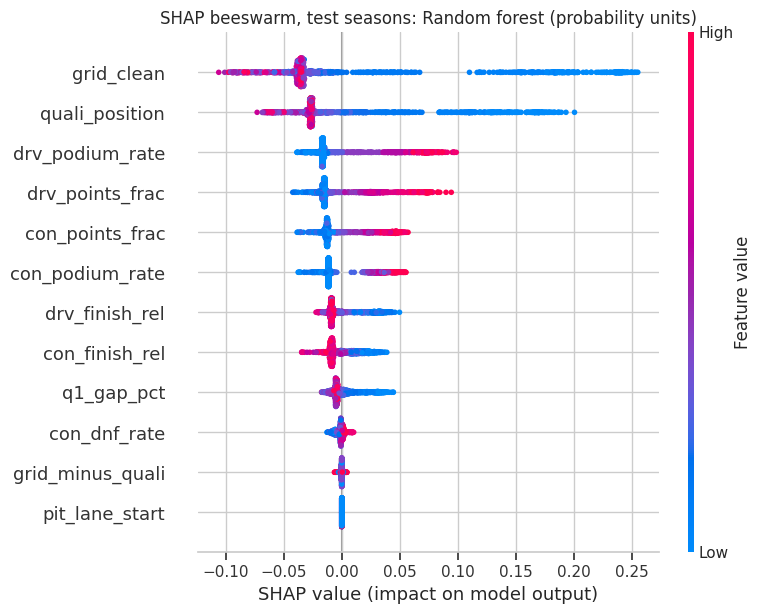

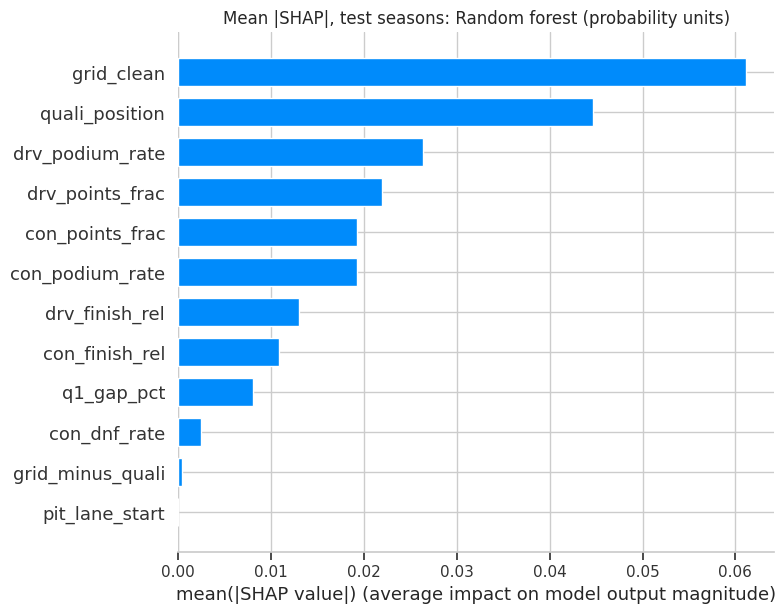

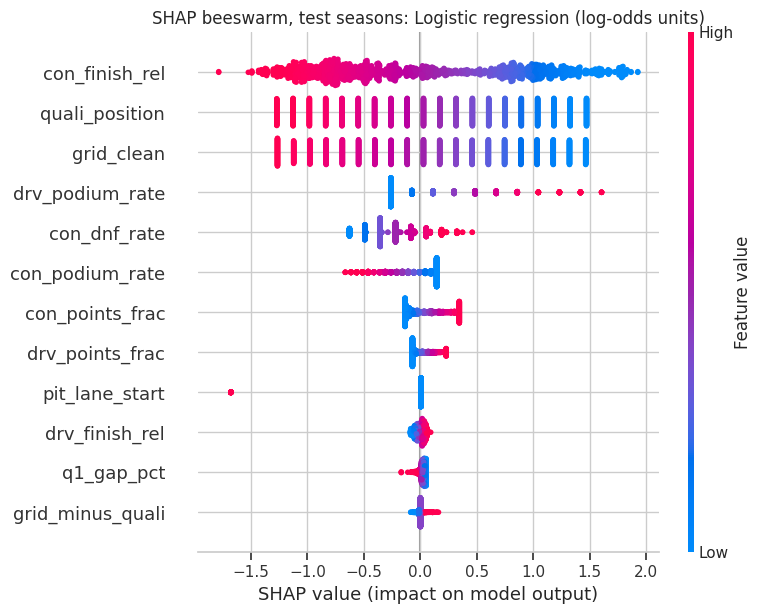

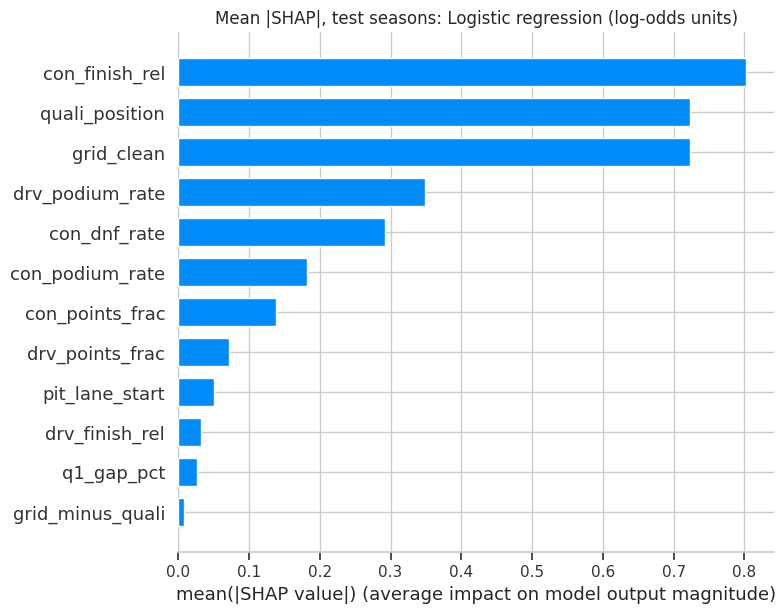

In [103]:
def shap_pos(sv):
    # shap versions return a list [class0, class1] or an array (rows, features, 2): keep the "podium" class
    sv = np.stack(sv, axis=-1) if isinstance(sv, list) else np.asarray(sv)
    return sv[:, :, 1] if sv.ndim == 3 else sv

def base_pos(ev):
    return float(np.atleast_1d(ev)[-1])

# Random forest: original units
rf_model = registry[best_stat]['model']
expl_rf = shap.TreeExplainer(rf_model)
sv_rf = shap_pos(expl_rf.shap_values(Xr['test'], check_additivity=False))
base_rf = base_pos(expl_rf.expected_value)

# LR: use the full training set as background (exact baseline, no subsampling message)
lr_model  = registry[NAME_BASE]['model']
masker_lr = shap.maskers.Independent(Xs['train'], max_samples=len(Xs['train']))
expl_lr   = shap.LinearExplainer(lr_model, masker_lr)
sv_lr     = shap_pos(expl_lr.shap_values(Xs['test']))
base_lr   = base_pos(expl_lr.expected_value)

assert sv_rf.shape == Xr['test'].shape and sv_lr.shape == Xs['test'].shape
# Additivity check: base + sum(SHAP) must reproduce the model output
print('RF  max |base + sum(SHAP) - predict_proba|:', np.abs(base_rf + sv_rf.sum(1) - rf_model.predict_proba(Xr['test'])[:, 1]).max().round(4))
print('LR  max |base + sum(SHAP) - decision_function|:', np.abs(base_lr + sv_lr.sum(1) - lr_model.decision_function(Xs['test'])).max().round(4))

for title, sv in [('Random forest (probability units)', sv_rf), ('Logistic regression (log-odds units)', sv_lr)]:
    shap.summary_plot(sv, Xr['test'], feature_names=FEATURES, show=False, rng=np.random.default_rng(SEED))
    plt.title(f'SHAP beeswarm, test seasons: {title}')
    plt.tight_layout()
    plt.show()
    shap.summary_plot(sv, Xr['test'], feature_names=FEATURES, plot_type='bar', show=False, rng=np.random.default_rng(SEED))
    plt.title(f'Mean |SHAP|, test seasons: {title}')
    plt.tight_layout()
    plt.show()

### 10.2 Reading the SHAP plots (logistic regression, test seasons 2022–2024)

**How to read them**
- **Bar plot:** the average absolute SHAP value per feature, i.e. how much each feature moves a prediction on average. Longer bars mean more influence. It does not show direction.
- **Beeswarm:** each dot is one driver-race in the test set.
  - *x-axis:* the feature's push on that prediction, in log-odds. Right raises podium probability and left lowers it.
  - *Colour:* the feature's value for that row (red is high, blue is low).
  - *Vertical stripes* appear for integer features such as grid and qualifying position.
- Features are sorted by average impact, so the top rows matter most.

**What the plots show**
- **Car strength and starting position dominate.** `con_finish_rel`, `quali_position` and `grid_clean` have the largest effects. A strong constructor and a front-row start push podium odds up, and a back-of-grid start pushes them down. This is the expected direction.
- **`quali_position` and `grid_clean` are near-duplicates**, so they share credit. Neither should be read as the sole driver.
- **Driver form and standings** (`drv_podium_rate`, `drv_points_frac`, `con_points_frac`) have small to moderate positive effects when high.
- **`pit_lane_start`** gives a very large negative push, but it is rare, so it barely affects the averages.
- **`drv_finish_rel`, `q1_gap_pct` and `grid_minus_quali`** contribute almost nothing.

**Caveats**
- `con_dnf_rate` and `con_podium_rate` show counter-intuitive directions. This is a collinearity artifact: the constructor features all measure car strength, so the model gives some positive and some negative weights that offset each other. Only their combined contribution is meaningful, and no single sign should be interpreted.
- SHAP shows what the model uses, not what causes podiums. Nothing here is causal.
- The grouped permutation importance and the retrained ablation are more reliable than individual LR weights or single-feature SHAP values when features are correlated. They agree that qualifying and car strength carry most of the signal.

2026-10-19 20:05:28.512753: E tensorflow/core/framework/node_def_util.cc:680] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_14}}


  0%|          | 0/120 [00:00<?, ?it/s]

2026-10-19 20:05:33.565142: E tensorflow/core/framework/node_def_util.cc:680] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_14}}
2026-10-19 20:05:38.585283: E tensorflow/core/framework/node_def_util.cc:680] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),

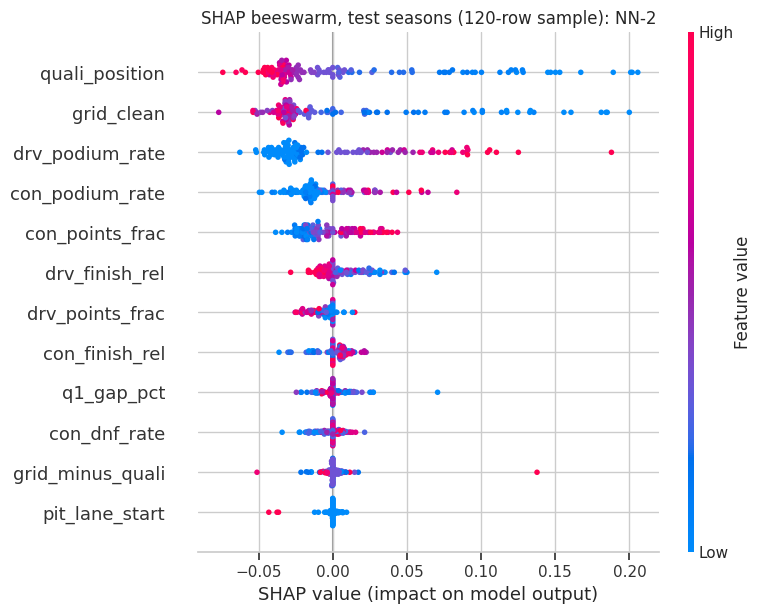

In [104]:
# Optional and slow (a few minutes). Reduce nsamples / the sample size if it takes too long.
nn_model = registry[best_nn]['model']
f_nn = lambda a: nn_model.predict(np.asarray(a, dtype='float32'), verbose=0).ravel()
background = shap.kmeans(Xs['train'].values, 25)
expl_nn = shap.KernelExplainer(f_nn, background)
nn_pos = np.arange(0, len(Xs['test']), 10)[:120]                      # a regular sample of test rows
sv_nn = np.asarray(expl_nn.shap_values(Xs['test'].values[nn_pos], nsamples=200)).reshape(len(nn_pos), len(FEATURES))

shap.summary_plot(sv_nn, Xr['test'].iloc[nn_pos], feature_names=FEATURES, show=False, rng=np.random.default_rng(SEED))
plt.title('SHAP beeswarm, test seasons (120-row sample): NN-2')
plt.tight_layout()
plt.show()

In [105]:
glob = pd.DataFrame({
    'RF permutation (test)': perm_feat[(best_stat, 'test')]['mean drop'],
    'RF mean |SHAP|': pd.Series(np.abs(sv_rf).mean(0), index=FEATURES),
    'LR permutation (test)': perm_feat[(NAME_BASE, 'test')]['mean drop'],
    'LR mean |SHAP| (log-odds)': pd.Series(np.abs(sv_lr).mean(0), index=FEATURES),
})
display(glob.sort_values('RF mean |SHAP|', ascending=False).round(4))
print('Spearman rank agreement between the two methods (12 features):')
print('  random forest        :', round(spearmanr(glob['RF permutation (test)'], glob['RF mean |SHAP|'])[0], 2))
print('  logistic regression  :', round(spearmanr(glob['LR permutation (test)'], glob['LR mean |SHAP| (log-odds)'])[0], 2))

# Group-level SHAP: NET effect of the group per row (sum the SHAP values of its features, then take |.|)
# so offsetting weights inside a group cancel instead of inflating the group's importance
grp = pd.DataFrame({
    'RF (probability)': [np.abs(sv_rf[:, [FEATURES.index(c) for c in cols]].sum(1)).mean() for cols in FEATURE_GROUPS.values()],
    'LR (log-odds)':    [np.abs(sv_lr[:, [FEATURES.index(c) for c in cols]].sum(1)).mean() for cols in FEATURE_GROUPS.values()]},
    index=list(FEATURE_GROUPS))
display(grp.round(4))

,RF permutation (test),RF mean |SHAP|,LR permutation (test),LR mean |SHAP| (log-odds)
grid_clean,0.1119,0.0611,0.1187,0.7225
quali_position,0.0334,0.0447,0.1205,0.7234
drv_podium_rate,-0.0038,0.0264,0.0644,0.3491
drv_points_frac,-0.0021,0.0219,0.0021,0.0723
con_points_frac,-0.0056,0.0193,0.0049,0.1385
con_podium_rate,-0.0023,0.0192,0.0058,0.1815
drv_finish_rel,-0.0027,0.0130,0.0016,0.0327
con_finish_rel,0.0030,0.0108,0.1475,0.8017
q1_gap_pct,0.0109,0.0081,0.0010,0.0265
con_dnf_rate,-0.0033,0.0025,0.0044,0.2920


Spearman rank agreement between the two methods (12 features):
  random forest        : 0.11
  logistic regression  : 0.97


,RF (probability),LR (log-odds)
grid,0.0611,0.7689
qualifying,0.0483,0.7392
driver form,0.0380,0.3205
constructor form,0.0283,0.6082
standings,0.0400,0.2091


**Reading the global SHAP results (our results, 10.2)**

*Random forest (probability units; mean |SHAP|, test seasons):* `grid_clean` 0.061, `quali_position` 0.045, `drv_podium_rate` 0.026, `drv_points_frac` 0.022, `con_points_frac` and `con_podium_rate` 0.019, then `drv_finish_rel`, `con_finish_rel` and `q1_gap_pct` (0.008–0.013). `con_dnf_rate`, `grid_minus_quali` and `pit_lane_start` are about zero.

- **Grid and qualifying come first in both SHAP and permutation importance,** as in the drop-one and keep-one ablation. Beyond those two the methods disagree for the forest (see below). On the test seasons, shuffling the form or standings groups costs the forest almost nothing, while SHAP still credits them.
- **The beeswarm directions are what the EDA predicted.** A low (good) grid or qualifying position pushes the podium probability up, by as much as about +0.25. A high (bad) one pushes it down, by up to about −0.10. A high driver podium rate, driver points fraction and constructor podium rate push it up.
- **`pit_lane_start` and `grid_minus_quali` have almost no effect on this model.** Pit-lane starts are rare: about 40 rows (≈3 %) in the test seasons, and the grid position already contains their effect. Penalty information is largely contained in the grid position as well.

*Logistic regression (log-odds units):* `con_finish_rel` (about 0.80), `grid_clean` and `quali_position` (about 0.72 each), then `drv_podium_rate` (0.35) and `con_dnf_rate` (0.29).

- **The LR gives the most weight to `con_finish_rel`, which the forest ranks only 8th.** As with the permutation importance, this is a correlated-feature effect: the constructor-form features measure almost the same thing, and the LR splits credit between them with offsetting weights.
- **Two of its directions look wrong at face value.** High `con_podium_rate` appears to lower the prediction and high `con_dnf_rate` appears to raise it, which contradicts the EDA (8.5). These are not real effects of reliability or podium history. They come from the weights cancelling each other among correlated features, and they are the reason single LR weights should not be read one by one (9.4). The LR is still a good predictor, since only the combined effect matters for prediction.
- **We therefore quote the random forest's SHAP picture for interpretation** and treat the LR's individual attributions as unreliable.

**Agreement between methods:** the Spearman rank correlation between single-feature permutation importance and mean |SHAP| (test seasons, 12 features) is **0.11 for the random forest** and **0.97 for the logistic regression**. The logistic regression agrees almost perfectly because it is linear: both measures reflect each feature's weight times its spread. For the forest the methods agree only on the top two features. Shuffling a single column costs almost nothing for 9 of the 12 features (within ±0.006, six of them slightly negative), because correlated partners still carry the same information, while SHAP shares the credit among them. The low rank agreement therefore reflects correlated features, not an error in either method. This is why we also use grouped permutation (10.1) and the retrained ablation (9.10).

**Group-level SHAP (net effect of each group per row; the offsetting weights inside a group cancel):**

| Group | RF (probability) | LR (log-odds) |
|---|---|---|
| grid | 0.061 | 0.769 |
| qualifying | 0.048 | 0.739 |
| driver form | 0.038 | 0.321 |
| constructor form | 0.028 | 0.608 |
| standings | 0.040 | 0.209 |

- **Both models put grid and qualifying first.** This agrees with the grouped permutation importance (10.1) and the keep-one ablation (9.10).
- **The forest's groups are close together** (0.028–0.061, with form and standings between 0.028 and 0.040). It spreads its reliance across all five groups, which fits the ablation finding that no single group is indispensable.
- **The logistic regression leans more on constructor form** (0.61, third place) than the forest does (0.03, last). The LR does this through `con_finish_rel`, which carries most of the car-strength signal. This is the same correlated-feature effect as above, so it is a difference in how the models spread credit, not evidence that constructor form matters more.
- Summing |SHAP| over the features of a group, instead of taking the net effect, would have inflated the LR's constructor form to 1.28, because its weights offset each other. This is why we use the net effect.

**These are statements about the models, not about Formula 1.** SHAP values describe how the model's output changes with its inputs. They do not show that a better grid position, or a stronger team, causes a podium.

## 10.3 Local explanations: one prediction at a time

A global plot says what the model uses *on average*; a local explanation says why it gave *this* driver *this* probability. We explain three test-season rows chosen by a fixed rule (no cherry-picking by eye) for the random forest:
- **A:** the podium finisher the model was most sure about (what a normal, correct prediction looks like),
- **B:** the podium finisher the model gave the lowest probability (a miss),
- **C:** the non-podium driver the model was most sure would podium (a false alarm).

Each gets a **SHAP waterfall** (from the baseline, each feature pushes the probability up or down until it reaches the final prediction) and a **LIME** explanation of the same row. **LIME** perturbs the row many times, asks the model for predictions, and fits a small linear model around the row. Its weights say which features matter *near* this row. It is approximate and can change a little between runs, so we fix the seed and report its local fit (R²).

In [106]:
p_rf_test = get_proba(best_stat, 'test')
y_t = ys['test']
tdf = dfs['test'].reset_index(drop=True)

cases = {
    'A: confident correct podium': int(np.argmax(np.where(y_t == 1, p_rf_test, -1))),
    'B: podium the model missed':  int(np.argmin(np.where(y_t == 1, p_rf_test, 2))),
    'C: confident false alarm':    int(np.argmax(np.where(y_t == 0, p_rf_test, -1))),
}
info = pd.DataFrame({k: tdf.loc[i, ['year', 'race_name', 'surname', 'constructor_name', 'grid_clean', 'quali_position', 'podium']]
                     for k, i in cases.items()}).T
info['RF probability'] = [p_rf_test[i] for i in cases.values()]
info['LR probability'] = [get_proba(NAME_BASE, 'test')[i] for i in cases.values()]
display(info.round(3))
display(Xr['test'].iloc[list(cases.values())].set_index(pd.Index(cases.keys())).round(3))

,year,race_name,surname,constructor_name,grid_clean,quali_position,podium,RF probability,LR probability
A: confident correct podium,2024,Japanese Grand Prix,Verstappen,Red Bull,1.0,1.0,1,0.908,0.858
B: podium the model missed,2023,Dutch Grand Prix,Gasly,Alpine F1 Team,12.0,12.0,1,0.000,0.012
C: confident false alarm,2024,Austrian Grand Prix,Verstappen,Red Bull,1.0,1.0,0,0.900,0.830


,grid_clean,pit_lane_start,quali_position,q1_gap_pct,grid_minus_quali,drv_podium_rate,drv_finish_rel,con_podium_rate,con_finish_rel,con_dnf_rate,drv_points_frac,con_points_frac
A: confident correct podium,1.0,0,1.0,0.000,0.0,0.9,0.145,0.60,0.256,0.15,1.00,1.000
B: podium the model missed,12.0,0,12.0,0.983,0.0,0.0,0.615,0.05,0.602,0.30,0.07,0.113
C: confident false alarm,1.0,0,1.0,0.112,0.0,0.8,0.175,0.60,0.263,0.15,1.00,1.000


A: confident correct podium: Verstappen, Japanese Grand Prix 2024 (baseline 0.142 -> prediction 0.908, actual podium = 1)


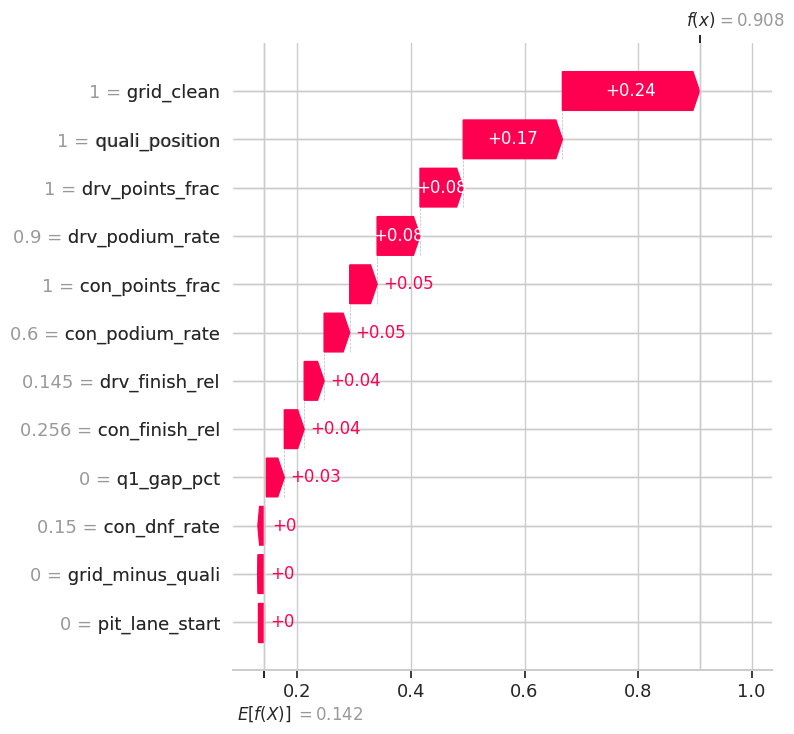

B: podium the model missed: Gasly, Dutch Grand Prix 2023 (baseline 0.142 -> prediction 0.000, actual podium = 1)


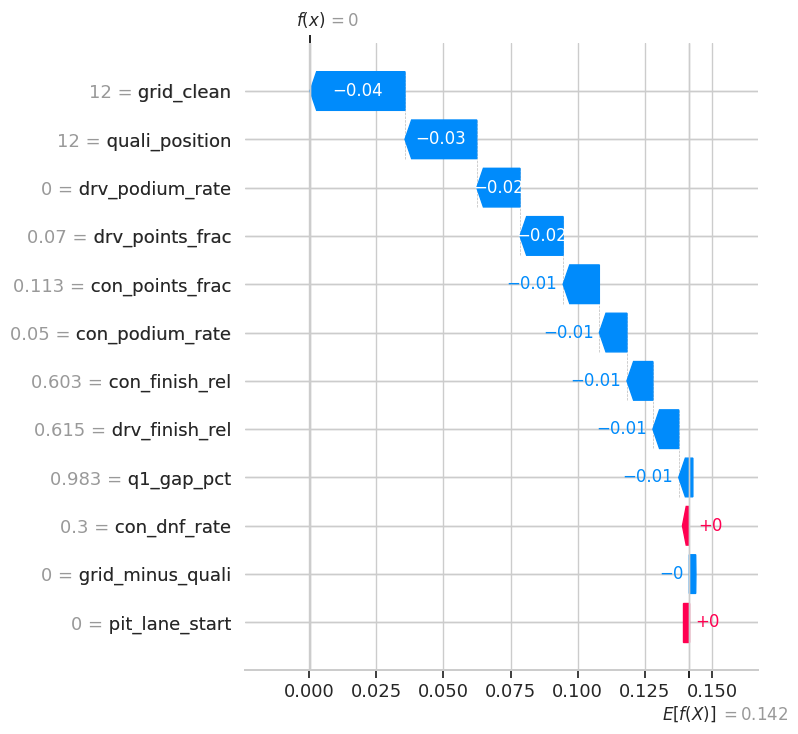

C: confident false alarm: Verstappen, Austrian Grand Prix 2024 (baseline 0.142 -> prediction 0.900, actual podium = 0)


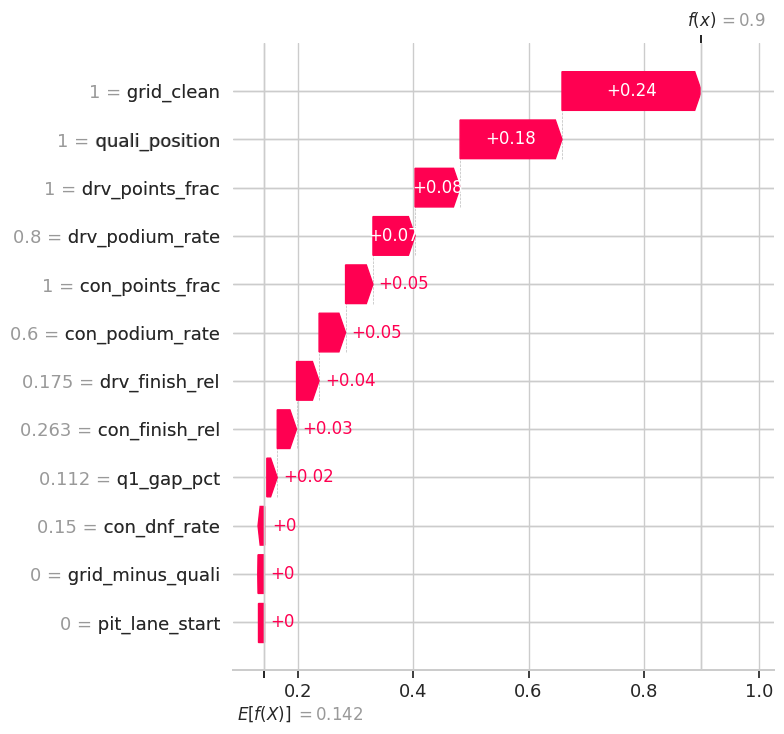

In [107]:
for name, i in cases.items():
    ex = shap.Explanation(values=sv_rf[i], base_values=base_rf, data=Xr['test'].iloc[i].values, feature_names=FEATURES)
    print(f'{name}: {tdf.loc[i, "surname"]}, {tdf.loc[i, "race_name"]} {tdf.loc[i, "year"]} '
          f'(baseline {base_rf:.3f} -> prediction {p_rf_test[i]:.3f}, actual podium = {int(y_t[i])})')
    shap.plots.waterfall(ex, max_display=12, show=False)
    plt.tight_layout()
    plt.show()

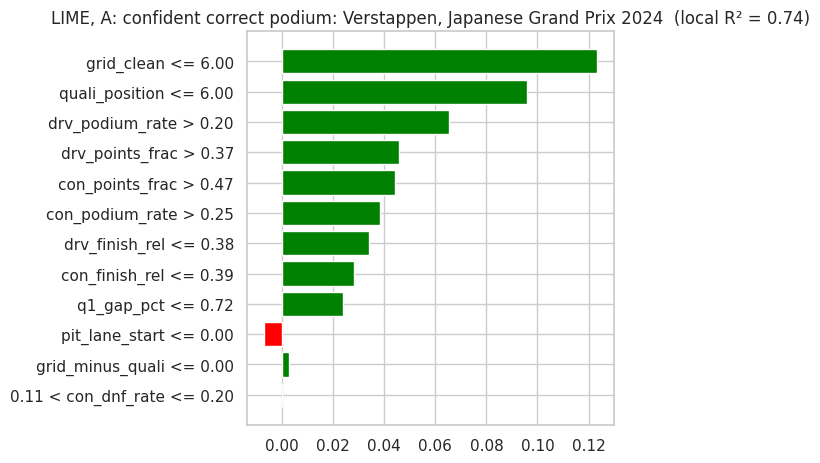

A: confident correct podium: top-5 SHAP features with the same sign in LIME: 5/5


,SHAP (probability),LIME weight
grid_clean,0.242,0.123
quali_position,0.175,0.096
drv_points_frac,0.076,0.046
drv_podium_rate,0.076,0.065
con_points_frac,0.048,0.044


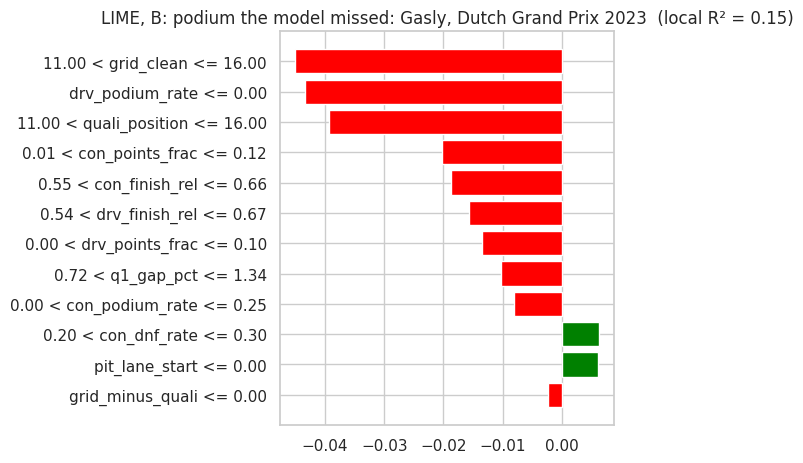

B: podium the model missed: top-5 SHAP features with the same sign in LIME: 5/5


,SHAP (probability),LIME weight
grid_clean,-0.035,-0.045
quali_position,-0.027,-0.039
drv_podium_rate,-0.016,-0.043
drv_points_frac,-0.016,-0.013
con_points_frac,-0.013,-0.020


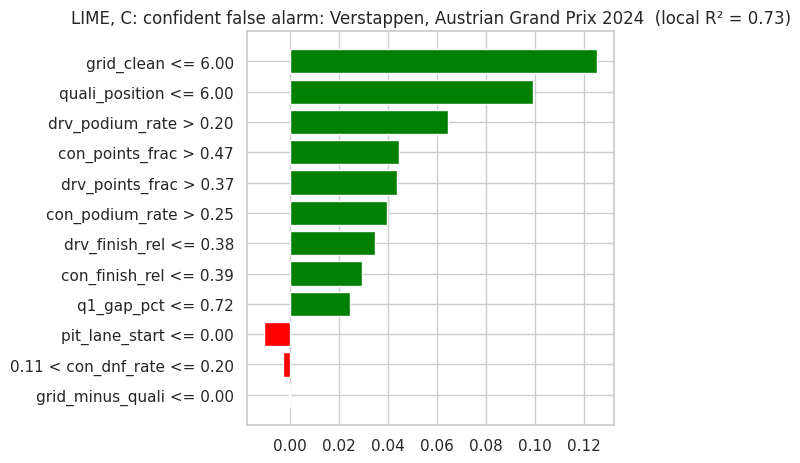

C: confident false alarm: top-5 SHAP features with the same sign in LIME: 5/5


,SHAP (probability),LIME weight
grid_clean,0.242,0.125
quali_position,0.177,0.099
drv_points_frac,0.078,0.044
drv_podium_rate,0.073,0.065
con_points_frac,0.048,0.044


In [108]:
lime_explainer = LimeTabularExplainer(Xr['train'].values, feature_names=FEATURES, class_names=['no podium', 'podium'],
                                      mode='classification', discretize_continuous=True, random_state=SEED)
rf_fn = lambda a: rf_model.predict_proba(pd.DataFrame(a, columns=FEATURES))

for name, i in cases.items():
    exp = lime_explainer.explain_instance(Xr['test'].iloc[i].values, rf_fn, num_features=len(FEATURES), num_samples=5000, labels=(1,))
    exp.as_pyplot_figure(label=1)
    plt.title(f'LIME, {name}: {tdf.loc[i, "surname"]}, {tdf.loc[i, "race_name"]} {tdf.loc[i, "year"]}  (local R² = {exp.score:.2f})')
    plt.tight_layout()
    plt.show()

    lime_w = pd.Series(dict(exp.as_map()[1])).rename(lambda k: FEATURES[k])
    cmp_ = pd.DataFrame({'SHAP (probability)': pd.Series(sv_rf[i], index=FEATURES), 'LIME weight': lime_w}).loc[FEATURES]
    top = cmp_['SHAP (probability)'].abs().sort_values(ascending=False).index[:5]
    same_sign = (np.sign(cmp_.loc[top, 'SHAP (probability)']) == np.sign(cmp_.loc[top, 'LIME weight'])).sum()
    print(f'{name}: top-5 SHAP features with the same sign in LIME: {same_sign}/5')
    display(cmp_.loc[top].round(3))

Logistic regression, case B: baseline log-odds -3.69 -> -4.38 (probability 0.012); random forest said 0.000


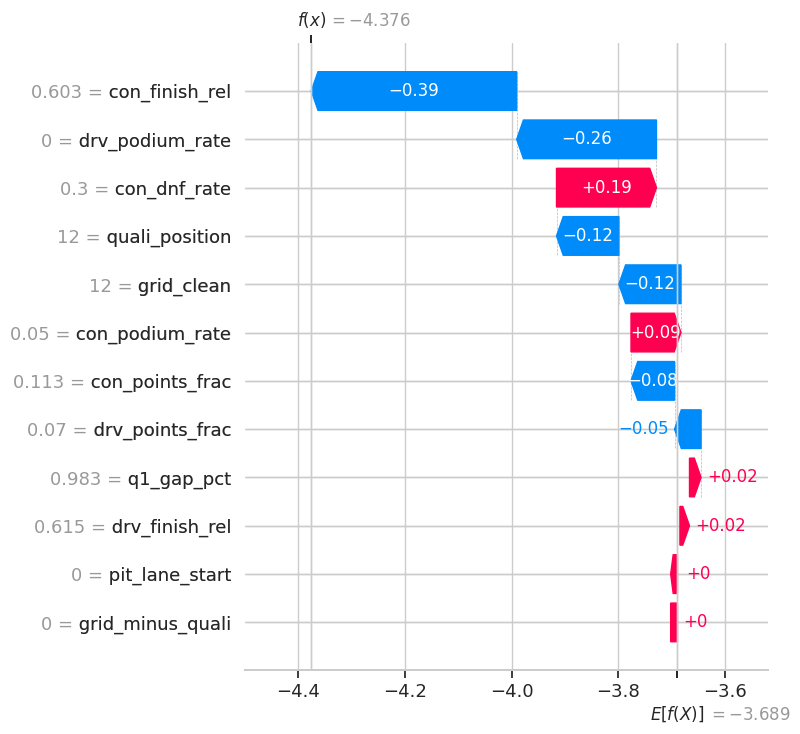

In [109]:
i = cases['B: podium the model missed']
ex = shap.Explanation(values=sv_lr[i], base_values=base_lr, data=Xr['test'].iloc[i].values, feature_names=FEATURES)
print(f'Logistic regression, case B: baseline log-odds {base_lr:.2f} -> {base_lr + sv_lr[i].sum():.2f} '
      f'(probability {get_proba(NAME_BASE, "test")[i]:.3f}); random forest said {p_rf_test[i]:.3f}')
shap.plots.waterfall(ex, max_display=12, show=False)
plt.tight_layout()
plt.show()

## 10.4 Interpretation of the local explanations

**Important: nothing below is a causal claim.** A feature that a model relies on is correlated with podium finishes in the data it saw. It does not follow that changing it would change who finishes on the podium.

- *Case A (Verstappen, Japan 2024, probability 0.908, podium):* pole position carries the prediction. `grid_clean` (+0.24) and `quali_position` (+0.17) supply 0.41 of the 0.77 gain over the 0.142 baseline. Driver form (`drv_points_frac`, `drv_podium_rate`, +0.08 each) and constructor form and standings (+0.05 each) add the rest. Every feature points the same way, so this is a normal, confident, correct prediction.
- *Case B (Gasly, Netherlands 2023, probability ≈ 0.000, podium):* every feature argues against a podium: 12th on the grid (-0.04, -0.03), no podium in the previous 10 races (-0.02), and 7 % and 11 % of the leader's points (driver, constructor). The contributions sum to about -0.14, taking the forest from 0.142 to roughly 0. The 2023 Dutch GP was a mixed wet-dry race (rain at the start and a heavy downpour near the end that brought out a red flag); Gasly gained places in the changing conditions and finished third after a time penalty for Pérez. None of this is pre-race information.
- *Case C (Verstappen, Austria 2024, probability 0.900, no podium):* the inputs are almost identical to case A (same grid, similar form), so the explanation is the same. He collided with Norris while fighting for the lead late in the race, received a 10-second penalty and finished 5th, an in-race event that no pre-race feature can contain.
- *LIME vs SHAP:* the top-5 features have the same sign in all three cases (5/5), and the order is the same for A and C. LIME's weights are about half the size of SHAP's (e.g. `grid_clean` 0.12 vs 0.24 in case A), so we compare only sign and rank. The local fit is good for A and C (R² 0.74 and 0.73) and poor for B (R² 0.15), so B's LIME weights are weak evidence. SHAP is an exact decomposition of the forest's output, so we rely on it there.
- *LR vs RF on case B:* both reject the podium (LR 0.012, with log-odds going from -3.69 to -4.38; RF 0.000) but for different reasons. The forest blames the grid and qualifying position. The LR blames `con_finish_rel` (-0.39) and `drv_podium_rate` (-0.26), with grid and qualifying only -0.12 each. It also gives +0.19 to `con_dnf_rate`. That is the collinearity artifact from 10.2, so the LR's individual attributions are less trustworthy.

**Limitations:** correlated features share credit, SHAP baselines depend on the data used, and LIME's neighbourhood can place unrealistic rows (for example a grid of P1 with a qualifying position of P18).

# 11. Inference function

`predict_podium` turns **one driver-race record** (the 12 pre-race features, in original units) into a podium probability. It uses the **saved** models and preprocessing from 9.11, so it can be used without retraining.

Design decisions:
1. **Same preprocessing as training.** The record goes through the same fill → clip → scale code that was fitted on the 2003–2019 training rows. Nothing is re-fitted.
2. **Missing values are filled by documented rules** and every filled field is returned to the caller:
   `quali_position` → `grid_clean`; `grid_minus_quali` → derived if possible, otherwise 0; podium/DNF rates → 0 (no past races); everything else → the training median.
3. **`grid_clean` is required.** It is the strongest signal and has no meaningful default, so the function refuses instead of guessing.
4. **Impossible values raise an error** (e.g. grid position 99, a rate above 1).
5. **A warning is added when 4 or more inputs had to be filled**, because the probability is then rough.

In [110]:
lr_b = joblib.load(os.path.join(OUT_DIR, 'lr_baseline.joblib'))
rf_b = joblib.load(os.path.join(OUT_DIR, 'best_statistical_model.joblib'))
nn_b = joblib.load(os.path.join(OUT_DIR, 'best_nn_meta.joblib'))
nn_b['model'] = keras.models.load_model(os.path.join(OUT_DIR, 'best_nn.keras'))

BUNDLES = {'lr': {**lr_b, 'family': 'statistical'}, 'rf': {**rf_b, 'family': 'statistical'}, 'nn': {**nn_b, 'family': 'NN'}}
assert all(b['features'] == FEATURES for b in BUNDLES.values())

RANGES = {'grid_clean': (1, 40), 'pit_lane_start': (0, 1), 'quali_position': (1, 40), 'q1_gap_pct': (0, 100),
          'drv_podium_rate': (0, 1), 'drv_finish_rel': (0, 1), 'con_podium_rate': (0, 1), 'con_finish_rel': (0, 1),
          'con_dnf_rate': (0, 1), 'drv_points_frac': (0, 1), 'con_points_frac': (0, 1)}

def predict_podium(record, model='lr'):
    # record: dict {feature: value} in ORIGINAL units; missing / None / NaN values are allowed except grid_clean
    b = BUNDLES[model]
    unknown = sorted(set(record) - set(FEATURES))
    df = pd.DataFrame([{c: record.get(c) for c in FEATURES}]).apply(pd.to_numeric, errors='coerce')
    notes, filled = [], {}
    if unknown:
        notes.append(f'ignored unknown fields: {unknown}')
    if pd.isna(df.at[0, 'grid_clean']):
        return {'model': b['name'], 'probability': None, 'podium': None,
                'notes': ['grid_clean (the starting position) is required: it is the strongest signal and has no sensible default']}
    for col, (lo, hi) in RANGES.items():
        v = df.at[0, col]
        if pd.notna(v) and not (lo <= v <= hi):
            raise ValueError(f'{col}={v} is outside the valid range [{lo}, {hi}]')
    if pd.isna(df.at[0, 'grid_minus_quali']) and pd.notna(df.at[0, 'quali_position']):
        df.at[0, 'grid_minus_quali'] = df.at[0, 'grid_clean'] - df.at[0, 'quali_position']
        filled['grid_minus_quali'] = 'derived from grid_clean - quali_position'
    for col in df.columns[df.iloc[0].isna()]:
        if col == 'quali_position':
            filled[col] = 'filled with grid_clean'
        elif col == 'grid_minus_quali':
            filled[col] = 'filled with 0 (no penalty)'
        elif col in ('drv_podium_rate', 'con_podium_rate', 'con_dnf_rate'):
            filled[col] = 'filled with 0 (no past races)'
        else:
            filled[col] = f"filled with training median ({b['prep']['medians'][col]:.3f})"
    X = apply_preprocessing(df, b['prep'], scale=(b['inputs'] == 'scaled'))
    if b['family'] == 'NN':
        p = float(b['model'].predict(X.values.astype('float32'), verbose=0).ravel()[0])
    else:
        p = float(b['model'].predict_proba(X)[:, 1][0])
    if len(filled) >= 4:
        notes.append(f'{len(filled)} of {len(FEATURES)} inputs were filled: treat this probability as rough')
    return {'model': b['name'], 'probability': round(p, 4), 'podium': bool(p >= b['threshold']),
            'threshold': round(b['threshold'], 4), 'filled': filled, 'notes': notes}
print('predict_podium ready')

predict_podium ready


In [111]:
# A complete record: a real 2022-2024 podium finisher whose 12 features are all present in the raw table
complete_rows = test_df[test_df[FEATURES].notna().all(axis=1) & (test_df['podium'] == 1)]
demo = complete_rows.iloc[0]
complete_record = demo[FEATURES].to_dict()
print(f"Record: {demo['surname']} ({demo['constructor_name']}), {demo['race_name']} {demo['year']}, grid {demo['grid_clean']:.0f}; actual podium = {int(demo['podium'])}\n")
print(pd.Series(complete_record).round(3).to_string(), '\n')

for key in BUNDLES:
    print(predict_podium(complete_record, key))

# Consistency check: the function must reproduce the probabilities used in Section 9 for the same row
for key, name in [('lr', NAME_BASE), ('rf', best_stat), ('nn', best_nn)]:
    Xi = (Xs if registry[name]['inputs'] == 'scaled' else Xr)['test'].loc[[demo.name]]
    assert abs(predict_podium(complete_record, key)['probability'] - float(predict_on(name, Xi)[0])) < 1e-3, key
print('\nConsistency check passed: predict_podium matches the Section 9 probabilities')

Record: Hamilton (Mercedes), Bahrain Grand Prix 2022, grid 5; actual podium = 1

grid_clean          5.000
pit_lane_start      0.000
quali_position      5.000
q1_gap_pct          0.890
grid_minus_quali    0.000
drv_podium_rate     0.800
drv_finish_rel      0.174
con_podium_rate     0.650
con_finish_rel      0.250
con_dnf_rate        0.100
drv_points_frac     0.000
con_points_frac     0.000 

{'model': 'LR baseline', 'probability': 0.3785, 'podium': True, 'threshold': 0.3491, 'filled': {}, 'notes': []}
{'model': 'Random forest (depth=12, leaf=20)', 'probability': 0.2783, 'podium': True, 'threshold': 0.2111, 'filled': {}, 'notes': []}


2026-10-19 20:06:41.625409: E tensorflow/core/framework/node_def_util.cc:680] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_14}}


{'model': 'NN-2 (32-16)', 'probability': 0.4806, 'podium': True, 'threshold': 0.3099, 'filled': {}, 'notes': []}

Consistency check passed: predict_podium matches the Section 9 probabilities


In [112]:
# Same driver, but qualifying and form information is unavailable
partial_record = {k: v for k, v in complete_record.items()
                  if k not in ('q1_gap_pct', 'quali_position', 'grid_minus_quali', 'drv_podium_rate')}
print('Missing fields:', sorted(set(FEATURES) - set(partial_record)), '\n')
for key in BUNDLES:
    print(predict_podium(partial_record, key))

compare = pd.DataFrame({key: {'complete record': predict_podium(complete_record, key)['probability'],
                              'partial record': predict_podium(partial_record, key)['probability']} for key in BUNDLES}).T
compare['change'] = compare['partial record'] - compare['complete record']
display(compare.round(3))

# Edge cases
print('\nNo grid position ->', predict_podium({k: v for k, v in complete_record.items() if k != 'grid_clean'}, 'lr'))
try:
    predict_podium({**complete_record, 'grid_clean': 99}, 'lr')
except ValueError as e:
    print('Impossible value ->', e)

Missing fields: ['drv_podium_rate', 'grid_minus_quali', 'q1_gap_pct', 'quali_position'] 

{'model': 'LR baseline', 'probability': 0.119, 'podium': False, 'threshold': 0.3491, 'filled': {'quali_position': 'filled with grid_clean', 'q1_gap_pct': 'filled with training median (1.344)', 'grid_minus_quali': 'filled with 0 (no penalty)', 'drv_podium_rate': 'filled with 0 (no past races)'}, 'notes': ['4 of 12 inputs were filled: treat this probability as rough']}
{'model': 'Random forest (depth=12, leaf=20)', 'probability': 0.1977, 'podium': False, 'threshold': 0.2111, 'filled': {'quali_position': 'filled with grid_clean', 'q1_gap_pct': 'filled with training median (1.344)', 'grid_minus_quali': 'filled with 0 (no penalty)', 'drv_podium_rate': 'filled with 0 (no past races)'}, 'notes': ['4 of 12 inputs were filled: treat this probability as rough']}
{'model': 'NN-2 (32-16)', 'probability': 0.1386, 'podium': False, 'threshold': 0.3099, 'filled': {'quali_position': 'filled with grid_clean', 'q1_g

,complete record,partial record,change
lr,0.378,0.119,-0.260
rf,0.278,0.198,-0.081
nn,0.481,0.139,-0.342



No grid position -> {'model': 'LR baseline', 'probability': None, 'podium': None, 'notes': ['grid_clean (the starting position) is required: it is the strongest signal and has no sensible default']}
Impossible value -> grid_clean=99 is outside the valid range [1, 40]


**Reading the demo**
- *Complete record (Hamilton, Mercedes, Bahrain 2022, grid 5, actual podium):* LR 0.379 (threshold 0.349), RF 0.278 (0.211) and NN-2 0.481 (0.310). All three cross their validation-chosen threshold and call the podium correctly. The probabilities are moderate because a 5th-place start is not front row. The function reproduces the Section 9 probabilities exactly (the assert passed).
- *Partial record (qualifying position, Q1 gap, grid-minus-quali and driver podium rate missing):* LR 0.119, RF 0.198, NN-2 0.139. All three now fall below their thresholds, so the decision flips to "no podium". The forest moves least (-0.08), against -0.26 for the LR and -0.34 for the NN. Most of the drop likely comes from filling `drv_podium_rate` with 0 ("no podium in the last 10 starts") for a driver whose real value is 0.8. Filling qualifying with the grid position is harmless here, because they are equal for this record. To confirm, fill only that one field and compare. The function lists every filled field and warns that 4 of 12 inputs were filled. A missing grid position is refused, and an impossible value (grid 99) raises an error.
- *Refusal and validation:* a missing starting position returns no prediction, and impossible values raise an error, rather than producing a confident-looking number from bad input.
- *Limitation:* filled values are defaults, not knowledge. For a debut driver or a new team, the form fields are 0 because there is no history, not because the driver is bad.